# **CS781 Assignment 3 — Decoder-Only Transformer Language Models** [1000 Marks]

## Enter your details

**Full Name:** _Your name_  
**Roll Number:** _Your roll number_  
**IITK Email:** _Your email_  
**Deadline:** Refer to the deadline announced on Hello IITK / the course forum.

> Submit one ZIP named `CS781-A3-[Firstname]-[Lastname]-[RollNo].zip`.

> Download the autograders and additional files: [https://drive.google.com/drive/folders/1i23BA98WeCFCqGi9UI25ZbG02D-l669-?usp=sharing](https://drive.google.com/drive/folders/1i23BA98WeCFCqGi9UI25ZbG02D-l669-?usp=sharing)

In [27]:

import torch

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
print("Number of GPUs:", torch.cuda.device_count())

for i in range(torch.cuda.device_count()):
    print(f"GPU {i}:", torch.cuda.get_device_name(i))

assert torch.cuda.device_count() == 2, (
    "This training configuration requires two GPUs."
)


PyTorch version: 2.10.0+cu128
CUDA available: True
Number of GPUs: 2
GPU 0: Tesla T4
GPU 1: Tesla T4


In [28]:

from pathlib import Path

# Find all attached input files
root = Path("/kaggle/input")

print("ATTACHED DATASETS:")
for item in root.iterdir():
    print(item)

print("\nSEARCHING FOR ASSIGNMENT FILES:")

required = [
    "a1_tokenizer.py",
    "common.py",
    "common_grading.py",
    "download_data.py",
    "autograder_q1.py",
    "requirements.txt",
]

for filename in required:
    matches = list(root.rglob(filename))

    if matches:
        print(f"FOUND: {filename}")
        for path in matches:
            print("  ", path)
    else:
        print(f"MISSING: {filename}")


ATTACHED DATASETS:
/kaggle/input/datasets

SEARCHING FOR ASSIGNMENT FILES:
FOUND: a1_tokenizer.py
   /kaggle/input/datasets/palakmeena0304/cs781-a3-support-files/cs781-a3-support-files/a1_tokenizer.py
FOUND: common.py
   /kaggle/input/datasets/palakmeena0304/cs781-a3-support-files/cs781-a3-support-files/common.py
FOUND: common_grading.py
   /kaggle/input/datasets/palakmeena0304/cs781-a3-support-files/cs781-a3-support-files/common_grading.py
FOUND: download_data.py
   /kaggle/input/datasets/palakmeena0304/cs781-a3-support-files/cs781-a3-support-files/download_data.py
FOUND: autograder_q1.py
   /kaggle/input/datasets/palakmeena0304/cs781-a3-support-files/cs781-a3-support-files/autograder_q1.py
FOUND: requirements.txt
   /kaggle/input/datasets/palakmeena0304/cs781-a3-support-files/cs781-a3-support-files/requirements.txt


In [29]:

from pathlib import Path

SUPPORT_DIR = Path(
    "/kaggle/input/datasets/palakmeena0304/"
    "cs781-a3-support-files/cs781-a3-support-files"
)

assert SUPPORT_DIR.is_dir(), "Support directory not found!"

print("Support directory:", SUPPORT_DIR)
print("\nAvailable files:")

for file in sorted(SUPPORT_DIR.iterdir()):
    print(file.name)


Support directory: /kaggle/input/datasets/palakmeena0304/cs781-a3-support-files/cs781-a3-support-files

Available files:
a1_tokenizer.py
autograder_q1.py
autograder_q2.py
autograder_q3.py
autograder_q4.py
autograder_q5.py
common.py
common_grading.py
download_data.py
make_submission.ps1
make_submission.sh
requirements.txt


# Marking overview [1000 Marks]

| Question | Topic | Marks |
|---|---|---:|
| Q1 | Decoder-only Transformer from scratch | 220 |
| Q2 | MHA, GQA, MQA, and MLA (Q2 only) | 170 |
| Q3 | Rotary positional embeddings | 180 |
| Q4 | SGD, RMSProp, AdamW, and Muon | 210 |
| Q5 | PyTorch built-ins and head-to-head comparison | 180 |
| Final synthesis | Cross-question synthesis | 40 |
| **Total** |  | **1000** |



# Assignment overview

**Corpus:** the seven-book course corpus prepared automatically by `download_data.py` into `data/raw/` <br>
**Budget:** every model you train in this assignment must have **≤ 50M parameters**.
This is not a limitation to fight against — it's the point of the assignment. With a
fixed, small parameter budget, the interesting question stops being "how big can I make
this?" and becomes "what architectural and optimization choices actually matter?" You
will spend this assignment answering that question five different ways.

> In the below cells you'll find configurations to tune the hyperparameters to get models of various sizes. We expect all the models to be under 50M parameters. The default hyperparameters generate models of **66K** and **5M** parameters when the **`SMOKE_TEST`** is **`True`** or **`False`** respectively.

## What you're building

You'll implement a GPT-style decoder-only Transformer **from raw PyTorch tensor
operations** (`torch.matmul`, `torch.softmax`, etc.) — explicitly *not* using
`torch.nn.Transformer`, `nn.TransformerEncoderLayer`, or `nn.MultiheadAttention` — and
train it with next-token prediction on Harry Potter text using the BPE tokenizer you
built in A-1. Across five questions, you'll swap out one architectural or optimization
component at a time (attention pattern, positional encoding, optimizer) and hold
everything else fixed, which is the only way to know *why* a change in perplexity
happened. In the final question, you'll rebuild the same three ablations using PyTorch's
built-in Transformer modules and compare against your from-scratch versions — both for
correctness (do they roughly agree?) and for practical differences (speed, memory, code
complexity).

## How this notebook is organized

Each of the 5 questions below follows the same pattern:
1. **Intro** — the concept, why it matters, what you'll observe.
2. **Code stub** — a `%%writefile` cell that saves your implementation to a `.py` file
   (this is required — the autograder imports these files directly, it does not re-run
   your notebook). Fill in every `# TODO`.
3. **AutoGraders and helper zips** — Please download the additional zip files and autograder scripts from [https://drive.google.com/drive/folders/1i23BA98WeCFCqGi9UI25ZbG02D-l669-?usp=sharing](https://drive.google.com/drive/folders/1i23BA98WeCFCqGi9UI25ZbG02D-l669-?usp=sharing)
3. **Analysis & discovery questions** — run experiments and write up what you find.
   These are not busywork: several of them don't have a "textbook" answer, and your
   observations on *this specific corpus, at this specific scale* are the deliverable.
4. **Deliverable cell** — saves your trained checkpoint + config + metrics in the format
   the autograder expects.


## Step-count helpers for experiments

`TRAIN_STEPS` and `OPT_STEPS` are **convenience defaults only**.

`SMOKE_TEST = True` is only for pipeline validation; its tiny defaults are not intended
as final experimental results.


## Submission ZIP Structure

Submit one ZIP file named: `CS781-A3-[Firstname]-[Lastname]-[RollNo].zip`.

Replace the bracketed fields with your details.

### 1. Save your notebook

Save or download your completed notebook as **`notebook.ipynb`**, retaining
all available outputs, plots, experiment results, and written explanations.

For a partial submission, include the same notebook with your attempted work.
Do not clear its outputs before submitting.

### 2. Arrange the submission files

A full submission should have the following structure:

```text
CS781-A3-Firstname-Lastname-RollNo.zip
    notebook.ipynb
    a1_tokenizer.py
    attention.py
    model_arch.py
    rope.py
    optim_muon.py
    model_builtin.py
    common.py
    analysis_log.json
    requirements.txt
    download_data.py
    decoder.svg
    submissions/
        q1/
            model.pt
            config.json
            metrics.json
            [saved Python source files]
        q2/
            model.pt
            config.json
            metrics.json
            [saved Python source files]
        q3/
            model.pt
            config.json
            metrics.json
            [saved Python source files]
        q4/
            model.pt
            config.json
            metrics.json
            [saved Python source files]
        q5/
            model.pt
            config.json
            metrics.json
            [saved Python source files]
```

The files and `submissions/` directory must be **directly inside the ZIP**,
without an additional enclosing folder.

`[saved Python source files]` is a placeholder in the illustration above.
Keep the actual files generated by each question's save cell.

You may optionally use the `make_submission.sh` or `make_submission.ps1` script in the "Student Package" to zip everything.

### 3. Preserve question-specific source files

Include each saved question folder **as generated**. The main source files
required within these folders are:

| Question folder | Main Python source files |
|---|---|
| `submissions/q1/` | `attention.py`, `model_arch.py` |
| `submissions/q2/` | `attention.py`, `model_arch.py` |
| `submissions/q3/` | `attention.py`, `model_arch.py`, `rope.py` |
| `submissions/q4/` | `attention.py`, `model_arch.py`, `optim_muon.py`, and `rope.py` if used |
| `submissions/q5/` | `model_builtin.py` |

Retain other source files copied into these folders, including tokenizer files
and imported dependencies.

**Do not replace earlier question snapshots with the final root-level Python
files.** Later questions may change the implementation, while each checkpoint
must remain paired with the source code used to create it.

### 4. Partial submissions

Partial submissions use the **same ZIP filename and directory layout**.

- Include `notebook.ipynb` with all attempted work and available evidence.
- Include all implemented Python files and existing question folders.
- Keep available files from incomplete question folders, even if a checkpoint
  or some metrics have not yet been produced.
- You may omit files and question folders that have not been generated.
- Do not create dummy checkpoints, empty metric files, or fabricated results.
- State clearly in the notebook which questions or subtasks are incomplete.
- **Q5 dependency:** Even for a partial submission, include your implemented Q1 attention source at `submissions/q1/attention.py` and any dependencies it imports. The Q5 autograder uses it for the numerical-equivalence check. A Q1 checkpoint is not required for this check.


Partial submission does not waive the requirements of the subtasks attempted.
Missing artifacts may prevent the corresponding autograder checks from running.


# Section 0 — Setup

Run this once. It installs the light dependencies (`tokenizers` is used only as a fallback when the required A-1 tokenizer hook is missing
or unusable — see the tokenizer cell below) and pulls in `common.py`, which is shared infrastructure: data loading,
the held-out sentence sampler, `perplexity_of_texts`, and `save_submission`. Everyone
— students, the solution notebook, and the autograder — uses the exact same
`common.py`, so the course-defined perplexity convention is applied consistently. Do not
modify `common.py`.


In [31]:
# Student-added bootstrap: locate the complete Assignment-3 package in Colab/Kaggle.
# This cell uses only the Python standard library so it can run before common.py exists.
import os as _bootstrap_os
import shutil as _bootstrap_shutil
from pathlib import Path as _BootstrapPath

_A3_PROJECT_ROOT = _BootstrapPath.cwd().resolve()
if not (_A3_PROJECT_ROOT / "common.py").is_file():
    _direct_candidates = [
        _BootstrapPath("/content/assignment_3"),
        _BootstrapPath("/kaggle/working/assignment_3"),
        _BootstrapPath("/kaggle/working"),
    ]
    _source_candidates = [
        p.resolve() for p in _direct_candidates
        if (p / "common.py").is_file() and (p / "download_data.py").is_file()
    ]
    _kaggle_input = _BootstrapPath("/kaggle/input")
    if not _source_candidates and _kaggle_input.is_dir():
        _source_candidates = sorted({
            p.parent.resolve() for p in _kaggle_input.rglob("common.py")
            if (p.parent / "download_data.py").is_file()
        })
    if len(_source_candidates) > 1:
        raise RuntimeError(
            "Multiple Assignment-3 support packages were found. Keep one attached package "
            f"or start the notebook inside the intended folder: {_source_candidates}"
        )
    if len(_source_candidates) == 1:
        _source_root = _source_candidates[0]
        if str(_source_root).startswith("/kaggle/input/"):
            _writable_root = _BootstrapPath("/kaggle/working/assignment_3")
            _bootstrap_shutil.copytree(_source_root, _writable_root, dirs_exist_ok=True)
            _A3_PROJECT_ROOT = _writable_root.resolve()
        else:
            _A3_PROJECT_ROOT = _source_root
        _bootstrap_os.chdir(_A3_PROJECT_ROOT)

print("Assignment-3 project root:", _BootstrapPath.cwd().resolve())


Assignment-3 project root: /kaggle/working/assignment_3


In [32]:

# ============================================
# HUGGING FACE AUTHENTICATION FOR KAGGLE
# ============================================

import os
import sys
import subprocess

from kaggle_secrets import UserSecretsClient

# Read token securely from Kaggle Secrets
secrets = UserSecretsClient()
hf_token = secrets.get_secret("HF_TOKEN")

assert hf_token, (
    "HF_TOKEN not found. "
    "Add HF_TOKEN in Kaggle Secrets and enable access."
)

# Make token available to download_data.py
os.environ["HF_TOKEN"] = hf_token

# Install the Hugging Face client if necessary
subprocess.run(
    [sys.executable, "-m", "pip", "-q",
     "install", "huggingface_hub"],
    check=True
)

from huggingface_hub import login, whoami

login(
    token=hf_token,
    add_to_git_credential=False
)

account = whoami(token=hf_token)

print("Hugging Face authentication successful.")
print("Account:", account["name"])
print("HF_TOKEN environment variable configured.")


Note: Environment variable`HF_TOKEN` is set and is the current active token independently from the token you've just configured.


Hugging Face authentication successful.
Account: Anirudh-3810
HF_TOKEN environment variable configured.


In [33]:

from huggingface_hub import HfApi

api = HfApi()

repo_id = "Exploration-Lab/CS781"

try:
    files = api.list_repo_files(
        repo_id=repo_id,
        repo_type="dataset",
        token=os.environ["HF_TOKEN"]
    )

    assignment_files = [
        f for f in files
        if "Assignment-3" in f
    ]

    print("Repository access: SUCCESS")
    print("Assignment 3 files:", len(assignment_files))

    for filename in assignment_files:
        print(filename)

except Exception as exc:
    print("Repository access failed.")
    print(type(exc).__name__, str(exc)[:500])
    raise


Repository access: SUCCESS
Assignment 3 files: 7
Assignment-3/test/Harry Potter-Book 7-The Deathly Hallows.txt
Assignment-3/train/Harry Potter-Book 1-The Sorcerers Stone.txt
Assignment-3/train/Harry Potter-Book 2-The Chamber of Secrets.txt
Assignment-3/train/Harry Potter-Book 3-The Goblet of Fire.txt
Assignment-3/train/Harry Potter-Book 4-The Prisoner of Azkaban.txt
Assignment-3/train/Harry Potter-Book 5-The Order of the Phoenix.txt
Assignment-3/validation/Harry Potter-Book 6-The Half-Blood Prince.txt


In [34]:
import sys, os, time, json, math, random, subprocess, importlib.util
from pathlib import Path

# Colab starts in /content even when a notebook is opened from elsewhere. If the
# assignment folder was unzipped there, enter it automatically.
if not Path("common.py").is_file():
    colab_project = Path("/content/assignment_3")
    if colab_project.joinpath("common.py").is_file():
        os.chdir(colab_project)
if not Path("common.py").is_file():
    raise FileNotFoundError(
        "Assignment support files were not found. Upload/unzip the complete "
        "assignment_3 folder in /content, then run this notebook again."
    )

# Colab normally includes PyTorch. Install only the two lightweight dependencies used
# for the fallback tokenizer and the course-approved dataset download.
for package in ("tokenizers", "huggingface_hub"):
    if importlib.util.find_spec(package) is None:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", package], check=True)

sys.path.insert(0, os.path.abspath("."))

# Download and normalize the seven books once. Subsequent runs reuse data/raw/.
raw_dir = Path("data/raw")
if len(list(raw_dir.glob("book*.txt"))) != 7:
    subprocess.run([sys.executable, "download_data.py", "--raw-dir", str(raw_dir)], check=True)

import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

from common import (
    load_corpus, held_out_sentences, remove_sentences_from_text,
    BPETokenizerWrapper, load_a1_tokenizer_or_fallback, TokenDataset, perplexity_of_texts,
    count_parameters, assert_within_budget, save_submission, MAX_PARAMS, SEED,
)

def reset_seed(seed=SEED):
    random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

reset_seed()
device = "cuda" if torch.cuda.is_available() else ("mps" if torch.backends.mps.is_available() else "cpu")
print("device:", device, "| param budget:", f"{MAX_PARAMS:,}")

# Colab-friendly validation mode. Leave this True for a quick Run-all smoke test.
# Set it to False before collecting the full training curves used in a submission.
SMOKE_TEST = False  # @param {type:"boolean"}
MODEL_DIM = 64 if SMOKE_TEST else 256
MODEL_LAYERS = 1 if SMOKE_TEST else 4
MODEL_FF = 128 if SMOKE_TEST else 1024
MODEL_SEQ_LEN = 64 if SMOKE_TEST else 256
TRAIN_BATCH_SIZE = 2 if SMOKE_TEST else 32
# Convenience defaults only: these are not grading caps or required exact counts.
TRAIN_STEPS = 1 if SMOKE_TEST else 500
OPT_STEPS = 1 if SMOKE_TEST else 400
TOKENIZER_VOCAB_SIZE = 512 if SMOKE_TEST else 8000
print("mode:", "SMOKE TEST" if SMOKE_TEST else "FULL TRAINING")

os.makedirs("submissions", exist_ok=True)
ANALYSIS_LOG_PATH = "analysis_log.json"
def log_result(key, value):
    log = json.load(open(ANALYSIS_LOG_PATH)) if os.path.exists(ANALYSIS_LOG_PATH) else {}
    log[key] = value
    json.dump(log, open(ANALYSIS_LOG_PATH, "w"), indent=2)
    print(f"[logged] {key} = {value}")


device: cuda | param budget: 50,000,000
mode: FULL TRAINING


In [35]:
# Optional crash/cross-account recovery bootstrap.
# Set this to an exact attached ZIP when more than one non-identical candidate is present.
Q1_RECOVERY_ARCHIVE = None  # e.g. "/kaggle/input/my-a3-q1/q1_all_artifacts.zip"

import hashlib as _recovery_hashlib
import tempfile as _recovery_tempfile
import zipfile as _recovery_zipfile
import shutil as _recovery_shutil

def _recovery_sha256(path, chunk_size=1024 * 1024):
    digest = _recovery_hashlib.sha256()
    with open(path, "rb") as handle:
        for chunk in iter(lambda: handle.read(chunk_size), b""):
            digest.update(chunk)
    return digest.hexdigest()

def _discover_q1_archives(explicit=None):
    if explicit:
        path = Path(explicit).expanduser().resolve()
        if not path.is_file():
            raise FileNotFoundError(f"Configured Q1 recovery archive does not exist: {path}")
        return [path]
    names = {"q1_all_artifacts.zip", "q1_smoke_all_artifacts.zip"}
    roots = [Path.cwd(), Path("/kaggle/working"), Path("/kaggle/input")]
    candidates = []
    for root in roots:
        if not root.is_dir():
            continue
        for name in names:
            candidates.extend(root.rglob(name) if root.name == "input" else root.glob(name))
    unique = {}
    for path in candidates:
        if path.is_file():
            unique.setdefault(_recovery_sha256(path), path.resolve())
    return sorted(unique.values(), key=lambda p: str(p))

def _restore_q1_archive(archive_path, destination=None):
    archive_path = Path(archive_path).resolve()
    destination = Path(destination or Path.cwd()).resolve()
    with _recovery_zipfile.ZipFile(archive_path) as archive:
        bad = archive.testzip()
        if bad is not None:
            raise ValueError(f"Corrupt Q1 recovery ZIP member: {bad}")
        names = set(archive.namelist())
        manifest_name = "recovery/integrity_manifest.json"
        if manifest_name not in names:
            raise ValueError("Recovery ZIP has no integrity manifest.")
        manifest = json.loads(archive.read(manifest_name).decode("utf-8"))
        if "notebook_snapshot_sha256" in manifest:
            snapshot = archive.read("recovery/notebook_snapshot.ipynb")
            if _recovery_hashlib.sha256(snapshot).hexdigest() != manifest["notebook_snapshot_sha256"]:
                raise ValueError("Notebook snapshot checksum mismatch")
            print("Verified optional notebook snapshot inside the archive; export it separately if needed.")
        with _recovery_tempfile.TemporaryDirectory(prefix="a3_q1_restore_") as tmp:
            tmp_root = Path(tmp).resolve()
            for member in archive.infolist():
                if member.is_dir() or member.filename.startswith("recovery/"):
                    continue
                target = (tmp_root / member.filename).resolve()
                if tmp_root not in target.parents:
                    raise ValueError(f"Unsafe path in recovery ZIP: {member.filename}")
                target.parent.mkdir(parents=True, exist_ok=True)
                with archive.open(member) as source, open(target, "wb") as sink:
                    _recovery_shutil.copyfileobj(source, sink)
            for rel, info in manifest.get("files", {}).items():
                restored = tmp_root / rel
                if not restored.is_file():
                    raise ValueError(f"Manifest member is missing: {rel}")
                if restored.stat().st_size != int(info["size"]):
                    raise ValueError(f"Size mismatch while restoring {rel}")
                if _recovery_sha256(restored) != info["sha256"]:
                    raise ValueError(f"Checksum mismatch while restoring {rel}")
            conflicts = []
            for rel in manifest.get("files", {}):
                incoming, current = tmp_root / rel, destination / rel
                if current.is_file() and _recovery_sha256(current) != _recovery_sha256(incoming):
                    conflicts.append(rel)
            if conflicts:
                raise RuntimeError(
                    "Recovery would overwrite non-identical current work. Resolve or explicitly "
                    f"move these files first: {conflicts[:20]}"
                )
            for rel in manifest.get("files", {}):
                incoming, current = tmp_root / rel, destination / rel
                if not current.exists():
                    current.parent.mkdir(parents=True, exist_ok=True)
                    _recovery_shutil.copy2(incoming, current)
    print("Restored and checksum-validated Q1 archive:", archive_path)

_q1_archive_candidates = _discover_q1_archives(Q1_RECOVERY_ARCHIVE)
if len(_q1_archive_candidates) == 1:
    _restore_q1_archive(_q1_archive_candidates[0])
elif len(_q1_archive_candidates) > 1:
    print("Multiple non-identical Q1 recovery archives found; set Q1_RECOVERY_ARCHIVE explicitly:")
    for _candidate in _q1_archive_candidates:
        print(" -", _candidate)
else:
    print("No Q1 recovery archive selected; starting from current local artifacts.")


Restored and checksum-validated Q1 archive: /kaggle/working/q1_smoke_all_artifacts.zip


## 0.1 Data: loading Harry Potter and carving out a held-out set

`load_corpus` concatenates every `.txt` file under `data/raw/` (see `data/README.md`
if that directory is empty) and splits it into chapters. `held_out_sentences` then
samples a fixed set of sentences from **5 intermediate chapters** — deliberately
avoiding the first/last 15% of chapters, which read differently (scene-setting /
wrap-up) than the bulk of the narrative — and `remove_sentences_from_text` deletes
those exact sentences from the training text so you're not training on your own test
set. Every question below evaluates perplexity on this *same* held-out set, so
`held_out` is defined once here and reused everywhere.

**Before moving on:** print a couple of the held-out sentences and skim them. Are they
representative dialogue-heavy lines, narration, or a mix? This matters for interpreting
what your perplexity numbers actually mean later.


In [36]:
corpus = load_corpus("data/raw")
print(f"{len(corpus.chapters)} chapters, {len(corpus.raw_text):,} characters total")

held_out = held_out_sentences(corpus, n_chapters=5, sentences_per_chapter=6)
print(f"{len(held_out)} held-out evaluation sentences from 5 intermediate chapters")
for s in held_out[:3]:
    print(" -", s[:100], "...")

train_text = remove_sentences_from_text(corpus.raw_text, held_out)


199 chapters, 6,472,977 characters total
30 held-out evaluation sentences from 5 intermediate chapters
 - Rowling 
“At this rate, we’ll be the only ones left,” Ron told 
Harry and Hermione. ...
 - Phoenixes burst into 
flame when it is time for them to die and are reborn 
from the ashes. ...
 - Then, still stunned at 
what they had just done, they sprinted up to Moaning 
Myrtle’s bathroom. ...


## 0.2 Tokenizer: retrain and expose your A-1 BPE tokenizer

Reuse the **implementation** of the BPE tokenizer you built in Assignment 1, but retrain
it on this Assignment-3 training corpus (`train_text`). The tokenizer you trained for A-1
was fitted on a different dataset, so reusing its old vocabulary/merges is not sufficient.

Expose the retraining entry point in a file named **`a1_tokenizer.py`** with this function:

`train_tokenizer(train_text, vocab_size) -> tokenizer`

The returned tokenizer must provide callable `encode(text)` and `decode(ids)` methods and
must expose its vocabulary size through either `vocab_size` or `get_vocab_size()`.

The notebook and autograder try this hook first. If the file, function, or returned
interface is missing/unusable, they print the missing pieces and fall back to the default
course BPE tokenizer so the rest of the pipeline can still run. The missing A-1 hook
itself is still visible to the autograder, so make sure your final submission exposes it.


In [37]:
%%writefile a1_tokenizer.py
"""Adapter around the byte-level BPE implementation developed for Assignment 1.

The tokenizer is retrained on Assignment-3's training text and persists a corpus-
fingerprinted JSON model so a fresh Kaggle session can reconstruct it exactly.
"""
from __future__ import annotations

import hashlib
import heapq
import json
import os
import re
import time
from collections import Counter, defaultdict
from pathlib import Path

SPECIALS = ["<pad>", "<unk>", "<bos>", "<eos>"]
SPECIAL_SET = set(SPECIALS)
TOKENIZER_SUFFIX = "</w>"
ALGORITHM_VERSION = 2


def _surface_tokenize(text):
    # Deterministic, dependency-free equivalent of the surface-token stage used in A1.
    return re.findall(r"\w+|[^\w\s]", str(text), flags=re.UNICODE)


def _make_symbol(byte_values, terminal):
    return (tuple(int(value) for value in byte_values), bool(terminal))


def _symbol_bytes(symbol):
    return symbol[0]


def _symbol_terminal(symbol):
    return bool(symbol[1])


def _merge_symbols(left, right):
    return _make_symbol(_symbol_bytes(left) + _symbol_bytes(right), _symbol_terminal(right))


def _initial_symbols_for_word(word):
    payload = str(word).encode("utf-8")
    if not payload:
        return []
    if len(payload) == 1:
        return [_make_symbol((payload[0],), True)]
    return ([_make_symbol((value,), False) for value in payload[:-1]]
            + [_make_symbol((payload[-1],), True)])


def _sequence_pair_counts(symbols):
    counts = Counter()
    for idx in range(len(symbols) - 1):
        counts[(symbols[idx], symbols[idx + 1])] += 1
    return counts


def _merge_pair_in_sequence(symbols, pair, merged_symbol):
    output, idx = [], 0
    left, right = pair
    while idx < len(symbols):
        if idx + 1 < len(symbols) and symbols[idx] == left and symbols[idx + 1] == right:
            output.append(merged_symbol)
            idx += 2
        else:
            output.append(symbols[idx])
            idx += 1
    return output


def _bytes_to_display(byte_values):
    payload = bytes(byte_values)
    try:
        text = payload.decode("utf-8")
        if text and TOKENIZER_SUFFIX not in text and all(ch not in "\x00\r\n\t" for ch in text):
            return text
    except UnicodeDecodeError:
        pass
    return "".join(f"<0x{value:02X}>" for value in payload)


def _symbol_to_token(symbol):
    body = _bytes_to_display(_symbol_bytes(symbol))
    return body + TOKENIZER_SUFFIX if _symbol_terminal(symbol) else body


def _token_to_symbol(token):
    token = str(token)
    terminal = token.endswith(TOKENIZER_SUFFIX)
    body = token[:-len(TOKENIZER_SUFFIX)] if terminal else token
    payload, idx = bytearray(), 0
    while idx < len(body):
        match = re.match(r"<0x([0-9A-Fa-f]{2})>", body[idx:])
        if match:
            payload.append(int(match.group(1), 16))
            idx += len(match.group(0))
        else:
            payload.extend(body[idx].encode("utf-8"))
            idx += 1
    return _make_symbol(tuple(payload), terminal)


def _full_base_byte_symbols():
    return [_make_symbol((value,), terminal) for terminal in (False, True) for value in range(256)]


class Assignment1ByteLevelBPE:
    """Deterministic byte-level BPE, adapted from the submitted A1 implementation."""

    def __init__(self, target_vocab_size=8000):
        self.target_vocab_size = int(target_vocab_size)
        self.base_symbols = []
        self.merged_symbols = []
        self.merge_rules = []
        self.merge_lookup = {}
        self.merge_rank = {}
        self.itos = list(SPECIALS)
        self.stoi = {token: idx for idx, token in enumerate(self.itos)}
        self.word_cache = {}
        self.metadata = {}

    @property
    def vocab_size(self):
        return len(self.itos)

    def get_vocab_size(self):
        return self.vocab_size

    def fit(self, texts):
        word_counter = Counter()
        word_first_seen = {}
        for text in texts:
            for token in _surface_tokenize(text):
                word_counter[token] += 1
                word_first_seen.setdefault(token, len(word_first_seen))

        base_symbols = _full_base_byte_symbols()
        base_seen = set(base_symbols)
        words = sorted(word_counter, key=word_first_seen.get)
        frequencies = [int(word_counter[word]) for word in words]
        sequences = [_initial_symbols_for_word(word) for word in words]
        pair_freqs, pair_to_words = Counter(), defaultdict(set)
        for word_idx, sequence in enumerate(sequences):
            for pair, count in _sequence_pair_counts(sequence).items():
                pair_freqs[pair] += frequencies[word_idx] * count
                pair_to_words[pair].add(word_idx)
        heap = [(-int(freq), pair) for pair, freq in pair_freqs.items()]
        heapq.heapify(heap)
        merged_symbols, merged_seen, merge_rules = [], set(), []
        target = max(self.target_vocab_size, len(SPECIALS) + len(base_symbols))

        while len(SPECIALS) + len(base_symbols) + len(merged_symbols) < target and heap:
            neg_freq, pair = heapq.heappop(heap)
            current_freq = int(pair_freqs.get(pair, 0))
            if current_freq != -neg_freq:
                continue
            if current_freq <= 1:
                break
            merged = _merge_symbols(pair[0], pair[1])
            merge_rules.append((pair[0], pair[1], merged))
            if merged not in base_seen and merged not in merged_seen:
                merged_seen.add(merged)
                merged_symbols.append(merged)
            for word_idx in list(pair_to_words.get(pair, ())):
                old_sequence = sequences[word_idx]
                old_counts = _sequence_pair_counts(old_sequence)
                if pair not in old_counts:
                    continue
                weight = frequencies[word_idx]
                for old_pair, count in old_counts.items():
                    updated = int(pair_freqs.get(old_pair, 0) - weight * count)
                    if updated > 0:
                        pair_freqs[old_pair] = updated
                        heapq.heappush(heap, (-updated, old_pair))
                    else:
                        pair_freqs.pop(old_pair, None)
                    pair_to_words[old_pair].discard(word_idx)
                new_sequence = _merge_pair_in_sequence(old_sequence, pair, merged)
                sequences[word_idx] = new_sequence
                for new_pair, count in _sequence_pair_counts(new_sequence).items():
                    updated = int(pair_freqs.get(new_pair, 0) + weight * count)
                    pair_freqs[new_pair] = updated
                    pair_to_words[new_pair].add(word_idx)
                    heapq.heappush(heap, (-updated, new_pair))

        self.base_symbols = base_symbols
        self.merged_symbols = merged_symbols
        self.merge_rules = merge_rules
        self.merge_lookup = {(left, right): merged for left, right, merged in merge_rules}
        self.merge_rank = {(left, right): rank for rank, (left, right, _) in enumerate(merge_rules)}
        self.itos = (list(SPECIALS)
                     + [_symbol_to_token(symbol) for symbol in base_symbols]
                     + [_symbol_to_token(symbol) for symbol in merged_symbols])
        self.stoi = {token: idx for idx, token in enumerate(self.itos)}
        self.word_cache = {}
        return self

    def encode_word(self, word):
        word = str(word)
        if word in self.word_cache:
            return list(self.word_cache[word])
        symbols = _initial_symbols_for_word(word)
        while len(symbols) > 1:
            candidates = [(self.merge_rank[(symbols[i], symbols[i + 1])], i)
                          for i in range(len(symbols) - 1)
                          if (symbols[i], symbols[i + 1]) in self.merge_rank]
            if not candidates:
                break
            _, position = min(candidates)
            pair = (symbols[position], symbols[position + 1])
            symbols = (symbols[:position] + [self.merge_lookup[pair]] + symbols[position + 2:])
        pieces = tuple(_symbol_to_token(symbol) for symbol in symbols)
        self.word_cache[word] = pieces
        return list(pieces)

    def tokenize_text(self, text):
        pieces = []
        for token in _surface_tokenize(text):
            pieces.extend(self.encode_word(token))
        return pieces

    def encode(self, text):
        unknown = self.stoi["<unk>"]
        ids = []
        for piece in self.tokenize_text(text):
            token_id = self.stoi.get(piece)
            if token_id is not None:
                ids.append(int(token_id))
                continue
            symbol = _token_to_symbol(piece)
            raw = _symbol_bytes(symbol)
            for idx, value in enumerate(raw):
                terminal = idx == len(raw) - 1 and _symbol_terminal(symbol)
                fallback = _symbol_to_token(_make_symbol((value,), terminal))
                ids.append(int(self.stoi.get(fallback, unknown)))
        return ids

    @staticmethod
    def _detokenize(surface_tokens):
        text = ""
        no_space_before = set(".,!?;:%)]}’\"")
        no_space_after = set("([{‘\"")
        for token in surface_tokens:
            if not text:
                text = token
            elif token and token[0] in no_space_before:
                text += token
            elif text[-1] in no_space_after:
                text += token
            else:
                text += " " + token
        return text

    def decode(self, ids):
        words, buffer = [], bytearray()
        for value in ids:
            idx = int(value)
            if idx < 0 or idx >= len(self.itos):
                token = "<unk>"
            else:
                token = self.itos[idx]
            if token in SPECIAL_SET:
                if buffer:
                    words.append(bytes(buffer).decode("utf-8", errors="replace"))
                    buffer.clear()
                if token == "<unk>":
                    words.append(token)
                continue
            symbol = _token_to_symbol(token)
            buffer.extend(_symbol_bytes(symbol))
            if _symbol_terminal(symbol):
                words.append(bytes(buffer).decode("utf-8", errors="replace"))
                buffer.clear()
        if buffer:
            words.append(bytes(buffer).decode("utf-8", errors="replace"))
        return self._detokenize(words)

    def to_dict(self):
        return {
            "algorithm_version": ALGORITHM_VERSION,
            "target_vocab_size": self.target_vocab_size,
            "vocab_size": self.vocab_size,
            "itos": self.itos,
            "base_tokens": [_symbol_to_token(symbol) for symbol in self.base_symbols],
            "merge_tokens": [_symbol_to_token(symbol) for symbol in self.merged_symbols],
            "merges": [{"left": _symbol_to_token(left), "right": _symbol_to_token(right),
                        "merged": _symbol_to_token(merged)}
                       for left, right, merged in self.merge_rules],
            "metadata": self.metadata,
        }

    def save(self, path):
        path = Path(path)
        path.parent.mkdir(parents=True, exist_ok=True)
        temporary = Path(str(path) + ".tmp")
        temporary.write_text(json.dumps(self.to_dict(), ensure_ascii=False, indent=2), encoding="utf-8")
        os.replace(temporary, path)

    @classmethod
    def load(cls, path):
        data = json.loads(Path(path).read_text(encoding="utf-8"))
        obj = cls(data.get("target_vocab_size", data["vocab_size"]))
        obj.itos = list(data["itos"])
        obj.stoi = {token: idx for idx, token in enumerate(obj.itos)}
        obj.base_symbols = [_token_to_symbol(token) for token in data.get("base_tokens", [])]
        obj.merged_symbols = [_token_to_symbol(token) for token in data.get("merge_tokens", [])]
        obj.merge_rules = [(_token_to_symbol(item["left"]), _token_to_symbol(item["right"]),
                            _token_to_symbol(item["merged"])) for item in data.get("merges", [])]
        obj.merge_lookup = {(left, right): merged for left, right, merged in obj.merge_rules}
        obj.merge_rank = {(left, right): rank for rank, (left, right, _) in enumerate(obj.merge_rules)}
        obj.metadata = dict(data.get("metadata", {}))
        return obj


def train_tokenizer(train_text: str, vocab_size: int):
    """Retrain/load the A1 BPE on the Assignment-3 training corpus."""
    corpus_hash = hashlib.sha256(train_text.encode("utf-8")).hexdigest()
    cache_dir = Path(os.environ.get("A3_TOKENIZER_DIR", "artifacts/shared/tokenizer"))
    cache_dir.mkdir(parents=True, exist_ok=True)
    model_path = cache_dir / "a1_bpe_tokenizer.json"
    expected = {
        "algorithm_version": ALGORITHM_VERSION,
        "training_corpus_sha256": corpus_hash,
        "requested_vocab_size": int(vocab_size),
    }
    if model_path.is_file():
        candidate = Assignment1ByteLevelBPE.load(model_path)
        if all(candidate.metadata.get(key) == value for key, value in expected.items()):
            return candidate
        raise RuntimeError(
            "An incompatible persisted tokenizer exists. Move it aside instead of silently "
            f"overwriting it: {model_path}"
        )
    tokenizer = Assignment1ByteLevelBPE(vocab_size).fit([train_text])
    tokenizer.metadata = {
        **expected,
        "effective_vocab_size": tokenizer.vocab_size,
        "special_tokens": {token: tokenizer.stoi[token] for token in SPECIALS},
    }
    tokenizer.save(model_path)
    serialized = model_path.read_bytes()
    tokenizer.metadata["model_sha256"] = hashlib.sha256(serialized).hexdigest()
    (cache_dir / "tokenizer_metadata.json").write_text(
        json.dumps(tokenizer.metadata, indent=2), encoding="utf-8"
    )
    return tokenizer


Overwriting a1_tokenizer.py


In [41]:
# Try the required A-1 hook first. The implemented hook is persistent and corpus-fingerprinted.
import hashlib
sys.modules.pop("a1_tokenizer", None)
os.environ["A3_TOKENIZER_DIR"] = str(Path("artifacts/shared/tokenizer").resolve())
tokenizer, USING_A1_TOKENIZER, TOKENIZER_DIAGNOSTICS = load_a1_tokenizer_or_fallback(
    train_text,
    vocab_size=TOKENIZER_VOCAB_SIZE,
    module_path="a1_tokenizer.py",
)
if not USING_A1_TOKENIZER:
    raise RuntimeError("The required retrained Assignment-1 tokenizer was not usable: "
                       + "; ".join(TOKENIZER_DIAGNOSTICS))

print("using retrained A-1 tokenizer:", USING_A1_TOKENIZER)
print("vocab size:", tokenizer.vocab_size)
ids = tokenizer.encode(held_out[0])
print("round trip check:", tokenizer.decode(ids)[:100])

VOCAB_SIZE = tokenizer.vocab_size
_tokenizer_impl = getattr(tokenizer, "_impl", None)
TOKENIZER_FINGERPRINT = getattr(_tokenizer_impl, "metadata", {}).get("model_sha256")
if not TOKENIZER_FINGERPRINT:
    TOKENIZER_FINGERPRINT = hashlib.sha256(
        Path("artifacts/shared/tokenizer/a1_bpe_tokenizer.json").read_bytes()
    ).hexdigest()

_ids_cache = Path("artifacts/shared/tokenizer/train_ids.pt")
_ids_meta = Path("artifacts/shared/tokenizer/train_ids_metadata.json")
_train_text_hash = hashlib.sha256(train_text.encode("utf-8")).hexdigest()
_can_load_ids = False
if _ids_cache.is_file() and _ids_meta.is_file():
    _cached_meta = json.loads(_ids_meta.read_text(encoding="utf-8"))
    _can_load_ids = (_cached_meta.get("tokenizer_fingerprint") == TOKENIZER_FINGERPRINT
                     and _cached_meta.get("training_corpus_sha256") == _train_text_hash)
if _can_load_ids:
    try:
        _cached_ids = torch.load(_ids_cache, map_location="cpu", weights_only=True)
    except TypeError:
        _cached_ids = torch.load(_ids_cache, map_location="cpu")
    train_ids = [int(value) for value in _cached_ids.tolist()]
else:
    train_ids = tokenizer.encode(train_text)
    _ids_cache.parent.mkdir(parents=True, exist_ok=True)
    _ids_tmp = Path(str(_ids_cache) + ".tmp")
    torch.save(torch.tensor(train_ids, dtype=torch.long), _ids_tmp)
    os.replace(_ids_tmp, _ids_cache)
    _ids_meta.write_text(json.dumps({
        "tokenizer_fingerprint": TOKENIZER_FINGERPRINT,
        "training_corpus_sha256": _train_text_hash,
        "token_count": len(train_ids),
    }, indent=2), encoding="utf-8")
print(f"{len(train_ids):,} training tokens | tokenizer fingerprint: {TOKENIZER_FINGERPRINT[:12]}")


[tokenizer] using retrained A-1 tokenizer from a1_tokenizer.py
using retrained A-1 tokenizer: True
vocab size: 8000
round trip check: Rowling “ At this rate, we’ ll be the only ones left, ” Ron told Harry and Hermione.
1,620,368 training tokens | tokenizer fingerprint: 1f4ec0a2657d


In [39]:

from pathlib import Path
import json

tokenizer_dir = Path("artifacts/shared/tokenizer")
tokenizer_file = tokenizer_dir / "a1_bpe_tokenizer.json"

assert tokenizer_file.is_file(), "No existing tokenizer found."

data = json.loads(tokenizer_file.read_text())

print("Saved tokenizer information:")
print("Requested vocabulary:", data.get("metadata", {}).get("requested_vocab_size"))
print("Algorithm version:", data.get("algorithm_version"))
print("Current requested vocabulary:", TOKENIZER_VOCAB_SIZE)
print("Tokenizer location:", tokenizer_file.resolve())


Saved tokenizer information:
Requested vocabulary: 512
Algorithm version: 2
Current requested vocabulary: 8000
Tokenizer location: /kaggle/working/assignment_3/artifacts/shared/tokenizer/a1_bpe_tokenizer.json


In [40]:

from pathlib import Path
from datetime import datetime
import json
import shutil

root = Path("artifacts/shared")
old_dir = root / "tokenizer"

# Verify that this is the incompatible smoke-test tokenizer.
metadata_file = old_dir / "a1_bpe_tokenizer.json"

assert metadata_file.is_file(), "Existing tokenizer not found."

metadata = json.loads(metadata_file.read_text())
old_vocab = metadata.get("metadata", {}).get("requested_vocab_size")

assert old_vocab == 512, (
    f"Expected the old smoke-test tokenizer (512), "
    f"but found vocabulary target {old_vocab}. "
    "Stopping to protect existing files."
)

assert TOKENIZER_VOCAB_SIZE == 8000, (
    "Full-training tokenizer configuration is not active."
)

# Do not change a tokenizer while a full training experiment exists.
full_experiments = Path("artifacts/full/q1")

existing_checkpoints = (
    list(full_experiments.rglob("checkpoint.latest.pt"))
    + list(full_experiments.rglob("final.pt"))
    if full_experiments.exists() else []
)

assert not existing_checkpoints, (
    "Full-training checkpoints already exist. "
    "Do not change their tokenizer without checking compatibility."
)

# Preserve the entire smoke tokenizer directory.
timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")

backup_dir = root / f"tokenizer_smoke_backup_{timestamp}"

assert not backup_dir.exists()

shutil.move(str(old_dir), str(backup_dir))

# Create a clean location for full training.
old_dir.mkdir(parents=True, exist_ok=True)

print("Previous smoke tokenizer preserved at:")
print(backup_dir.resolve())

print("\nClean full-training tokenizer directory:")
print(old_dir.resolve())

print("\nReady to retrain the 8000-vocabulary tokenizer.")


Previous smoke tokenizer preserved at:
/kaggle/working/assignment_3/artifacts/shared/tokenizer_smoke_backup_20260927_132938

Clean full-training tokenizer directory:
/kaggle/working/assignment_3/artifacts/shared/tokenizer

Ready to retrain the 8000-vocabulary tokenizer.


# Question 1 — Decoder-Only Transformer From Scratch [220 Marks]

Build a decoder-only language model from first principles using PyTorch tensor operations rather than `nn.Transformer`, `nn.MultiheadAttention`, or other built-in Transformer blocks. Use the BPE tokenizer from Assignment 1, standard causal multi-head self-attention, sinusoidal positional encoding, next-token prediction, cross-entropy loss, and the Adam optimizer.



## 1.1 Manual causal multi-head self-attention [25 Marks]


$$X \in \mathbb{R}^{B \times T \times d_{\text{model}}}, \qquad d_h = \frac{d_{\text{model}}}{H},$$

where $B$ is the batch size, $T$ is the sequence length, and $H$ is the number
of attention heads, $X$ is the data.

First, construct the query, key, and value projections:

$$ Q=XW_Q,\qquad K=XW_K,\qquad V=XW_V.$$

Reshape them from $(B,T,d_{\text{model}})$ to $(B,H,T,d_h)$. For each head
$h$, compute the scaled attention scores:

$$ S^{(h)} = \alpha{Q^{(h)}{K^{(h)}}^\top}.$$
where $\alpha$ is the attention scaling factor.
The causal mask prevents a token at position $i$ from attending to a future
position $j>i$:

$$
M_{ij} = \begin{cases}
0, & j \leq i,\\
-\infty, & j>i.
\end{cases}
$$

Apply the mask before softmax and compute the head output:

$$
A^{(h)}=\operatorname{softmax}\left(S^{(h)}+M\right),
\qquad
Z^{(h)}=A^{(h)}V^{(h)}.
$$

Finally, concatenate the head outputs and project them back to the model
dimension:

$$
O=
\operatorname{Concat}\left(
Z^{(1)},\ldots,Z^{(H)}
\right)W_O.
$$

Students must implement these steps manually using tensor operations, including
head splitting, causal masking, head concatenation, and the output projection.

Do not use `nn.MultiheadAttention`, `scaled_dot_product_attention`, or `nn.Transformer*` for this implementation.


In [42]:
%%writefile attention.py
"""Multi-head causal self-attention, implemented from raw tensor operations."""
import math
import torch
import torch.nn as nn


class CausalSelfAttention(nn.Module):
    def __init__(self, d_model: int, n_heads: int, max_seq_len: int,
                 dropout: float = 0.0, attention_scale=None):
        super().__init__()
        if d_model % n_heads != 0:
            raise ValueError("d_model must be divisible by n_heads")
        self.n_heads = int(n_heads)
        self.d_head = d_model // n_heads
        self.attention_scale = (1.0 / math.sqrt(self.d_head)
                                if attention_scale is None else float(attention_scale))
        if not math.isfinite(self.attention_scale) or self.attention_scale <= 0:
            raise ValueError("attention_scale must be finite and positive")

        self.q_proj = nn.Linear(d_model, d_model, bias=False)
        self.k_proj = nn.Linear(d_model, d_model, bias=False)
        self.v_proj = nn.Linear(d_model, d_model, bias=False)
        self.out_proj = nn.Linear(d_model, d_model, bias=False)
        self.attn_dropout = nn.Dropout(dropout)
        self.resid_dropout = nn.Dropout(dropout)
        self.register_buffer(
            "causal_mask",
            torch.tril(torch.ones(max_seq_len, max_seq_len, dtype=torch.bool)),
            persistent=False,
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        """x: (B, T, d_model) -> (B, T, d_model)."""
        batch, length, channels = x.shape
        if length > self.causal_mask.size(0):
            raise ValueError(
                f"Sequence length {length} exceeds configured maximum "
                f"{self.causal_mask.size(0)}"
            )
        q = self.q_proj(x).view(batch, length, self.n_heads, self.d_head).transpose(1, 2)
        k = self.k_proj(x).view(batch, length, self.n_heads, self.d_head).transpose(1, 2)
        v = self.v_proj(x).view(batch, length, self.n_heads, self.d_head).transpose(1, 2)
        scores = torch.matmul(q, k.transpose(-2, -1)) * self.attention_scale
        allowed = self.causal_mask[:length, :length]
        scores = scores.masked_fill(~allowed.view(1, 1, length, length), float("-inf"))
        weights = self.attn_dropout(torch.softmax(scores, dim=-1))
        output = torch.matmul(weights, v)
        output = output.transpose(1, 2).contiguous().view(batch, length, channels)
        return self.resid_dropout(self.out_proj(output))


Overwriting attention.py


## 1.2 Decoder block and language-model architecture [25 Marks]

Build the complete decoder-only Transformer around the attention module.
Use the standard sinusoidal encoding

For token embeddings $E \in \mathbb{R}^{B \times T \times d_{\text{model}}}$,
add sinusoidal positional encodings:

$$X^{(0)} = E + PE, $$

where $pos \in \{0,\ldots,T-1\}$ denotes the token position and
$i \in \{0,\ldots,d_{\text{model}}/2-1\}$ indexes the embedding-dimension
pairs, assuming $d_{\text{model}}$ is even.

$$ PE(pos,2i) = \sin\left(\frac{pos}{10000^{2i/d_{\text{model}}}}\right), $$

$$PE(pos,2i+1) = \cos\left( \frac{pos}{10000^{2i/d_{\text{model}}}}\right).$$

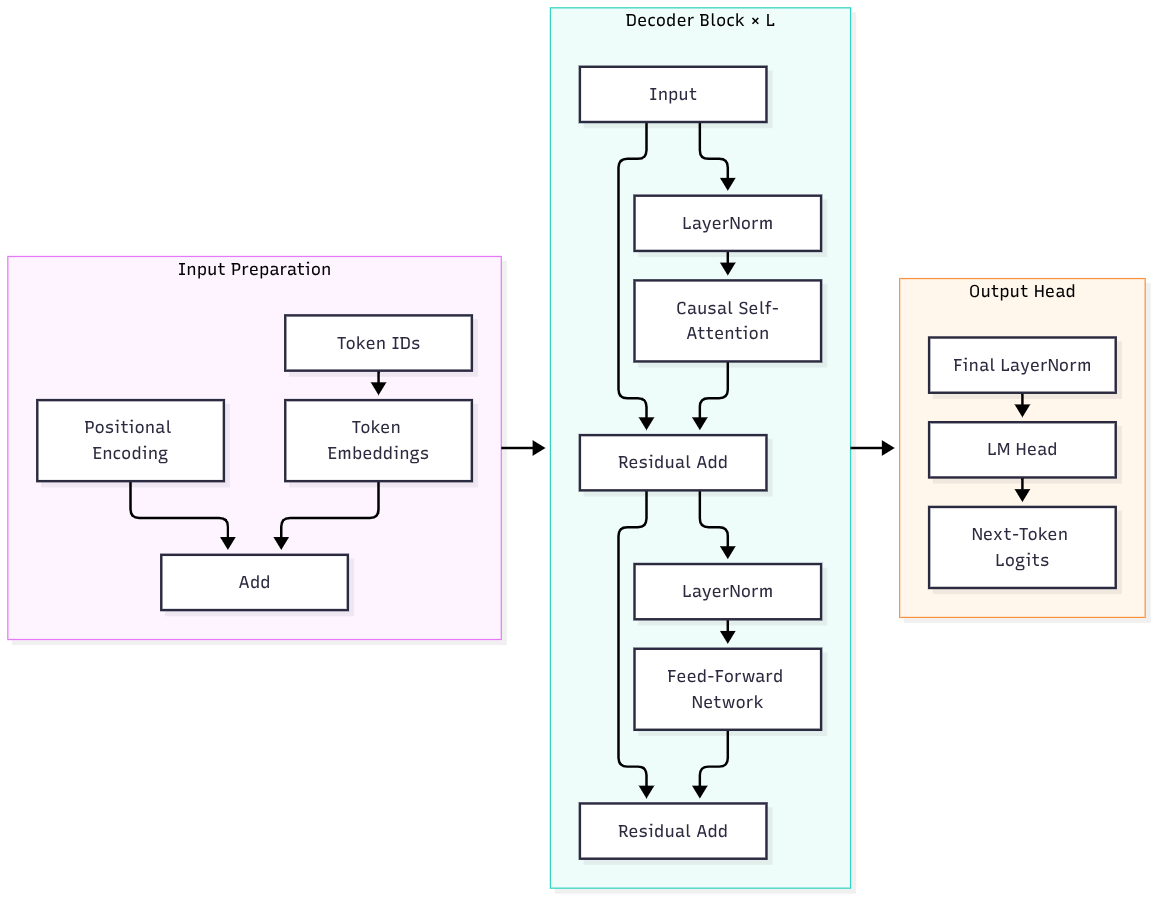


Students must implement the positional encoding, layer normalized residual
blocks, decoder stack, and language-model head while preserving causal
attention and the specified parameter budget.

**Additional Experiment**: You are free to explore _PRE_ and _POST_ layer norm as architectural choices apart from the hyperparameters provided you are within the parameter budget.


In [44]:
%%writefile model_arch.py
"""Decoder-only Transformer LM, built from scratch (no built-in Transformer blocks)."""
import math
from dataclasses import dataclass
import torch
import torch.nn as nn
from attention import CausalSelfAttention


@dataclass
class LMConfig:
    vocab_size: int
    d_model: int = 512
    n_layers: int = 4
    n_heads: int = 4
    n_kv_heads: int = 4
    d_ff: int = 1024
    max_seq_len: int = 256
    dropout: float = 0.1
    pos_emb_type: str = "sinusoidal"
    attention_scale: float = None
    norm_first: bool = False


def sinusoidal_positional_encoding(max_len: int, d_model: int) -> torch.Tensor:
    """Return classic Transformer sinusoidal positions with shape (max_len, d_model)."""
    if max_len <= 0 or d_model <= 0:
        raise ValueError("max_len and d_model must be positive")
    position = torch.arange(max_len, dtype=torch.float32).unsqueeze(1)
    even_indices = torch.arange(0, d_model, 2, dtype=torch.float32)
    frequencies = torch.exp(-math.log(10000.0) * even_indices / d_model)
    angles = position * frequencies.unsqueeze(0)
    encoding = torch.zeros(max_len, d_model, dtype=torch.float32)
    encoding[:, 0::2] = torch.sin(angles)
    if d_model > 1:
        encoding[:, 1::2] = torch.cos(angles[:, :encoding[:, 1::2].shape[1]])
    return encoding


class FeedForward(nn.Module):
    def __init__(self, d_model: int, d_ff: int, dropout: float):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(d_model, d_ff),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(d_ff, d_model),
            nn.Dropout(dropout),
        )

    def forward(self, x):
        return self.net(x)


class Block(nn.Module):
    """Configurable pre-norm or post-norm causal decoder block."""
    def __init__(self, cfg: LMConfig):
        super().__init__()
        self.norm_first = bool(cfg.norm_first)
        self.ln1 = nn.LayerNorm(cfg.d_model)
        self.attn = CausalSelfAttention(
            cfg.d_model, cfg.n_heads, cfg.max_seq_len, cfg.dropout,
            attention_scale=cfg.attention_scale,
        )
        self.ln2 = nn.LayerNorm(cfg.d_model)
        self.ffn = FeedForward(cfg.d_model, cfg.d_ff, cfg.dropout)

    def forward(self, x):
        if self.norm_first:
            x = x + self.attn(self.ln1(x))
            return x + self.ffn(self.ln2(x))
        x = self.ln1(x + self.attn(x))
        return self.ln2(x + self.ffn(x))


class DecoderLM(nn.Module):
    """The model class imported by the autograder."""
    def __init__(self, cfg: LMConfig):
        super().__init__()
        self.cfg = cfg
        self.tok_emb = nn.Embedding(cfg.vocab_size, cfg.d_model)
        if cfg.pos_emb_type == "sinusoidal":
            self.register_buffer(
                "pos_emb",
                sinusoidal_positional_encoding(cfg.max_seq_len, cfg.d_model),
                persistent=False,
            )
        elif cfg.pos_emb_type != "rope":
            raise ValueError("pos_emb_type must be 'sinusoidal' or 'rope'")
        self.blocks = nn.ModuleList([Block(cfg) for _ in range(cfg.n_layers)])
        self.ln_f = nn.LayerNorm(cfg.d_model)
        self.head = nn.Linear(cfg.d_model, cfg.vocab_size, bias=False)
        self.head.weight = self.tok_emb.weight

    def forward(self, idx: torch.Tensor) -> torch.Tensor:
        if idx.ndim != 2:
            raise ValueError("idx must have shape (batch, sequence)")
        _, length = idx.shape
        if length > self.cfg.max_seq_len:
            raise ValueError(
                f"Sequence length {length} exceeds max_seq_len={self.cfg.max_seq_len}"
            )
        x = self.tok_emb(idx)
        if self.cfg.pos_emb_type == "sinusoidal":
            x = x + self.pos_emb[:length].to(dtype=x.dtype).unsqueeze(0)
        for block in self.blocks:
            x = block(x)
        return self.head(self.ln_f(x))


Overwriting model_arch.py


In [45]:
# Import the files just written above. Keep this in a separate cell because everything
# after %%writefile in the previous cell is written to model_arch.py rather than run.
import importlib, sys
for _name in ("model_arch", "attention"):
    sys.modules.pop(_name, None)
attention = importlib.import_module("attention")
model_arch = importlib.import_module("model_arch")
LMConfig, DecoderLM = model_arch.LMConfig, model_arch.DecoderLM


### Question 1 execution, dual-GPU, and recovery helpers

The following student-added runtime keeps the two scaling experiments independent and
resumable. Full training remains an explicit action in Q1.3; importing these helpers does
not start a training run.


In [46]:
%%writefile q1_runtime.py
"""Restart-safe, deterministic two-GPU runtime for Assignment 3 Question 1."""
from __future__ import annotations

import copy
import hashlib
import json
import math
import os
import platform
import shutil
import subprocess
import sys
import threading
import time
import traceback
import uuid
import zipfile
from array import array
from concurrent.futures import ThreadPoolExecutor, as_completed
from dataclasses import asdict, dataclass
from datetime import datetime, timezone
from pathlib import Path

import torch
import torch.nn.functional as F
from torch.utils.data import DataLoader, Sampler
from tqdm.auto import tqdm

from common import TokenDataset, assert_within_budget, perplexity_of_texts
from model_arch import DecoderLM, LMConfig


SCHEMA_VERSION = 1
SAMPLER_SCHEME = "epoch_randperm_seed_plus_epoch_v1"
_ARCHIVE_LOCK = threading.Lock()
# All checkpoint/manifest writes and archive snapshots share this lock.
_ARTIFACT_LOCK = threading.RLock()
_PLOT_LOCK = threading.Lock()
_TQDM_LOCK = threading.RLock()
tqdm.set_lock(_TQDM_LOCK)


def _utc_now():
    return datetime.now(timezone.utc).isoformat()


def _canonical_json(value):
    return json.dumps(value, sort_keys=True, separators=(",", ":"), ensure_ascii=False)


def _json_hash(value):
    return hashlib.sha256(_canonical_json(value).encode("utf-8")).hexdigest()


def _sha256_file(path, chunk_size=1024 * 1024):
    digest = hashlib.sha256()
    with open(path, "rb") as handle:
        for chunk in iter(lambda: handle.read(chunk_size), b""):
            digest.update(chunk)
    return digest.hexdigest()


def _hash_int_sequence(values, chunk_items=100_000):
    digest = hashlib.sha256()
    for start in range(0, len(values), chunk_items):
        digest.update(array("q", (int(x) for x in values[start:start + chunk_items])).tobytes())
    return digest.hexdigest()


def _hash_texts(texts):
    digest = hashlib.sha256()
    for text in texts:
        payload = str(text).encode("utf-8")
        digest.update(len(payload).to_bytes(8, "little"))
        digest.update(payload)
    return digest.hexdigest()


def _state_dict_hash(state):
    digest = hashlib.sha256()
    for name in sorted(state):
        tensor = state[name].detach().cpu().contiguous()
        digest.update(name.encode("utf-8"))
        digest.update(str(tensor.dtype).encode("ascii"))
        digest.update(_canonical_json(list(tensor.shape)).encode("ascii"))
        digest.update(tensor.numpy().tobytes())
    return digest.hexdigest()


def _cpu_tree(value):
    if torch.is_tensor(value):
        return value.detach().cpu().clone()
    if isinstance(value, dict):
        return {key: _cpu_tree(item) for key, item in value.items()}
    if isinstance(value, list):
        return [_cpu_tree(item) for item in value]
    if isinstance(value, tuple):
        return tuple(_cpu_tree(item) for item in value)
    return copy.deepcopy(value)


def _atomic_json(path, value):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    temporary = path.with_name(path.name + f".{uuid.uuid4().hex}.tmp")
    temporary.write_text(json.dumps(value, indent=2, ensure_ascii=False), encoding="utf-8")
    json.loads(temporary.read_text(encoding="utf-8"))
    os.replace(temporary, path)


def _torch_load(path, map_location="cpu"):
    try:
        return torch.load(path, map_location=map_location, weights_only=False)
    except TypeError:
        return torch.load(path, map_location=map_location)


def _atomic_plain_torch(path, value):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    temporary = path.with_name(path.name + f".{uuid.uuid4().hex}.tmp")
    torch.save(value, temporary)
    _torch_load(temporary, "cpu")
    os.replace(temporary, path)


def _move_optimizer_state(optimizer, device):
    for state in optimizer.state.values():
        for key, value in state.items():
            if torch.is_tensor(value):
                state[key] = value.to(device)


class DeterministicStepBatchSampler(Sampler):
    """Map every global optimization step to a deterministic shuffled batch."""

    def __init__(self, dataset_size, batch_size, seed, start_step, total_steps):
        self.dataset_size = int(dataset_size)
        self.batch_size = int(batch_size)
        self.seed = int(seed)
        self.start_step = int(start_step)
        self.total_steps = int(total_steps)
        self.batches_per_epoch = self.dataset_size // self.batch_size
        if self.batches_per_epoch < 1:
            raise ValueError(
                f"Dataset has {self.dataset_size} chunks, fewer than batch_size={self.batch_size}."
            )

    def __len__(self):
        return max(0, self.total_steps - self.start_step)

    def __iter__(self):
        cached_epoch, order = None, None
        for step in range(self.start_step, self.total_steps):
            epoch = step // self.batches_per_epoch
            batch_in_epoch = step % self.batches_per_epoch
            if epoch != cached_epoch:
                generator = torch.Generator(device="cpu")
                generator.manual_seed(self.seed + epoch)
                order = torch.randperm(self.dataset_size, generator=generator)
                cached_epoch = epoch
            start = batch_in_epoch * self.batch_size
            yield order[start:start + self.batch_size].tolist()

    def position_after(self, completed_steps):
        return {
            "scheme": SAMPLER_SCHEME,
            "seed": self.seed,
            "epoch": int(completed_steps) // self.batches_per_epoch,
            "batch_in_epoch": int(completed_steps) % self.batches_per_epoch,
            "batches_per_epoch": self.batches_per_epoch,
        }


@dataclass(frozen=True)
class ExperimentPaths:
    root: Path

    @property
    def config(self): return self.root / "config.json"
    @property
    def latest(self): return self.root / "checkpoint.latest.pt"
    @property
    def previous(self): return self.root / "checkpoint.previous.pt"
    @property
    def latest_checksum(self): return self.root / "checkpoint.latest.sha256"
    @property
    def previous_checksum(self): return self.root / "checkpoint.previous.sha256"
    @property
    def best(self): return self.root / "best.pt"
    @property
    def final(self): return self.root / "final.pt"
    @property
    def history(self): return self.root / "history.json"
    @property
    def metrics(self): return self.root / "metrics.json"
    @property
    def status(self): return self.root / "status.json"


class Q1Runtime:
    def __init__(self, *, tokenizer, train_ids, held_out, base_config, train_steps,
                 batch_size, seed, tokenizer_fingerprint, smoke_test,
                 project_root=".", checkpoint_steps=50, checkpoint_seconds=300,
                 archive_seconds=600, learning_rate=3e-4, use_amp=True):
        self.tokenizer = tokenizer
        self.train_ids = [int(value) for value in train_ids]
        self.held_out = list(held_out)
        self.base_config = dict(base_config)
        self.train_steps = int(train_steps)
        self.batch_size = int(batch_size)
        self.seed = int(seed)
        self.tokenizer_fingerprint = str(tokenizer_fingerprint)
        self.smoke_test = bool(smoke_test)
        self.checkpoint_steps = int(checkpoint_steps)
        self.checkpoint_seconds = float(checkpoint_seconds)
        self.archive_seconds = float(archive_seconds)
        self.learning_rate = float(learning_rate)
        self.use_amp = bool(use_amp)
        self.project_root = Path(project_root).resolve()
        self.mode = "smoke" if self.smoke_test else "full"
        self.root = self.project_root / "artifacts" / self.mode / "q1"
        self.analysis_dir = self.root / "analysis"
        self.plot_dir = self.root / "plots"
        self.source_dir = self.root / "source_snapshots"
        self.manifest_dir = self.root / "manifests"
        for directory in (self.root, self.analysis_dir, self.plot_dir,
                          self.source_dir, self.manifest_dir):
            directory.mkdir(parents=True, exist_ok=True)
        self.train_ids_hash = _hash_int_sequence(self.train_ids)
        self.held_out_hash = _hash_texts(self.held_out)
        self.dataset = TokenDataset(self.train_ids, int(self.base_config["max_seq_len"]))
        if len(self.dataset) < self.batch_size:
            raise ValueError("TokenDataset is too small for the configured training batch size.")
        self.eval_steps = sorted({
            max(1, int(round(self.train_steps * fraction)))
            for fraction in (0.2, 0.4, 0.6, 0.8, 1.0)
        })
        self._last_archive_time = 0.0
        self._stop_event = threading.Event()
        self.snapshot_sources()

    def paths(self, label):
        return ExperimentPaths(self.root / label)

    def _cfg(self, scale):
        values = dict(self.base_config)
        values["attention_scale"] = scale
        return LMConfig(**values)

    def _source_hashes(self):
        hashes = {}
        for name in ("a1_tokenizer.py", "attention.py", "model_arch.py", "q1_runtime.py"):
            path = self.project_root / name
            if path.is_file():
                hashes[name] = _sha256_file(path)
        return hashes

    def snapshot_sources(self):
        for name in ("a1_tokenizer.py", "attention.py", "model_arch.py", "q1_runtime.py"):
            source = self.project_root / name
            destination = self.source_dir / name
            if source.is_file():
                if destination.is_file() and _sha256_file(destination) != _sha256_file(source):
                    versioned = self.source_dir / f"{source.stem}.{_sha256_file(source)[:12]}{source.suffix}"
                    shutil.copy2(source, versioned)
                else:
                    shutil.copy2(source, destination)

    def _canonical_initial_state(self):
        path = self.manifest_dir / "canonical_initial_state.pt"
        signature = {
            "base_config_without_scale": {
                key: value for key, value in self.base_config.items() if key != "attention_scale"
            },
            "seed": self.seed,
            "source_hashes": self._source_hashes(),
        }
        signature_hash = _json_hash(signature)
        if path.is_file():
            payload = _torch_load(path, "cpu")
            if payload.get("signature_hash") != signature_hash:
                raise RuntimeError(
                    "Existing canonical initialization is incompatible with current code/config. "
                    f"Move aside {path}; it was not overwritten."
                )
            return payload["state_dict"], payload["state_dict_hash"]
        cpu_rng_before = torch.get_rng_state()
        try:
            torch.manual_seed(self.seed)
            model = DecoderLM(self._cfg(None)).cpu()
            state = _cpu_tree(model.state_dict())
        finally:
            torch.set_rng_state(cpu_rng_before)
        state_hash = _state_dict_hash(state)
        _atomic_plain_torch(path, {
            "schema_version": SCHEMA_VERSION,
            "signature": signature,
            "signature_hash": signature_hash,
            "state_dict": state,
            "state_dict_hash": state_hash,
            "created_utc": _utc_now(),
        })
        return state, state_hash

    def _spec(self, label, scale, init_hash):
        cfg = asdict(self._cfg(scale))
        strict = {
            "schema_version": SCHEMA_VERSION,
            "experiment_id": f"q1-{self.mode}-{label}",
            "label": label,
            "architecture": cfg,
            "optimizer": {"name": "Adam", "lr": self.learning_rate},
            "target_steps": self.train_steps,
            "batch_size": self.batch_size,
            "seed": self.seed,
            "sampler_scheme": SAMPLER_SCHEME,
            "tokenizer_fingerprint": self.tokenizer_fingerprint,
            "train_ids_hash": self.train_ids_hash,
            "held_out_hash": self.held_out_hash,
            "initial_state_hash": init_hash,
            "smoke_test": self.smoke_test,
            "source_hashes": self._source_hashes(),
        }
        strict["trajectory_hash"] = _json_hash(strict)
        return strict

    def _write_config(self, spec):
        path = self.paths(spec["label"]).config
        if path.is_file():
            existing = json.loads(path.read_text(encoding="utf-8"))
            if existing.get("trajectory_hash") != spec["trajectory_hash"]:
                raise RuntimeError(f"Incompatible experiment config already exists: {path}")
        else:
            _atomic_json(path, spec)

    @staticmethod
    def _validate_checkpoint(payload, expected_hash):
        required = {
            "schema_version", "trajectory_hash", "model_state", "optimizer_state",
            "completed_step", "tokens_processed", "history", "eval_history",
            "cumulative_active_seconds", "sampler_state",
        }
        missing = required - set(payload) if isinstance(payload, dict) else required
        if missing:
            raise ValueError(f"Checkpoint missing fields: {sorted(missing)}")
        if payload["schema_version"] != SCHEMA_VERSION:
            raise ValueError("Unsupported checkpoint schema version")
        if payload["trajectory_hash"] != expected_hash:
            raise ValueError("Checkpoint trajectory/configuration mismatch")
        if int(payload["completed_step"]) < 0:
            raise ValueError("Invalid completed step")
        return payload

    def _validated_checkpoint_file(self, path, checksum_path, expected_hash):
        path, checksum_path = Path(path), Path(checksum_path)
        if not path.is_file():
            return None
        # A checkpoint is committed only if its matching checksum exists.  This
        # deliberately rejects a new file left between two atomic promotions.
        if not checksum_path.is_file():
            return None
        expected = checksum_path.read_text(encoding="ascii").strip()
        if _sha256_file(path) != expected:
            return None
        try:
            return self._validate_checkpoint(_torch_load(path, "cpu"), expected_hash)
        except Exception:
            return None

    def _load_checkpoint(self, spec):
        paths = self.paths(spec["label"])
        latest = self._validated_checkpoint_file(
            paths.latest, paths.latest_checksum, spec["trajectory_hash"]
        )
        if latest is not None:
            return latest, "latest"
        previous = self._validated_checkpoint_file(
            paths.previous, paths.previous_checksum, spec["trajectory_hash"]
        )
        return (previous, "previous") if previous is not None else (None, None)

    def _save_checkpoint(self, spec, payload):
        """Keep the last committed checkpoint available throughout promotion.

        A latest checkpoint is committed only when its separate SHA256 matches;
        previous is copied from a verified latest, never moved away.  A crash
        between candidate and checksum promotion leaves previous recoverable.
        """
        paths = self.paths(spec["label"])
        paths.root.mkdir(parents=True, exist_ok=True)
        with _ARTIFACT_LOCK:
            candidate = paths.root / (
                f"checkpoint.step_{payload['completed_step']:06d}.{uuid.uuid4().hex}.candidate"
            )
            candidate_checksum = paths.root / (candidate.name + ".sha256.tmp")
            previous_tmp = paths.root / ("checkpoint.previous." + uuid.uuid4().hex + ".tmp")
            previous_checksum_tmp = paths.root / ("checkpoint.previous." + uuid.uuid4().hex + ".sha256.tmp")
            try:
                torch.save(_cpu_tree(payload), candidate)
                loaded = self._validate_checkpoint(
                    _torch_load(candidate, "cpu"), spec["trajectory_hash"]
                )
                if int(loaded["completed_step"]) != int(payload["completed_step"]):
                    raise ValueError("Checkpoint step changed during serialization")
                candidate_hash = _sha256_file(candidate)
                candidate_checksum.write_text(candidate_hash, encoding="ascii")

                # Promote the previous known-good pair while the current latest
                # stays in place.  Do not propagate an invalid latest checkpoint.
                old_latest = self._validated_checkpoint_file(
                    paths.latest, paths.latest_checksum, spec["trajectory_hash"]
                )
                if old_latest is not None:
                    shutil.copy2(paths.latest, previous_tmp)
                    previous_hash = _sha256_file(previous_tmp)
                    previous_checksum_tmp.write_text(previous_hash, encoding="ascii")
                    os.replace(previous_tmp, paths.previous)
                    os.replace(previous_checksum_tmp, paths.previous_checksum)

                # Both replacements are atomic individually.  The old previous
                # survives an interruption between these two operations.
                os.replace(candidate, paths.latest)
                os.replace(candidate_checksum, paths.latest_checksum)
            finally:
                for temporary in (candidate, candidate_checksum, previous_tmp, previous_checksum_tmp):
                    temporary.unlink(missing_ok=True)

    def _status(self, spec, status, **extra):
        _atomic_json(self.paths(spec["label"]).status, {
            "experiment_id": spec["experiment_id"],
            "trajectory_hash": spec["trajectory_hash"],
            "status": status,
            "updated_utc": _utc_now(),
            **extra,
        })

    def _is_complete(self, spec):
        paths = self.paths(spec["label"])
        if not (paths.status.is_file() and paths.metrics.is_file() and paths.final.is_file()):
            return False
        status = json.loads(paths.status.read_text(encoding="utf-8"))
        metrics = json.loads(paths.metrics.read_text(encoding="utf-8"))
        return (
            status.get("status") == "complete"
            and status.get("trajectory_hash") == spec["trajectory_hash"]
            and int(metrics.get("completed_steps", -1)) == self.train_steps
            and math.isfinite(float(metrics.get("held_out_ppl", float("inf"))))
            and len(metrics.get("train_loss_curve", [])) > 0
        )

    def _reset_if_requested(self, label, force):
        paths = self.paths(label)
        if not force or not paths.root.exists():
            return
        backup = paths.root.with_name(paths.root.name + ".reset_" + datetime.now().strftime("%Y%m%d_%H%M%S"))
        shutil.move(paths.root, backup)
        print(f"Explicit reset preserved previous {label} artifacts at {backup}")

    def _checkpoint_payload(self, *, spec, model, optimizer, scaler, step, tokens,
                            history, eval_history, cumulative_seconds, sampler,
                            device, best):
        cuda_rng = None
        if device.type == "cuda":
            cuda_rng = torch.cuda.get_rng_state(device=device).cpu()
        sampler_state = sampler.position_after(step)
        return {
            "schema_version": SCHEMA_VERSION,
            "experiment_id": spec["experiment_id"],
            "trajectory_hash": spec["trajectory_hash"],
            "config": spec,
            "model_state": _cpu_tree(model.state_dict()),
            "optimizer_state": _cpu_tree(optimizer.state_dict()),
            "scheduler_state": None,
            "scaler_state": _cpu_tree(scaler.state_dict()) if scaler is not None else None,
            "completed_step": int(step),
            "epoch": sampler_state["epoch"],
            "batch_in_epoch": sampler_state["batch_in_epoch"],
            "tokens_processed": int(tokens),
            "history": list(history),
            "eval_history": list(eval_history),
            "best": dict(best),
            "cumulative_active_seconds": float(cumulative_seconds),
            "sampler_state": sampler_state,
            "assigned_device": str(device),
            "cuda_rng_state_for_assigned_device": cuda_rng,
            "created_utc": _utc_now(),
            "environment": {
                "python": sys.version,
                "torch": torch.__version__,
                "platform": platform.platform(),
                "cuda": torch.version.cuda,
            },
        }

    def _run_worker(self, spec, prepared_model, device_name, position, initial_rng_state):
        label, paths = spec["label"], self.paths(spec["label"])
        device = torch.device(device_name)
        self._write_config(spec)
        if self._is_complete(spec):
            print(f"{label}: compatible completed run found; training skipped.")
            return {"label": label, "status": "complete", "skipped": True}
        checkpoint, checkpoint_source = self._load_checkpoint(spec)
        model = prepared_model.to(device)
        assert_within_budget(model)
        optimizer = torch.optim.Adam(model.parameters(), lr=self.learning_rate)
        amp_enabled = self.use_amp and device.type == "cuda"
        try:
            scaler = torch.amp.GradScaler("cuda", enabled=amp_enabled)
        except (AttributeError, TypeError):
            scaler = torch.cuda.amp.GradScaler(enabled=amp_enabled)

        step, tokens, history, eval_history, cumulative_before = 0, 0, [], [], 0.0
        best = {"held_out_ppl": float("inf"), "step": None}
        run_kind = "new"
        if checkpoint is not None:
            model.load_state_dict(checkpoint["model_state"])
            optimizer.load_state_dict(checkpoint["optimizer_state"])
            _move_optimizer_state(optimizer, device)
            if checkpoint.get("scaler_state"):
                scaler.load_state_dict(checkpoint["scaler_state"])
            step = int(checkpoint["completed_step"])
            tokens = int(checkpoint["tokens_processed"])
            history = [row for row in checkpoint["history"] if int(row["step"]) <= step]
            eval_history = [row for row in checkpoint["eval_history"] if int(row["step"]) <= step]
            cumulative_before = float(checkpoint["cumulative_active_seconds"])
            best = dict(checkpoint.get("best", best))
            if device.type == "cuda" and checkpoint.get("cuda_rng_state_for_assigned_device") is not None:
                torch.cuda.set_rng_state(checkpoint["cuda_rng_state_for_assigned_device"], device=device)
            run_kind = f"resumed-{checkpoint_source}"
        elif device.type == "cuda":
            torch.cuda.set_rng_state(initial_rng_state, device=device)
        else:
            torch.set_rng_state(initial_rng_state)

        sampler = DeterministicStepBatchSampler(
            len(self.dataset), self.batch_size, self.seed, step, self.train_steps
        )
        loader = DataLoader(
            self.dataset, batch_sampler=sampler, num_workers=0,
            pin_memory=(device.type == "cuda"),
        )
        self._status(spec, "in_progress", completed_step=step, assigned_device=str(device), run_kind=run_kind)
        session_started = time.perf_counter()
        last_checkpoint_time = session_started
        last_checkpoint_step = step
        completed_normally = False

        try:
            progress = tqdm(
                total=self.train_steps, initial=step, position=position, leave=True,
                desc=f"{label} [{device}] {run_kind}", dynamic_ncols=True,
            )
            model.train()
            for x, y in loader:
                if self._stop_event.is_set():
                    break
                x = x.to(device, non_blocking=True)
                y = y.to(device, non_blocking=True)
                optimizer.zero_grad(set_to_none=True)
                with torch.autocast(
                    device_type=device.type,
                    dtype=torch.float16 if device.type == "cuda" else torch.float32,
                    enabled=amp_enabled,
                ):
                    logits = model(x)
                    loss = F.cross_entropy(logits.reshape(-1, logits.size(-1)), y.reshape(-1))
                if not torch.isfinite(loss):
                    raise FloatingPointError(f"Non-finite training loss at step {step + 1}")
                scaler.scale(loss).backward()
                scaler.step(optimizer)
                scaler.update()
                step += 1
                tokens += int(x.numel())
                session_elapsed = time.perf_counter() - session_started
                cumulative = cumulative_before + session_elapsed
                history.append({
                    "step": step,
                    "epoch": sampler.position_after(step)["epoch"],
                    "loss": float(loss.detach()),
                    "learning_rate": float(optimizer.param_groups[0]["lr"]),
                    "tokens_processed": tokens,
                    "elapsed_seconds": cumulative,
                })
                evaluation_happened = False
                if step in self.eval_steps:
                    model.eval()
                    ppl = float(perplexity_of_texts(
                        model, self.tokenizer, self.held_out, device=device,
                        max_len=int(spec["architecture"]["max_seq_len"]),
                    ))
                    model.train()
                    eval_history.append({
                        "step": step,
                        "tokens_processed": tokens,
                        "held_out_ppl": ppl,
                        "elapsed_seconds": cumulative,
                    })
                    evaluation_happened = True
                    if math.isfinite(ppl) and ppl < float(best.get("held_out_ppl", float("inf"))):
                        best = {"held_out_ppl": ppl, "step": step}
                        _atomic_plain_torch(paths.best, _cpu_tree(model.state_dict()))
                now = time.perf_counter()
                checkpoint_due = (
                    step == self.train_steps
                    or evaluation_happened
                    or step - last_checkpoint_step >= self.checkpoint_steps
                    or now - last_checkpoint_time >= self.checkpoint_seconds
                )
                if checkpoint_due:
                    payload = self._checkpoint_payload(
                        spec=spec, model=model, optimizer=optimizer, scaler=scaler,
                        step=step, tokens=tokens, history=history, eval_history=eval_history,
                        cumulative_seconds=cumulative, sampler=sampler, device=device, best=best,
                    )
                    with _ARTIFACT_LOCK:
                        self._save_checkpoint(spec, payload)
                        _atomic_json(paths.history, {
                            "trajectory_hash": spec["trajectory_hash"],
                            "history": history,
                            "eval_history": eval_history,
                        })
                        self._status(spec, "in_progress", completed_step=step,
                                     assigned_device=str(device), last_checkpoint_step=step)
                    last_checkpoint_time, last_checkpoint_step = now, step
                    self.export_recovery_archive(force=False, reason=f"checkpoint-{label}-{step}")
                elapsed = max(1e-9, session_elapsed)
                progress.update(1)
                progress.set_postfix({
                    "loss": f"{float(loss.detach()):.4f}",
                    "lr": f"{optimizer.param_groups[0]['lr']:.2e}",
                    "tok": tokens,
                    "tok/s": f"{(tokens - (checkpoint['tokens_processed'] if checkpoint else 0))/elapsed:.0f}",
                    "total_s": f"{cumulative:.0f}",
                    "ckpt": last_checkpoint_step,
                }, refresh=(step % 5 == 0 or step == self.train_steps))
                if step >= self.train_steps:
                    completed_normally = True
                    break
            progress.close()
            cumulative = cumulative_before + (time.perf_counter() - session_started)
            if not completed_normally:
                payload = self._checkpoint_payload(
                    spec=spec, model=model, optimizer=optimizer, scaler=scaler,
                    step=step, tokens=tokens, history=history, eval_history=eval_history,
                    cumulative_seconds=cumulative, sampler=sampler, device=device, best=best,
                )
                with _ARTIFACT_LOCK:
                    self._save_checkpoint(spec, payload)
                    _atomic_json(paths.history, {
                        "trajectory_hash": spec["trajectory_hash"],
                        "history": history, "eval_history": eval_history,
                    })
                    self._status(spec, "interrupted", completed_step=step, assigned_device=str(device))
                return {"label": label, "status": "interrupted", "completed_step": step}

            if not eval_history or int(eval_history[-1]["step"]) != self.train_steps:
                model.eval()
                final_ppl = float(perplexity_of_texts(
                    model, self.tokenizer, self.held_out, device=device,
                    max_len=int(spec["architecture"]["max_seq_len"]),
                ))
                eval_history.append({
                    "step": step, "tokens_processed": tokens,
                    "held_out_ppl": final_ppl, "elapsed_seconds": cumulative,
                })
            final_ppl = float(eval_history[-1]["held_out_ppl"])
            if not math.isfinite(final_ppl):
                raise FloatingPointError("Final held-out perplexity is not finite")
            metrics = {
                "label": label,
                "attention_scale": spec["architecture"]["attention_scale"],
                "held_out_ppl": final_ppl,
                "train_loss_curve": [float(row["loss"]) for row in history],
                "history": history,
                "eval_history": eval_history,
                "completed_steps": step,
                "tokens_processed": tokens,
                "parameter_count": sum(parameter.numel() for parameter in model.parameters()),
                "cumulative_active_seconds": cumulative,
                "initial_state_hash": spec["initial_state_hash"],
                "trajectory_hash": spec["trajectory_hash"],
            }
            with _ARTIFACT_LOCK:
                _atomic_plain_torch(paths.final, _cpu_tree(model.state_dict()))
                _atomic_json(paths.metrics, metrics)
                _atomic_json(paths.history, {
                    "trajectory_hash": spec["trajectory_hash"],
                    "history": history,
                    "eval_history": eval_history,
                })
                self._status(spec, "complete", completed_step=step, assigned_device=str(device),
                             final_held_out_ppl=final_ppl)
            print(
                f"{label} completed on {device}: session={time.perf_counter()-session_started:.1f}s, "
                f"cumulative={cumulative:.1f}s, ppl={final_ppl:.3f}"
            )
            return {"label": label, "status": "complete", "metrics": metrics}
        except KeyboardInterrupt:
            self._stop_event.set()
            raise
        except Exception as error:
            # A failed worker never removes its last validated checkpoint or its partner's files.
            self._status(spec, "failed", completed_step=step, assigned_device=str(device),
                         error=repr(error), traceback=traceback.format_exc())
            return {"label": label, "status": "failed", "error": repr(error)}
        finally:
            model.to("cpu")
            if device.type == "cuda":
                with torch.cuda.device(device):
                    torch.cuda.empty_cache()

    def run_scaling_pair(self, *, force_retrain=False, require_two_gpus=True,
                         allow_sequential_fallback=False):
        self._stop_event.clear()
        self._reset_if_requested("standard", force_retrain)
        self._reset_if_requested("unscaled", force_retrain)
        initial_state, init_hash = self._canonical_initial_state()
        specs = {
            "standard": self._spec("standard", None, init_hash),
            "unscaled": self._spec("unscaled", 1.0, init_hash),
        }
        for spec in specs.values():
            self._write_config(spec)
        self.snapshot_sources()
        self.export_recovery_archive(force=True, reason="pre-training")
        completed = {label: self._is_complete(spec) for label, spec in specs.items()}
        pending = [label for label in ("standard", "unscaled") if not completed[label]]
        if not pending:
            print("Both Q1 scaling experiments are already complete; no retraining occurred.")
            return self.collect_results()

        gpu_count = torch.cuda.device_count() if torch.cuda.is_available() else 0
        if require_two_gpus and gpu_count < 2 and not allow_sequential_fallback:
            raise RuntimeError(
                f"Q1 full paired training requires two visible CUDA GPUs; found {gpu_count}. "
                "Use a Kaggle dual-GPU runtime. Sequential fallback is intentionally disabled."
            )
        assignments = {"standard": "cuda:0", "unscaled": "cuda:1"}
        if gpu_count < 2:
            fallback = "cuda:0" if gpu_count == 1 else "cpu"
            print(f"CLEAR FALLBACK NOTICE: running pending Q1 jobs sequentially on {fallback}; "
                  "this is not dual-GPU training.")
            assignments = {label: fallback for label in pending}
        models, rng_states = {}, {}
        for label in pending:
            model = DecoderLM(LMConfig(**specs[label]["architecture"]))
            model.load_state_dict(initial_state)
            models[label] = model
            target_device = assignments[label]
            if target_device.startswith("cuda"):
                generator = torch.Generator(device=target_device)
                generator.manual_seed(self.seed)
                rng_states[label] = generator.get_state().cpu()
            else:
                generator = torch.Generator(device="cpu")
                generator.manual_seed(self.seed)
                rng_states[label] = generator.get_state()

        outcomes = {}
        if gpu_count >= 2 and len(pending) > 1:
            print("DUAL-GPU Q1: standard -> cuda:0; unscaled -> cuda:1")
            with ThreadPoolExecutor(max_workers=2, thread_name_prefix="a3-q1-gpu") as pool:
                futures = {
                    pool.submit(
                        self._run_worker, specs[label], models[label], assignments[label],
                        0 if label == "standard" else 1, rng_states[label]
                    ): label for label in pending
                }
                try:
                    for future in as_completed(futures):
                        label = futures[future]
                        try:
                            outcomes[label] = future.result()
                        except BaseException as error:
                            outcomes[label] = {"label": label, "status": "failed", "error": repr(error)}
                except KeyboardInterrupt:
                    self._stop_event.set()
                    for future in futures:
                        try:
                            future.result()
                        except BaseException:
                            pass
                    raise
        else:
            for label in pending:
                outcomes[label] = self._run_worker(
                    specs[label], models[label], assignments[label],
                    0 if label == "standard" else 1, rng_states[label]
                )
        self.export_recovery_archive(force=True, reason="post-pair")
        failures = {label: result for label, result in outcomes.items()
                    if result.get("status") != "complete"}
        if failures:
            raise RuntimeError(
                "One or more Q1 jobs did not complete; successful partner artifacts were preserved: "
                + _canonical_json(failures)
            )
        return self.collect_results()

    def collect_results(self):
        results = {}
        for label in ("standard", "unscaled"):
            path = self.paths(label).metrics
            if not path.is_file():
                raise FileNotFoundError(f"Q1 experiment is not complete: {label} ({path})")
            results[label] = json.loads(path.read_text(encoding="utf-8"))
        return results

    def load_model(self, label="standard", device="cpu"):
        paths = self.paths(label)
        if not paths.config.is_file() or not paths.final.is_file():
            raise FileNotFoundError(f"Completed {label} model artifacts are unavailable.")
        spec = json.loads(paths.config.read_text(encoding="utf-8"))
        model = DecoderLM(LMConfig(**spec["architecture"]))
        model.load_state_dict(_torch_load(paths.final, "cpu"))
        return model.to(device).eval(), LMConfig(**spec["architecture"])

    def export_recovery_archive(self, *, force=False, reason="manual"):
        now = time.monotonic()
        archive_name = "q1_smoke_all_artifacts.zip" if self.smoke_test else "q1_all_artifacts.zip"
        runtime_root = Path("/kaggle/working") if Path("/kaggle/working").is_dir() else self.project_root
        destination = runtime_root / archive_name
        with _ARCHIVE_LOCK, _ARTIFACT_LOCK:
            if not force and destination.is_file() and now - self._last_archive_time < self.archive_seconds:
                return destination
            self.snapshot_sources()
            roots = [self.root, self.project_root / "artifacts" / "shared" / "tokenizer"]
            submission = self.project_root / "submissions" / "q1"
            if submission.is_dir():
                roots.append(submission)
            files = []
            for root in roots:
                if not root.is_dir():
                    continue
                for path in root.rglob("*"):
                    if path.is_file() and not any(part.endswith((".tmp", ".candidate")) for part in path.parts):
                        files.append(path.resolve())
            analysis_log = self.project_root / "analysis_log.json"
            if analysis_log.is_file():
                files.append(analysis_log.resolve())
            files = sorted(set(files), key=lambda p: str(p))
            manifest = {"schema_version": 1, "created_utc": _utc_now(), "reason": reason,
                        "mode": self.mode, "files": {}}
            temporary = destination.with_name(destination.name + f".{uuid.uuid4().hex}.tmp")
            with zipfile.ZipFile(temporary, "w") as archive:
                for path in files:
                    rel = path.relative_to(self.project_root).as_posix()
                    info = {"sha256": _sha256_file(path), "size": path.stat().st_size}
                    manifest["files"][rel] = info
                    compression = zipfile.ZIP_STORED if path.suffix == ".pt" else zipfile.ZIP_DEFLATED
                    archive.write(path, arcname=rel, compress_type=compression)
                # Notebook outputs may lag the live Kaggle editor; snapshot only
                # when an actual readable file is available.  Always also save a
                # Kaggle notebook version externally after training.
                notebook_candidates = (
                    self.project_root / "copy_assignment3.ipynb",
                    Path("/kaggle/working/copy_assignment3.ipynb"),
                )
                for notebook_path in notebook_candidates:
                    if notebook_path.is_file():
                        try:
                            notebook_payload = notebook_path.read_bytes()
                            parsed = json.loads(notebook_payload)
                            if parsed.get("nbformat") != 4 or not isinstance(parsed.get("cells"), list):
                                raise ValueError("Not an nbformat-4 notebook")
                            archive.writestr("recovery/notebook_snapshot.ipynb", notebook_payload,
                                             compress_type=zipfile.ZIP_DEFLATED)
                            manifest["notebook_snapshot_sha256"] = hashlib.sha256(notebook_payload).hexdigest()
                            break
                        except (OSError, ValueError, json.JSONDecodeError):
                            continue
                archive.writestr(
                    "recovery/integrity_manifest.json",
                    json.dumps(manifest, indent=2),
                    compress_type=zipfile.ZIP_DEFLATED,
                )
                archive.writestr(
                    "recovery/recovery_metadata.json",
                    json.dumps({
                        "notebook": "copy_assignment3.ipynb",
                        "reason": reason,
                        "created_utc": _utc_now(),
                        "instructions": "Attach this ZIP plus the Assignment-3 student package, then run setup top-to-bottom.",
                    }, indent=2),
                    compress_type=zipfile.ZIP_DEFLATED,
                )
            with zipfile.ZipFile(temporary) as archive:
                if archive.testzip() is not None:
                    raise ValueError("New recovery archive failed CRC validation")
                saved_manifest = json.loads(archive.read("recovery/integrity_manifest.json"))
                if "notebook_snapshot_sha256" in saved_manifest:
                    snapshot = archive.read("recovery/notebook_snapshot.ipynb")
                    if hashlib.sha256(snapshot).hexdigest() != saved_manifest["notebook_snapshot_sha256"]:
                        raise ValueError("Notebook snapshot integrity check failed")
                for rel, info in saved_manifest["files"].items():
                    payload = archive.read(rel)
                    if len(payload) != int(info["size"]):
                        raise ValueError(f"Recovery ZIP size validation failed for {rel}")
                    if hashlib.sha256(payload).hexdigest() != info["sha256"]:
                        raise ValueError(f"Recovery ZIP checksum validation failed for {rel}")
            previous = destination.with_name(destination.stem + ".previous.zip")
            if destination.is_file():
                previous_tmp = previous.with_name(previous.name + f".{uuid.uuid4().hex}.tmp")
                try:
                    shutil.copy2(destination, previous_tmp)
                    with zipfile.ZipFile(previous_tmp) as prior:
                        if prior.testzip() is not None:
                            raise ValueError("Existing archive failed CRC; refusing to promote it to previous")
                    os.replace(previous_tmp, previous)
                finally:
                    previous_tmp.unlink(missing_ok=True)
            os.replace(temporary, destination)
            self._last_archive_time = now
            print(f"Validated Q1 recovery archive ({reason}): {destination}")
            return destination

    def completion_report(self):
        report = {"mode": self.mode, "experiments": {}, "submission": {}, "sources": {}}
        for label in ("standard", "unscaled"):
            paths = self.paths(label)
            report["experiments"][label] = {
                "config": paths.config.is_file(), "latest": paths.latest.is_file(),
                "final": paths.final.is_file(), "metrics": paths.metrics.is_file(),
                "status": json.loads(paths.status.read_text()).get("status") if paths.status.is_file() else "missing",
            }
        sub = self.project_root / "submissions" / "q1"
        for name in ("model.pt", "config.json", "metrics.json", "attention.py", "model_arch.py"):
            report["submission"][name] = (sub / name).is_file()
        for name in ("a1_tokenizer.py", "attention.py", "model_arch.py", "q1_runtime.py"):
            report["sources"][name] = (self.source_dir / name).is_file()
        return report

    def run_smoke_tests(self):
        smoke_root = self.project_root / "artifacts" / "_smoke" / "q1_runtime"
        if smoke_root.exists():
            shutil.rmtree(smoke_root)
        smoke_root.mkdir(parents=True)
        checks = {}
        cfg_values = dict(self.base_config)
        cfg_values.update({"d_model": 32, "n_layers": 1, "n_heads": 4,
                           "n_kv_heads": 4, "d_ff": 64, "max_seq_len": 16,
                           "dropout": 0.0, "attention_scale": None})
        cfg = LMConfig(**cfg_values)
        model = DecoderLM(cfg)
        x = torch.randint(0, cfg.vocab_size, (2, 12))
        logits = model(x)
        checks["forward_shape"] = list(logits.shape) == [2, 12, cfg.vocab_size]
        x_changed = x.clone(); x_changed[:, 7:] = torch.randint(0, cfg.vocab_size, x_changed[:, 7:].shape)
        with torch.no_grad():
            a, b = model.eval()(x), model.eval()(x_changed)
        checks["causal_prefix"] = bool(torch.allclose(a[:, :7], b[:, :7], atol=1e-5, rtol=1e-5))
        model.train(); loss = F.cross_entropy(model(x).reshape(-1, cfg.vocab_size), x.reshape(-1))
        loss.backward()
        checks["finite_gradients"] = all(
            parameter.grad is None or bool(torch.isfinite(parameter.grad).all())
            for parameter in model.parameters()
        )
        checks["weight_tying"] = model.head.weight is model.tok_emb.weight
        checks["parameter_budget"] = sum(p.numel() for p in model.parameters()) <= 50_000_000
        sampler_a = list(DeterministicStepBatchSampler(100, 4, self.seed, 0, 8))
        sampler_b = list(DeterministicStepBatchSampler(100, 4, self.seed, 3, 8))
        checks["exact_sampler_resume"] = sampler_a[3:] == sampler_b
        optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
        checkpoint_path = smoke_root / "optimizer_roundtrip.pt"
        _atomic_plain_torch(checkpoint_path, {
            "model": _cpu_tree(model.state_dict()), "optimizer": _cpu_tree(optimizer.state_dict())
        })
        restored = _torch_load(checkpoint_path, "cpu")
        model_2 = DecoderLM(cfg); model_2.load_state_dict(restored["model"])
        optimizer_2 = torch.optim.Adam(model_2.parameters(), lr=1e-3)
        optimizer_2.load_state_dict(restored["optimizer"])
        checks["checkpoint_optimizer_roundtrip"] = _state_dict_hash(model.state_dict()) == _state_dict_hash(model_2.state_dict())
        failures = []
        with ThreadPoolExecutor(max_workers=2) as pool:
            good = pool.submit(lambda: "preserved")
            bad = pool.submit(lambda: (_ for _ in ()).throw(RuntimeError("injected")))
            checks["partner_success_survives"] = good.result() == "preserved"
            try: bad.result()
            except RuntimeError: failures.append("injected")
        checks["injected_failure_observed"] = failures == ["injected"]
        if torch.cuda.device_count() >= 2:
            def gpu_probe(device_name):
                local = DecoderLM(cfg).to(device_name).eval()
                value = local(torch.randint(0, cfg.vocab_size, (1, 8), device=device_name))
                return str(value.device)
            with ThreadPoolExecutor(max_workers=2) as pool:
                devices = {pool.submit(gpu_probe, "cuda:0"), pool.submit(gpu_probe, "cuda:1")}
                seen = {future.result() for future in devices}
            checks["dual_gpu_independence"] = seen == {"cuda:0", "cuda:1"}
        else:
            checks["dual_gpu_independence"] = None
        zip_path = smoke_root / "integrity.zip"
        payload_path = smoke_root / "payload.json"
        _atomic_json(payload_path, {"ok": True})
        with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as archive:
            archive.write(payload_path, arcname="payload.json")
        with zipfile.ZipFile(zip_path) as archive:
            checks["zip_crc"] = archive.testzip() is None
        report = {"created_utc": _utc_now(), "checks": checks,
                  "all_available_passed": all(value for value in checks.values() if value is not None)}
        _atomic_json(smoke_root / "smoke_report.json", report)
        print(json.dumps(report, indent=2))
        return report


Overwriting q1_runtime.py


In [47]:
# Configure the reusable Q1 runtime. This cell only prepares state; it does not train.
import importlib
sys.modules.pop("q1_runtime", None)
q1_runtime_module = importlib.import_module("q1_runtime")

q1_base_config = {
    "vocab_size": VOCAB_SIZE,
    "d_model": MODEL_DIM,
    "n_layers": MODEL_LAYERS,
    "n_heads": 4,
    "n_kv_heads": 4,
    "d_ff": MODEL_FF,
    "max_seq_len": MODEL_SEQ_LEN,
    "dropout": 0.1,
    "pos_emb_type": "sinusoidal",
    "attention_scale": None,
    "norm_first": False,
}
q1_runtime = q1_runtime_module.Q1Runtime(
    tokenizer=tokenizer,
    train_ids=train_ids,
    held_out=held_out,
    base_config=q1_base_config,
    train_steps=TRAIN_STEPS,
    batch_size=TRAIN_BATCH_SIZE,
    seed=SEED,
    tokenizer_fingerprint=TOKENIZER_FINGERPRINT,
    smoke_test=SMOKE_TEST,
    checkpoint_steps=50,
    checkpoint_seconds=5 * 60,
    archive_seconds=10 * 60,
    learning_rate=3e-4,
    use_amp=True,
)
print("Q1 artifact root:", q1_runtime.root)
print("Q1 evaluation steps:", q1_runtime.eval_steps)


Q1 artifact root: /kaggle/working/assignment_3/artifacts/full/q1
Q1 evaluation steps: [100, 200, 300, 400, 500]


In [ ]:
# Lightweight infrastructure tests are isolated from real experiment artifacts.
RUN_Q1_INFRA_SMOKE_TESTS = SMOKE_TEST  # set True manually in a full-mode validation session
if RUN_Q1_INFRA_SMOKE_TESTS:
    q1_smoke_report = q1_runtime.run_smoke_tests()
    if not q1_smoke_report["all_available_passed"]:
        raise AssertionError("One or more available Q1 smoke checks failed.")
else:
    print("Q1 infrastructure smoke tests skipped; set RUN_Q1_INFRA_SMOKE_TESTS=True to run them.")


## 1.3 Baseline training, parameter-budget check, and held-out perplexity [30 Marks]

Train the baseline model for next-token prediction using Adam and cross-entropy loss.
Construct the training batches from the tokenized corpus, log the training loss during
optimization, verify the total parameter count, and evaluate the final model on the
held-out set.

Use the provided `perplexity_of_texts(...)` helper for the reported held-out perplexity
so every submission follows the same course evaluation convention. Do not replace it
with a separately defined perplexity formula.

Use the same baseline configuration as the reference point for the later ablations.
`TRAIN_STEPS` is a convenience default, not a hard or exact training limit; report the
actual number of optimization steps used.


In [48]:
# Q1.3 + Q1.4 principal training action.
# Standard scaling is the Q1 baseline; it is trained once, concurrently with unscaled.
Q1_FORCE_RETRAIN = False       # explicit reset only; old work is preserved in a timestamped folder
Q1_ALLOW_SEQUENTIAL_FALLBACK = SMOKE_TEST

q1_pair_results = q1_runtime.run_scaling_pair(
    force_retrain=Q1_FORCE_RETRAIN,
    require_two_gpus=not SMOKE_TEST,
    allow_sequential_fallback=Q1_ALLOW_SEQUENTIAL_FALLBACK,
)

q1_analysis_device = torch.device(
    "cuda:0" if torch.cuda.is_available() else
    ("mps" if torch.backends.mps.is_available() else "cpu")
)
model, cfg = q1_runtime.load_model("standard", device=q1_analysis_device)
q1_standard_result = q1_pair_results["standard"]
n_params = assert_within_budget(model)
train_loss_curve = q1_standard_result["train_loss_curve"]
held_out_perplexity_q1 = float(q1_standard_result["held_out_ppl"])

print(f"Q1 baseline: {n_params:,} parameters")
print(f"Actual optimization steps: {q1_standard_result['completed_steps']}")
print(f"Held-out sentence-level perplexity: {held_out_perplexity_q1:.4f}")
print("Baseline is the standard-scaling member of the paired experiment; it was not retrained twice.")


Validated Q1 recovery archive (pre-training): /kaggle/working/q1_all_artifacts.zip
DUAL-GPU Q1: standard -> cuda:0; unscaled -> cuda:1


standard [cuda:0] new:   0%|          | 0/500 [00:00<?, ?it/s]

unscaled [cuda:1] new:   0%|          | 0/500 [00:00<?, ?it/s]

unscaled completed on cuda:1: session=37.2s, cumulative=37.1s, ppl=2702.129
standard completed on cuda:0: session=40.2s, cumulative=40.1s, ppl=2624.355
Validated Q1 recovery archive (post-pair): /kaggle/working/q1_all_artifacts.zip
Q1 baseline: 5,203,456 parameters
Actual optimization steps: 500
Held-out sentence-level perplexity: 2624.3546
Baseline is the standard-scaling member of the paired experiment; it was not retrained twice.


## 1.4 Attention-score scaling ablation [30 Marks]

Study the effect of the attention-score scaling factor while keeping the rest of the model and training setup fixed. Write the scores as

$$S = \alpha QK^\top$$

Run the standard setting $\alpha=1/\sqrt{d_k}$, an unscaled setting $\alpha=1$. Compare the resulting training behaviour and held-out perplexity using a comparable experimental budget.

The purpose of the $\frac{1}{\sqrt{d_k}}$ factor is to prevent the magnitude of dot products from growing with the head dimension and pushing the softmax into an excessively saturated regime. Use your experiment to examine what happens when this normalization is changed.


  standard | alpha=0.125000 | held-out ppl=2624.3546 | logged losses=500
  unscaled | alpha=1.000000 | held-out ppl=2702.1288 | logged losses=500


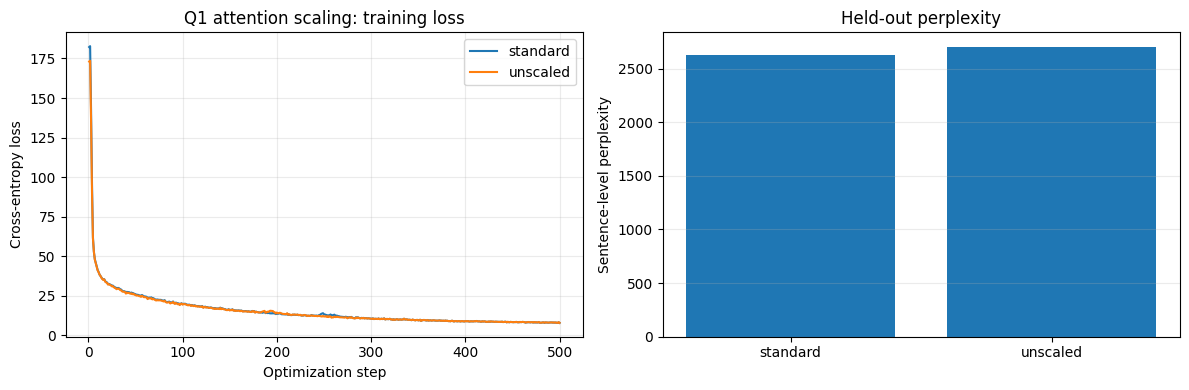

Measured conclusion: standard scaling produced the lower held-out perplexity in this controlled run (2624.3546).


In [49]:
# Read and compare the two persisted runs. This cell never launches training.
q1_pair_results = q1_runtime.collect_results()
attention_scaling_results = [
    {
        "label": label,
        "attention_scale": q1_pair_results[label]["attention_scale"],
        "held_out_ppl": float(q1_pair_results[label]["held_out_ppl"]),
        "train_loss_curve": [float(value) for value in q1_pair_results[label]["train_loss_curve"]],
    }
    for label in ("standard", "unscaled")
]

for row in attention_scaling_results:
    effective_scale = row["attention_scale"]
    if effective_scale is None:
        effective_scale = 1.0 / math.sqrt(cfg.d_model // cfg.n_heads)
    print(
        f"{row['label']:>10s} | alpha={effective_scale:.6f} | "
        f"held-out ppl={row['held_out_ppl']:.4f} | logged losses={len(row['train_loss_curve'])}"
    )

with q1_runtime_module._PLOT_LOCK:
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    for row in attention_scaling_results:
        axes[0].plot(range(1, len(row["train_loss_curve"]) + 1), row["train_loss_curve"],
                     label=row["label"])
    axes[0].set(title="Q1 attention scaling: training loss", xlabel="Optimization step",
                ylabel="Cross-entropy loss")
    axes[0].grid(alpha=0.25); axes[0].legend()
    axes[1].bar([row["label"] for row in attention_scaling_results],
                [row["held_out_ppl"] for row in attention_scaling_results])
    axes[1].set(title="Held-out perplexity", ylabel="Sentence-level perplexity")
    axes[1].grid(axis="y", alpha=0.25)
    fig.tight_layout()
    _scaling_plot = q1_runtime.plot_dir / "attention_scaling_comparison.png"
    fig.savefig(_scaling_plot, dpi=170, bbox_inches="tight")
    plt.show()

_better_scaling = min(attention_scaling_results, key=lambda row: row["held_out_ppl"])
print(
    f"Measured conclusion: {_better_scaling['label']} scaling produced the lower held-out "
    f"perplexity in this controlled run ({_better_scaling['held_out_ppl']:.4f})."
)


## 1.5 Extrinsic evaluation [30 Marks]

Design a small **zero-shot probe set of approximately 5–10 examples** to evaluate what the baseline language model has learned from the corpus beyond held-out perplexity. Include **more than one** of the probe formats below. Your examples should be related to patterns, facts, entities, or continuations that are meaningful for this corpus rather than testing unrelated general knowledge.

### A. Closed QA / cloze-style short-answer probes

A closed QA probe has a **specific expected answer**. For a decoder-only language model, it is often easiest to phrase this as a short prompt whose continuation should contain that answer. For example:

- Prompt: `Harry's owl is named`  
  Expected answer: `Hedwig`

For these probes, report a numerical quantity that reflects how strongly the model supports the expected answer. Depending on your implementation, this could be the answer's log-probability, its next-token probability when appropriate and whether it appears in the model's top-$k$ predictions. If an answer contains multiple BPE tokens, score the complete answer rather than assuming that one token corresponds to one word.

### B. Forced-choice probes

A forced-choice probe gives the model the **same prefix** followed by two or more candidate continuations. The model should prefer the candidate to which it assigns the larger continuation probability (or log-probability). For example:

- Prefix: `Harry raised his wand and shouted, Expecto`  
  Candidate A: ` Patronum`  
  Candidate B: ` Toaster`

Score **all tokens in each candidate continuation**, not only the first token. Report the candidate scores and indicate which option the model preferred.

### C. Free-form continuation probes

A continuation probe asks the model to generate several new tokens from a short prompt. This is useful for examining coherence, local style, character/entity consistency, and whether the model produces plausible corpus-specific text. For example:

- Prompt: `Harry stepped into the Great Hall and`

Generate a short continuation (for example, around 20–50 new tokens) and show a few representative outputs. There is usually no single correct continuation, so this part should be analysed qualitatively rather than reduced to exact-match accuracy. Comment briefly on what the model does well and where it fails—for example, repetition, incoherent syntax, incorrect entities, or a continuation that is fluent but inconsistent with the corpus.


In [50]:
# Q1.5: corpus-specific closed, forced-choice, and free-generation probes.
def q1_continuation_logprob(prefix, continuation):
    prefix_ids = [int(value) for value in tokenizer.encode(prefix)]
    continuation_ids = [int(value) for value in tokenizer.encode(continuation)]
    if not prefix_ids or not continuation_ids:
        return float("-inf")
    full_ids = prefix_ids + continuation_ids
    full_ids = full_ids[-(cfg.max_seq_len + 1):]
    continuation_start = max(1, len(full_ids) - len(continuation_ids))
    x = torch.tensor(full_ids[:-1], dtype=torch.long, device=q1_analysis_device).unsqueeze(0)
    with torch.no_grad():
        log_probs = F.log_softmax(model.eval()(x), dim=-1)
    score = 0.0
    for token_position in range(continuation_start, len(full_ids)):
        score += float(log_probs[0, token_position - 1, full_ids[token_position]])
    return score


def q1_generate(prompt, max_new_tokens=30, temperature=0.8, top_k=20, seed=SEED):
    ids = [int(value) for value in tokenizer.encode(prompt)]
    generator_device = q1_analysis_device.type if q1_analysis_device.type != "cuda" else q1_analysis_device
    generator = torch.Generator(device=generator_device)
    generator.manual_seed(int(seed))
    model.eval()
    for _ in range(max_new_tokens):
        context = ids[-cfg.max_seq_len:]
        x = torch.tensor(context, dtype=torch.long, device=q1_analysis_device).unsqueeze(0)
        with torch.no_grad():
            logits = model(x)[0, -1] / max(float(temperature), 1e-6)
        k = min(int(top_k), logits.numel())
        values, indices = torch.topk(logits, k)
        probabilities = torch.softmax(values, dim=-1)
        sampled = torch.multinomial(probabilities, 1, generator=generator)
        ids.append(int(indices[sampled].item()))
    return tokenizer.decode(ids)


q1_scored_probes = [
    {"format": "closed_cloze", "prefix": "Harry's owl is named",
     "candidates": [" Hedwig", " Crookshanks", " Scabbers"], "expected": " Hedwig"},
    {"format": "closed_cloze", "prefix": "The headmaster of Hogwarts is",
     "candidates": [" Albus Dumbledore", " Lord Voldemort", " Hagrid"],
     "expected": " Albus Dumbledore"},
    {"format": "closed_cloze", "prefix": "Harry belongs to the house of",
     "candidates": [" Gryffindor", " Slytherin", " Ravenclaw"], "expected": " Gryffindor"},
    {"format": "forced_choice", "prefix": "Harry raised his wand and shouted, Expecto",
     "candidates": [" Patronum", " Toaster"], "expected": " Patronum"},
    {"format": "forced_choice", "prefix": "Platform nine and three-quarters leads to",
     "candidates": [" Hogwarts", " the moon"], "expected": " Hogwarts"},
    {"format": "forced_choice", "prefix": "Ron and Hermione were Harry's",
     "candidates": [" friends", " professors"], "expected": " friends"},
]

q1_probe_records = []
for probe in q1_scored_probes:
    scores = {candidate: q1_continuation_logprob(probe["prefix"], candidate)
              for candidate in probe["candidates"]}
    prediction = max(scores, key=scores.get)
    record = {**probe, "candidate_log_probabilities": scores, "prediction": prediction,
              "correct": prediction == probe["expected"],
              "scoring_rule": "largest sum of log-probabilities over every candidate BPE token"}
    q1_probe_records.append(record)
    print(json.dumps(record, indent=2))

q1_generation_records = []
for probe_index, prompt in enumerate((
    "Harry stepped into the Great Hall and",
    "Hermione opened the old book and whispered",
)):
    continuation = q1_generate(prompt, seed=SEED + probe_index)
    q1_generation_records.append({
        "format": "free_form", "prompt": prompt, "generated_text": continuation,
        "evaluation": "Qualitatively inspect syntax, repetition, entity consistency, and local corpus style.",
    })
    print("\nPROMPT:", prompt, "\nGENERATION:", continuation)

extrinsic_probe_accuracy = (
    sum(int(record["correct"]) for record in q1_probe_records) / len(q1_probe_records)
)
q1_extrinsic_results = {
    "accuracy": extrinsic_probe_accuracy,
    "correct": sum(int(record["correct"]) for record in q1_probe_records),
    "total_scored": len(q1_probe_records),
    "scored_probes": q1_probe_records,
    "qualitative_generations": q1_generation_records,
}
q1_runtime_module._atomic_json(q1_runtime.analysis_dir / "extrinsic_probes.json", q1_extrinsic_results)
print(f"\nExtrinsic scored-probe accuracy: {extrinsic_probe_accuracy:.3f} "
      f"({q1_extrinsic_results['correct']}/{q1_extrinsic_results['total_scored']})")


{
  "format": "closed_cloze",
  "prefix": "Harry's owl is named",
  "candidates": [
    " Hedwig",
    " Crookshanks",
    " Scabbers"
  ],
  "expected": " Hedwig",
  "candidate_log_probabilities": {
    " Hedwig": -18.180709838867188,
    " Crookshanks": -11.94076919555664,
    " Scabbers": -24.713359832763672
  },
  "prediction": " Crookshanks",
  "correct": false,
  "scoring_rule": "largest sum of log-probabilities over every candidate BPE token"
}
{
  "format": "closed_cloze",
  "prefix": "The headmaster of Hogwarts is",
  "candidates": [
    " Albus Dumbledore",
    " Lord Voldemort",
    " Hagrid"
  ],
  "expected": " Albus Dumbledore",
  "candidate_log_probabilities": {
    " Albus Dumbledore": -16.260523796081543,
    " Lord Voldemort": -23.177783966064453,
    " Hagrid": -7.24647855758667
  },
  "prediction": " Hagrid",
  "correct": false,
  "scoring_rule": "largest sum of log-probabilities over every candidate BPE token"
}
{
  "format": "closed_cloze",
  "prefix": "Harry belo

## 1.6 Perplexity versus training tokens [20 Marks]

Plot held-out perplexity at several checkpoints over the course of training. Use the curve to discuss whether performance is still improving substantially near the end of the run or whether it has begun to plateau at this model size and training budget.

Base the discussion on the measured curve and reported values.


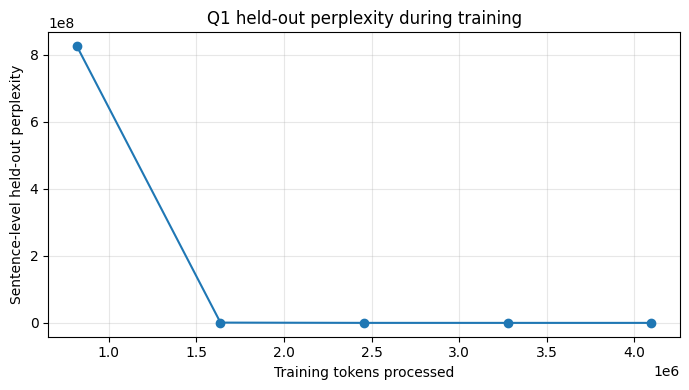

step= 100 | tokens=    819200 | ppl=825762185.3352
step= 200 | tokens=   1638400 | ppl=831517.4657
step= 300 | tokens=   2457600 | ppl=39892.8593
step= 400 | tokens=   3276800 | ppl=7049.8285
step= 500 | tokens=   4096000 | ppl=2624.3546
Measured end-of-run change: +62.77%; performance appears still improving materially.


In [51]:
# Q1.6: the training worker persisted held-out evaluations at predetermined milestones.
q1_standard_result = q1_runtime.collect_results()["standard"]
q1_ppl_curve = q1_standard_result["eval_history"]
if len(q1_ppl_curve) < 2 and not SMOKE_TEST:
    raise RuntimeError("Full training did not preserve enough intermediate PPL measurements.")

with q1_runtime_module._PLOT_LOCK:
    fig, ax = plt.subplots(figsize=(7, 4))
    ax.plot([row["tokens_processed"] for row in q1_ppl_curve],
            [row["held_out_ppl"] for row in q1_ppl_curve], marker="o")
    ax.set(title="Q1 held-out perplexity during training", xlabel="Training tokens processed",
           ylabel="Sentence-level held-out perplexity")
    ax.grid(alpha=0.3)
    fig.tight_layout()
    q1_ppl_plot = q1_runtime.plot_dir / "perplexity_vs_training_tokens.png"
    fig.savefig(q1_ppl_plot, dpi=170, bbox_inches="tight")
    plt.show()

for row in q1_ppl_curve:
    print(f"step={row['step']:4d} | tokens={row['tokens_processed']:10d} | ppl={row['held_out_ppl']:.4f}")
if len(q1_ppl_curve) >= 2:
    previous, final = q1_ppl_curve[-2]["held_out_ppl"], q1_ppl_curve[-1]["held_out_ppl"]
    relative_change = (previous - final) / max(previous, 1e-12)
    interpretation = "still improving materially" if relative_change > 0.02 else "beginning to plateau"
    print(f"Measured end-of-run change: {relative_change:+.2%}; performance appears {interpretation}.")


## 1.7 Highest-loss tokens [15 Marks]

Compute token-level negative log-likelihood on several held-out sentences and identify the target tokens with the largest losses. Group or describe the difficult tokens you observe, such as proper nouns, rare subwords, punctuation, or common function words.

Use these observations to comment on what the tokenizer–model combination finds difficult on this corpus.


In [52]:
# Q1.7: token-level NLL on several held-out sentences.
q1_token_losses = []
model.eval()
for sentence_index, sentence in enumerate(held_out[:8]):
    sentence_ids = [int(value) for value in tokenizer.encode(sentence)][:cfg.max_seq_len + 1]
    if len(sentence_ids) < 2:
        continue
    x = torch.tensor(sentence_ids[:-1], dtype=torch.long, device=q1_analysis_device).unsqueeze(0)
    y = torch.tensor(sentence_ids[1:], dtype=torch.long, device=q1_analysis_device)
    with torch.no_grad():
        logits = model(x)[0]
        losses = F.cross_entropy(logits, y, reduction="none")
    for position, (token_id, token_loss) in enumerate(zip(sentence_ids[1:], losses.tolist()), start=1):
        rendered = tokenizer.decode([int(token_id)])
        q1_token_losses.append({
            "sentence_index": sentence_index, "target_position": position,
            "token_id": int(token_id), "token": rendered,
            "negative_log_likelihood": float(token_loss),
        })

q1_highest_loss_tokens = sorted(
    q1_token_losses, key=lambda row: row["negative_log_likelihood"], reverse=True
)[:25]
for row in q1_highest_loss_tokens:
    print(f"NLL={row['negative_log_likelihood']:.4f} | sentence={row['sentence_index']} "
          f"| position={row['target_position']} | token={row['token']!r}")
q1_difficult_token_summary = {
    "punctuation_like": sum(not any(ch.isalnum() for ch in row["token"])
                            for row in q1_highest_loss_tokens),
    "contains_uppercase": sum(any(ch.isupper() for ch in row["token"])
                              for row in q1_highest_loss_tokens),
    "short_subword": sum(len(row["token"].strip()) <= 2 for row in q1_highest_loss_tokens),
}
print("Observed high-loss-token categories:", q1_difficult_token_summary)
q1_runtime_module._atomic_json(q1_runtime.analysis_dir / "highest_loss_tokens.json", {
    "evaluated_sentence_count": min(8, len(held_out)),
    "top_tokens": q1_highest_loss_tokens,
    "category_counts": q1_difficult_token_summary,
})


NLL=31.7767 | sentence=4 | position=21 | token='Polyjuice'
NLL=27.4706 | sentence=4 | position=7 | token='stal'
NLL=23.4359 | sentence=5 | position=15 | token='tonight'
NLL=22.0754 | sentence=1 | position=2 | token='xes'
NLL=20.9470 | sentence=6 | position=7 | token='sto'
NLL=20.6885 | sentence=7 | position=1 | token='everything'
NLL=20.3004 | sentence=1 | position=17 | token='born'
NLL=19.4676 | sentence=5 | position=22 | token='Hedwig'
NLL=18.7584 | sentence=3 | position=2 | token='P'
NLL=18.4035 | sentence=5 | position=32 | token='package'
NLL=17.1543 | sentence=0 | position=13 | token='ones'
NLL=17.0350 | sentence=4 | position=25 | token='slipped'
NLL=16.7725 | sentence=5 | position=11 | token='say'
NLL=16.5017 | sentence=7 | position=3 | token='dark'
NLL=16.1087 | sentence=4 | position=11 | token='Car'
NLL=15.7131 | sentence=6 | position=4 | token='Rosmerta'
NLL=15.1191 | sentence=2 | position=15 | token='Moaning'
NLL=14.5877 | sentence=6 | position=21 | token='appear'
NLL=14.4328

## 1.8 Embedding geometry [20 Marks]

Inspect the learned token embeddings for a small set of character names and common nouns. When a word is represented by multiple BPE tokens, use a clearly stated aggregation rule. Compute cosine similarities,
$$\cos(u,v)=\frac{u^\top v}{\|u\|_2\|v\|_2},$$

and report the nearest or most similar items for the selected examples.

Discuss whether the geometry shows interpretable structure or is better explained by local co-occurrence and frequency effects at this scale.


In [53]:
# Q1.8: represent a word by the mean of all of its BPE token embeddings.
q1_embedding_words = [
    "Harry", "Hermione", "Ron", "Dumbledore", "Voldemort",
    "wand", "school", "magic", "friend", "teacher", "book", "house",
]
embedding_table = model.tok_emb.weight.detach()
q1_word_vectors, q1_word_token_ids = {}, {}
for word in q1_embedding_words:
    token_ids = [int(value) for value in tokenizer.encode(word)]
    if not token_ids:
        continue
    ids_tensor = torch.tensor(token_ids, dtype=torch.long, device=embedding_table.device)
    vector = embedding_table.index_select(0, ids_tensor).mean(dim=0)
    q1_word_vectors[word] = F.normalize(vector, dim=0)
    q1_word_token_ids[word] = token_ids

q1_embedding_geometry = {}
for word, vector in q1_word_vectors.items():
    neighbours = sorted(
        ((other, float(torch.dot(vector, other_vector)))
         for other, other_vector in q1_word_vectors.items() if other != word),
        key=lambda item: item[1], reverse=True,
    )[:5]
    q1_embedding_geometry[word] = {
        "bpe_token_ids": q1_word_token_ids[word],
        "nearest_selected_words": [{"word": other, "cosine_similarity": similarity}
                                   for other, similarity in neighbours],
    }
    print(word, "->", ", ".join(f"{other} ({similarity:.3f})" for other, similarity in neighbours))

q1_runtime_module._atomic_json(q1_runtime.analysis_dir / "embedding_geometry.json", {
    "aggregation_rule": "arithmetic mean of the learned embeddings of every BPE token in the word",
    "results": q1_embedding_geometry,
    "interpretation_caution": (
        "At this scale, similarity may reflect local co-occurrence and token frequency rather than stable semantics."
    ),
})
print("Interpretation: inspect whether character names cluster; weak/mixed clustering is evidence "
      "that local co-occurrence and frequency dominate at this training scale.")


Harry -> magic (0.192), Ron (0.078), Dumbledore (0.071), wand (0.049), friend (0.042)
Hermione -> wand (0.101), book (0.075), house (0.043), teacher (0.017), Ron (0.013)
Ron -> Harry (0.078), Voldemort (0.073), wand (0.053), friend (0.034), Hermione (0.013)
Dumbledore -> Harry (0.071), book (0.068), teacher (0.066), magic (0.030), friend (0.027)
Voldemort -> Ron (0.073), book (0.070), friend (0.038), Harry (0.019), wand (0.011)
wand -> Hermione (0.101), friend (0.082), Ron (0.053), Harry (0.049), book (0.043)
school -> house (0.122), friend (0.051), magic (0.022), Harry (0.020), wand (-0.010)
magic -> Harry (0.192), teacher (0.054), Dumbledore (0.030), house (0.025), school (0.022)
friend -> book (0.166), wand (0.082), school (0.051), Harry (0.042), Voldemort (0.038)
teacher -> Dumbledore (0.066), magic (0.054), Hermione (0.017), wand (0.015), Voldemort (-0.001)
book -> friend (0.166), Hermione (0.075), Voldemort (0.070), Dumbledore (0.068), wand (0.043)
house -> school (0.122), Hermio

## 1.9 Dialogue versus narration [20 Marks]

Partition the held-out sentences into dialogue-heavy and narration-heavy subsets using a simple, stated rule such as the presence of quotation marks. Compute average sentence-level perplexity for both groups and compare them.

Report the number of examples in each group, the two perplexities and one plausible explanation for the observed direction.


In [54]:
# Q1.9: a sentence is dialogue-heavy when it contains a straight or curly quotation mark.
q1_dialogue_rule = 'contains at least one of: \", “, ”'
dialogue_sentences = [sentence for sentence in held_out if any(mark in sentence for mark in ('"', '“', '”'))]
narration_sentences = [sentence for sentence in held_out if sentence not in dialogue_sentences]
if not dialogue_sentences or not narration_sentences:
    raise RuntimeError("The stated dialogue rule produced an empty subset; report and revise the rule explicitly.")

dialogue_sentence_ppls = [
    float(perplexity_of_texts(model, tokenizer, [sentence], q1_analysis_device,
                              max_len=cfg.max_seq_len))
    for sentence in dialogue_sentences
]
narration_sentence_ppls = [
    float(perplexity_of_texts(model, tokenizer, [sentence], q1_analysis_device,
                              max_len=cfg.max_seq_len))
    for sentence in narration_sentences
]
dialogue_ppl = sum(dialogue_sentence_ppls) / len(dialogue_sentence_ppls)
narration_ppl = sum(narration_sentence_ppls) / len(narration_sentence_ppls)
q1_dialogue_results = {
    "rule": q1_dialogue_rule,
    "dialogue_count": len(dialogue_sentences),
    "narration_count": len(narration_sentences),
    "dialogue_ppl": dialogue_ppl,
    "narration_ppl": narration_ppl,
    "dialogue_sentence_ppls": dialogue_sentence_ppls,
    "narration_sentence_ppls": narration_sentence_ppls,
}
q1_runtime_module._atomic_json(q1_runtime.analysis_dir / "dialogue_vs_narration.json", q1_dialogue_results)
print(json.dumps(q1_dialogue_results, indent=2))
easier = "dialogue" if dialogue_ppl < narration_ppl else "narration"
print(
    f"Measured result: {easier} has lower average sentence-level perplexity. "
    "A plausible corpus-grounded explanation is that repeated dialogue templates and speaker turns "
    "can be easier, while narration may contain rarer descriptions—or the reverse when quotation "
    "punctuation and short turns fragment the tokenizer context."
)


{
  "rule": "contains at least one of: \", \u201c, \u201d",
  "dialogue_count": 15,
  "narration_count": 15,
  "dialogue_ppl": 2385.814076790483,
  "narration_ppl": 2862.8952116645164,
  "dialogue_sentence_ppls": [
    305.5383987924119,
    4069.1160512386796,
    1373.5133430932938,
    2672.249808725356,
    183.83372789416146,
    7912.296923755525,
    2146.05331134747,
    1627.358458755979,
    655.0584849420252,
    249.64574583151702,
    1696.0342841409308,
    175.46949496962193,
    7364.325426003983,
    2130.932053632701,
    3225.785638733586
  ],
  "narration_sentence_ppls": [
    4362.685829120919,
    535.4271514316492,
    598.0745319919441,
    2342.4431775182475,
    1174.3879839379717,
    953.0444827685369,
    8835.066886764855,
    6696.501313602774,
    5573.615245830255,
    3342.6402183547507,
    2861.5790208692497,
    2233.375458754877,
    291.1855479300847,
    2405.2186642444176,
    738.1826618472153
  ]
}
Measured result: dialogue has lower average s

## 1.10 Reproducibility and submission artifacts [5 Marks]

Save the Question 1 checkpoint, configuration, metrics, and required source snapshots in the designated submission directory. Ensure that the Question 1 autograder runs successfully in a clean execution of the notebook.
### Required saved metrics and experiment evidence

Save the following structure in `submissions/q1/metrics.json` using `save_submission(...)`. Preserve the field names and nesting. Replace every `...` with your measured result.

```python
metrics_q1 = {
    "held_out_perplexity": ...,
    "train_loss_curve": [...],
    "extrinsic_probe_accuracy": ...,

    "attention_scaling_results": [
        {
            "label": "standard",
            "attention_scale": None,
            "held_out_ppl": ...,
            "train_loss_curve": [...],
        },
        {
            "label": "unscaled",
            "attention_scale": 1.0,
            "held_out_ppl": ...,
            "train_loss_curve": [...],
        },
    ],
}
```

**Extrinsic-probe scoring**

Include at least one scored probe task. State the prediction and scoring rule, and compute:

Compute `extrinsic_probe_accuracy` as:

$$ \text{Accuracy} = \frac{\text{number of correct scored predictions}}{\text{number of scored examples}}.
$$

The denominator must be nonzero. Keep qualitative-only probes separate from this accuracy calculation. Retain the probe prompts, predictions, reference answers and scoring explanation in the notebook.

**Checkpoint and source snapshots**

Save the baseline model as the Q1 checkpoint, together with its matching configuration. Separate checkpoints for the scaling-ablation runs are not required by this submission contract; their experiment results must still be saved.

Run `save_submission(...)` before later questions overwrite the source modules.

Call `log_result(...)` for at least the final held-out perplexity and the attention-scaling summary so that `analysis_log.json` is populated.

Additional metrics are welcome. Retain all plots, examples and written analyses requested by the Q1 subtasks.


In [55]:
# Q1.10: create the official submission only from completed, non-smoke measurements.
import shutil

q1_pair_results = q1_runtime.collect_results()
_extrinsic_path = q1_runtime.analysis_dir / "extrinsic_probes.json"
if not _extrinsic_path.is_file():
    raise FileNotFoundError("Run Q1.5 before finalizing; extrinsic probe evidence is missing.")
q1_extrinsic_results = json.loads(_extrinsic_path.read_text(encoding="utf-8"))
extrinsic_probe_accuracy = float(q1_extrinsic_results["accuracy"])
attention_scaling_results = [
    {
        "label": label,
        "attention_scale": q1_pair_results[label]["attention_scale"],
        "held_out_ppl": float(q1_pair_results[label]["held_out_ppl"]),
        "train_loss_curve": [float(value) for value in q1_pair_results[label]["train_loss_curve"]],
    }
    for label in ("standard", "unscaled")
]
metrics_q1 = {
    "held_out_perplexity": float(q1_pair_results["standard"]["held_out_ppl"]),
    "train_loss_curve": [float(value) for value in q1_pair_results["standard"]["train_loss_curve"]],
    "extrinsic_probe_accuracy": extrinsic_probe_accuracy,
    "attention_scaling_results": attention_scaling_results,
}

model, cfg = q1_runtime.load_model("standard", device="cpu")
if SMOKE_TEST:
    print("SMOKE_TEST=True: official submissions/q1 was intentionally not overwritten with smoke metrics.")
    print("Set SMOKE_TEST=False, rerun setup/Q1 training and Q1.5-Q1.10 for the final submission.")
else:
    save_submission(
        "submissions/q1", model,
        {"question": "q1", "smoke_test": False, "actual_train_steps": TRAIN_STEPS, **cfg.__dict__},
        metrics_q1, VOCAB_SIZE,
    )
    q1_runtime.snapshot_sources()
    for _source_name in ("a1_tokenizer.py", "attention.py", "model_arch.py"):
        _source = Path(_source_name)
        _destination = Path("submissions/q1") / _source_name
        if _source.is_file() and not _destination.is_file():
            shutil.copy2(_source, _destination)
    log_result("q1_held_out_perplexity", metrics_q1["held_out_perplexity"])
    log_result("q1_attention_scaling", attention_scaling_results)
    log_result("q1_extrinsic_probe_accuracy", extrinsic_probe_accuracy)
    q1_official_archive = q1_runtime.export_recovery_archive(force=True, reason="official-q1-submission")
    print("Official Q1 recovery archive:", q1_official_archive)


Saved submission artifacts to submissions/q1/ (model.pt, config.json, metrics.json; sources: a1_tokenizer.py, attention.py, model_arch.py)
[logged] q1_held_out_perplexity = 2624.3546442274996
[logged] q1_attention_scaling = [{'label': 'standard', 'attention_scale': None, 'held_out_ppl': 2624.3546442274996, 'train_loss_curve': [182.22442626953125, 182.77902221679688, 142.44290161132812, 95.75779724121094, 61.94004821777344, 52.793758392333984, 48.09365463256836, 45.818485260009766, 43.50688552856445, 41.30052185058594, 40.047786712646484, 38.39868927001953, 37.544334411621094, 36.63491439819336, 35.68083953857422, 35.29011917114258, 35.46784973144531, 34.121490478515625, 33.8079719543457, 33.365501403808594, 32.36118698120117, 32.529640197753906, 32.215492248535156, 31.868175506591797, 31.373504638671875, 31.477807998657227, 30.904151916503906, 30.398983001708984, 30.274513244628906, 29.64923095703125, 29.911510467529297, 29.987201690673828, 29.614931106567383, 29.05475616455078, 28.946

### Q1 final validation and recovery export

Run this after Q1.10. It audits the completed artifacts, executes the supplied Q1
autograder when present, and refreshes the independently restorable protection ZIP.


In [58]:
q1_completion_report = q1_runtime.completion_report()
print(json.dumps(q1_completion_report, indent=2))

_missing_experiments = [
    label for label, evidence in q1_completion_report["experiments"].items()
    if evidence["status"] != "complete" or not evidence["final"] or not evidence["metrics"]
]
if _missing_experiments:
    raise RuntimeError(f"Q1 remains incomplete for experiments: {_missing_experiments}")

if not SMOKE_TEST:
    _missing_submission = [name for name, present in q1_completion_report["submission"].items()
                           if not present]
    _missing_sources = [name for name, present in q1_completion_report["sources"].items()
                        if not present]
    if _missing_submission or _missing_sources:
        raise RuntimeError(
            f"Q1 finalization missing submission={_missing_submission}, source snapshots={_missing_sources}"
        )

Q1_RUN_AUTOGRADER = (not SMOKE_TEST) and Path("autograder_q1.py").is_file()
if Q1_RUN_AUTOGRADER:
    _grader = subprocess.run(
        [sys.executable, "-u", "autograder_q1.py", "--student_dir", "."],
        text=True, capture_output=True,
    )
    print(_grader.stdout)
    if _grader.stderr:
        print(_grader.stderr)
    if _grader.returncode != 0:
        raise RuntimeError(f"Q1 autograder failed with status {_grader.returncode}")
else:
    print("Q1 autograder not run (smoke mode or autograder_q1.py is unavailable).")

q1_recovery_archive = q1_runtime.export_recovery_archive(force=True, reason="final-validation")
print("Q1 VALIDATION COMPLETE")
print("Recovery ZIP:", q1_recovery_archive)
print("Official submission folder:", Path("submissions/q1").resolve())
print("To resume elsewhere: attach this ZIP and the complete student package, then run setup top-to-bottom.")

import zipfile
# A working-directory ZIP is not independently durable. Preserve it externally.
print("IMPORTANT: use Kaggle Save Version / Output, or download and reattach the recovery ZIP.")
print("Also save/download the executed copy_assignment3.ipynb with its outputs separately.")
with zipfile.ZipFile(q1_recovery_archive) as _q1_check_archive:
    _q1_check_manifest = json.loads(_q1_check_archive.read("recovery/integrity_manifest.json"))
    print("Archive validated files:", len(_q1_check_manifest["files"]))
    print("Notebook snapshot included:", "notebook_snapshot_sha256" in _q1_check_manifest)


{
  "mode": "full",
  "experiments": {
    "standard": {
      "config": true,
      "latest": true,
      "final": true,
      "metrics": true,
      "status": "complete"
    },
    "unscaled": {
      "config": true,
      "latest": true,
      "final": true,
      "metrics": true,
      "status": "complete"
    }
  },
  "submission": {
    "model.pt": true,
    "config.json": true,
    "metrics.json": true,
    "attention.py": true,
    "model_arch.py": true
  },
  "sources": {
    "a1_tokenizer.py": true,
    "attention.py": true,
    "model_arch.py": true,
    "q1_runtime.py": true
  }
}
  [PASS] attention.py present
  [PASS] model_arch.py present
  [PASS] attention.py: no forbidden implementation
  [PASS] model_arch.py: no forbidden implementation
  [PASS] attention.py defines CausalSelfAttention
  [PASS] model_arch.py defines DecoderLM
  [PASS] model_arch.py defines LMConfig
  [PASS] CausalSelfAttention.__init__ exposes attention_scale hook (Q1.4) — params: ['self', 'd_model', '

# Question 2 — MHA, GQA, MQA, and Multi-Head Latent Attention [170 Marks]

Extend the attention implementation from Question 1 so that the number of query heads and key/value heads can differ. Compare standard Multi-Head Attention (MHA), Grouped-Query Attention (GQA), Multi-Query Attention (MQA), and the Q2-only Multi-Head Latent Attention (MLA) variant under matched training conditions.
<!--
For $h_q$ query heads and $h_{kv}$ key/value heads, MHA uses $h_{kv}=h_q$, MQA uses $h_{kv}=1$, and GQA uses an intermediate value with $h_q$ divisible by $h_{kv}$. The experiment should isolate the effect of key/value sharing while keeping the remaining architecture and training setup fixed. -->
### MHA, GQA, MQA, and Multi-Head Latent Attention

Let $h_q$ denote the number of query heads and $h_{kv}$ the number of key/value heads.

| Attention type                        | Head relationship | Key/value sharing                                                  | Main trade-off                                                                 |
| ------------------------------------- | ----------------: | ------------------------------------------------------------------ | ------------------------------------------------------------------------------ |
| **Multi-Head Attention (MHA)**        |      $h_{kv}=h_q$ | Each query head has its own key/value head.                        | Maximum flexibility, but largest KV cache.                                     |
| **Grouped-Query Attention (GQA)**     |    $1<h_{kv}<h_q$ | Each key/value head is shared by $h_q/h_{kv}$ query heads.         | Balances model flexibility and inference efficiency.                           |
| **Multi-Query Attention (MQA)**       |        $h_{kv}=1$ | All query heads share one key/value head.                          | Smallest cache among these three head-sharing variants.                        |
| **Multi-Head Latent Attention (MLA)** |    $h_{kv}=h_q$\* | All heads share one low-rank latent; per-head K/V are up-projected. | Near-MQA cache with near-MHA quality, at the cost of extra projection compute. |

For GQA, $h_q$ must be divisible by $h_{kv}$.


![Comparison of MHA, GQA, and MQA](https://waylandz.com/llm-transformer-book-en-images/ch23-01-family.svg)

*Figure: Comparison of MHA, GQA, and MQA. Source: Wayland Zhang, [“Chapter 23: From MHA to MQA to GQA”](https://waylandz.com/llm-transformer-book-en/chapter-23-mha-mqa-gqa/), 2026. MIT Licensed.*

**Scope:** MLA is implemented and evaluated only in Q2. Q3–Q5 use MHA/GQA/MQA.


### Q2 fresh-session bootstrap and immutable Q1 dependency checks

This Q2-only bootstrap can be run in a fresh Kaggle kernel. It locates the course
support package, validates a **full** Q1 recovery archive, restores only the persisted
tokenizer/source metadata needed by Q2, reconstructs the official split, and restores
an optional Q2 recovery archive. It never launches or rewrites a Q1 experiment.


In [9]:
# --------------------------- user controls ---------------------------------
Q2_SMOKE_TEST = False  # @param {type:"boolean"}; set False for the real four-model runs
Q2_PROJECT_ROOT = None  # optional exact writable assignment directory
Q1_ARCHIVE_FOR_Q2 = None  # optional exact q1_all_artifacts.zip
Q2_RECOVERY_ARCHIVE = None  # optional exact q2_all_artifacts.zip

# This cell intentionally reconstructs every Q2 dependency without executing Q1 cells.
import hashlib
import importlib
import importlib.util
import json
import math
import os
import random
import shutil
import subprocess
import sys
import tempfile
import uuid
import zipfile
from array import array
from pathlib import Path


def _q2_sha256(path, chunk_size=1024 * 1024):
    digest = hashlib.sha256()
    with open(path, "rb") as handle:
        for chunk in iter(lambda: handle.read(chunk_size), b""):
            digest.update(chunk)
    return digest.hexdigest()


def _q2_json_hash(value):
    payload = json.dumps(value, sort_keys=True, separators=(",", ":"), ensure_ascii=False)
    return hashlib.sha256(payload.encode("utf-8")).hexdigest()


def _q2_hash_ints(values, chunk_items=100_000):
    digest = hashlib.sha256()
    for start in range(0, len(values), chunk_items):
        digest.update(array("q", (int(x) for x in values[start:start + chunk_items])).tobytes())
    return digest.hexdigest()


def _q2_hash_texts(texts):
    digest = hashlib.sha256()
    for text in texts:
        payload = str(text).encode("utf-8")
        digest.update(len(payload).to_bytes(8, "little"))
        digest.update(payload)
    return digest.hexdigest()


def _q2_safe_path(root, relative):
    root = Path(root).resolve()
    target = (root / relative).resolve()
    if target != root and root not in target.parents:
        raise ValueError(f"Unsafe archive path: {relative}")
    return target


def _q2_support_signature(path):
    names = ("common.py", "common_grading.py", "download_data.py", "autograder_q2.py")
    return tuple(_q2_sha256(path / name) for name in names)


def _q2_find_support_root():
    explicit = Path(Q2_PROJECT_ROOT).expanduser().resolve() if Q2_PROJECT_ROOT else None
    if explicit is not None:
        if not (explicit / "common.py").is_file():
            raise FileNotFoundError(f"Q2_PROJECT_ROOT has no common.py: {explicit}")
        return explicit
    cwd = Path.cwd().resolve()
    candidates = []
    for candidate in (cwd, cwd / "cs781-a3-support-files",
                      Path("/kaggle/working/assignment_3"), Path("/content/assignment_3")):
        if all((candidate / name).is_file() for name in
               ("common.py", "common_grading.py", "download_data.py", "autograder_q2.py")):
            candidates.append(candidate.resolve())
    kaggle_input = Path("/kaggle/input")
    if kaggle_input.is_dir():
        candidates.extend(
            path.parent.resolve() for path in kaggle_input.rglob("autograder_q2.py")
            if all((path.parent / name).is_file() for name in
                   ("common.py", "common_grading.py", "download_data.py"))
        )
    unique = []
    for candidate in candidates:
        if candidate not in unique:
            unique.append(candidate)
    if not unique:
        raise FileNotFoundError(
            "Could not locate the complete Assignment-3 support package. Attach the supplied "
            "support dataset (common.py, common_grading.py, download_data.py, autograder_q2.py)."
        )
    signatures = {_q2_support_signature(candidate) for candidate in unique}
    if len(signatures) > 1:
        raise RuntimeError(f"Conflicting Assignment-3 support packages found: {unique}")
    if cwd in unique:
        return cwd
    return unique[0]


_q2_support_root = _q2_find_support_root()
_q2_cwd = Path.cwd().resolve()
if Q2_PROJECT_ROOT:
    _q2_project_root = Path(Q2_PROJECT_ROOT).expanduser().resolve()
elif str(_q2_cwd).startswith("/kaggle/input/"):
    _q2_project_root = Path("/kaggle/working/assignment_3").resolve()
elif Path("/kaggle/working").is_dir() and str(_q2_support_root).startswith("/kaggle/input/"):
    _q2_project_root = Path("/kaggle/working/assignment_3").resolve()
else:
    _q2_project_root = _q2_cwd
_q2_project_root.mkdir(parents=True, exist_ok=True)

# Copy ONLY the immutable course support utilities. Never traverse and copy
# arbitrary notebook-session files (e.g. Kaggle state.db, generated modules,
# existing checkpoints, or recovery archives). In particular, if support_root
# and project_root coincide, there is nothing to copy.
_Q2_SUPPORT_FILES = (
    "common.py", "common_grading.py", "download_data.py",
    "autograder_q1.py", "autograder_q2.py", "autograder_q3.py",
    "autograder_q4.py", "autograder_q5.py", "requirements.txt",
    "make_submission.sh", "make_submission.ps1",
)
for _support_name in _Q2_SUPPORT_FILES:
    _source = _q2_support_root / _support_name
    if not _source.is_file():
        continue
    _destination = _q2_project_root / _support_name
    if _source.resolve() == _destination.resolve():
        continue
    if _destination.is_file():
        if _q2_sha256(_destination) != _q2_sha256(_source):
            raise RuntimeError(
                f"Conflicting course support utility {_support_name}: "
                f"{_destination}. Verify the support dataset/version first."
            )
        continue
    shutil.copy2(_source, _destination)
os.chdir(_q2_project_root)
sys.path.insert(0, str(_q2_project_root))
print("Q2 writable project root:", _q2_project_root)


def _q2_read_archive_manifest(path, expected_mode=None):
    path = Path(path).resolve()
    with zipfile.ZipFile(path) as archive:
        if "recovery/integrity_manifest.json" not in archive.namelist():
            raise ValueError(f"Archive has no integrity manifest: {path}")
        manifest = json.loads(archive.read("recovery/integrity_manifest.json"))
    if expected_mode is not None and manifest.get("mode") != expected_mode:
        raise ValueError(
            f"Archive mode mismatch for {path}: {manifest.get('mode')!r} != {expected_mode!r}"
        )
    return manifest


def _q2_discover_archive(primary_name, explicit=None, expected_mode=None):
    if explicit:
        candidate = Path(explicit).expanduser().resolve()
        if not candidate.is_file():
            raise FileNotFoundError(candidate)
        _q2_read_archive_manifest(candidate, expected_mode)
        return candidate
    roots = [Path.cwd(), Path("/kaggle/working"), Path("/kaggle/input")]
    found = []
    for root in roots:
        if root.is_dir():
            found.extend(root.rglob(primary_name))
    found = [path.resolve() for path in found if path.is_file()]
    if not found:
        previous_name = primary_name.replace(".zip", ".previous.zip")
        for root in roots:
            if root.is_dir():
                found.extend(root.rglob(previous_name))
        found = [path.resolve() for path in found if path.is_file()]
    by_hash = {}
    for path in found:
        try:
            _q2_read_archive_manifest(path, expected_mode)
        except Exception:
            continue
        by_hash.setdefault(_q2_sha256(path), path)
    if len(by_hash) > 1:
        raise RuntimeError(
            f"Multiple non-identical {primary_name} archives found; set the explicit path: "
            + ", ".join(str(path) for path in by_hash.values())
        )
    return next(iter(by_hash.values()), None)


def _q2_restore_archive(path, prefixes, label):
    """Validate the whole ZIP, then atomically restore only missing/identical selected files."""
    path = Path(path).resolve()
    with zipfile.ZipFile(path) as archive:
        bad_member = archive.testzip()
        if bad_member is not None:
            raise ValueError(f"Corrupt member in {path}: {bad_member}")
        manifest = json.loads(archive.read("recovery/integrity_manifest.json"))
        file_manifest = manifest.get("files", {})
        selected = [
            rel for rel in file_manifest
            if any(rel == prefix or rel.startswith(prefix.rstrip("/") + "/") for prefix in prefixes)
            and "__pycache__" not in rel
        ]
        with tempfile.TemporaryDirectory(prefix=f"a3_{label}_restore_") as temp_dir:
            temp_root = Path(temp_dir).resolve()
            for rel in selected:
                staged = _q2_safe_path(temp_root, rel)
                staged.parent.mkdir(parents=True, exist_ok=True)
                with archive.open(rel) as source, open(staged, "wb") as sink:
                    shutil.copyfileobj(source, sink, length=1024 * 1024)
                info = file_manifest[rel]
                if staged.stat().st_size != int(info["size"]) or _q2_sha256(staged) != info["sha256"]:
                    raise ValueError(f"Manifest validation failed for {rel}")
            conflicts = []
            for rel in selected:
                staged = _q2_safe_path(temp_root, rel)
                destination = _q2_safe_path(Path.cwd(), rel)
                if destination.is_file() and _q2_sha256(destination) != _q2_sha256(staged):
                    conflicts.append(rel)
            if conflicts:
                raise RuntimeError(
                    f"{label} restore would overwrite non-identical local work: {conflicts[:20]}"
                )
            restored, reused = 0, 0
            for rel in selected:
                staged = _q2_safe_path(temp_root, rel)
                destination = _q2_safe_path(Path.cwd(), rel)
                if destination.exists():
                    reused += 1
                    continue
                destination.parent.mkdir(parents=True, exist_ok=True)
                candidate = destination.with_name(destination.name + f".{uuid.uuid4().hex}.restore")
                shutil.copy2(staged, candidate)
                if _q2_sha256(candidate) != _q2_sha256(staged):
                    candidate.unlink(missing_ok=True)
                    raise ValueError(f"Staged restore checksum failed for {rel}")
                os.replace(candidate, destination)
                restored += 1
    print(f"{label} archive validated; restored={restored}, already-identical={reused}: {path}")
    return manifest


# Q1 is always the completed full run. Never accept its smoke archive for Q2.
_q1_required = [
    Path("artifacts/shared/tokenizer/a1_bpe_tokenizer.json"),
    Path("artifacts/shared/tokenizer/tokenizer_metadata.json"),
    Path("artifacts/shared/tokenizer/train_ids.pt"),
    Path("artifacts/shared/tokenizer/train_ids_metadata.json"),
    Path("artifacts/full/q1/standard/config.json"),
    Path("artifacts/full/q1/source_snapshots/a1_tokenizer.py"),
    Path("artifacts/full/q1/source_snapshots/attention.py"),
    Path("artifacts/full/q1/source_snapshots/model_arch.py"),
]
_q1_archive = _q2_discover_archive(
    "q1_all_artifacts.zip", Q1_ARCHIVE_FOR_Q2, expected_mode="full"
)
if not all(path.is_file() for path in _q1_required):
    if _q1_archive is None:
        raise FileNotFoundError(
            "Q2 needs the completed full Q1 tokenizer/source metadata. Attach q1_all_artifacts.zip "
            "or restore those exact artifacts before running this cell."
        )
    _q2_restore_archive(_q1_archive, (
        "artifacts/shared/tokenizer",
        "artifacts/full/q1/source_snapshots",
        "artifacts/full/q1/standard/config.json",
        "artifacts/full/q1/standard/metrics.json",
        "artifacts/full/q1/standard/status.json",
    ), "Q1 dependency")
if not all(path.is_file() for path in _q1_required):
    raise FileNotFoundError("Q1 dependency restoration is incomplete.")

_q2_mode = "smoke" if Q2_SMOKE_TEST else "full"
_q2_archive_name = "q2_smoke_all_artifacts.zip" if Q2_SMOKE_TEST else "q2_all_artifacts.zip"
_q2_existing_root = Path("artifacts") / _q2_mode / "q2"
_q2_archive = _q2_discover_archive(
    _q2_archive_name, Q2_RECOVERY_ARCHIVE, expected_mode=_q2_mode
)
if not (_q2_existing_root.is_dir() and any(_q2_existing_root.rglob("*"))) and _q2_archive:
    _q2_restore_archive(_q2_archive, (
        f"artifacts/{_q2_mode}/q2",
        "submissions/q2",
    ), "Q2")
elif _q2_existing_root.is_dir() and any(_q2_existing_root.rglob("*")):
    print("Existing local Q2 state retained; automatic Q2 ZIP restore skipped:", _q2_existing_root)


# Download only when the seven normalized books are absent. Tokens stay in memory/env only.
for _package in ("huggingface_hub",):
    if importlib.util.find_spec(_package) is None:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", _package], check=True)
_raw_dir = Path("data/raw")
if len(list(_raw_dir.glob("book*.txt"))) != 7:
    if not os.environ.get("HF_TOKEN"):
        try:
            from kaggle_secrets import UserSecretsClient
            os.environ["HF_TOKEN"] = UserSecretsClient().get_secret("HF_TOKEN")
        except Exception:
            pass
    if not os.environ.get("HF_TOKEN"):
        raise RuntimeError(
            "The corpus is missing. Add HF_TOKEN to Kaggle Secrets (with notebook access) "
            "or attach data/raw/book1.txt ... book7.txt."
        )
    subprocess.run([sys.executable, "download_data.py", "--raw-dir", str(_raw_dir)], check=True)

import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

from common import (
    load_corpus, held_out_sentences, remove_sentences_from_text,
    BPETokenizerWrapper, TokenDataset, perplexity_of_texts,
    count_parameters, assert_within_budget, save_submission, MAX_PARAMS, SEED,
)


def log_result(key, value):
    path = Path("analysis_log.json")
    log = json.loads(path.read_text(encoding="utf-8")) if path.is_file() else {}
    log[key] = value
    temporary = path.with_name(path.name + ".tmp")
    temporary.write_text(json.dumps(log, indent=2, ensure_ascii=False), encoding="utf-8")
    os.replace(temporary, path)
    print(f"[logged] {key}")


corpus = load_corpus("data/raw")
held_out = held_out_sentences(corpus, n_chapters=5, sentences_per_chapter=6)
train_text = remove_sentences_from_text(corpus.raw_text, held_out)

_q1_spec = json.loads(Path("artifacts/full/q1/standard/config.json").read_text(encoding="utf-8"))
_q1_sources = _q1_spec["source_hashes"]
_q1_snapshot_dir = Path("artifacts/full/q1/source_snapshots")
for _name in ("a1_tokenizer.py", "attention.py", "model_arch.py"):
    _snapshot = _q1_snapshot_dir / _name
    if _q2_sha256(_snapshot) != _q1_sources[_name]:
        raise RuntimeError(f"Immutable Q1 source snapshot hash mismatch: {_snapshot}")

# Make the validated Q1 tokenizer adapter active; Q2 attention/model files are written later.
_a1_snapshot = _q1_snapshot_dir / "a1_tokenizer.py"
_a1_active = Path("a1_tokenizer.py")
if not _a1_active.is_file() or _q2_sha256(_a1_active) != _q2_sha256(_a1_snapshot):
    _a1_candidate = Path("a1_tokenizer.py.q2restore")
    shutil.copy2(_a1_snapshot, _a1_candidate)
    os.replace(_a1_candidate, _a1_active)

_a1_spec = importlib.util.spec_from_file_location("_q2_a1_tokenizer", _a1_active)
_a1_module = importlib.util.module_from_spec(_a1_spec)
_a1_spec.loader.exec_module(_a1_module)
_tokenizer_dir = Path("artifacts/shared/tokenizer")
_tokenizer_model = _tokenizer_dir / "a1_bpe_tokenizer.json"
_tokenizer_metadata = json.loads((_tokenizer_dir / "tokenizer_metadata.json").read_text(encoding="utf-8"))
_train_ids_metadata = json.loads((_tokenizer_dir / "train_ids_metadata.json").read_text(encoding="utf-8"))
_train_text_hash = hashlib.sha256(train_text.encode("utf-8")).hexdigest()
if _tokenizer_metadata.get("training_corpus_sha256") != _train_text_hash:
    raise RuntimeError("Q1 tokenizer corpus fingerprint does not match the reconstructed official split.")
if int(_tokenizer_metadata.get("requested_vocab_size", -1)) != 8000:
    raise RuntimeError("Q2 refuses a smoke/incompatible tokenizer; expected Q1 vocab target 8000.")
if _q2_sha256(_tokenizer_model) != _tokenizer_metadata.get("model_sha256"):
    raise RuntimeError("Persisted Q1 tokenizer model checksum mismatch.")
_tokenizer_impl = _a1_module.Assignment1ByteLevelBPE.load(_tokenizer_model)
tokenizer = BPETokenizerWrapper(a1_tokenizer=_tokenizer_impl, vocab_size=8000)
VOCAB_SIZE = int(tokenizer.vocab_size)
TOKENIZER_FINGERPRINT = _tokenizer_metadata["model_sha256"]

try:
    _train_ids_tensor = torch.load(_tokenizer_dir / "train_ids.pt", map_location="cpu", weights_only=True)
except TypeError:
    _train_ids_tensor = torch.load(_tokenizer_dir / "train_ids.pt", map_location="cpu")
train_ids = [int(value) for value in _train_ids_tensor.tolist()]
if len(train_ids) != int(_train_ids_metadata["token_count"]):
    raise RuntimeError("Persisted Q1 training-token count mismatch.")
if _train_ids_metadata.get("tokenizer_fingerprint") != TOKENIZER_FINGERPRINT:
    raise RuntimeError("Training-token cache was produced by a different tokenizer.")
if _q2_hash_ints(train_ids) != _q1_spec["train_ids_hash"]:
    raise RuntimeError("Training-token sequence differs from the completed Q1 experiment.")
if _q2_hash_texts(held_out) != _q1_spec["held_out_hash"]:
    raise RuntimeError("Held-out split differs from the completed Q1 experiment.")
if VOCAB_SIZE != int(_q1_spec["architecture"]["vocab_size"]):
    raise RuntimeError("Tokenizer vocabulary size differs from Q1 model configuration.")

Q2_DIALOGUE_RULE = 'contains at least one of: ", “, ”'
q2_dialogue_sentences = [s for s in held_out if any(mark in s for mark in ('"', '“', '”'))]
q2_narration_sentences = [s for s in held_out if not any(mark in s for mark in ('"', '“', '”'))]
if not q2_dialogue_sentences or not q2_narration_sentences:
    raise RuntimeError("The Q1 dialogue/narration rule produced an empty Q2 evaluation subset.")

_q1_arch = _q1_spec["architecture"]
Q2_MODEL_DIM = 64 if Q2_SMOKE_TEST else int(_q1_arch["d_model"])
Q2_MODEL_LAYERS = 1 if Q2_SMOKE_TEST else int(_q1_arch["n_layers"])
Q2_MODEL_FF = 128 if Q2_SMOKE_TEST else int(_q1_arch["d_ff"])
Q2_MODEL_SEQ_LEN = 64 if Q2_SMOKE_TEST else int(_q1_arch["max_seq_len"])
Q2_BATCH_SIZE = 2 if Q2_SMOKE_TEST else int(_q1_spec["batch_size"])
Q2_TRAIN_STEPS = 3 if Q2_SMOKE_TEST else int(_q1_spec["target_steps"])
Q2_LEARNING_RATE = float(_q1_spec["optimizer"]["lr"])
Q2_MLA_LATENT_DIM = Q2_MODEL_DIM // 4  # stated before training: 16 smoke / 64 full
Q2_CHECKPOINT_STEPS = 1 if Q2_SMOKE_TEST else 50
Q2_CHECKPOINT_SECONDS = 30 if Q2_SMOKE_TEST else 5 * 60
Q2_ARCHIVE_SECONDS = 60 if Q2_SMOKE_TEST else 10 * 60

Q1_DEPENDENCY = {
    "q1_archive_sha256": _q2_sha256(_q1_archive) if _q1_archive else None,
    "q1_trajectory_hash": _q1_spec["trajectory_hash"],
    "q1_source_hashes": _q1_sources,
    "tokenizer_fingerprint": TOKENIZER_FINGERPRINT,
    "train_ids_hash": _q1_spec["train_ids_hash"],
    "held_out_hash": _q1_spec["held_out_hash"],
    "training_corpus_sha256": _train_text_hash,
}

print(f"Q2 mode: {'SMOKE' if Q2_SMOKE_TEST else 'FULL'}")
print(f"Reused Q1 tokenizer: vocab={VOCAB_SIZE:,}, tokens={len(train_ids):,}, fp={TOKENIZER_FINGERPRINT[:12]}")
print(f"Held-out: {len(held_out)} total, {len(q2_dialogue_sentences)} dialogue, "
      f"{len(q2_narration_sentences)} narration")
print(f"Q2 controls: D={Q2_MODEL_DIM}, L={Q2_MODEL_LAYERS}, H=8, "
      f"FF={Q2_MODEL_FF}, seq={Q2_MODEL_SEQ_LEN}, batch={Q2_BATCH_SIZE}, "
      f"steps={Q2_TRAIN_STEPS}, MLA r={Q2_MLA_LATENT_DIM}")


Q2 writable project root: /kaggle/working
Q2 mode: FULL
Reused Q1 tokenizer: vocab=8,000, tokens=1,620,368, fp=1f4ec0a2657d
Held-out: 30 total, 15 dialogue, 15 narration
Q2 controls: D=256, L=4, H=8, FF=1024, seq=256, batch=32, steps=500, MLA r=64


## 2.1 MHA/GQA/MQA and MLA attention implementation [45 Marks]

Generalize the attention module to accept `n_kv_heads` separately from `n_heads`. Keep one query projection per query head, but project keys and values into only `n_kv_heads` heads. Expand each key/value head across its associated query-head group before applying the same causal scaled-dot-product attention used in Question 1. Your implementation must support all three cases.

### Multi-Head Latent Attention (MLA): Q2-only variant

Also implement `MultiHeadLatentAttention` in the same `attention.py` file. This
assignment uses **joint low-rank KV compression with direct queries**, an educational
MLA variant; query compression and decoupled RoPE are outside its scope.
All four Q2 models use the same sinusoidal positional encoding at the model input.

Let $D=d_{\mathrm{model}}$, $H=n_{\mathrm{heads}}$, $d_h=D/H$, and $r=\texttt{kv_latent_dim}$, with $0<r<D$. Using row-vector notation:

$$C=XW_D,\quad Q=XW_Q,\quad K=CW_{UK},\quad V=CW_{UV}.$$

The projection shapes are $W_D\in\mathbb{R}^{D\times r}$,
$W_Q\in\mathbb{R}^{D\times D}$, and
$W_{UK},W_{UV}\in\mathbb{R}^{r\times D}$.
Reshape Q, K, and V into H heads of width $d_h$, then compute

$$Y=\operatorname{Concat}_{h=1}^H\left[\operatorname{softmax}\left(Q_hK_h^\top/\sqrt{d_h}+M\right)V_h\right]W_O,$$

where M is the causal mask and $W_O\in\mathbb{R}^{D\times D}$.
Use the same attention/residual dropout conventions as the other variants.
Preserve the `attention_scale` override; `None` uses $1/\sqrt{d_h}$.
Do not add nonlinearities or normalization between these projections.

Use bias-free `nn.Linear` modules named `q_proj`, `kv_down_proj`, `k_up_proj`,
`v_up_proj`, and `out_proj`, with the dimensions specified in the code stub.
The same latent C must feed both K and V; this is not MQA or head repetition.
Implement the attention arithmetic manually under the same Q1–Q4 restrictions.

Reference concept: [DeepSeek-V2, Section 2.1.2](https://arxiv.org/abs/2405.04434).


In [12]:
%%writefile attention.py
"""Manual MHA/GQA/MQA and Q2 joint-latent attention implementations."""
import math
import torch
import torch.nn as nn


class CausalSelfAttention(nn.Module):
    """Causal attention with independent query-head and key/value-head counts."""
    def __init__(self, d_model: int, n_heads: int, n_kv_heads: int,
                 max_seq_len: int, dropout: float = 0.0, attention_scale=None):
        super().__init__()
        if d_model <= 0 or n_heads <= 0 or n_kv_heads <= 0:
            raise ValueError("d_model, n_heads, and n_kv_heads must be positive")
        if d_model % n_heads != 0:
            raise ValueError("d_model must be divisible by n_heads")
        if n_heads % n_kv_heads != 0:
            raise ValueError("n_heads must be divisible by n_kv_heads")
        if max_seq_len <= 0:
            raise ValueError("max_seq_len must be positive")
        self.n_heads = int(n_heads)
        self.n_kv_heads = int(n_kv_heads)
        self.n_rep = self.n_heads // self.n_kv_heads
        self.d_head = int(d_model) // self.n_heads
        self.attention_scale = (
            1.0 / math.sqrt(self.d_head) if attention_scale is None else float(attention_scale)
        )
        if not math.isfinite(self.attention_scale) or self.attention_scale <= 0:
            raise ValueError("attention_scale must be finite and positive")

        self.q_proj = nn.Linear(d_model, self.n_heads * self.d_head, bias=False)
        self.k_proj = nn.Linear(d_model, self.n_kv_heads * self.d_head, bias=False)
        self.v_proj = nn.Linear(d_model, self.n_kv_heads * self.d_head, bias=False)
        self.out_proj = nn.Linear(self.n_heads * self.d_head, d_model, bias=False)
        self.attn_dropout = nn.Dropout(dropout)
        self.resid_dropout = nn.Dropout(dropout)
        self.register_buffer(
            "causal_mask",
            torch.tril(torch.ones(max_seq_len, max_seq_len, dtype=torch.bool)),
            persistent=False,
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        if x.ndim != 3:
            raise ValueError("x must have shape (batch, sequence, d_model)")
        batch, length, channels = x.shape
        if length > self.causal_mask.size(0):
            raise ValueError(
                f"Sequence length {length} exceeds configured maximum {self.causal_mask.size(0)}"
            )
        q = self.q_proj(x).view(batch, length, self.n_heads, self.d_head).transpose(1, 2)
        k = self.k_proj(x).view(batch, length, self.n_kv_heads, self.d_head).transpose(1, 2)
        v = self.v_proj(x).view(batch, length, self.n_kv_heads, self.d_head).transpose(1, 2)
        # Contiguous query-head groups share each KV head: [k0...k0, k1...k1, ...].
        if self.n_rep != 1:
            k = torch.repeat_interleave(k, self.n_rep, dim=1)
            v = torch.repeat_interleave(v, self.n_rep, dim=1)
        scores = torch.matmul(q, k.transpose(-2, -1)) * self.attention_scale
        allowed = self.causal_mask[:length, :length].view(1, 1, length, length)
        weights = torch.softmax(scores.masked_fill(~allowed, float("-inf")), dim=-1)
        weights = self.attn_dropout(weights)
        output = torch.matmul(weights, v)
        output = output.transpose(1, 2).contiguous().view(batch, length, channels)
        return self.resid_dropout(self.out_proj(output))


class MultiHeadLatentAttention(nn.Module):
    """Q2 joint low-rank KV compression with direct, uncompressed queries."""
    def __init__(self, d_model: int, n_heads: int, kv_latent_dim: int,
                 max_seq_len: int, dropout: float = 0.0, attention_scale=None):
        super().__init__()
        if d_model <= 0 or n_heads <= 0 or d_model % n_heads != 0:
            raise ValueError("d_model must be positive and divisible by n_heads")
        if not isinstance(kv_latent_dim, int) or not 0 < kv_latent_dim < d_model:
            raise ValueError("kv_latent_dim must be an integer strictly between 0 and d_model")
        if max_seq_len <= 0:
            raise ValueError("max_seq_len must be positive")
        self.n_heads = int(n_heads)
        self.d_head = int(d_model) // self.n_heads
        self.kv_latent_dim = int(kv_latent_dim)
        self.attention_scale = (
            1.0 / math.sqrt(self.d_head) if attention_scale is None else float(attention_scale)
        )
        if not math.isfinite(self.attention_scale) or self.attention_scale <= 0:
            raise ValueError("attention_scale must be finite and positive")

        self.q_proj = nn.Linear(d_model, d_model, bias=False)
        self.kv_down_proj = nn.Linear(d_model, self.kv_latent_dim, bias=False)
        self.k_up_proj = nn.Linear(self.kv_latent_dim, d_model, bias=False)
        self.v_up_proj = nn.Linear(self.kv_latent_dim, d_model, bias=False)
        self.out_proj = nn.Linear(d_model, d_model, bias=False)
        self.attn_dropout = nn.Dropout(dropout)
        self.resid_dropout = nn.Dropout(dropout)
        self.register_buffer(
            "causal_mask",
            torch.tril(torch.ones(max_seq_len, max_seq_len, dtype=torch.bool)),
            persistent=False,
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        if x.ndim != 3:
            raise ValueError("x must have shape (batch, sequence, d_model)")
        batch, length, channels = x.shape
        if length > self.causal_mask.size(0):
            raise ValueError(
                f"Sequence length {length} exceeds configured maximum {self.causal_mask.size(0)}"
            )
        latent = self.kv_down_proj(x)  # computed once and shared by both reconstruction branches
        q = self.q_proj(x).view(batch, length, self.n_heads, self.d_head).transpose(1, 2)
        k = self.k_up_proj(latent).view(batch, length, self.n_heads, self.d_head).transpose(1, 2)
        v = self.v_up_proj(latent).view(batch, length, self.n_heads, self.d_head).transpose(1, 2)
        scores = torch.matmul(q, k.transpose(-2, -1)) * self.attention_scale
        allowed = self.causal_mask[:length, :length].view(1, 1, length, length)
        weights = torch.softmax(scores.masked_fill(~allowed, float("-inf")), dim=-1)
        weights = self.attn_dropout(weights)
        output = torch.matmul(weights, v)
        output = output.transpose(1, 2).contiguous().view(batch, length, channels)
        return self.resid_dropout(self.out_proj(output))


Overwriting attention.py


## 2.2 Integration into the decoder architecture [25 Marks]

Update the language-model configuration and decoder blocks so that `n_kv_heads` is propagated correctly through every attention layer. The remainder of the architecture, positional encoding, residual structure, and language-model objective should remain matched to Question 1 so that the attention mechanism is the controlled variable.


For Q2 only, add `attention_type: str = "standard"` and
`kv_latent_dim: int = None` to `LMConfig`. Here `standard` selects the existing
MHA/GQA/MQA class using `n_kv_heads`; `mla` selects `MultiHeadLatentAttention`.
The experiment-row labels `mha/gqa/mqa/mla` identify individual variants; the
configuration selector `standard/mla` identifies the implementation class.
For MLA, `n_kv_heads` is unused (set it to `None` in the experiment configuration),
and `kv_latent_dim` is required. Require sinusoidal positions for Q2 MLA.
Keep this dispatch inside the same `model_arch.py`; no additional source file is needed.


In [13]:
%%writefile model_arch.py
"""Q2 decoder-only LM dispatching between standard MHA/GQA/MQA and Q2 MLA."""
import math
from dataclasses import dataclass
import torch
import torch.nn as nn
from attention import CausalSelfAttention, MultiHeadLatentAttention


@dataclass
class LMConfig:
    vocab_size: int
    d_model: int = 256
    n_layers: int = 4
    n_heads: int = 8
    n_kv_heads: int = 8
    d_ff: int = 1024
    max_seq_len: int = 256
    dropout: float = 0.1
    pos_emb_type: str = "sinusoidal"
    attention_scale: float = None
    norm_first: bool = False
    attention_type: str = "standard"
    kv_latent_dim: int = None


def sinusoidal_positional_encoding(max_len: int, d_model: int) -> torch.Tensor:
    if max_len <= 0 or d_model <= 0:
        raise ValueError("max_len and d_model must be positive")
    position = torch.arange(max_len, dtype=torch.float32).unsqueeze(1)
    even_indices = torch.arange(0, d_model, 2, dtype=torch.float32)
    frequencies = torch.exp(-math.log(10000.0) * even_indices / d_model)
    angles = position * frequencies.unsqueeze(0)
    encoding = torch.zeros(max_len, d_model, dtype=torch.float32)
    encoding[:, 0::2] = torch.sin(angles)
    if d_model > 1:
        encoding[:, 1::2] = torch.cos(angles[:, :encoding[:, 1::2].shape[1]])
    return encoding


class FeedForward(nn.Module):
    def __init__(self, d_model: int, d_ff: int, dropout: float):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(d_model, d_ff),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(d_ff, d_model),
            nn.Dropout(dropout),
        )

    def forward(self, x):
        return self.net(x)


class Block(nn.Module):
    def __init__(self, cfg: LMConfig):
        super().__init__()
        self.norm_first = bool(cfg.norm_first)
        self.ln1 = nn.LayerNorm(cfg.d_model)
        if cfg.attention_type == "mla":
            if cfg.pos_emb_type != "sinusoidal":
                raise ValueError("Q2 MLA requires sinusoidal positional encoding")
            self.attn = MultiHeadLatentAttention(
                cfg.d_model, cfg.n_heads, cfg.kv_latent_dim, cfg.max_seq_len,
                cfg.dropout, attention_scale=cfg.attention_scale,
            )
        elif cfg.attention_type == "standard":
            if cfg.n_kv_heads is None:
                raise ValueError("standard attention requires n_kv_heads")
            self.attn = CausalSelfAttention(
                cfg.d_model, cfg.n_heads, cfg.n_kv_heads, cfg.max_seq_len,
                cfg.dropout, attention_scale=cfg.attention_scale,
            )
        else:
            raise ValueError("attention_type must be 'standard' or 'mla'")
        self.ln2 = nn.LayerNorm(cfg.d_model)
        self.ffn = FeedForward(cfg.d_model, cfg.d_ff, cfg.dropout)

    def forward(self, x):
        if self.norm_first:
            x = x + self.attn(self.ln1(x))
            return x + self.ffn(self.ln2(x))
        x = self.ln1(x + self.attn(x))
        return self.ln2(x + self.ffn(x))


class DecoderLM(nn.Module):
    def __init__(self, cfg: LMConfig):
        super().__init__()
        if cfg.vocab_size <= 0 or cfg.n_layers <= 0:
            raise ValueError("vocab_size and n_layers must be positive")
        self.cfg = cfg
        self.tok_emb = nn.Embedding(cfg.vocab_size, cfg.d_model)
        if cfg.pos_emb_type == "sinusoidal":
            self.register_buffer(
                "pos_emb",
                sinusoidal_positional_encoding(cfg.max_seq_len, cfg.d_model),
                persistent=False,
            )
        elif cfg.pos_emb_type != "rope":
            raise ValueError("pos_emb_type must be 'sinusoidal' or 'rope'")
        self.blocks = nn.ModuleList([Block(cfg) for _ in range(cfg.n_layers)])
        self.ln_f = nn.LayerNorm(cfg.d_model)
        self.head = nn.Linear(cfg.d_model, cfg.vocab_size, bias=False)
        self.head.weight = self.tok_emb.weight

    def forward(self, idx: torch.Tensor) -> torch.Tensor:
        if idx.ndim != 2:
            raise ValueError("idx must have shape (batch, sequence)")
        _, length = idx.shape
        if length > self.cfg.max_seq_len:
            raise ValueError(
                f"Sequence length {length} exceeds max_seq_len={self.cfg.max_seq_len}"
            )
        x = self.tok_emb(idx)
        if self.cfg.pos_emb_type == "sinusoidal":
            x = x + self.pos_emb[:length].to(dtype=x.dtype).unsqueeze(0)
        for block in self.blocks:
            x = block(x)
        return self.head(self.ln_f(x))


Overwriting model_arch.py


In [14]:
# Reload both Q2 modules so this fresh session cannot retain Q1 class objects.
import importlib, sys
for _name in ("model_arch", "attention"):
    sys.modules.pop(_name, None)
attention = importlib.import_module("attention")
model_arch = importlib.import_module("model_arch")
LMConfig, DecoderLM = model_arch.LMConfig, model_arch.DecoderLM
print("Loaded Q2 attention/model modules:", attention.__file__, model_arch.__file__)


Loaded Q2 attention/model modules: /kaggle/working/attention.py /kaggle/working/model_arch.py


## 2.3 Controlled four-configuration experiment [45 Marks]

Fix `n_heads=8` and train **MHA, GQA, MQA, and MLA** under matched conditions:

| Variant (`attention_type`) | `n_kv_heads` in results | `kv_latent_dim` in results |
|---|---:|---:|
| `mha` | 8 | `None` |
| `gqa` | 2 | `None` |
| `mqa` | 1 | `None` |
| `mla` | `None` (not applicable) | Your chosen integer r, with 0 < r < d_model |

Choose and state one latent dimension before the MLA run. Keep model width, FFN width,
layers, query heads, normalization convention, dropout, tokenizer, sinusoidal positions,
optimizer, learning rate, data split, training budget, and random-seed procedure matched.
Parameter counts may differ; every model must remain within the 50M budget.

Record the following fields in each row of `results_q2`:

| Saved field | Meaning |
|---|---|
| `attention_type` | `mha`, `gqa`, `mqa`, or `mla` |
| `n_kv_heads` | 8, 2, 1, or `None` for MLA |
| `kv_latent_dim` | r for MLA; `None` otherwise |
| `params` | Total model parameters |
| `kv_projection_params` | Bias-free KV-path weight count across all layers; see Q2.5 |
| `held_out_ppl` | Perplexity on the complete held-out set |
| `dialogue_ppl` | Sentence-level perplexity on dialogue sentences |
| `narration_ppl` | Sentence-level perplexity on narration sentences |
| `kv_cache_bytes_per_token` | Theoretical FP32 cache bytes per token across all layers, batch size 1 |

For MHA/GQA/MQA, use $2h_{kv}d_hL\times4$ cache bytes/token.
For MLA, use $rL\times4$: one shared latent per layer, not separate K and V latents.
These are **theoretical inference cache** figures, not measured training memory.
This task does not require implementing incremental decoding or an optimized cache;
the straightforward training forward pass may explicitly reconstruct K and V.


### Q2 experiment runtime, validation, and independently resumable GPU pairs

The runtime below is Q2-specific: each variant owns its model, optimizer, deterministic
sampler, RNG state, history, checksummed latest/previous checkpoint, final weights, and
metrics.  Pair cells retain fixed pair-position device assignment (`cuda:0`, `cuda:1`).
Full mode requires both GPUs; only explicitly labelled smoke mode may fall back to
sequential execution.  Periodic recovery archives never contain the large Q1 ZIP—they
record its validated dependency hashes instead.


In [15]:
%%writefile q2_runtime.py
"""Independent, crash-resumable Q2 training/evaluation runtime."""
from __future__ import annotations

import hashlib
import json
import math
import os
import shutil
import statistics
import subprocess
import sys
import tempfile
import threading
import time
import traceback
import uuid
import zipfile
from concurrent.futures import ThreadPoolExecutor, as_completed
from datetime import datetime, timezone
from pathlib import Path

import torch
import torch.nn.functional as F
from torch.utils.data import DataLoader, Sampler
from tqdm.auto import tqdm

from model_arch import DecoderLM, LMConfig


SCHEMA_VERSION = 2
VARIANT_ORDER = ("mha", "gqa", "mqa", "mla")
DEFAULT_PAIRING = (("mha", "mla"), ("gqa", "mqa"))


def utc_now():
    return datetime.now(timezone.utc).isoformat()


def sha256_file(path, chunk_size=1024 * 1024):
    digest = hashlib.sha256()
    with open(path, "rb") as handle:
        for chunk in iter(lambda: handle.read(chunk_size), b""):
            digest.update(chunk)
    return digest.hexdigest()


def json_hash(value):
    payload = json.dumps(value, sort_keys=True, separators=(",", ":"), ensure_ascii=False)
    return hashlib.sha256(payload.encode("utf-8")).hexdigest()


def state_hash(state):
    digest = hashlib.sha256()
    for name in sorted(state):
        tensor = state[name].detach().cpu().contiguous()
        digest.update(name.encode("utf-8"))
        digest.update(str(tensor.dtype).encode("ascii"))
        digest.update(json.dumps(list(tensor.shape)).encode("ascii"))
        digest.update(tensor.numpy().tobytes())
    return digest.hexdigest()


def cpu_state_dict(model):
    return {name: tensor.detach().cpu().clone() for name, tensor in model.state_dict().items()}


def atomic_json(path, value):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    candidate = path.with_name(path.name + f".{uuid.uuid4().hex}.tmp")
    candidate.write_text(json.dumps(value, indent=2, ensure_ascii=False), encoding="utf-8")
    json.loads(candidate.read_text(encoding="utf-8"))
    os.replace(candidate, path)


def torch_load(path, map_location="cpu"):
    try:
        return torch.load(path, map_location=map_location, weights_only=False)
    except TypeError:
        return torch.load(path, map_location=map_location)


def atomic_torch(path, value):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    candidate = path.with_name(path.name + f".{uuid.uuid4().hex}.tmp")
    torch.save(value, candidate)
    torch_load(candidate, "cpu")
    digest = sha256_file(candidate)
    os.replace(candidate, path)
    atomic_json(path.with_name(path.name + ".sha256.json"), {
        "sha256": digest, "size": path.stat().st_size, "updated_utc": utc_now(),
    })
    return digest


def verify_checksummed_file(path):
    path = Path(path)
    sidecar = path.with_name(path.name + ".sha256.json")
    if not path.is_file() or not sidecar.is_file():
        return False
    try:
        record = json.loads(sidecar.read_text(encoding="utf-8"))
        return path.stat().st_size == int(record["size"]) and sha256_file(path) == record["sha256"]
    except Exception:
        return False


class ResumableBatchSampler(Sampler):
    """Step-addressed deterministic shuffled batches; cursor is the completed step."""
    def __init__(self, dataset_size, batch_size, seed, start_step, stop_step):
        self.dataset_size = int(dataset_size)
        self.batch_size = int(batch_size)
        self.seed = int(seed)
        self.start_step = int(start_step)
        self.stop_step = int(stop_step)
        self.batches_per_epoch = self.dataset_size // self.batch_size
        if self.batches_per_epoch < 1:
            raise ValueError("Dataset is too small for one complete batch")

    def __iter__(self):
        cached_epoch, permutation = None, None
        for step in range(self.start_step, self.stop_step):
            epoch, within = divmod(step, self.batches_per_epoch)
            if epoch != cached_epoch:
                generator = torch.Generator(device="cpu").manual_seed(self.seed + epoch)
                permutation = torch.randperm(self.dataset_size, generator=generator)
                cached_epoch = epoch
            start = within * self.batch_size
            yield permutation[start:start + self.batch_size].tolist()

    def __len__(self):
        return max(0, self.stop_step - self.start_step)

    def state_dict(self, completed_step):
        epoch, within = divmod(int(completed_step), self.batches_per_epoch)
        return {
            "scheme": "epoch_randperm_seed_plus_epoch_v2",
            "seed": self.seed,
            "completed_step": int(completed_step),
            "epoch": int(epoch),
            "batch_cursor": int(within),
            "batches_per_epoch": int(self.batches_per_epoch),
            "dataset_size": self.dataset_size,
            "batch_size": self.batch_size,
        }


class Q2Runtime:
    def __init__(self, *, smoke_test, train_ids, eval_token_groups, base_config,
                 variant_definitions, target_steps, batch_size, learning_rate, seed,
                 tokenizer_fingerprint, train_ids_hash, held_out_hash, q1_dependency,
                 checkpoint_steps=50, checkpoint_seconds=300, archive_seconds=600,
                 notebook_path="copy_assignment3.ipynb"):
        self.smoke_test = bool(smoke_test)
        self.mode = "smoke" if self.smoke_test else "full"
        self.root = Path("artifacts") / self.mode / "q2"
        self.archive_path = Path(
            "q2_smoke_all_artifacts.zip" if self.smoke_test else "q2_all_artifacts.zip"
        )
        self.notebook_path = Path(notebook_path)
        self.train_ids = [int(value) for value in train_ids]
        self.dataset = torch.utils.data.TensorDataset(
            torch.tensor(self.train_ids[:-1], dtype=torch.long)
        )
        # TokenDataset semantics are implemented without making four copies of the corpus.
        self.seq_len = int(base_config["max_seq_len"])
        self.chunk_count = max(0, (len(self.train_ids) - 1) // self.seq_len)
        if self.chunk_count < int(batch_size):
            raise ValueError("Token sequence is too short for the configured Q2 batch")
        self.eval_token_groups = {
            name: [[int(x) for x in ids] for ids in rows]
            for name, rows in eval_token_groups.items()
        }
        self.base_config = dict(base_config)
        self.variant_definitions = json.loads(json.dumps(variant_definitions))
        self.target_steps = int(target_steps)
        self.batch_size = int(batch_size)
        self.learning_rate = float(learning_rate)
        self.seed = int(seed)
        self.tokenizer_fingerprint = str(tokenizer_fingerprint)
        self.train_ids_hash = str(train_ids_hash)
        self.held_out_hash = str(held_out_hash)
        self.q1_dependency = json.loads(json.dumps(q1_dependency))
        self.checkpoint_steps = int(checkpoint_steps)
        self.checkpoint_seconds = float(checkpoint_seconds)
        self.archive_seconds = float(archive_seconds)
        self.io_lock = threading.RLock()
        self.model_build_lock = threading.Lock()
        self.last_archive_monotonic = 0.0
        self.source_names = ("a1_tokenizer.py", "attention.py", "model_arch.py", "q2_runtime.py")
        self.source_hashes = {}
        self.initialization = {}

    def architecture(self, label):
        if label not in VARIANT_ORDER:
            raise KeyError(label)
        cfg = dict(self.base_config)
        cfg.update(self.variant_definitions[label])
        return cfg

    def _model_dir(self, label):
        return self.root / label

    def _experiment_id(self, label):
        return f"q2-{self.mode}-{label}"

    def _build_model(self, label, seed_offset=0):
        # Model construction is always serialized and isolated from the caller's CPU RNG.
        with self.model_build_lock, torch.random.fork_rng(devices=[]):
            torch.manual_seed(self.seed + int(seed_offset))
            model = DecoderLM(LMConfig(**self.architecture(label))).cpu()
        return model

    def _expected_initial_state(self, label):
        return torch_load(self._model_dir(label) / "initial.pt", "cpu")

    def _training_contract(self):
        return {
            "target_steps": self.target_steps,
            "batch_size": self.batch_size,
            "sequence_length": self.seq_len,
            "optimizer": {"name": "Adam", "lr": self.learning_rate},
            "seed": self.seed,
            "sampler_scheme": "epoch_randperm_seed_plus_epoch_v2",
            "tokenizer_fingerprint": self.tokenizer_fingerprint,
            "train_ids_hash": self.train_ids_hash,
            "held_out_hash": self.held_out_hash,
            "smoke_test": self.smoke_test,
        }

    def _spec_payload(self, label):
        return {
            "schema_version": SCHEMA_VERSION,
            "experiment_id": self._experiment_id(label),
            "label": label,
            "architecture": self.architecture(label),
            "training": self._training_contract(),
            "source_hashes": self.source_hashes,
            "initialization": self.initialization[label],
            "q1_dependency": self.q1_dependency,
        }

    def _spec_fingerprint(self, label):
        return json_hash(self._spec_payload(label))

    def configure(self):
        self.root.mkdir(parents=True, exist_ok=True)
        for subdir in ("analysis", "plots", "source_snapshots", "manifests", "recovery"):
            (self.root / subdir).mkdir(parents=True, exist_ok=True)

        for name in self.source_names:
            source = Path(name)
            if not source.is_file():
                raise FileNotFoundError(f"Required Q2 source is missing: {source}")
            self.source_hashes[name] = sha256_file(source)
            snapshot = self.root / "source_snapshots" / name
            if snapshot.is_file() and sha256_file(snapshot) != self.source_hashes[name]:
                raise RuntimeError(f"Existing immutable Q2 source snapshot conflicts: {snapshot}")
            if not snapshot.exists():
                shutil.copy2(source, snapshot)

        dependency_path = self.root / "manifests" / "q1_dependency.json"
        if dependency_path.is_file():
            previous = json.loads(dependency_path.read_text(encoding="utf-8"))
            if previous != self.q1_dependency:
                raise RuntimeError("The restored Q2 state depends on a different Q1 run")
        else:
            atomic_json(dependency_path, self.q1_dependency)

        canonical = self._build_model("mha", seed_offset=0)
        canonical_state = cpu_state_dict(canonical)
        canonical_hash = state_hash(canonical_state)
        del canonical
        for variant_index, label in enumerate(VARIANT_ORDER):
            model_dir = self._model_dir(label)
            model_dir.mkdir(parents=True, exist_ok=True)
            if label == "mha":
                state = {name: tensor.clone() for name, tensor in canonical_state.items()}
                shared = sorted(state)
            else:
                model = self._build_model(label, seed_offset=1000 + variant_index)
                state = cpu_state_dict(model)
                shared = []
                for name, tensor in canonical_state.items():
                    if name in state and tuple(state[name].shape) == tuple(tensor.shape):
                        state[name] = tensor.clone()
                        shared.append(name)
                del model
            init_hash = state_hash(state)
            init_path = model_dir / "initial.pt"
            if init_path.is_file():
                if not verify_checksummed_file(init_path):
                    raise RuntimeError(f"Initial-state checksum failed: {init_path}")
                if state_hash(torch_load(init_path, "cpu")) != init_hash:
                    raise RuntimeError(f"Initial state conflicts with fair Q2 initialization: {label}")
            else:
                atomic_torch(init_path, state)
            self.initialization[label] = {
                "method": "canonical_mha_then_copy_same_name_same_shape_v1",
                "state_sha256": init_hash,
                "canonical_mha_state_sha256": canonical_hash,
                "shared_tensor_names": shared,
                "variant_seed": self.seed if label == "mha" else self.seed + 1000 + variant_index,
            }

        for label in VARIANT_ORDER:
            spec = self._spec_payload(label)
            spec["spec_fingerprint"] = self._spec_fingerprint(label)
            spec_path = self._model_dir(label) / "config.json"
            if spec_path.is_file():
                previous = json.loads(spec_path.read_text(encoding="utf-8"))
                if previous != spec:
                    raise RuntimeError(f"Incompatible existing Q2 experiment config: {label}")
            else:
                atomic_json(spec_path, spec)
            model = self._build_model(label)
            model.load_state_dict(self._expected_initial_state(label), strict=True)
            params = sum(parameter.numel() for parameter in model.parameters())
            if params > 50_000_000:
                raise RuntimeError(f"{label} exceeds the 50M parameter budget: {params}")
            del model

        contract = {
            "mode": self.mode,
            "variant_order": list(VARIANT_ORDER),
            "default_pairing": [list(pair) for pair in DEFAULT_PAIRING],
            "training": self._training_contract(),
            "source_hashes": self.source_hashes,
        }
        atomic_json(self.root / "manifests" / "experiment_contract.json", contract)
        return self.status_report()

    def _chunk(self, index):
        start = int(index) * self.seq_len
        return (
            torch.tensor(self.train_ids[start:start + self.seq_len], dtype=torch.long),
            torch.tensor(self.train_ids[start + 1:start + self.seq_len + 1], dtype=torch.long),
        )

    class _ChunkDataset(torch.utils.data.Dataset):
        def __init__(self, runtime):
            self.runtime = runtime
        def __len__(self):
            return self.runtime.chunk_count
        def __getitem__(self, index):
            return self.runtime._chunk(index)

    def _checkpoint_paths(self, label):
        root = self._model_dir(label)
        return root / "checkpoint.latest.pt", root / "checkpoint.previous.pt"

    def _validate_checkpoint_payload(self, label, payload):
        if not isinstance(payload, dict) or payload.get("schema_version") != SCHEMA_VERSION:
            raise ValueError("checkpoint schema mismatch")
        if payload.get("experiment_id") != self._experiment_id(label):
            raise ValueError("checkpoint experiment mismatch")
        if payload.get("spec_fingerprint") != self._spec_fingerprint(label):
            raise ValueError("checkpoint configuration fingerprint mismatch")
        step = payload.get("completed_step")
        if type(step) is not int or not 0 <= step <= self.target_steps:
            raise ValueError("invalid completed step")
        history = payload.get("history")
        if not isinstance(history, list) or len(history) != step:
            raise ValueError("training-history continuity mismatch")
        if history and [row.get("step") for row in history] != list(range(1, step + 1)):
            raise ValueError("training history has missing/duplicate steps")
        expected_tokens = step * self.batch_size * self.seq_len
        if payload.get("tokens_processed") != expected_tokens:
            raise ValueError("token counter does not match completed step")
        sampler = payload.get("sampler_state", {})
        if sampler.get("completed_step") != step:
            raise ValueError("sampler cursor does not match completed step")
        state = payload.get("model_state")
        if not isinstance(state, dict) or state_hash(state) != payload.get("model_state_sha256"):
            raise ValueError("checkpoint model state checksum mismatch")
        initial = self._expected_initial_state(label)
        if set(state) != set(initial):
            raise ValueError("checkpoint state keys mismatch")
        for name in state:
            if tuple(state[name].shape) != tuple(initial[name].shape):
                raise ValueError(f"checkpoint tensor shape mismatch: {name}")
        if not isinstance(payload.get("optimizer_state"), dict):
            raise ValueError("optimizer state is missing")
        if "cpu_generator_state" not in payload or "device_rng_state" not in payload:
            raise ValueError("model-specific RNG state is missing")
        return payload

    def _load_checkpoint_candidate(self, label, path):
        path = Path(path)
        if not verify_checksummed_file(path):
            raise ValueError(f"checkpoint file checksum failed: {path}")
        return self._validate_checkpoint_payload(label, torch_load(path, "cpu"))

    def load_checkpoint(self, label):
        latest, previous = self._checkpoint_paths(label)
        errors = []
        for path in (latest, previous):
            if not path.exists():
                continue
            try:
                payload = self._load_checkpoint_candidate(label, path)
                if path == previous:
                    print(f"[{label}] latest invalid/unavailable; recovered previous checkpoint")
                return payload
            except Exception as exc:
                errors.append(f"{path.name}: {type(exc).__name__}: {exc}")
        if errors:
            raise RuntimeError(f"No valid checkpoint for {label}: " + " | ".join(errors))
        return None

    def _save_checkpoint(self, label, model, optimizer, scaler, *, step, history,
                         eval_history, cumulative_seconds, device, cpu_generator,
                         sampler_state, last_checkpoint_step, reason):
        state = cpu_state_dict(model)
        device_rng_state = (
            torch.cuda.get_rng_state(device).cpu()
            if device.type == "cuda" else torch.get_rng_state().cpu()
        )
        payload = {
            "schema_version": SCHEMA_VERSION,
            "experiment_id": self._experiment_id(label),
            "label": label,
            "spec_fingerprint": self._spec_fingerprint(label),
            "architecture": self.architecture(label),
            "training_contract": self._training_contract(),
            "completed_step": int(step),
            "epoch": int(sampler_state["epoch"]),
            "batch_cursor": int(sampler_state["batch_cursor"]),
            "tokens_processed": int(step * self.batch_size * self.seq_len),
            "sampler_state": sampler_state,
            "model_state": state,
            "model_state_sha256": state_hash(state),
            "optimizer_state": optimizer.state_dict(),
            "scheduler_state": None,
            "amp_scaler_state": scaler.state_dict() if scaler is not None else None,
            "cpu_generator_state": cpu_generator.get_state(),
            "device_rng_state": device_rng_state,
            "assigned_device": str(device),
            "history": history,
            "eval_history": eval_history,
            "cumulative_active_seconds": float(cumulative_seconds),
            "last_checkpoint_step": int(last_checkpoint_step),
            "checkpoint_reason": str(reason),
            "saved_utc": utc_now(),
        }
        latest, previous = self._checkpoint_paths(label)
        with self.io_lock:
            candidate = latest.with_name(latest.name + f".{uuid.uuid4().hex}.candidate")
            torch.save(payload, candidate)
            loaded = torch_load(candidate, "cpu")
            self._validate_checkpoint_payload(label, loaded)
            candidate_hash = sha256_file(candidate)
            if latest.is_file() and verify_checksummed_file(latest):
                previous_candidate = previous.with_name(previous.name + f".{uuid.uuid4().hex}.tmp")
                shutil.copy2(latest, previous_candidate)
                if sha256_file(previous_candidate) != sha256_file(latest):
                    previous_candidate.unlink(missing_ok=True)
                    raise IOError("previous-checkpoint copy verification failed")
                os.replace(previous_candidate, previous)
                atomic_json(previous.with_name(previous.name + ".sha256.json"), {
                    "sha256": sha256_file(previous), "size": previous.stat().st_size,
                    "updated_utc": utc_now(),
                })
            os.replace(candidate, latest)
            atomic_json(latest.with_name(latest.name + ".sha256.json"), {
                "sha256": candidate_hash, "size": latest.stat().st_size,
                "updated_utc": utc_now(),
            })
        return int(step)

    def _save_plain_state(self, path, model):
        state = cpu_state_dict(model)
        atomic_torch(path, state)
        return state_hash(state)

    def _evaluate(self, model, token_rows, device):
        modes = [(module, module.training) for module in model.modules()]
        values = []
        try:
            model.eval()
            with torch.no_grad():
                for ids in token_rows:
                    clipped = ids[: self.seq_len + 1]
                    if len(clipped) < 2:
                        continue
                    x = torch.tensor(clipped[:-1], dtype=torch.long, device=device).unsqueeze(0)
                    y = torch.tensor(clipped[1:], dtype=torch.long, device=device).unsqueeze(0)
                    logits = model(x)
                    loss = F.cross_entropy(logits.reshape(-1, logits.size(-1)), y.reshape(-1))
                    value = math.exp(float(loss.item()))
                    if not math.isfinite(value):
                        raise FloatingPointError("non-finite sentence perplexity")
                    values.append(value)
        finally:
            for module, training in modes:
                module.training = training
        if not values:
            raise ValueError("evaluation subset has no sentence with at least two tokens")
        return float(sum(values) / len(values))

    def _kv_counts(self, label):
        cfg = self.architecture(label)
        d, h, layers = cfg["d_model"], cfg["n_heads"], cfg["n_layers"]
        if label == "mla":
            latent = cfg["kv_latent_dim"]
            return int(3 * d * latent * layers), int(latent * layers * 4)
        kv = cfg["n_kv_heads"]
        return int(2 * d * kv * (d // h) * layers), int(2 * kv * (d // h) * layers * 4)

    def _optimizer_to(self, optimizer, device):
        for state in optimizer.state.values():
            for key, value in list(state.items()):
                if torch.is_tensor(value):
                    state[key] = value.to(device)

    def _make_scaler(self, enabled):
        try:
            return torch.amp.GradScaler("cuda", enabled=enabled)
        except (AttributeError, TypeError):
            return torch.cuda.amp.GradScaler(enabled=enabled)

    def _train_worker(self, label, device_name, position, model, restored):
        device = torch.device(device_name)
        model = model.to(device)
        optimizer = torch.optim.Adam(model.parameters(), lr=self.learning_rate)
        scaler = self._make_scaler(device.type == "cuda")
        start_step = 0
        history, eval_history = [], []
        cumulative_base = 0.0
        cpu_generator = torch.Generator(device="cpu").manual_seed(self.seed + 10_000 + VARIANT_ORDER.index(label))
        resumed = restored is not None
        if restored is not None:
            model.load_state_dict(restored["model_state"], strict=True)
            optimizer.load_state_dict(restored["optimizer_state"])
            self._optimizer_to(optimizer, device)
            if restored.get("amp_scaler_state"):
                scaler.load_state_dict(restored["amp_scaler_state"])
            start_step = int(restored["completed_step"])
            history = list(restored["history"])
            eval_history = list(restored["eval_history"])
            cumulative_base = float(restored.get("cumulative_active_seconds", 0.0))
            cpu_generator.set_state(restored["cpu_generator_state"])
            if device.type == "cuda":
                torch.cuda.set_rng_state(restored["device_rng_state"], device)
            else:
                torch.set_rng_state(restored["device_rng_state"])
        elif device.type == "cuda":
            generator = torch.Generator(device=device).manual_seed(
                self.seed + 20_000 + VARIANT_ORDER.index(label)
            )
            torch.cuda.set_rng_state(generator.get_state(), device)
        else:
            torch.manual_seed(self.seed + 20_000 + VARIANT_ORDER.index(label))

        sampler = ResumableBatchSampler(
            self.chunk_count, self.batch_size, self.seed,
            start_step=start_step, stop_step=self.target_steps,
        )
        loader = DataLoader(
            self._ChunkDataset(self), batch_sampler=sampler, num_workers=0,
            pin_memory=(device.type == "cuda"),
        )
        last_checkpoint_step = start_step
        last_checkpoint_time = time.monotonic()
        session_start = time.monotonic()
        current_step = start_step
        status_path = self._model_dir(label) / "status.json"
        atomic_json(status_path, {
            "status": "running", "experiment_id": self._experiment_id(label),
            "completed_step": start_step, "assigned_device": str(device),
            "resumed": resumed, "updated_utc": utc_now(),
        })
        milestones = {max(1, math.ceil(self.target_steps * fraction / 5)) for fraction in range(1, 6)}
        best_ppl = min(
            (float(row["held_out_ppl"]) for row in eval_history if math.isfinite(float(row["held_out_ppl"]))),
            default=float("inf"),
        )
        progress = tqdm(
            total=self.target_steps, initial=start_step, position=position, leave=True,
            desc=f"{label.upper()} | {device}", dynamic_ncols=True,
        )
        try:
            for x, y in loader:
                x = x.to(device, non_blocking=True)
                y = y.to(device, non_blocking=True)
                optimizer.zero_grad(set_to_none=True)
                with torch.autocast(
                    device_type=device.type, dtype=torch.float16,
                    enabled=(device.type == "cuda"),
                ):
                    logits = model(x)
                    loss = F.cross_entropy(logits.reshape(-1, logits.size(-1)), y.reshape(-1))
                if not torch.isfinite(loss):
                    raise FloatingPointError(f"non-finite training loss at step {current_step + 1}")
                scaler.scale(loss).backward()
                scaler.step(optimizer)
                scaler.update()
                current_step += 1
                session_elapsed = time.monotonic() - session_start
                cumulative = cumulative_base + session_elapsed
                tokens = current_step * self.batch_size * self.seq_len
                history.append({
                    "step": current_step,
                    "epoch": sampler.state_dict(current_step)["epoch"],
                    "loss": float(loss.item()),
                    "learning_rate": float(optimizer.param_groups[0]["lr"]),
                    "tokens_processed": tokens,
                    "elapsed_seconds": cumulative,
                })
                with self.io_lock:
                    atomic_json(self._model_dir(label) / "history.json", {
                        "history": history, "eval_history": eval_history,
                        "completed_step": current_step, "cumulative_active_seconds": cumulative,
                    })

                evaluated = current_step in milestones and not any(
                    row.get("step") == current_step for row in eval_history
                )
                if evaluated:
                    ppl = self._evaluate(model, self.eval_token_groups["held_out"], device)
                    eval_history.append({
                        "step": current_step, "tokens_processed": tokens,
                        "held_out_ppl": ppl, "elapsed_seconds": cumulative,
                    })
                    if ppl < best_ppl:
                        best_ppl = ppl
                        with self.io_lock:
                            self._save_plain_state(self._model_dir(label) / "best.pt", model)

                due = (
                    current_step == self.target_steps
                    or current_step - last_checkpoint_step >= self.checkpoint_steps
                    or time.monotonic() - last_checkpoint_time >= self.checkpoint_seconds
                    or evaluated
                )
                if due:
                    reason = "completion" if current_step == self.target_steps else (
                        "evaluation" if evaluated else "interval"
                    )
                    last_checkpoint_step = self._save_checkpoint(
                        label, model, optimizer, scaler, step=current_step,
                        history=history, eval_history=eval_history,
                        cumulative_seconds=cumulative, device=device,
                        cpu_generator=cpu_generator,
                        sampler_state=sampler.state_dict(current_step),
                        last_checkpoint_step=current_step, reason=reason,
                    )
                    last_checkpoint_time = time.monotonic()
                    self.maybe_export_recovery_zip()

                recent = [row["loss"] for row in history[-20:]]
                rate = (current_step - start_step) / max(session_elapsed, 1e-9)
                progress.update(1)
                progress.set_postfix({
                    "epoch": sampler.state_dict(current_step)["epoch"],
                    "loss": f"{sum(recent) / len(recent):.3f}",
                    "lr": f"{optimizer.param_groups[0]['lr']:.1e}",
                    "tokens": tokens,
                    "step/s": f"{rate:.2f}",
                    "tok/s": f"{rate * self.batch_size * self.seq_len:.0f}",
                    "elapsed": f"{session_elapsed:.0f}s",
                    "cumulative": f"{cumulative:.0f}s",
                    "ckpt": last_checkpoint_step,
                    "state": "resumed" if resumed else "new",
                })

            cumulative = cumulative_base + (time.monotonic() - session_start)
            held_ppl = self._evaluate(model, self.eval_token_groups["held_out"], device)
            dialogue_ppl = self._evaluate(model, self.eval_token_groups["dialogue"], device)
            narration_ppl = self._evaluate(model, self.eval_token_groups["narration"], device)
            final_hash = self._save_plain_state(self._model_dir(label) / "final.pt", model)
            best_path = self._model_dir(label) / "best.pt"
            if not best_path.exists():
                self._save_plain_state(best_path, model)
            kv_params, cache_bytes = self._kv_counts(label)
            params = int(sum(parameter.numel() for parameter in model.parameters()))
            definition = self.variant_definitions[label]
            result = {
                "attention_type": label,
                "n_kv_heads": definition.get("n_kv_heads"),
                "kv_latent_dim": definition.get("kv_latent_dim"),
                "held_out_ppl": float(held_ppl),
                "dialogue_ppl": float(dialogue_ppl),
                "narration_ppl": float(narration_ppl),
                "params": params,
                "kv_projection_params": int(kv_params),
                "kv_cache_bytes_per_token": int(cache_bytes),
            }
            metrics = {
                "result": result,
                "loss_curve": [float(row["loss"]) for row in history],
                "history": history,
                "eval_history": eval_history,
                "completed_steps": current_step,
                "tokens_processed": current_step * self.batch_size * self.seq_len,
                "cumulative_active_seconds": cumulative,
                "initialization": self.initialization[label],
                "final_state_sha256": final_hash,
                "spec_fingerprint": self._spec_fingerprint(label),
            }
            with self.io_lock:
                atomic_json(self._model_dir(label) / "metrics.json", metrics)
                atomic_json(status_path, {
                    "status": "complete", "experiment_id": self._experiment_id(label),
                    "completed_step": current_step, "assigned_device": str(device),
                    "final_held_out_ppl": held_ppl,
                    "final_state_sha256": final_hash,
                    "updated_utc": utc_now(),
                })
            print(f"[{label}] completed on {device}; this session={time.monotonic()-session_start:.1f}s, "
                  f"cumulative={cumulative:.1f}s, held-out PPL={held_ppl:.4f}")
            return result
        except BaseException as exc:
            emergency_error = None
            try:
                cumulative = cumulative_base + (time.monotonic() - session_start)
                self._save_checkpoint(
                    label, model, optimizer, scaler, step=current_step,
                    history=history, eval_history=eval_history,
                    cumulative_seconds=cumulative, device=device,
                    cpu_generator=cpu_generator,
                    sampler_state=sampler.state_dict(current_step),
                    last_checkpoint_step=current_step, reason="emergency",
                )
            except BaseException as checkpoint_exc:
                emergency_error = f"{type(checkpoint_exc).__name__}: {checkpoint_exc}"
            atomic_json(status_path, {
                "status": "failed", "experiment_id": self._experiment_id(label),
                "completed_step": current_step, "assigned_device": str(device),
                "error": f"{type(exc).__name__}: {exc}",
                "emergency_checkpoint_error": emergency_error,
                "traceback": traceback.format_exc(), "updated_utc": utc_now(),
            })
            raise
        finally:
            progress.close()
            del model
            if device.type == "cuda":
                torch.cuda.empty_cache()

    def _validate_final(self, label):
        status_path = self._model_dir(label) / "status.json"
        metrics_path = self._model_dir(label) / "metrics.json"
        final_path = self._model_dir(label) / "final.pt"
        if not (status_path.is_file() and metrics_path.is_file() and final_path.is_file()):
            return False
        try:
            status = json.loads(status_path.read_text(encoding="utf-8"))
            metrics = json.loads(metrics_path.read_text(encoding="utf-8"))
            if status.get("status") != "complete" or status.get("completed_step") != self.target_steps:
                return False
            if metrics.get("completed_steps") != self.target_steps:
                return False
            if metrics.get("spec_fingerprint") != self._spec_fingerprint(label):
                return False
            if not verify_checksummed_file(final_path):
                return False
            state = torch_load(final_path, "cpu")
            if state_hash(state) != metrics.get("final_state_sha256"):
                return False
            initial = self._expected_initial_state(label)
            if set(state) != set(initial):
                return False
            for name in state:
                if tuple(state[name].shape) != tuple(initial[name].shape):
                    return False
            row = metrics.get("result", {})
            return all(
                type(row.get(key)) in (int, float) and math.isfinite(row[key]) and row[key] >= 1
                for key in ("held_out_ppl", "dialogue_ppl", "narration_ppl")
            )
        except Exception:
            return False

    def is_complete(self, label):
        return self._validate_final(label)

    def status_report(self):
        report = {}
        for label in VARIANT_ORDER:
            status_path = self._model_dir(label) / "status.json"
            if self.is_complete(label):
                metrics = json.loads((self._model_dir(label) / "metrics.json").read_text(encoding="utf-8"))
                report[label] = {
                    "status": "complete", "step": self.target_steps,
                    "held_out_ppl": metrics["result"]["held_out_ppl"],
                }
            elif status_path.is_file():
                status = json.loads(status_path.read_text(encoding="utf-8"))
                report[label] = {
                    "status": status.get("status", "incomplete"),
                    "step": int(status.get("completed_step", 0)),
                }
            else:
                checkpoint = self.load_checkpoint(label)
                report[label] = {
                    "status": "resumable" if checkpoint else "missing",
                    "step": int(checkpoint["completed_step"]) if checkpoint else 0,
                }
        return report

    def _persist_pairing(self, plan, evidence):
        flat = [label for pair in plan for label in pair]
        if len(plan) != 2 or any(len(pair) != 2 for pair in plan) or sorted(flat) != sorted(VARIANT_ORDER):
            raise ValueError("A Q2 pairing plan must cover every variant exactly once")
        path = self.root / "manifests" / "pairing_plan.json"
        record = {"pairs": [list(pair) for pair in plan], "evidence": evidence, "created_utc": utc_now()}
        if path.is_file():
            existing = json.loads(path.read_text(encoding="utf-8"))
            return tuple(tuple(pair) for pair in existing["pairs"])
        atomic_json(path, record)
        return tuple(tuple(pair) for pair in plan)

    def load_pairing_plan(self):
        path = self.root / "manifests" / "pairing_plan.json"
        if path.is_file():
            return tuple(tuple(pair) for pair in json.loads(path.read_text(encoding="utf-8"))["pairs"])
        return DEFAULT_PAIRING

    def timing_probe(self, measured_steps=3):
        device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
        sample_indices = list(range(self.batch_size))
        rows = [self._chunk(index) for index in sample_indices]
        x = torch.stack([row[0] for row in rows]).to(device)
        y = torch.stack([row[1] for row in rows]).to(device)
        timings = {}
        for label in VARIANT_ORDER:
            model = self._build_model(label)
            model.load_state_dict(self._expected_initial_state(label), strict=True)
            model = model.to(device).train()
            optimizer = torch.optim.Adam(model.parameters(), lr=self.learning_rate)
            samples = []
            for iteration in range(2 + int(measured_steps)):
                optimizer.zero_grad(set_to_none=True)
                if device.type == "cuda":
                    torch.cuda.synchronize(device)
                started = time.perf_counter()
                logits = model(x)
                loss = F.cross_entropy(logits.reshape(-1, logits.size(-1)), y.reshape(-1))
                loss.backward()
                optimizer.step()
                if device.type == "cuda":
                    torch.cuda.synchronize(device)
                elapsed = time.perf_counter() - started
                if iteration >= 2:
                    samples.append(elapsed)
            timings[label] = float(statistics.median(samples))
            del model, optimizer
            if device.type == "cuda":
                torch.cuda.empty_cache()
        record = {"device": str(device), "median_step_seconds": timings, "measured_steps": measured_steps}
        atomic_json(self.root / "analysis" / "timing_probe.json", record)
        return record

    def choose_pairing(self, timing_record):
        existing = self.root / "manifests" / "pairing_plan.json"
        if existing.is_file():
            return self.load_pairing_plan()
        if any(self._checkpoint_paths(label)[0].exists() or self.is_complete(label) for label in VARIANT_ORDER):
            return self._persist_pairing(DEFAULT_PAIRING, {
                "reason": "Training state already exists; retained stable default pairing",
                "timing_probe": timing_record,
            })
        times = timing_record["median_step_seconds"]
        ordered = sorted(VARIANT_ORDER, key=lambda label: (times[label], label))
        measured_plan = ((ordered[0], ordered[1]), (ordered[2], ordered[3]))
        default_gap = sum(abs(times[a] - times[b]) for a, b in DEFAULT_PAIRING)
        measured_gap = sum(abs(times[a] - times[b]) for a, b in measured_plan)
        plan = measured_plan if measured_gap + 1e-12 < default_gap else DEFAULT_PAIRING
        reason = (
            "Adjacent measured step times minimize within-pair imbalance"
            if plan == measured_plan and plan != DEFAULT_PAIRING
            else "The requested MHA+MLA and GQA+MQA pairing is as balanced as the measured alternative"
        )
        return self._persist_pairing(plan, {
            "reason": reason, "timing_probe": timing_record,
            "default_total_abs_gap": default_gap, "selected_total_abs_gap": min(default_gap, measured_gap),
        })

    def _prepare_model_for_run(self, label, restored):
        model = self._build_model(label)
        state = restored["model_state"] if restored is not None else self._expected_initial_state(label)
        model.load_state_dict(state, strict=True)
        return model

    def run_pair(self, pair, position_offset=0, full_plan=None):
        pair = tuple(pair)
        if len(pair) != 2 or pair[0] == pair[1] or any(label not in VARIANT_ORDER for label in pair):
            raise ValueError(f"Invalid Q2 pair: {pair}")
        if full_plan is not None:
            persisted = self._persist_pairing(tuple(tuple(x) for x in full_plan), {
                "reason": "Notebook-selected plan", "source": "timing/default cell",
            })
            if pair not in persisted:
                raise ValueError(f"Pair {pair} is not in the persisted plan {persisted}")
        unfinished = [label for label in pair if not self.is_complete(label)]
        if not unfinished:
            print(f"Pair {pair} already complete; validated saved results and skipped training.")
            return {label: self.result(label) for label in pair}
        if not self.smoke_test and torch.cuda.device_count() < 2:
            raise RuntimeError(
                "Full Q2 pair training requires two visible GPUs. Enable Kaggle's 2 x T4 accelerator."
            )

        prepared = {}
        for position, label in enumerate(pair):
            if label not in unfinished:
                continue
            restored = self.load_checkpoint(label)
            prepared[label] = (restored, self._prepare_model_for_run(label, restored), position)

        errors, outputs = {}, {}
        try:
            if torch.cuda.device_count() >= 2:
                with ThreadPoolExecutor(max_workers=len(prepared), thread_name_prefix="q2") as pool:
                    futures = {}
                    for label, (restored, model, position) in prepared.items():
                        device_name = f"cuda:{position}"  # fixed by position even if its partner finished
                        future = pool.submit(
                            self._train_worker, label, device_name, position_offset + position, model, restored
                        )
                        futures[future] = label
                    for future in as_completed(futures):
                        label = futures[future]
                        try:
                            outputs[label] = future.result()
                        except BaseException as exc:
                            errors[label] = exc
            else:
                fallback = "cuda:0" if torch.cuda.is_available() else "cpu"
                print(f"SMOKE ONLY: two GPUs unavailable; executing {pair} sequentially on {fallback}.")
                for label, (restored, model, position) in prepared.items():
                    try:
                        outputs[label] = self._train_worker(
                            label, fallback, position_offset, model, restored
                        )
                    except BaseException as exc:
                        errors[label] = exc
        finally:
            try:
                self.export_recovery_zip(force=True)
            except BaseException as archive_exc:
                print("Q2 emergency archive failed:", type(archive_exc).__name__, archive_exc)
        if errors:
            details = "; ".join(f"{label}: {type(exc).__name__}: {exc}" for label, exc in errors.items())
            raise RuntimeError(
                "One or more Q2 workers failed after every partner was allowed to finish: " + details
            )
        for label in pair:
            if self.is_complete(label):
                outputs[label] = self.result(label)
        return outputs

    def result(self, label):
        if not self.is_complete(label):
            raise RuntimeError(f"Q2 {label} is not complete and deeply validated")
        metrics = json.loads((self._model_dir(label) / "metrics.json").read_text(encoding="utf-8"))
        return metrics["result"]

    def results(self):
        return [self.result(label) for label in VARIANT_ORDER]

    def require_all_complete(self):
        missing = [label for label in VARIANT_ORDER if not self.is_complete(label)]
        if missing:
            raise RuntimeError(f"Complete/resume these Q2 models first: {missing}")
        return self.results()

    def load_final_model(self, label, device="cpu"):
        if not self.is_complete(label):
            raise RuntimeError(f"Q2 {label} has no valid completed final state")
        model = self._build_model(label)
        model.load_state_dict(torch_load(self._model_dir(label) / "final.pt", "cpu"), strict=True)
        return model.to(device)

    def parameter_accounting(self):
        rows = []
        for label in VARIANT_ORDER:
            model = self.load_final_model(label, "cpu")
            cfg = self.architecture(label)
            if label == "mla":
                names = ("kv_down_proj.weight", "k_up_proj.weight", "v_up_proj.weight")
            else:
                names = ("k_proj.weight", "v_proj.weight")
            actual = sum(
                parameter.numel()
                for name, parameter in model.named_parameters()
                if any(name.endswith("attn." + suffix) for suffix in names)
            )
            formula, cache = self._kv_counts(label)
            if int(actual) != int(formula):
                raise AssertionError(f"{label} actual KV tensors={actual}, formula={formula}")
            result = self.result(label)
            if result["kv_projection_params"] != formula or result["kv_cache_bytes_per_token"] != cache:
                raise AssertionError(f"{label} persisted accounting is inconsistent")
            rows.append({
                "variant": label, "total_params": int(sum(p.numel() for p in model.parameters())),
                "actual_kv_projection_params": int(actual), "formula_kv_projection_params": int(formula),
                "kv_cache_bytes_per_token": int(cache),
            })
        mha = next(row for row in rows if row["variant"] == "mha")
        for row in rows:
            row["kv_param_fraction_vs_mha"] = row["actual_kv_projection_params"] / mha["actual_kv_projection_params"]
            row["cache_fraction_vs_mha"] = row["kv_cache_bytes_per_token"] / mha["kv_cache_bytes_per_token"]
        atomic_json(self.root / "analysis" / "parameter_accounting.json", {"rows": rows})
        return rows

    def select_for_q3(self):
        eligible = [self.result(label) for label in ("mha", "gqa", "mqa")]
        eligible = [row for row in eligible if math.isfinite(float(row["held_out_ppl"]))]
        if len(eligible) != 3:
            raise RuntimeError("Q3 selection requires all finite MHA/GQA/MQA held-out results")
        winner = min(eligible, key=lambda row: (row["held_out_ppl"], row["attention_type"]))
        label = winner["attention_type"]
        record = {
            "provisional_smoke_only": self.smoke_test,
            "selection_rule": "lowest finite held_out_ppl among mha/gqa/mqa; mla excluded",
            "selected_label": label,
            "held_out_ppl": winner["held_out_ppl"],
            "n_heads": self.architecture(label)["n_heads"],
            "n_kv_heads": self.architecture(label)["n_kv_heads"],
            "architecture": self.architecture(label),
            "final_state_path": str((self._model_dir(label) / "final.pt").resolve()),
            "final_state_file_sha256": sha256_file(self._model_dir(label) / "final.pt"),
            "source_hashes": self.source_hashes,
            "tokenizer_fingerprint": self.tokenizer_fingerprint,
            "train_ids_hash": self.train_ids_hash,
            "held_out_hash": self.held_out_hash,
            "eligible_results": eligible,
        }
        atomic_json(self.root / "analysis" / "q3_selection.json", record)
        return record

    def _archive_file_list(self):
        files = []
        if self.root.is_dir():
            files.extend(path for path in self.root.rglob("*") if path.is_file())
        submission = Path("submissions/q2")
        if submission.is_dir():
            files.extend(path for path in submission.rglob("*") if path.is_file())
        if Path("analysis_log.json").is_file():
            files.append(Path("analysis_log.json"))
        if self.notebook_path.is_file():
            files.append(self.notebook_path)
        unique = {}
        for path in files:
            resolved = path.resolve()
            unique[resolved] = path
        return [unique[key] for key in sorted(unique, key=str)]

    def _validate_archive(self, path):
        with zipfile.ZipFile(path) as archive:
            bad = archive.testzip()
            if bad is not None:
                raise ValueError(f"bad ZIP member: {bad}")
            manifest = json.loads(archive.read("recovery/integrity_manifest.json"))
            if manifest.get("mode") != self.mode:
                raise ValueError("recovery archive mode mismatch")
            for rel, info in manifest.get("files", {}).items():
                digest = hashlib.sha256()
                size = 0
                with archive.open(rel) as handle:
                    for chunk in iter(lambda: handle.read(1024 * 1024), b""):
                        size += len(chunk)
                        digest.update(chunk)
                if size != int(info["size"]) or digest.hexdigest() != info["sha256"]:
                    raise ValueError(f"archive manifest mismatch: {rel}")
        return manifest

    def export_recovery_zip(self, force=False):
        with self.io_lock:
            now = time.monotonic()
            if not force and now - self.last_archive_monotonic < self.archive_seconds:
                return self.archive_path if self.archive_path.exists() else None
            files = self._archive_file_list()
            manifest_files = {}
            for path in files:
                rel = path.as_posix()
                manifest_files[rel] = {"size": path.stat().st_size, "sha256": sha256_file(path)}
            manifest = {
                "schema_version": SCHEMA_VERSION,
                "question": "q2", "mode": self.mode, "created_utc": utc_now(),
                "files": manifest_files, "source_hashes": self.source_hashes,
                "q1_dependency": self.q1_dependency,
                "status": self.status_report(),
            }
            candidate = self.archive_path.with_name(
                self.archive_path.name + f".{uuid.uuid4().hex}.candidate"
            )
            with zipfile.ZipFile(candidate, "w", compression=zipfile.ZIP_DEFLATED, allowZip64=True) as archive:
                for path in files:
                    archive.write(path, arcname=path.as_posix())
                archive.writestr(
                    "recovery/integrity_manifest.json",
                    json.dumps(manifest, indent=2, ensure_ascii=False),
                )
            self._validate_archive(candidate)
            previous = self.archive_path.with_name(self.archive_path.name.replace(".zip", ".previous.zip"))
            if self.archive_path.is_file():
                try:
                    self._validate_archive(self.archive_path)
                    previous_candidate = previous.with_name(previous.name + f".{uuid.uuid4().hex}.tmp")
                    shutil.copy2(self.archive_path, previous_candidate)
                    self._validate_archive(previous_candidate)
                    os.replace(previous_candidate, previous)
                except Exception as exc:
                    print("Existing Q2 archive was not rotated because validation failed:", exc)
            os.replace(candidate, self.archive_path)
            archive_hash = sha256_file(self.archive_path)
            atomic_json(self.root / "recovery" / "latest_export.json", {
                "path": str(self.archive_path.resolve()), "sha256": archive_hash,
                "size": self.archive_path.stat().st_size, "created_utc": utc_now(),
            })
            self.last_archive_monotonic = now
            print(f"Validated Q2 recovery ZIP: {self.archive_path} ({archive_hash[:12]}..., "
                  f"{self.archive_path.stat().st_size / 2**20:.1f} MiB)")
            return self.archive_path

    def maybe_export_recovery_zip(self):
        return self.export_recovery_zip(force=False)

    def run_self_tests(self):
        from attention import CausalSelfAttention, MultiHeadLatentAttention
        tests = {}
        generator = torch.Generator(device="cpu").manual_seed(781)
        for kv in (8, 2, 1):
            module = CausalSelfAttention(64, 8, kv, 16, dropout=0.0).eval()
            for layer_name in ("q_proj", "k_proj", "v_proj", "out_proj"):
                layer = getattr(module, layer_name)
                with torch.no_grad():
                    layer.weight.copy_(torch.randn(layer.weight.shape, generator=generator) * 0.1)
            x = torch.randn(2, 7, 64, generator=generator)
            q = F.linear(x, module.q_proj.weight).view(2, 7, 8, 8).transpose(1, 2)
            k = F.linear(x, module.k_proj.weight).view(2, 7, kv, 8).transpose(1, 2)
            v = F.linear(x, module.v_proj.weight).view(2, 7, kv, 8).transpose(1, 2)
            index = torch.arange(8) // (8 // kv)
            k, v = k[:, index], v[:, index]
            scores = (q @ k.transpose(-2, -1)) / math.sqrt(8)
            scores = scores.masked_fill(torch.ones(7, 7, dtype=torch.bool).triu(1), float("-inf"))
            expected = F.linear(
                (scores.softmax(-1) @ v).transpose(1, 2).reshape(2, 7, 64),
                module.out_proj.weight,
            )
            torch.testing.assert_close(module(x), expected, atol=1e-5, rtol=1e-5)
            tests[f"standard_reference_kv{kv}"] = "passed"

        for latent in (5, 16):
            module = MultiHeadLatentAttention(64, 8, latent, 16, dropout=0.0, attention_scale=0.37)
            x = torch.randn(2, 7, 64, generator=generator, requires_grad=True)
            actual = module(x)
            q = F.linear(x, module.q_proj.weight).view(2, 7, 8, 8).transpose(1, 2)
            k = F.linear(x, module.k_up_proj.weight @ module.kv_down_proj.weight).view(2, 7, 8, 8).transpose(1, 2)
            v = F.linear(x, module.v_up_proj.weight @ module.kv_down_proj.weight).view(2, 7, 8, 8).transpose(1, 2)
            scores = (q @ k.transpose(-2, -1)) * 0.37
            scores = scores.masked_fill(torch.ones(7, 7, dtype=torch.bool).triu(1), float("-inf"))
            expected = F.linear(
                (scores.softmax(-1) @ v).transpose(1, 2).reshape(2, 7, 64),
                module.out_proj.weight,
            )
            torch.testing.assert_close(actual, expected, atol=1e-5, rtol=1e-5)
            actual.square().mean().backward()
            if not torch.isfinite(x.grad).all():
                raise AssertionError("MLA gradient is non-finite")
            tests[f"mla_reference_r{latent}"] = "passed"

        for label in VARIANT_ORDER:
            model = self._build_model(label)
            model.load_state_dict(self._expected_initial_state(label), strict=True)
            ids = torch.randint(0, self.base_config["vocab_size"], (2, min(8, self.seq_len)), generator=generator)
            logits = model(ids)
            loss = logits.float().square().mean()
            loss.backward()
            if tuple(logits.shape) != (2, ids.size(1), self.base_config["vocab_size"]):
                raise AssertionError(f"bad {label} output shape")
            if not torch.isfinite(logits).all():
                raise AssertionError(f"non-finite {label} forward")
            tests[f"model_forward_backward_{label}"] = "passed"

        # Causality: perturb a future suffix and compare the unchanged prefix.
        causal = self._build_model("gqa").eval()
        causal.load_state_dict(self._expected_initial_state("gqa"), strict=True)
        ids = torch.randint(0, self.base_config["vocab_size"], (2, min(8, self.seq_len)), generator=generator)
        changed = ids.clone()
        cutoff = ids.size(1) // 2 - 1
        changed[:, cutoff + 1:] = (changed[:, cutoff + 1:] + 1) % self.base_config["vocab_size"]
        with torch.no_grad():
            torch.testing.assert_close(causal(ids)[:, :cutoff + 1], causal(changed)[:, :cutoff + 1])
        tests["causal_mask"] = "passed"

        sampler_a = list(ResumableBatchSampler(23, 4, 1337, 0, 6))
        sampler_b = list(ResumableBatchSampler(23, 4, 1337, 3, 6))
        if sampler_a[3:] != sampler_b:
            raise AssertionError("deterministic sampler continuation failed")
        tests["sampler_continuation"] = "passed"

        bad = {
            "schema_version": SCHEMA_VERSION, "experiment_id": self._experiment_id("mha"),
            "spec_fingerprint": "wrong",
        }
        try:
            self._validate_checkpoint_payload("mha", bad)
            raise AssertionError("incompatible checkpoint was accepted")
        except ValueError:
            tests["incompatible_checkpoint_rejected"] = "passed"

        with tempfile.TemporaryDirectory(prefix="q2_optimizer_test_") as temp:
            model = self._build_model("mha")
            model.load_state_dict(self._expected_initial_state("mha"), strict=True)
            optimizer = torch.optim.Adam(model.parameters(), lr=self.learning_rate)
            ids = torch.randint(0, self.base_config["vocab_size"], (1, min(4, self.seq_len)), generator=generator)
            model(ids).float().mean().backward()
            optimizer.step()
            path = Path(temp) / "state.pt"
            torch.save({"model": model.state_dict(), "optimizer": optimizer.state_dict()}, path)
            loaded = torch_load(path, "cpu")
            clone = self._build_model("mha")
            clone.load_state_dict(loaded["model"], strict=True)
            clone_optimizer = torch.optim.Adam(clone.parameters(), lr=self.learning_rate)
            clone_optimizer.load_state_dict(loaded["optimizer"])
            if len(clone_optimizer.state) != len(optimizer.state):
                raise AssertionError("optimizer restoration failed")
        tests["checkpoint_and_optimizer_roundtrip"] = "passed"

        with tempfile.TemporaryDirectory(prefix="q2_failure_test_") as temp:
            marker = Path(temp) / "partner.finished"
            def fail():
                raise RuntimeError("intentional isolated test failure")
            def finish():
                marker.write_text("ok", encoding="utf-8")
                return "ok"
            with ThreadPoolExecutor(max_workers=2) as pool:
                futures = [pool.submit(fail), pool.submit(finish)]
                failures = 0
                for future in futures:
                    try:
                        future.result()
                    except RuntimeError:
                        failures += 1
            if failures != 1 or marker.read_text(encoding="utf-8") != "ok":
                raise AssertionError("partner-failure isolation failed")
        tests["partner_failure_isolation"] = "passed"

        if torch.cuda.device_count() >= 2:
            def gpu_probe(index):
                tensor = torch.arange(8, device=f"cuda:{index}")
                return str(tensor.device), int(tensor.sum().item())
            with ThreadPoolExecutor(max_workers=2) as pool:
                values = list(pool.map(gpu_probe, (0, 1)))
            if values != [("cuda:0", 28), ("cuda:1", 28)]:
                raise AssertionError(f"dual-GPU probe failed: {values}")
            tests["dual_gpu_concurrency"] = "passed"
        else:
            tests["dual_gpu_concurrency"] = "skipped (requires Kaggle 2 x T4)"

        archive = self.export_recovery_zip(force=True)
        self._validate_archive(archive)
        tests["recovery_zip_integrity"] = "passed"
        command = [sys.executable, "-c", "import attention, model_arch, q2_runtime; print('fresh-import-ok')"]
        completed = subprocess.run(command, capture_output=True, text=True, check=False)
        if completed.returncode != 0 or "fresh-import-ok" not in completed.stdout:
            raise AssertionError("fresh-process module import failed: " + completed.stderr)
        tests["fresh_process_reconstruction"] = "passed"
        atomic_json(self.root / "analysis" / "self_tests.json", {
            "mode": self.mode, "tests": tests, "completed_utc": utc_now(),
        })
        return tests

    def run_official_autograder(self, student_dir="."):
        if self.smoke_test:
            raise RuntimeError("Official grading is intentionally disabled for smoke artifacts")
        command = [sys.executable, "autograder_q2.py", "--student_dir", str(student_dir)]
        completed = subprocess.run(command, capture_output=True, text=True, check=False)
        report = {
            "command": command, "returncode": completed.returncode,
            "stdout": completed.stdout, "stderr": completed.stderr,
            "completed_utc": utc_now(),
        }
        atomic_json(self.root / "analysis" / "official_autograder.json", report)
        print(completed.stdout)
        if completed.stderr:
            print(completed.stderr, file=sys.stderr)
        if completed.returncode != 0:
            raise RuntimeError(f"Official Q2 autograder failed with exit code {completed.returncode}")
        return report


Overwriting q2_runtime.py


In [16]:
# Matched Q2 experiment construction. Tokenization happens once, before worker threads.
from q2_runtime import Q2Runtime, DEFAULT_PAIRING, VARIANT_ORDER

Q2_VARIANT_DEFINITIONS = {
    "mha": {"attention_type": "standard", "n_kv_heads": 8, "kv_latent_dim": None},
    "gqa": {"attention_type": "standard", "n_kv_heads": 2, "kv_latent_dim": None},
    "mqa": {"attention_type": "standard", "n_kv_heads": 1, "kv_latent_dim": None},
    "mla": {"attention_type": "mla", "n_kv_heads": None, "kv_latent_dim": Q2_MLA_LATENT_DIM},
}
Q2_BASE_CONFIG = {
    "vocab_size": VOCAB_SIZE,
    "d_model": Q2_MODEL_DIM,
    "n_layers": Q2_MODEL_LAYERS,
    "n_heads": 8,
    "d_ff": Q2_MODEL_FF,
    "max_seq_len": Q2_MODEL_SEQ_LEN,
    "dropout": float(_q1_arch["dropout"]),
    "pos_emb_type": "sinusoidal",
    "attention_scale": None,
    "norm_first": bool(_q1_arch["norm_first"]),
}
Q2_EVAL_TOKEN_GROUPS = {
    "held_out": [tokenizer.encode(text) for text in held_out],
    "dialogue": [tokenizer.encode(text) for text in q2_dialogue_sentences],
    "narration": [tokenizer.encode(text) for text in q2_narration_sentences],
}

q2 = Q2Runtime(
    smoke_test=Q2_SMOKE_TEST,
    train_ids=train_ids,
    eval_token_groups=Q2_EVAL_TOKEN_GROUPS,
    base_config=Q2_BASE_CONFIG,
    variant_definitions=Q2_VARIANT_DEFINITIONS,
    target_steps=Q2_TRAIN_STEPS,
    batch_size=Q2_BATCH_SIZE,
    learning_rate=Q2_LEARNING_RATE,
    seed=int(_q1_spec["seed"]),
    tokenizer_fingerprint=TOKENIZER_FINGERPRINT,
    train_ids_hash=_q1_spec["train_ids_hash"],
    held_out_hash=_q1_spec["held_out_hash"],
    q1_dependency=Q1_DEPENDENCY,
    checkpoint_steps=Q2_CHECKPOINT_STEPS,
    checkpoint_seconds=Q2_CHECKPOINT_SECONDS,
    archive_seconds=Q2_ARCHIVE_SECONDS,
)
q2_status = q2.configure()
q2_pair_plan = q2.load_pairing_plan()
print("Q2 status:", json.dumps(q2_status, indent=2))
print("Current pair plan:", q2_pair_plan)
q2.export_recovery_zip(force=True)  # first protected export exists before training starts


Q2 status: {
  "mha": {
    "status": "missing",
    "step": 0
  },
  "gqa": {
    "status": "missing",
    "step": 0
  },
  "mqa": {
    "status": "missing",
    "step": 0
  },
  "mla": {
    "status": "missing",
    "step": 0
  }
}
Current pair plan: (('mha', 'mla'), ('gqa', 'mqa'))
Validated Q2 recovery ZIP: q2_all_artifacts.zip (9adf3dfdb0e3..., 97.5 MiB)


PosixPath('q2_all_artifacts.zip')

In [18]:
# Lightweight architecture/recovery tests only; this cell does not launch four full runs.
q2_self_tests = q2.run_self_tests()
print(json.dumps(q2_self_tests, indent=2))


Validated Q2 recovery ZIP: q2_all_artifacts.zip (c8318e50d9ae..., 97.5 MiB)
{
  "standard_reference_kv8": "passed",
  "standard_reference_kv2": "passed",
  "standard_reference_kv1": "passed",
  "mla_reference_r5": "passed",
  "mla_reference_r16": "passed",
  "model_forward_backward_mha": "passed",
  "model_forward_backward_gqa": "passed",
  "model_forward_backward_mqa": "passed",
  "model_forward_backward_mla": "passed",
  "causal_mask": "passed",
  "sampler_continuation": "passed",
  "incompatible_checkpoint_rejected": "passed",
  "checkpoint_and_optimizer_roundtrip": "passed",
  "partner_failure_isolation": "passed",
  "dual_gpu_concurrency": "passed",
  "recovery_zip_integrity": "passed",
  "fresh_process_reconstruction": "passed"
}


In [19]:
# Optional disposable probe. Run before either training pair for measured load balancing.
q2_timing = q2.timing_probe(measured_steps=3)
q2_pair_plan = q2.choose_pairing(q2_timing)
print("Median train-step seconds:", q2_timing["median_step_seconds"])
print("Persisted balanced pair plan:", q2_pair_plan)


Median train-step seconds: {'mha': 0.12294738200000666, 'gqa': 0.11697692699999607, 'mqa': 0.11756304200002887, 'mla': 0.11911613999996007}
Persisted balanced pair plan: (('mha', 'mla'), ('gqa', 'mqa'))


In [20]:
# Pair 1 only: first member -> cuda:0, second member -> cuda:1.
# Re-running resumes unfinished members and deeply validates/skips completed members.
q2_pair1_results = q2.run_pair(q2_pair_plan[0], position_offset=0, full_plan=q2_pair_plan)
print(json.dumps(q2_pair1_results, indent=2))


MHA | cuda:0:   0%|          | 0/500 [00:00<?, ?it/s]

MLA | cuda:1:   0%|          | 0/500 [00:00<?, ?it/s]

[mla] completed on cuda:1; this session=65.5s, cumulative=64.9s, held-out PPL=3952.9503
[mha] completed on cuda:0; this session=65.5s, cumulative=64.9s, held-out PPL=14239.0945
Validated Q2 recovery ZIP: q2_all_artifacts.zip (6b8f1421461b..., 439.6 MiB)
{
  "mla": {
    "attention_type": "mla",
    "n_kv_heads": null,
    "kv_latent_dim": 64,
    "held_out_ppl": 3952.950291842748,
    "dialogue_ppl": 1987.2055224073438,
    "narration_ppl": 5918.695061278152,
    "params": 4875776,
    "kv_projection_params": 196608,
    "kv_cache_bytes_per_token": 1024
  },
  "mha": {
    "attention_type": "mha",
    "n_kv_heads": 8,
    "kv_latent_dim": null,
    "held_out_ppl": 14239.094479599506,
    "dialogue_ppl": 11694.882465748024,
    "narration_ppl": 16783.30649345099,
    "params": 5203456,
    "kv_projection_params": 524288,
    "kv_cache_bytes_per_token": 8192
  }
}


In [21]:
# Pair 2 only: first member -> cuda:0, second member -> cuda:1.
# This cell never triggers Pair 1.
q2_pair2_results = q2.run_pair(q2_pair_plan[1], position_offset=0, full_plan=q2_pair_plan)
print(json.dumps(q2_pair2_results, indent=2))


MQA | cuda:1:   0%|          | 0/500 [00:00<?, ?it/s]

GQA | cuda:0:   0%|          | 0/500 [00:00<?, ?it/s]

[gqa] completed on cuda:0; this session=65.9s, cumulative=65.4s, held-out PPL=3796.4648
[mqa] completed on cuda:1; this session=65.9s, cumulative=65.4s, held-out PPL=4103.8643
Validated Q2 recovery ZIP: q2_all_artifacts.zip (243b222fa1ca..., 766.6 MiB)
{
  "gqa": {
    "attention_type": "gqa",
    "n_kv_heads": 2,
    "kv_latent_dim": null,
    "held_out_ppl": 3796.4648224139487,
    "dialogue_ppl": 2383.0050459259637,
    "narration_ppl": 5209.924598901935,
    "params": 4810240,
    "kv_projection_params": 131072,
    "kv_cache_bytes_per_token": 2048
  },
  "mqa": {
    "attention_type": "mqa",
    "n_kv_heads": 1,
    "kv_latent_dim": null,
    "held_out_ppl": 4103.864305505853,
    "dialogue_ppl": 4021.7018773003383,
    "narration_ppl": 4186.026733711366,
    "params": 4744704,
    "kv_projection_params": 65536,
    "kv_cache_bytes_per_token": 1024
  }
}


In [22]:
# Aggregate only deeply validated completed experiments. No metric is invented or prefilled.
from q2_runtime import atomic_json

q2_results = q2.require_all_complete()
q2_results_by_name = {row["attention_type"]: row for row in q2_results}
q2_loss_curves = {
    label: json.loads((q2.root / label / "metrics.json").read_text(encoding="utf-8"))["loss_curve"]
    for label in VARIANT_ORDER
}
metrics_q2 = {"per_config_results": q2_results}
atomic_json(q2.root / "analysis" / "per_config_results.json", metrics_q2)
log_result("q2_per_config_results", metrics_q2)

print("Matched Q2 results (same tokenizer, split, seed/order, steps, batch, optimizer, LR, and PE):")
print(f"{'variant':<8} {'held PPL':>14} {'dialogue':>14} {'narration':>14} "
      f"{'params':>12} {'KV params':>12} {'cache B/tok':>12}")
for row in q2_results:
    print(f"{row['attention_type']:<8} {row['held_out_ppl']:>14.4f} "
          f"{row['dialogue_ppl']:>14.4f} {row['narration_ppl']:>14.4f} "
          f"{row['params']:>12,d} {row['kv_projection_params']:>12,d} "
          f"{row['kv_cache_bytes_per_token']:>12,d}")


[logged] q2_per_config_results
Matched Q2 results (same tokenizer, split, seed/order, steps, batch, optimizer, LR, and PE):
variant        held PPL       dialogue      narration       params    KV params  cache B/tok
mha          14239.0945     11694.8825     16783.3065    5,203,456      524,288        8,192
gqa           3796.4648      2383.0050      5209.9246    4,810,240      131,072        2,048
mqa           4103.8643      4021.7019      4186.0267    4,744,704       65,536        1,024
mla           3952.9503      1987.2055      5918.6951    4,875,776      196,608        1,024


## 2.4 Quality versus attention variant [15 Marks]

Plot held-out perplexity for MHA, GQA, MQA, and MLA using categorical labels.
Also plot perplexity against theoretical FP32 cache bytes/token, labelling each point.
Discuss the quality–cache trade-off. Within MHA/GQA/MQA, describe whether changes
are gradual as more KV sharing is introduced. Interpret MLA separately because
latent compression is a different mechanism from sharing entire KV heads.


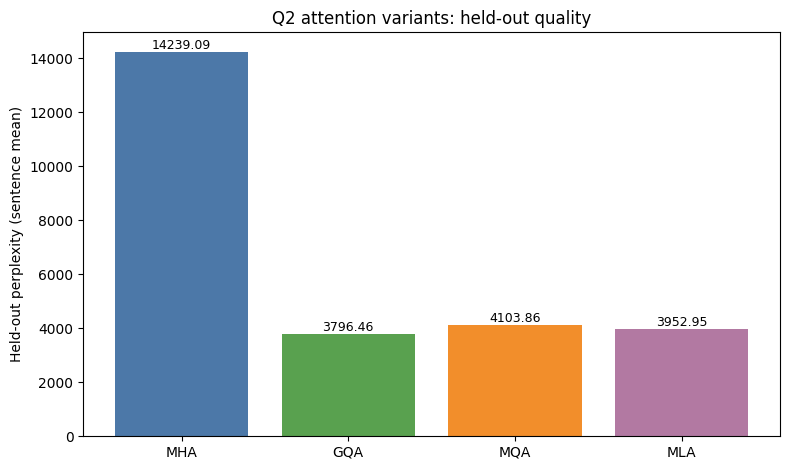

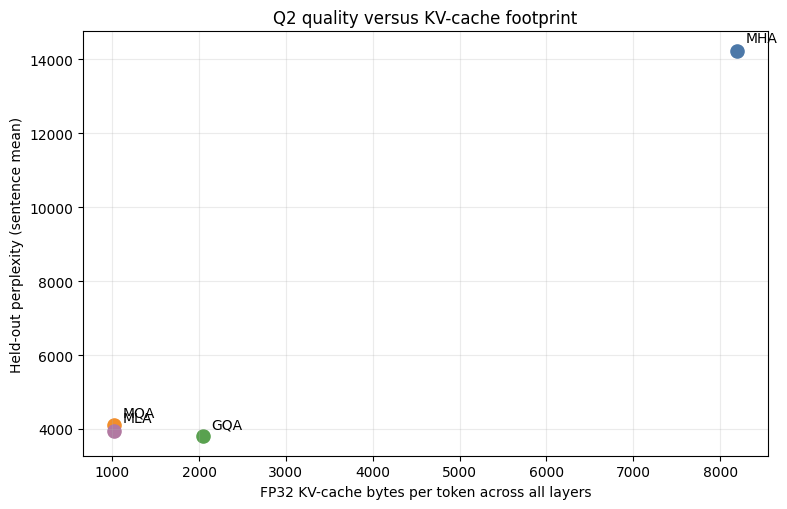

[logged] q2_quality_cache_tradeoff
GQA has the lowest measured held-out PPL (3796.4648); MQA, MLA use the smallest measured cache (1024 bytes/token).


In [23]:
# Q2.4: measured quality and cache trade-off plots.
plot_dir = q2.root / "plots"
plot_dir.mkdir(parents=True, exist_ok=True)
labels = [row["attention_type"].upper() for row in q2_results]
ppls = [row["held_out_ppl"] for row in q2_results]
caches = [row["kv_cache_bytes_per_token"] for row in q2_results]
colors = ["#4C78A8", "#59A14F", "#F28E2B", "#B279A2"]

fig, ax = plt.subplots(figsize=(8, 4.8))
bars = ax.bar(labels, ppls, color=colors)
ax.set_ylabel("Held-out perplexity (sentence mean)")
ax.set_title("Q2 attention variants: held-out quality")
if max(ppls) / max(min(ppls), 1e-12) > 20:
    ax.set_yscale("log")
for bar, value in zip(bars, ppls):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height(), f"{value:.2f}",
            ha="center", va="bottom", fontsize=9)
fig.tight_layout()
quality_plot = plot_dir / "q2_quality_by_variant.png"
fig.savefig(quality_plot, dpi=180, bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(8, 5.2))
for label, cache, ppl, color in zip(labels, caches, ppls, colors):
    ax.scatter(cache, ppl, s=90, color=color)
    ax.annotate(label, (cache, ppl), xytext=(6, 6), textcoords="offset points")
ax.set_xlabel("FP32 KV-cache bytes per token across all layers")
ax.set_ylabel("Held-out perplexity (sentence mean)")
ax.set_title("Q2 quality versus KV-cache footprint")
if max(ppls) / max(min(ppls), 1e-12) > 20:
    ax.set_yscale("log")
ax.grid(alpha=0.25)
fig.tight_layout()
cache_plot = plot_dir / "q2_quality_vs_cache.png"
fig.savefig(cache_plot, dpi=180, bbox_inches="tight")
plt.show()

best_quality = min(q2_results, key=lambda row: row["held_out_ppl"])
smallest_cache = min(row["kv_cache_bytes_per_token"] for row in q2_results)
small_cache_variants = [row["attention_type"] for row in q2_results
                        if row["kv_cache_bytes_per_token"] == smallest_cache]
q2_tradeoff = {
    "best_quality_variant": best_quality["attention_type"],
    "best_held_out_ppl": best_quality["held_out_ppl"],
    "smallest_cache_bytes_per_token": smallest_cache,
    "smallest_cache_variants": small_cache_variants,
    "measured_conclusion": (
        f"{best_quality['attention_type'].upper()} has the lowest measured held-out PPL "
        f"({best_quality['held_out_ppl']:.4f}); {', '.join(v.upper() for v in small_cache_variants)} "
        f"use the smallest measured cache ({smallest_cache} bytes/token)."
    ),
    "plots": [str(quality_plot), str(cache_plot)],
}
atomic_json(q2.root / "analysis" / "quality_cache_tradeoff.json", q2_tradeoff)
log_result("q2_quality_cache_tradeoff", q2_tradeoff)
print(q2_tradeoff["measured_conclusion"])


## 2.5 Parameter and KV-cache accounting [15 Marks]

Calculate the exact K/V projection parameters saved from MHA to MQA, both as an
absolute count and as a fraction of total MHA model parameters. Also compare MLA
against MHA using the same quantities, and report the corresponding cache reductions.

For bias-free projections, $D=d_{\mathrm{model}}$, $d_h=D/H$, and L layers:

| Quantity | MHA/GQA/MQA | MLA |
|---|---|---|
| `kv_projection_params` | $2D h_{kv}d_hL$ | $(Dr+rD+rD)L=3DrL$ |
| `kv_cache_bytes_per_token` (FP32) | $2h_{kv}d_hL\times4$ | $rL\times4$ |

MLA's count includes `kv_down_proj`, `k_up_proj`, and `v_up_proj` exactly once,
and excludes `q_proj` and `out_proj`, just as the other variants exclude Q/output.
Check calculated parameter counts against the actual weight tensors.
Parameter savings may be negative for some choices of r; do not assume MLA always
has fewer parameters or a smaller cache than every other variant.

Explain why inference cache savings and total training-parameter savings differ.


In [24]:
# Q2.5: verify formula counts against the actual trained tensors, then quantify savings.
q2_accounting_rows = q2.parameter_accounting()
q2_accounting_by_name = {row["variant"]: row for row in q2_accounting_rows}
mha_accounting = q2_accounting_by_name["mha"]

for row in q2_accounting_rows:
    assert row["actual_kv_projection_params"] == row["formula_kv_projection_params"]
    print(
        f"{row['variant'].upper():<4}: total={row['total_params']:,}; "
        f"KV actual=formula={row['actual_kv_projection_params']:,}; "
        f"cache={row['kv_cache_bytes_per_token']:,} B/token; "
        f"KV-parameter fraction vs MHA={row['kv_param_fraction_vs_mha']:.3f}; "
        f"cache fraction vs MHA={row['cache_fraction_vs_mha']:.3f}"
    )

q2_savings = {
    label: {
        "kv_parameter_reduction_vs_mha": 1.0 - q2_accounting_by_name[label]["kv_param_fraction_vs_mha"],
        "cache_reduction_vs_mha": 1.0 - q2_accounting_by_name[label]["cache_fraction_vs_mha"],
    }
    for label in ("mqa", "mla")
}
atomic_json(q2.root / "analysis" / "mqa_mla_savings.json", q2_savings)
log_result("q2_parameter_cache_accounting", {
    "rows": q2_accounting_rows, "mqa_mla_savings": q2_savings,
})


MHA : total=5,203,456; KV actual=formula=524,288; cache=8,192 B/token; KV-parameter fraction vs MHA=1.000; cache fraction vs MHA=1.000
GQA : total=4,810,240; KV actual=formula=131,072; cache=2,048 B/token; KV-parameter fraction vs MHA=0.250; cache fraction vs MHA=0.250
MQA : total=4,744,704; KV actual=formula=65,536; cache=1,024 B/token; KV-parameter fraction vs MHA=0.125; cache fraction vs MHA=0.125
MLA : total=4,875,776; KV actual=formula=196,608; cache=1,024 B/token; KV-parameter fraction vs MHA=0.375; cache fraction vs MHA=0.125
[logged] q2_parameter_cache_accounting


## 2.6 Dialogue × attention-type interaction [15 Marks]

Reuse the dialogue/narration split from Question 1 and compare the MQA-to-MHA perplexity change separately on the two subsets. Report the two gaps and state whether the observed data supports or contradicts the proposed idea that heavier key/value sharing may affect dialogue differently from narration.

Either outcome is acceptable; base the conclusion on the experiment.

Also report MLA-minus-MHA perplexity gaps on both subsets and compare the observed pattern with MQA.


In [25]:
# Q2.6: the exact Q1 dialogue rule is reused; all conclusions come from persisted results.
mha_row = q2_results_by_name["mha"]
q2_interaction = {
    "dialogue_rule": Q2_DIALOGUE_RULE,
    "subset_sizes": {
        "dialogue": len(q2_dialogue_sentences),
        "narration": len(q2_narration_sentences),
    },
    "mqa_minus_mha": {
        "dialogue_ppl_gap": q2_results_by_name["mqa"]["dialogue_ppl"] - mha_row["dialogue_ppl"],
        "narration_ppl_gap": q2_results_by_name["mqa"]["narration_ppl"] - mha_row["narration_ppl"],
    },
    "mla_minus_mha": {
        "dialogue_ppl_gap": q2_results_by_name["mla"]["dialogue_ppl"] - mha_row["dialogue_ppl"],
        "narration_ppl_gap": q2_results_by_name["mla"]["narration_ppl"] - mha_row["narration_ppl"],
    },
}
for label, key in (("MQA", "mqa_minus_mha"), ("MLA", "mla_minus_mha")):
    dialogue_gap = q2_interaction[key]["dialogue_ppl_gap"]
    narration_gap = q2_interaction[key]["narration_ppl_gap"]
    if dialogue_gap > narration_gap:
        interpretation = "the measured compression penalty is larger on dialogue"
    elif dialogue_gap < narration_gap:
        interpretation = "the measured compression penalty is larger on narration"
    else:
        interpretation = "the measured dialogue and narration penalties are equal"
    q2_interaction[key]["measured_conclusion"] = interpretation
    print(f"{label} - MHA: dialogue gap={dialogue_gap:.4f}, narration gap={narration_gap:.4f}; {interpretation}.")

atomic_json(q2.root / "analysis" / "dialogue_interaction.json", q2_interaction)
log_result("q2_dialogue_interaction", q2_interaction)


MQA - MHA: dialogue gap=-7673.1806, narration gap=-12597.2798; the measured compression penalty is larger on dialogue.
MLA - MHA: dialogue gap=-9707.6769, narration gap=-10864.6114; the measured compression penalty is larger on dialogue.
[logged] q2_dialogue_interaction


### Q2 model selection record for Question 3

Question 3 is allowed to select only among MHA, GQA, and MQA.  The record below applies
that rule to measured finite held-out perplexities and preserves the winning architecture,
checkpoint identity, source hashes, tokenizer identity, and split fingerprints.  MLA is
deliberately excluded even if it has the lowest Q2 perplexity.


In [26]:
q2_q3_selection = q2.select_for_q3()
print(json.dumps(q2_q3_selection, indent=2))
if q2_q3_selection["provisional_smoke_only"]:
    print("SMOKE label: this selection is provisional and is isolated from artifacts/full/q2.")
else:
    log_result("q2_selection_for_q3", q2_q3_selection)


{
  "provisional_smoke_only": false,
  "selection_rule": "lowest finite held_out_ppl among mha/gqa/mqa; mla excluded",
  "selected_label": "gqa",
  "held_out_ppl": 3796.4648224139487,
  "n_heads": 8,
  "n_kv_heads": 2,
  "architecture": {
    "vocab_size": 8000,
    "d_model": 256,
    "n_layers": 4,
    "n_heads": 8,
    "d_ff": 1024,
    "max_seq_len": 256,
    "dropout": 0.1,
    "pos_emb_type": "sinusoidal",
    "attention_scale": null,
    "norm_first": false,
    "attention_type": "standard",
    "n_kv_heads": 2,
    "kv_latent_dim": null
  },
  "final_state_path": "/kaggle/working/artifacts/full/q2/gqa/final.pt",
  "final_state_file_sha256": "1f501457124bc5cac59f0a1379f57215a4a4156eabc740b450b394d32a71726c",
  "source_hashes": {
    "a1_tokenizer.py": "100d2108ae86e3732531b4f3e2f2103e001393b199eb97d9b060ab9e062a4bcd",
    "attention.py": "46d8975e783f781c1072304355c4f835dbb4d50c5ae4631a4ddb2233cdff9ff4",
    "model_arch.py": "6aa95e657bd3bfdc64a2d227470cd7ac896d5542a8f49f3958b56

## 2.7 Reproducibility and submission artifacts [10 Marks]

Save exactly one result row for each of `mha`, `gqa`, `mqa`, and `mla`:

```python
metrics_q2 = {
    "per_config_results": [
        {"attention_type": "mha", "n_kv_heads": 8, "kv_latent_dim": None,
         "params": ..., "kv_projection_params": ..., "held_out_ppl": ...,
         "dialogue_ppl": ..., "narration_ppl": ..., "kv_cache_bytes_per_token": ...},
        {"attention_type": "gqa", "n_kv_heads": 2, "kv_latent_dim": None,
         "params": ..., "kv_projection_params": ..., "held_out_ppl": ...,
         "dialogue_ppl": ..., "narration_ppl": ..., "kv_cache_bytes_per_token": ...},
        {"attention_type": "mqa", "n_kv_heads": 1, "kv_latent_dim": None,
         "params": ..., "kv_projection_params": ..., "held_out_ppl": ...,
         "dialogue_ppl": ..., "narration_ppl": ..., "kv_cache_bytes_per_token": ...},
        {"attention_type": "mla", "n_kv_heads": None, "kv_latent_dim": ...,
         "params": ..., "kv_projection_params": ..., "held_out_ppl": ...,
         "dialogue_ppl": ..., "narration_ppl": ..., "kv_cache_bytes_per_token": ...},
    ],
}
```

Replace `...` with your results. Python `None` is JSON `null` when saved.

**Checkpoint and source snapshots**

Continue saving the **GQA model with `n_heads=8`, `n_kv_heads=2`, and
`attention_type="standard"` in LMConfig** as `submissions/q2/model.pt`, with its
matching configuration. All four result rows are required, but separate checkpoints
for MHA, MQA, and MLA are not required. The Q2 `attention.py` snapshot must contain
both `CausalSelfAttention` and `MultiHeadLatentAttention`; the grader independently
constructs and checks MLA even though the saved checkpoint is GQA.

Run `save_submission(...)` before Q3 overwrites the modules, and call
`log_result("q2_results", results_q2)`. Loss curves and derived comparisons may also
be saved but are not required by the evidence schema above.

**Carry-forward rule:** for Q3, select the lowest finite held-out PPL **only among
MHA, GQA, and MQA**. MLA participates in Q2's comparison but is excluded from Q3,
Q4, and Q5, even if it achieves the lowest Q2 PPL overall.


In [27]:
# Q2.7: the official primary checkpoint is GQA (H=8, H_kv=2), independent of Q3's winner.
if Q2_SMOKE_TEST:
    raise RuntimeError(
        "Refusing to create an official submission from smoke metrics. Set Q2_SMOKE_TEST=False, "
        "restore/train all four full experiments, and rerun the Q2 analysis cells first."
    )

q2.require_all_complete()
official_rows = q2.results()
if [row["attention_type"] for row in official_rows] != ["mha", "gqa", "mqa", "mla"]:
    raise AssertionError("Q2 official evidence must contain exactly MHA/GQA/MQA/MLA in order")
metrics_q2_official = {"per_config_results": official_rows}
gqa_model = q2.load_final_model("gqa", device="cpu").eval()
gqa_config = q2.architecture("gqa")
assert gqa_config["n_heads"] == 8 and gqa_config["n_kv_heads"] == 2
assert gqa_config["attention_type"] == "standard"
assert gqa_config["pos_emb_type"] == "sinusoidal"

save_submission("submissions/q2", gqa_model, gqa_config, metrics_q2_official, VOCAB_SIZE)
submission_dir = Path("submissions/q2")

# save_submission copies active source files. Pin Q2 to its immutable snapshots and remove
# opportunistic later-question modules from this submission only (never from the workspace).
for _name in ("a1_tokenizer.py", "attention.py", "model_arch.py"):
    _snapshot = q2.root / "source_snapshots" / _name
    _target = submission_dir / _name
    shutil.copy2(_snapshot, _target)
    if _q2_sha256(_target) != _q2_sha256(_snapshot):
        raise RuntimeError(f"Q2 submission source-copy verification failed: {_name}")
for _stale in ("rope.py", "optim_muon.py", "model_builtin.py"):
    (submission_dir / _stale).unlink(missing_ok=True)

saved_config = json.loads((submission_dir / "config.json").read_text(encoding="utf-8"))
saved_metrics = json.loads((submission_dir / "metrics.json").read_text(encoding="utf-8"))
if saved_config["n_heads"] != 8 or saved_config["n_kv_heads"] != 2:
    raise AssertionError("Official Q2 config is not the required GQA checkpoint")
if saved_metrics != metrics_q2_official:
    raise AssertionError("Official Q2 metrics differ from the validated four-run evidence")
try:
    saved_state = torch.load(submission_dir / "model.pt", map_location="cpu", weights_only=True)
except TypeError:
    saved_state = torch.load(submission_dir / "model.pt", map_location="cpu")
if not isinstance(saved_state, dict) or not all(torch.is_tensor(value) for value in saved_state.values()):
    raise AssertionError("Official model.pt must be a plain state dictionary")

log_result("q2_submission", {
    "primary_variant": "gqa", "config": saved_config,
    "metrics": saved_metrics,
    "model_sha256": _q2_sha256(submission_dir / "model.pt"),
})
q2.export_recovery_zip(force=True)
print("Prepared official Q2 GQA submission with all four measured evidence rows.")


Saved submission artifacts to submissions/q2/ (model.pt, config.json, metrics.json; sources: a1_tokenizer.py, attention.py, model_arch.py)
[logged] q2_submission
Validated Q2 recovery ZIP: q2_all_artifacts.zip (56a75d009b26..., 783.7 MiB)
Prepared official Q2 GQA submission with all four measured evidence rows.


### Q2 final validation and recovery export

Run this only after both **full** GPU pairs, Q2.3–Q2.6 analysis, Q3 selection, and the
official submission cell.  It runs the supplied Q2 autograder unchanged, saves its actual
output, and then creates one more validated recovery archive while preserving the previous
valid archive.


In [28]:
if Q2_SMOKE_TEST:
    raise RuntimeError("Final official validation requires Q2_SMOKE_TEST=False and full-run artifacts.")

q2.require_all_complete()
required_analysis = [
    q2.root / "analysis" / "per_config_results.json",
    q2.root / "analysis" / "quality_cache_tradeoff.json",
    q2.root / "analysis" / "parameter_accounting.json",
    q2.root / "analysis" / "dialogue_interaction.json",
    q2.root / "analysis" / "q3_selection.json",
    q2.root / "plots" / "q2_quality_by_variant.png",
    q2.root / "plots" / "q2_quality_vs_cache.png",
]
missing = [str(path) for path in required_analysis if not path.is_file()]
if missing:
    raise FileNotFoundError("Run all Q2 analysis/selection cells first; missing: " + str(missing))
required_submission = [Path("submissions/q2") / name for name in
                       ("attention.py", "model_arch.py", "model.pt", "config.json", "metrics.json")]
missing = [str(path) for path in required_submission if not path.is_file()]
if missing:
    raise FileNotFoundError("Run the Q2 submission cell first; missing: " + str(missing))

q2_autograder_report = q2.run_official_autograder(student_dir=".")
q2_archive_path = q2.export_recovery_zip(force=True)
q2_archive_manifest = q2._validate_archive(q2_archive_path)
print("Official autograder exit code:", q2_autograder_report["returncode"])
print("Final validated archive:", q2_archive_path.resolve())
print("Archived files:", len(q2_archive_manifest["files"]))
print("Q2 complete; Q1 was not rerun and Q3–Q5 remain untouched.")


  [PASS] attention.py present
  [PASS] attention.py: no forbidden implementation
  [PASS] model_arch.py: no forbidden implementation
  [PASS] CausalSelfAttention.__init__ accepts n_kv_heads — params: ['self', 'd_model', 'n_heads', 'n_kv_heads', 'max_seq_len', 'dropout', 'attention_scale']
  [PASS] MQA (n_kv_heads=1) has strictly fewer K/V parameters than MHA — MHA K/V params=8192, MQA K/V params=1024
  [PASS] GQA (n_heads=8, n_kv_heads=2) forward pass produces correct shape — got (2, 10, 64)
  [PASS] Q2 attention numerics, n_kv_heads=8 — reference matched at sequence lengths 1, 7 and 16
  [PASS] Q2 attention numerics, n_kv_heads=2 — reference matched at sequence lengths 1, 7 and 16
  [PASS] Q2 attention numerics, n_kv_heads=1 — reference matched at sequence lengths 1, 7 and 16
  [PASS] Q2 MLA reference, latent_dim=5 — MLA outputs/gradients match reference; causal; lengths 1/7/16 and scale override checked
  [PASS] Q2 MLA reference, latent_dim=16 — MLA outputs/gradients match reference;

# Question 3 — Rotary Positional Embeddings From Scratch [180 Marks]

Self-attention by itself does not know the order or positions of tokens. Rotary Positional Embeddings (RoPE) introduce positional information by applying a position-dependent rotation to the query and key vectors inside every attention layer.

Unlike sinusoidal positional encoding, RoPE does not add a positional vector to the token representation. Instead, it rotates pairs of channels in the query and key vectors. Because the attention score is computed using the dot product between the rotated queries and keys, it naturally depends on their relative positional displacement.


RoPE has several useful properties:

1. It introduces relative-position information directly into the attention scores.
2. It does not require learned positional-embedding parameters.
3. Each operation is a rotation, so it preserves the norm of the query and key vectors.
4. It can sometimes generalize more gracefully to sequence lengths beyond those encountered during training, although this must be verified experimentally.
5. It can be implemented efficiently by precomputing and caching the required sine and cosine values.


Consider a token at position $p$. Let the dimension of each attention head be an even number $d_h$.
### 1. Pairing Scheme
| Aspect | Split-half pairing | Adjacent pairing |
|---|---|---|
| Rule | Pair each dimension in the first half with the corresponding dimension in the second half. | Pair consecutive dimensions. |
| General pair | $(x_i, x_{i+d_h/2})$ | $(x_{2i}, x_{2i+1})$ |
| Pair index | $i=0,\ldots,d_h/2-1$ | $i=0,\ldots,d_h/2-1$ |
| Example for $d_h=8$ | $(x_0,x_4), (x_1,x_5), (x_2,x_6), (x_3,x_7)$ | $(x_0,x_1), (x_2,x_3), (x_4,x_5), (x_6,x_7)$ |

Both schemes use the same rotation mathematics but pair dimensions differently. Use the split-half pairing scheme for both queries and keys.

### 2. Transform each pair

Each pair is treated as a two-dimensional vector and rotated using a position-dependent angle:

$$\phi_{p,i}=p\theta_i, \qquad \theta_i=10000^{-2i/d_h}.$$

Here, $p$ is the token position, while $\theta_i$ gives each dimension pair a different rotation frequency.

For the query pair $(q_{p,i},q_{p,i+d_h/2})$, the rotation is:

$$\begin{bmatrix}\widetilde q_{p,i}\\\widetilde q_{p,i+d_h/2}\end{bmatrix}=\begin{bmatrix}\cos\phi_{p,i}&-\sin\phi_{p,i}\\\sin\phi_{p,i}&\cos\phi_{p,i}\end{bmatrix}\begin{bmatrix}q_{p,i}\\q_{p,i+d_h/2}\end{bmatrix}.$$

The same transformation is independently applied to every pair.


### 3. Obtain the query and key vectors

For the hidden representation $x_p$ of the token at position $p$, the query, key, and value vectors are produced using learned projections:

$$q_p=x_pW_Q, \qquad k_p=x_pW_K, \qquad v_p=x_pW_V.$$

In multi-head attention, these projected vectors are reshaped into individual attention heads. RoPE is then applied separately within each query and key head.

### 4. Apply RoPE to queries and keys

The query and key at position $p$ are rotated using the angles corresponding to that position:

$$\widetilde q_p=\operatorname{RoPE}(q_p,p), \qquad \widetilde k_p=\operatorname{RoPE}(k_p,p).$$

This operation is performed for every query and key vector at every sequence position. The value vectors are not rotated:

$$\widetilde v_p=v_p.$$

Therefore, RoPE changes the vectors used to calculate attention weights but does not change the information carried by the values.

### 5. Compute attention using the rotated vectors

The attention score between the query at position $p$ and the key at position $t$ is:

$$s_{p,t}=\frac{\widetilde q_p^\top\widetilde k_t}{\sqrt{d_h}}.$$
Because the vectors are rotated according to their respective positions, their dot product depends on the relative displacement $t-p$:

$$(R_pq_p)^\top(R_tk_t)=q_p^\top R_{t-p}k_t.$$

Thus, the interaction between two tokens contains information about their relative distance, rather than depending only on their absolute positions.

After adding the causal mask $M_{p,t}$, the attention weights are:

$$\alpha_{p,t}=\operatorname{softmax}_t\left(s_{p,t}+M_{p,t}\right).$$

Finally, the attention weights are applied to the unchanged value vectors:

$$o_p=\sum_t\alpha_{p,t}v_t.$$
**Attention scope:** select Q2's best MHA/GQA/MQA result only. MLA is excluded from Q3 and all later questions. The Q3 module rewrites intentionally retain only MHA/GQA/MQA.


### Q3 fresh-session restoration and source preservation

Run this cell first in a fresh Kaggle kernel. It validates the full Q1 and Q2 recovery
archives, restores the tokenizer and measured Q2 selection, and checks the immutable
Q1/Q2 source snapshots and official submissions before the Q3 `%%writefile` cells
replace active root modules. It does not start Q1 or Q2 training.

Queue the Q3 cells in displayed order once. They run isolated smoke checks first,
then the full dual-GPU pair, analyses, submission, autograder, and ZIP export.


In [1]:
# --------------------------- Q3 session controls ---------------------------
Q3_SMOKE_TEST = False  # one-pass Q3 run: preflight + isolated smoke pair + full pair
Q3_PROJECT_ROOT = None  # optional writable project directory
Q3_SUPPORT_ROOT = None  # optional directory holding course support files
Q3_Q1_ARCHIVE = None  # optional exact q1_all_artifacts.zip
Q3_Q2_ARCHIVE = None  # optional exact q2_all_artifacts.zip
Q3_RECOVERY_ARCHIVE = None  # optional exact q3_all_artifacts.zip

import hashlib, importlib, importlib.util, json, math, os, shutil, subprocess, sys, tempfile, uuid, zipfile
from array import array
from pathlib import Path


def q3_sha256(path, chunk_size=1024 * 1024):
    digest = hashlib.sha256()
    with open(path, "rb") as handle:
        for chunk in iter(lambda: handle.read(chunk_size), b""):
            digest.update(chunk)
    return digest.hexdigest()


def q3_json_hash(value):
    payload = json.dumps(value, sort_keys=True, separators=(",", ":"), ensure_ascii=False)
    return hashlib.sha256(payload.encode("utf-8")).hexdigest()


def q3_hash_ints(values, chunk_items=100_000):
    digest = hashlib.sha256()
    for start in range(0, len(values), chunk_items):
        digest.update(array("q", (int(x) for x in values[start:start + chunk_items])).tobytes())
    return digest.hexdigest()


def q3_hash_texts(texts):
    digest = hashlib.sha256()
    for text in texts:
        payload = str(text).encode("utf-8")
        digest.update(len(payload).to_bytes(8, "little"))
        digest.update(payload)
    return digest.hexdigest()


def q3_safe_path(root, relative):
    root = Path(root).resolve()
    path = (root / relative).resolve()
    if path != root and root not in path.parents:
        raise ValueError(f"Unsafe archive path: {relative}")
    return path


def q3_atomic_json(path, value):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    candidate = path.with_name(path.name + "." + uuid.uuid4().hex + ".tmp")
    candidate.write_text(json.dumps(value, indent=2, ensure_ascii=False), encoding="utf-8")
    json.loads(candidate.read_text(encoding="utf-8"))
    os.replace(candidate, path)


def q3_support_root():
    if Q3_SUPPORT_ROOT:
        candidate = Path(Q3_SUPPORT_ROOT).expanduser().resolve()
        if not all((candidate / name).is_file() for name in
                   ("common.py", "common_grading.py", "download_data.py", "autograder_q3.py")):
            raise FileNotFoundError(f"Incomplete Q3_SUPPORT_ROOT: {candidate}")
        return candidate
    candidates = []
    cwd = Path.cwd().resolve()
    for candidate in (cwd, cwd / "cs781-a3-support-files", Path("/kaggle/working/assignment_3")):
        if all((candidate / name).is_file() for name in
               ("common.py", "common_grading.py", "download_data.py", "autograder_q3.py")):
            candidates.append(candidate.resolve())
    kaggle_input = Path("/kaggle/input")
    if kaggle_input.is_dir():
        candidates.extend(path.parent.resolve() for path in kaggle_input.rglob("autograder_q3.py")
                          if all((path.parent / name).is_file() for name in
                                 ("common.py", "common_grading.py", "download_data.py")))
    candidates = list(dict.fromkeys(candidates))
    if not candidates:
        raise FileNotFoundError("Attach the Assignment 3 support files before Q3 bootstrap")
    signatures = {
        tuple(q3_sha256(candidate / name) for name in
              ("common.py", "common_grading.py", "download_data.py", "autograder_q3.py"))
        for candidate in candidates
    }
    if len(signatures) != 1:
        raise RuntimeError(f"Conflicting course support packages: {candidates}")
    return cwd if cwd in candidates else candidates[0]


_q3_original_cwd = Path.cwd().resolve()
_q3_support = q3_support_root()
if Q3_PROJECT_ROOT:
    _q3_project = Path(Q3_PROJECT_ROOT).expanduser().resolve()
elif str(_q3_original_cwd).startswith("/kaggle/input/") or (
    str(_q3_support).startswith("/kaggle/input/") and Path("/kaggle/working").is_dir()
):
    _q3_project = Path("/kaggle/working/assignment_3").resolve()
else:
    _q3_project = _q3_original_cwd
_q3_project.mkdir(parents=True, exist_ok=True)
for _source in _q3_support.iterdir():
    if not _source.is_file() or _source.name == "a1_tokenizer.py":
        continue
    _dest = _q3_project / _source.name
    if _dest.is_file() and q3_sha256(_dest) != q3_sha256(_source):
        raise RuntimeError(f"Conflicting course support file: {_dest}")
    if not _dest.exists():
        shutil.copy2(_source, _dest)
os.chdir(_q3_project)
sys.path.insert(0, str(_q3_project))


def q3_validate_archive(path, expected_mode):
    path = Path(path).resolve()
    with zipfile.ZipFile(path) as archive:
        names = archive.namelist()
        if "recovery/integrity_manifest.json" not in names:
            raise ValueError(f"No recovery integrity manifest: {path}")
        manifest = json.loads(archive.read("recovery/integrity_manifest.json"))
        if manifest.get("mode") != expected_mode:
            raise ValueError(f"Expected {expected_mode} archive, got {manifest.get('mode')}: {path}")
        file_records = manifest.get("files")
        if not isinstance(file_records, dict) or not file_records:
            raise ValueError(f"Empty archive manifest: {path}")
        if set(file_records) - set(names):
            raise ValueError(f"Manifest references missing members: {path}")
        for relative, info in file_records.items():
            if q3_safe_path(Path.cwd(), relative) == Path.cwd().resolve():
                raise ValueError(f"Invalid archive member path: {relative}")
            digest, size = hashlib.sha256(), 0
            with archive.open(relative) as handle:
                for chunk in iter(lambda: handle.read(1024 * 1024), b""):
                    size += len(chunk)
                    digest.update(chunk)
            if size != int(info["size"]) or digest.hexdigest() != info["sha256"]:
                raise ValueError(f"Archive member checksum failed: {relative}")
    return manifest


def q3_find_archive(filename, explicit, mode):
    if explicit:
        path = Path(explicit).expanduser().resolve()
        if not path.is_file():
            raise FileNotFoundError(path)
        return path, q3_validate_archive(path, mode)
    roots = list(dict.fromkeys((_q3_project, _q3_original_cwd, _q3_support,
                                Path("/kaggle/working"), Path("/kaggle/input"))))
    for candidate_name in (filename, filename.replace(".zip", ".previous.zip")):
        valid = {}
        for root in roots:
            if not root.is_dir():
                continue
            for path in root.rglob(candidate_name):
                if not path.is_file():
                    continue
                try:
                    manifest = q3_validate_archive(path, mode)
                    signature = q3_json_hash({"files": manifest["files"], "mode": manifest["mode"]})
                    valid.setdefault(signature, (path.resolve(), manifest))
                except Exception as exc:
                    print(f"Ignoring invalid {candidate_name}: {path} ({exc})")
        if len(valid) > 1:
            raise RuntimeError(f"Conflicting {candidate_name} archives; set its explicit Q3 path")
        if valid:
            if candidate_name != filename:
                print(f"Using validated previous-known-good archive for {filename}")
            return next(iter(valid.values()))
    return None, None


def q3_restore_selected(path, manifest, prefixes, label, allow_local_newer=False):
    """Restore missing files atomically; never overwrite an existing different file."""
    if path is None:
        return
    file_records = manifest["files"]
    selected = [rel for rel in file_records if any(
        rel == prefix or rel.startswith(prefix.rstrip("/") + "/") for prefix in prefixes
    ) and "__pycache__" not in rel]
    conflicts = []
    for rel in selected:
        target = q3_safe_path(Path.cwd(), rel)
        if target.is_file() and q3_sha256(target) != file_records[rel]["sha256"]:
            conflicts.append(rel)
    if conflicts and not allow_local_newer:
        raise RuntimeError(f"{label} local/archive conflict; no files restored: {conflicts[:20]}")
    if conflicts:
        print(f"{label}: keeping {len(conflicts)} differing local files; later validation is required")
    count = 0
    with zipfile.ZipFile(path) as archive:
        for rel in selected:
            target = q3_safe_path(Path.cwd(), rel)
            if target.exists():
                continue
            target.parent.mkdir(parents=True, exist_ok=True)
            staged = target.with_name(target.name + "." + uuid.uuid4().hex + ".restore")
            with archive.open(rel) as source, open(staged, "wb") as sink:
                shutil.copyfileobj(source, sink, length=1024 * 1024)
            if staged.stat().st_size != file_records[rel]["size"] or q3_sha256(staged) != file_records[rel]["sha256"]:
                staged.unlink(missing_ok=True)
                raise ValueError(f"Restored member checksum failed: {rel}")
            os.replace(staged, target)
            count += 1
    print(f"{label}: restored {count} missing files from {path}")


_q3_mode = "smoke" if Q3_SMOKE_TEST else "full"
_q1_path, _q1_manifest = q3_find_archive("q1_all_artifacts.zip", Q3_Q1_ARCHIVE, "full")
_q2_path, _q2_manifest = q3_find_archive("q2_all_artifacts.zip", Q3_Q2_ARCHIVE, "full")
_q3_name = "q3_smoke_all_artifacts.zip" if Q3_SMOKE_TEST else "q3_all_artifacts.zip"
_q3_path, _q3_manifest = q3_find_archive(_q3_name, Q3_RECOVERY_ARCHIVE, _q3_mode)

_q1_required = [Path(name) for name in (
    "artifacts/shared/tokenizer/a1_bpe_tokenizer.json",
    "artifacts/shared/tokenizer/tokenizer_metadata.json",
    "artifacts/shared/tokenizer/train_ids.pt",
    "artifacts/shared/tokenizer/train_ids_metadata.json",
    "artifacts/full/q1/standard/config.json",
    "artifacts/full/q1/source_snapshots/a1_tokenizer.py",
    "artifacts/full/q1/source_snapshots/attention.py",
    "artifacts/full/q1/source_snapshots/model_arch.py",
    "submissions/q1/attention.py", "submissions/q1/model_arch.py",
)]
if _q1_path:
    q3_restore_selected(_q1_path, _q1_manifest, (
        "artifacts/shared/tokenizer", "artifacts/full/q1/source_snapshots",
        "artifacts/full/q1/standard/config.json", "submissions/q1",
    ), "Q1 dependencies")
if not all(path.is_file() for path in _q1_required):
    raise FileNotFoundError("Q3 requires a completed full Q1 archive or its exact restored dependencies")

_q2_required = [Path(name) for name in (
    "artifacts/full/q2/analysis/q3_selection.json",
    "artifacts/full/q2/source_snapshots/a1_tokenizer.py",
    "artifacts/full/q2/source_snapshots/attention.py",
    "artifacts/full/q2/source_snapshots/model_arch.py",
    "submissions/q2/metrics.json", "submissions/q2/attention.py",
    "submissions/q2/model_arch.py", "submissions/q2/model.pt",
)]
if _q2_path:
    q3_restore_selected(_q2_path, _q2_manifest, (
        "artifacts/full/q2/analysis/q3_selection.json",
        "artifacts/full/q2/source_snapshots", "submissions/q2",
    ), "Q2 selection and source dependencies")
if not all(path.is_file() for path in _q2_required):
    raise FileNotFoundError("Q3 requires the completed full Q2 archive or its exact restored dependencies")

if _q3_path:
    prefixes = [f"artifacts/{_q3_mode}/q3"]
    if not Q3_SMOKE_TEST:
        prefixes.append("submissions/q3")
    q3_restore_selected(_q3_path, _q3_manifest, prefixes, "Q3 recovery", allow_local_newer=True)

# Corpus remains a separate Kaggle input; download only if its seven books are absent.
if importlib.util.find_spec("huggingface_hub") is None:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "huggingface_hub"], check=True)
raw_dir = Path("data/raw")
if len(list(raw_dir.glob("book*.txt"))) != 7:
    if not os.environ.get("HF_TOKEN"):
        try:
            from kaggle_secrets import UserSecretsClient
            os.environ["HF_TOKEN"] = UserSecretsClient().get_secret("HF_TOKEN")
        except Exception:
            pass
    if not os.environ.get("HF_TOKEN"):
        raise RuntimeError("Missing corpus: attach data/raw/book1.txt ... book7.txt or set HF_TOKEN in Kaggle Secrets")
    subprocess.run([sys.executable, "download_data.py", "--raw-dir", str(raw_dir)], check=True)

import torch
import matplotlib.pyplot as plt
from common import (load_corpus, held_out_sentences, remove_sentences_from_text,
                    BPETokenizerWrapper, TokenDataset, perplexity_of_texts,
                    save_submission, count_parameters, MAX_PARAMS)

_q1_config = json.loads(Path("artifacts/full/q1/standard/config.json").read_text(encoding="utf-8"))
for _name in ("a1_tokenizer.py", "attention.py", "model_arch.py"):
    _snapshot = Path("artifacts/full/q1/source_snapshots") / _name
    if q3_sha256(_snapshot) != _q1_config["source_hashes"][_name]:
        raise RuntimeError(f"Q1 source snapshot integrity failed: {_snapshot}")
    if q3_sha256(Path("submissions/q1") / _name) != q3_sha256(_snapshot):
        raise RuntimeError(f"Q1 official submission source differs from its immutable snapshot: {_name}")

_q2_selection = json.loads(Path("artifacts/full/q2/analysis/q3_selection.json").read_text(encoding="utf-8"))
_q2_metrics = json.loads(Path("submissions/q2/metrics.json").read_text(encoding="utf-8"))
_q2_rows = _q2_metrics["per_config_results"]
if len(_q2_rows) != 4 or sorted(row["attention_type"] for row in _q2_rows) != ["gqa", "mha", "mla", "mqa"]:
    raise RuntimeError("Q2 evidence must contain exactly one result for each of MHA/GQA/MQA/MLA")
_q2_eligible = [row for row in _q2_rows if row["attention_type"] in ("mha", "gqa", "mqa")]
if not all(math.isfinite(float(row["held_out_ppl"])) and float(row["held_out_ppl"]) >= 1 for row in _q2_eligible):
    raise RuntimeError("Q2 eligible held-out perplexities are incomplete")
_q2_winner = min(_q2_eligible, key=lambda row: (row["held_out_ppl"], row["attention_type"]))
if _q2_selection.get("provisional_smoke_only") or _q2_selection.get("selected_label") != _q2_winner["attention_type"]:
    raise RuntimeError("Q2 selection is provisional or disagrees with the measured full-run rows")
if _q2_selection.get("selected_label") == "mla":
    raise RuntimeError("MLA is not eligible for Question 3")
if _q2_selection.get("held_out_ppl") != _q2_winner["held_out_ppl"]:
    raise RuntimeError("Q2 selection perplexity differs from its source row")
if (_q2_selection.get("n_heads") != _q2_selection.get("architecture", {}).get("n_heads") or
    _q2_selection.get("n_kv_heads") != _q2_winner["n_kv_heads"] or
    _q2_selection.get("n_kv_heads") != _q2_selection.get("architecture", {}).get("n_kv_heads")):
    raise RuntimeError("Q2 selected attention-head metadata is inconsistent")
if _q2_selection.get("architecture", {}).get("attention_type") != "standard":
    raise RuntimeError("Q3 requires standard MHA/GQA/MQA attention")
_q2_winner_final = Path("artifacts/full/q2") / _q2_selection["selected_label"] / "final.pt"
if _q2_path:
    q3_restore_selected(_q2_path, _q2_manifest, (str(_q2_winner_final).replace("\\", "/"),),
                        "Q2 selected-final evidence")
if not _q2_winner_final.is_file() or q3_sha256(_q2_winner_final) != _q2_selection["final_state_file_sha256"]:
    raise RuntimeError("Q2 selected final checkpoint is missing or disagrees with full-run evidence")
for _name in ("a1_tokenizer.py", "attention.py", "model_arch.py"):
    _snapshot = Path("artifacts/full/q2/source_snapshots") / _name
    if q3_sha256(_snapshot) != _q2_selection["source_hashes"][_name]:
        raise RuntimeError(f"Q2 source snapshot integrity failed: {_snapshot}")
    if q3_sha256(Path("submissions/q2") / _name) != q3_sha256(_snapshot):
        raise RuntimeError(f"Q2 official submission source differs from its immutable snapshot: {_name}")

# Activate only the validated A1 tokenizer adapter. Q3 source-generation cells replace
# active attention.py/model_arch.py after these checks; saved Q1/Q2 copies stay intact.
_a1_source = Path("artifacts/full/q1/source_snapshots/a1_tokenizer.py")
_a1_active = Path("a1_tokenizer.py")
if not _a1_active.is_file() or q3_sha256(_a1_active) != q3_sha256(_a1_source):
    _candidate = Path("a1_tokenizer.py.q3restore")
    shutil.copy2(_a1_source, _candidate)
    os.replace(_candidate, _a1_active)
_a1_spec = importlib.util.spec_from_file_location("_q3_a1_tokenizer", _a1_active)
_a1_module = importlib.util.module_from_spec(_a1_spec)
_a1_spec.loader.exec_module(_a1_module)
_tokenizer_root = Path("artifacts/shared/tokenizer")
_tok_meta = json.loads((_tokenizer_root / "tokenizer_metadata.json").read_text(encoding="utf-8"))
_ids_meta = json.loads((_tokenizer_root / "train_ids_metadata.json").read_text(encoding="utf-8"))
_tok_path = _tokenizer_root / "a1_bpe_tokenizer.json"
if q3_sha256(_tok_path) != _tok_meta["model_sha256"] or int(_tok_meta["requested_vocab_size"]) != 8000:
    raise RuntimeError("Q1 tokenizer model/fingerprint or vocabulary target is incompatible")
tokenizer = BPETokenizerWrapper(
    a1_tokenizer=_a1_module.Assignment1ByteLevelBPE.load(_tok_path), vocab_size=8000
)
VOCAB_SIZE = int(tokenizer.vocab_size)
if VOCAB_SIZE != 8000:
    raise RuntimeError(f"Q3 requires the completed Q1 vocabulary, got {VOCAB_SIZE}")
try:
    _train_tensor = torch.load(_tokenizer_root / "train_ids.pt", map_location="cpu", weights_only=True)
except TypeError:
    _train_tensor = torch.load(_tokenizer_root / "train_ids.pt", map_location="cpu")
train_ids = [int(value) for value in _train_tensor.tolist()]
if len(train_ids) != int(_ids_meta["token_count"]) or q3_hash_ints(train_ids) != _q1_config["train_ids_hash"]:
    raise RuntimeError("Persisted Q1 train-token sequence does not match Q1 evidence")
if _ids_meta["tokenizer_fingerprint"] != _tok_meta["model_sha256"]:
    raise RuntimeError("Train tokens were produced by a different tokenizer")

corpus = load_corpus("data/raw")
held_out = held_out_sentences(corpus, n_chapters=5, sentences_per_chapter=6)
train_text = remove_sentences_from_text(corpus.raw_text, held_out)
if hashlib.sha256(train_text.encode("utf-8")).hexdigest() != _tok_meta["training_corpus_sha256"]:
    raise RuntimeError("Q3 corpus/split differs from the Q1 tokenizer training corpus")
if q3_hash_texts(held_out) != _q1_config["held_out_hash"]:
    raise RuntimeError("Q3 held-out split differs from the completed Q1/Q2 split")
if _q2_selection["tokenizer_fingerprint"] != _tok_meta["model_sha256"]:
    raise RuntimeError("Q2 selection tokenizer fingerprint differs from Q1")
if _q2_selection["train_ids_hash"] != _q1_config["train_ids_hash"] or _q2_selection["held_out_hash"] != _q1_config["held_out_hash"]:
    raise RuntimeError("Q2 selection dataset/split fingerprints differ from Q1")

Q3_SELECTION = _q2_selection
Q3_SELECTED_LABEL = _q2_selection["selected_label"]
Q3_SELECTED_CONFIG = dict(_q2_selection["architecture"])
Q3_TOKENIZER_FINGERPRINT = _tok_meta["model_sha256"]
Q3_TRAIN_IDS_HASH = _q1_config["train_ids_hash"]
Q3_HELD_OUT_HASH = _q1_config["held_out_hash"]
Q3_CORPUS_HASH = _tok_meta["training_corpus_sha256"]
Q3_DEPENDENCIES = {
    "q1_archive_sha256": q3_sha256(_q1_path) if _q1_path else None,
    "q2_archive_sha256": q3_sha256(_q2_path) if _q2_path else None,
    "q1_trajectory_hash": _q1_config["trajectory_hash"],
    "q2_selection_sha256": q3_sha256("artifacts/full/q2/analysis/q3_selection.json"),
    "q2_selected_final_sha256": _q2_selection["final_state_file_sha256"],
    "tokenizer_fingerprint": Q3_TOKENIZER_FINGERPRINT,
    "train_ids_hash": Q3_TRAIN_IDS_HASH,
    "held_out_hash": Q3_HELD_OUT_HASH,
    "training_corpus_sha256": Q3_CORPUS_HASH,
}

def log_result(key, value):
    path = Path("analysis_log.json")
    existing = json.loads(path.read_text(encoding="utf-8")) if path.is_file() else {}
    existing[key] = value
    q3_atomic_json(path, existing)
    print(f"[logged] {key}")

print("Q3 project:", Path.cwd())
print("Q2 carry-forward:", Q3_SELECTED_LABEL.upper(),
      f"H={Q3_SELECTED_CONFIG['n_heads']}, H_kv={Q3_SELECTED_CONFIG['n_kv_heads']}, "
      f"Q2 held-out PPL={_q2_winner['held_out_ppl']:.4f}")
print("Q3 mode:", "SMOKE" if Q3_SMOKE_TEST else "FULL",
      "| Q1/Q2 dependency source and split checks passed")


Q1 dependencies: restored 6 missing files from /kaggle/working/q1_all_artifacts.zip
Q2 selection and source dependencies: restored 0 missing files from /kaggle/working/q2_all_artifacts.zip
Q2 selected-final evidence: restored 0 missing files from /kaggle/working/q2_all_artifacts.zip
Q3 project: /kaggle/working
Q2 carry-forward: GQA H=8, H_kv=2, Q2 held-out PPL=3796.4648
Q3 mode: FULL | Q1/Q2 dependency source and split checks passed


In [2]:
# Explicit full-run Q2 carry-forward gate; this cell is cheap to rerun.
q3_eligible_rows = [row for row in _q2_rows if row["attention_type"] in ("mha", "gqa", "mqa")]
q3_measured_winner = min(q3_eligible_rows,
                         key=lambda row: (row["held_out_ppl"], row["attention_type"]))
assert Q3_SELECTED_LABEL == q3_measured_winner["attention_type"]
assert Q3_SELECTED_LABEL != "mla" and not Q3_SELECTION["provisional_smoke_only"]
assert Q3_SELECTED_CONFIG["n_heads"] == 8
assert Q3_SELECTED_CONFIG["n_kv_heads"] == q3_measured_winner["n_kv_heads"]
print("Validated Q3 architecture:", Q3_SELECTED_LABEL.upper(),
      "query heads", Q3_SELECTED_CONFIG["n_heads"],
      "KV heads", Q3_SELECTED_CONFIG["n_kv_heads"],
      "Q2 PPL", q3_measured_winner["held_out_ppl"])


Validated Q3 architecture: GQA query heads 8 KV heads 2 Q2 PPL 3796.4648224139487


### 3.1 Implementing Rotary Positional Embeddings (RoPE) [35 Marks]

Implement RoPE from scratch in `rope.py`. Precompute the position-dependent sine and cosine values, implement the rotation operation, and use these components to transform query and key vectors. Your implementation should apply the transformation independently across batches and attention heads while preserving the input tensor shape.

In [3]:
%%writefile rope.py
"""Split-half rotary positional embeddings for the manual Q3 attention layer."""
import torch


def build_rope_cache(max_seq_len: int, d_head: int, base: float = 10000.0):
    """Return cos/sin caches of shape (T, d_head) for split-half channel pairs."""
    if max_seq_len <= 0 or d_head <= 0 or d_head % 2:
        raise ValueError("max_seq_len must be positive and d_head must be positive and even")
    if base <= 1:
        raise ValueError("RoPE base must be greater than one")
    pair_index = torch.arange(d_head // 2, dtype=torch.float32)
    inverse_frequency = base ** (-2.0 * pair_index / d_head)
    positions = torch.arange(max_seq_len, dtype=torch.float32)
    frequencies = torch.outer(positions, inverse_frequency)
    angles = torch.cat((frequencies, frequencies), dim=-1)
    return angles.cos(), angles.sin()


def rotate_half(x: torch.Tensor) -> torch.Tensor:
    """Pair channel i with channel i+d_head/2, returning a 90-degree rotation."""
    if x.shape[-1] <= 0 or x.shape[-1] % 2:
        raise ValueError("RoPE requires a positive, even final dimension")
    first, second = x.chunk(2, dim=-1)
    return torch.cat((-second, first), dim=-1)


def apply_rope(x: torch.Tensor, cos: torch.Tensor, sin: torch.Tensor) -> torch.Tensor:
    """Rotate (batch, heads, sequence, head_dim) without changing its shape."""
    if x.ndim != 4:
        raise ValueError("RoPE input must have shape (batch, heads, sequence, head_dim)")
    expected = (x.shape[-2], x.shape[-1])
    if tuple(cos.shape) != expected or tuple(sin.shape) != expected:
        raise ValueError(f"RoPE cache must have shape {expected}")
    cos = cos.to(device=x.device, dtype=x.dtype).unsqueeze(0).unsqueeze(0)
    sin = sin.to(device=x.device, dtype=x.dtype).unsqueeze(0).unsqueeze(0)
    return x * cos + rotate_half(x) * sin


Writing rope.py


## 3.2 Attention/model integration [35 Marks]

Integrate RoPE into the attention and decoder architecture. When `pos_emb_type="rope"`, do not add the sinusoidal positional table to token embeddings; instead apply RoPE to $Q$ and $K$ inside every attention layer before computing attention scores.

Keep the rest of the architecture unchanged so that the positional representation is the only intended difference.


In [4]:
%%writefile attention.py
"""Manual MHA/GQA/MQA causal attention with optional split-half RoPE."""
import math
import torch
import torch.nn as nn
from rope import build_rope_cache, apply_rope


class CausalSelfAttention(nn.Module):
    def __init__(self, d_model, n_heads, n_kv_heads, max_seq_len,
                 dropout=0.0, use_rope=False, attention_scale=None):
        super().__init__()
        if d_model <= 0 or n_heads <= 0 or n_kv_heads <= 0:
            raise ValueError("Model/head widths must be positive")
        if d_model % n_heads or n_heads % n_kv_heads:
            raise ValueError("d_model must divide by n_heads, and n_heads by n_kv_heads")
        if max_seq_len <= 0:
            raise ValueError("max_seq_len must be positive")
        self.n_heads, self.n_kv_heads = int(n_heads), int(n_kv_heads)
        self.n_rep = self.n_heads // self.n_kv_heads
        self.d_head = d_model // self.n_heads
        self.use_rope = bool(use_rope)
        if self.use_rope and self.d_head % 2:
            raise ValueError("RoPE requires an even head dimension")
        self.attention_scale = (1.0 / math.sqrt(self.d_head)
                                if attention_scale is None else float(attention_scale))
        if not math.isfinite(self.attention_scale) or self.attention_scale <= 0:
            raise ValueError("attention_scale must be finite and positive")

        self.q_proj = nn.Linear(d_model, d_model, bias=False)
        self.k_proj = nn.Linear(d_model, self.n_kv_heads * self.d_head, bias=False)
        self.v_proj = nn.Linear(d_model, self.n_kv_heads * self.d_head, bias=False)
        self.out_proj = nn.Linear(d_model, d_model, bias=False)
        self.attn_dropout = nn.Dropout(dropout)
        self.resid_dropout = nn.Dropout(dropout)
        self.register_buffer("causal_mask", torch.tril(torch.ones(
            max_seq_len, max_seq_len, dtype=torch.bool)), persistent=False)
        if self.use_rope:
            cos, sin = build_rope_cache(max_seq_len, self.d_head)
            self.register_buffer("rope_cos", cos, persistent=False)
            self.register_buffer("rope_sin", sin, persistent=False)

    def forward(self, x):
        if x.ndim != 3:
            raise ValueError("Attention expects (batch, sequence, d_model)")
        batch, length, width = x.shape
        if length > self.causal_mask.shape[0]:
            raise ValueError("Sequence exceeds configured attention capacity")
        q = self.q_proj(x).view(batch, length, self.n_heads, self.d_head).transpose(1, 2)
        k = self.k_proj(x).view(batch, length, self.n_kv_heads, self.d_head).transpose(1, 2)
        v = self.v_proj(x).view(batch, length, self.n_kv_heads, self.d_head).transpose(1, 2)
        if self.use_rope:
            cos, sin = self.rope_cos[:length], self.rope_sin[:length]
            q = apply_rope(q, cos, sin)
            k = apply_rope(k, cos, sin)
        # Each KV head is shared by a contiguous group of query heads.
        if self.n_rep > 1:
            k = k.repeat_interleave(self.n_rep, dim=1)
            v = v.repeat_interleave(self.n_rep, dim=1)
        scores = (q @ k.transpose(-2, -1)) * self.attention_scale
        allowed = self.causal_mask[:length, :length].view(1, 1, length, length)
        weights = torch.softmax(scores.masked_fill(~allowed, float("-inf")), dim=-1)
        weights = self.attn_dropout(weights)
        output = weights @ v
        output = output.transpose(1, 2).contiguous().view(batch, length, width)
        return self.resid_dropout(self.out_proj(output))


Overwriting attention.py


In [5]:
%%writefile model_arch.py
"""Q3 decoder: Q2-selected standard attention, with sinusoidal or RoPE positions."""
import math
from dataclasses import dataclass
import torch
import torch.nn as nn
from attention import CausalSelfAttention


@dataclass
class LMConfig:
    vocab_size: int
    d_model: int = 256
    n_layers: int = 4
    n_heads: int = 4
    n_kv_heads: int = 4
    d_ff: int = 1024
    max_seq_len: int = 256
    dropout: float = 0.1
    pos_emb_type: str = "sinusoidal"
    attention_scale: float = None
    norm_first: bool = False
    attention_type: str = "standard"
    kv_latent_dim: int = None


def sinusoidal_positional_encoding(max_len: int, d_model: int) -> torch.Tensor:
    if max_len <= 0 or d_model <= 0:
        raise ValueError("Position capacity and model width must be positive")
    position = torch.arange(max_len, dtype=torch.float32).unsqueeze(1)
    even_indices = torch.arange(0, d_model, 2, dtype=torch.float32)
    frequencies = torch.exp(-math.log(10000.0) * even_indices / d_model)
    angles = position * frequencies.unsqueeze(0)
    encoding = torch.zeros(max_len, d_model, dtype=torch.float32)
    encoding[:, 0::2] = torch.sin(angles)
    if d_model > 1:
        encoding[:, 1::2] = torch.cos(angles[:, :encoding[:, 1::2].shape[1]])
    return encoding


class FeedForward(nn.Module):
    def __init__(self, d_model: int, d_ff: int, dropout: float):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(d_model, d_ff), nn.GELU(), nn.Dropout(dropout),
                                 nn.Linear(d_ff, d_model), nn.Dropout(dropout))

    def forward(self, x):
        return self.net(x)


class Block(nn.Module):
    def __init__(self, cfg: LMConfig):
        super().__init__()
        self.norm_first = bool(cfg.norm_first)
        self.ln1 = nn.LayerNorm(cfg.d_model)
        self.attn = CausalSelfAttention(
            cfg.d_model, cfg.n_heads, cfg.n_kv_heads, cfg.max_seq_len,
            cfg.dropout, use_rope=(cfg.pos_emb_type == "rope"),
            attention_scale=cfg.attention_scale,
        )
        self.ln2 = nn.LayerNorm(cfg.d_model)
        self.ffn = FeedForward(cfg.d_model, cfg.d_ff, cfg.dropout)

    def forward(self, x):
        if self.norm_first:
            x = x + self.attn(self.ln1(x))
            return x + self.ffn(self.ln2(x))
        x = self.ln1(x + self.attn(x))
        return self.ln2(x + self.ffn(x))


class DecoderLM(nn.Module):
    def __init__(self, cfg: LMConfig):
        super().__init__()
        if cfg.attention_type != "standard" or cfg.kv_latent_dim is not None:
            raise ValueError("Q3 carries forward only standard MHA/GQA/MQA attention")
        if cfg.pos_emb_type not in ("sinusoidal", "rope"):
            raise ValueError("pos_emb_type must be sinusoidal or rope")
        if cfg.vocab_size <= 0 or cfg.n_layers <= 0:
            raise ValueError("vocab_size and n_layers must be positive")
        self.cfg = cfg
        self.tok_emb = nn.Embedding(cfg.vocab_size, cfg.d_model)
        if cfg.pos_emb_type == "sinusoidal":
            self.register_buffer("pos_emb",
                                 sinusoidal_positional_encoding(cfg.max_seq_len, cfg.d_model),
                                 persistent=False)
        self.blocks = nn.ModuleList([Block(cfg) for _ in range(cfg.n_layers)])
        self.ln_f = nn.LayerNorm(cfg.d_model)
        self.head = nn.Linear(cfg.d_model, cfg.vocab_size, bias=False)
        self.head.weight = self.tok_emb.weight

    def forward(self, idx: torch.Tensor) -> torch.Tensor:
        if idx.ndim != 2:
            raise ValueError("Decoder input must have shape (batch, sequence)")
        length = idx.shape[1]
        if length > self.cfg.max_seq_len:
            raise ValueError("Input length exceeds configured positional capacity")
        x = self.tok_emb(idx)
        if self.cfg.pos_emb_type == "sinusoidal":
            x = x + self.pos_emb[:length].to(dtype=x.dtype).unsqueeze(0)
        for block in self.blocks:
            x = block(x)
        return self.head(self.ln_f(x))


Overwriting model_arch.py


In [6]:
# Reload the complete Q3 source chain after the three %%writefile cells.
import importlib, sys
for _name in ("model_arch", "attention", "rope"):
    sys.modules.pop(_name, None)
rope = importlib.import_module("rope")
attention = importlib.import_module("attention")
model_arch = importlib.import_module("model_arch")
build_rope_cache, rotate_half, apply_rope = (
    rope.build_rope_cache, rope.rotate_half, rope.apply_rope
)
CausalSelfAttention = attention.CausalSelfAttention
LMConfig, DecoderLM = model_arch.LMConfig, model_arch.DecoderLM
print("Q3 modules:", rope.__file__, attention.__file__, model_arch.__file__)


Q3 modules: /kaggle/working/rope.py /kaggle/working/attention.py /kaggle/working/model_arch.py


## 3.3 Relative-position invariance sanity check [20 Marks]

Before training, verify the relative-position property numerically using fixed query/key vectors. Compare the rotated dot products for two position pairs with the same displacement, for example $(m,n)=(5,2)$ and $(105,102)$.

RoPE satisfies the structural relation

$$\langle R_m q, R_n k\rangle=\langle q, R_{\,n-m}k\rangle,
$$

so the result should depend on the relative offset rather than the absolute positions, up to floating-point error. Report the numerical discrepancy produced by the check.


In [7]:
# Q3.3: use the actual split-half cache/application, not a symbolic shortcut.
import torch
q3_cos, q3_sin = build_rope_cache(max_seq_len=300, d_head=16)
assert q3_cos.shape == q3_sin.shape == (300, 16)
try:
    build_rope_cache(8, 3)
    raise AssertionError("Odd RoPE head dimension was accepted")
except ValueError:
    pass
torch.testing.assert_close(rotate_half(torch.tensor([1., 2., 3., 4.])),
                           torch.tensor([-3., -4., 1., 2.]))
pair_probe = torch.tensor([[[[1., 2., 3., 4.]]]])
pair_cos, pair_sin = build_rope_cache(6, 4)
rotated_probe = apply_rope(pair_probe, pair_cos[1:2], pair_sin[1:2])
assert rotated_probe.shape == pair_probe.shape
torch.testing.assert_close(apply_rope(pair_probe, pair_cos[:1], pair_sin[:1]), pair_probe)
torch.testing.assert_close(rotated_probe.norm(dim=-1), pair_probe.norm(dim=-1), atol=1e-6, rtol=1e-6)
assert not torch.allclose(rotated_probe, pair_probe)
q3_query = torch.tensor([[[[0.3, -0.7, 1.1, 0.2, -0.5, 0.9, 0.4, -1.2,
                           0.8, -0.1, 0.6, -0.9, 1.4, 0.5, -0.3, 0.7]]]], dtype=torch.float64)
q3_key = torch.tensor([[[[-0.6, 0.4, 0.8, -1.0, 0.3, -0.2, 1.2, 0.5,
                         0.1, -0.8, 0.7, 0.9, -0.4, 1.1, -0.5, 0.2]]]], dtype=torch.float64)

def q3_rotated_dot(m, n):
    q_rot = apply_rope(q3_query, q3_cos[m:m+1], q3_sin[m:m+1])
    k_rot = apply_rope(q3_key, q3_cos[n:n+1], q3_sin[n:n+1])
    return float((q_rot * k_rot).sum().item())

q3_close_dot = q3_rotated_dot(5, 2)
q3_far_dot = q3_rotated_dot(105, 102)
q3_relative_discrepancy = abs(q3_close_dot - q3_far_dot)
# n-m=-3. The inverse of R_3 is R_-3, obtained by negating the sine cache.
q3_relative_key = apply_rope(q3_key, q3_cos[3:4], -q3_sin[3:4])
q3_relation_dot = float((q3_query * q3_relative_key).sum().item())
q3_relation_discrepancy = abs(q3_close_dot - q3_relation_dot)
assert q3_relative_discrepancy < 1e-3, q3_relative_discrepancy
assert q3_relation_discrepancy < 1e-3, q3_relation_discrepancy
assert abs(q3_close_dot - q3_rotated_dot(45, 2)) > 1e-2  # no-op rotations cannot pass
q3_relative_evidence = {
    "dot_5_2": q3_close_dot, "dot_105_102": q3_far_dot,
    "same_displacement_abs_difference": q3_relative_discrepancy,
    "relative_identity_abs_difference": q3_relation_discrepancy,
}
print(q3_relative_evidence)


{'dot_5_2': 0.6299481761390613, 'dot_105_102': 0.62994679879586, 'same_displacement_abs_difference': 1.3773432012698095e-06, 'relative_identity_abs_difference': 2.3576923524615268e-08}


### Q3 matched experiment runtime and recovery

Both models use the measured Q2 attention architecture. The training windows have 64
tokens, while both models allocate 128 positional slots. The runtime keeps independent
sinusoidal and RoPE states and assigns the pair to `cuda:0` and `cuda:1`.
The next preflight cell also runs a separate three-step smoke pair automatically;
the following cell then starts or resumes the full pair without a mode switch.


In [10]:
%%writefile q3_runtime.py
"""Q3 matched sinusoidal/RoPE training, validation, and crash recovery."""
from __future__ import annotations

import hashlib
import json
import math
import os
import shutil
import statistics
import subprocess
import sys
import threading
import time
import traceback
import uuid
import zipfile
from concurrent.futures import ThreadPoolExecutor, as_completed
from datetime import datetime, timezone
from pathlib import Path

import torch
import torch.nn.functional as F
from torch.utils.data import DataLoader, Sampler
from tqdm.auto import tqdm

from common import TokenDataset
from model_arch import DecoderLM, LMConfig

SCHEMA = 1
SCHEMES = ("sinusoidal", "rope")


def now_utc():
    return datetime.now(timezone.utc).isoformat()


def file_sha256(path):
    digest = hashlib.sha256()
    with open(path, "rb") as handle:
        for chunk in iter(lambda: handle.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()


def stable_hash(value):
    encoded = json.dumps(value, sort_keys=True, separators=(",", ":"), ensure_ascii=False)
    return hashlib.sha256(encoded.encode("utf-8")).hexdigest()


def weights_hash(state):
    digest = hashlib.sha256()
    for name in sorted(state):
        tensor = state[name].detach().cpu().contiguous()
        digest.update(name.encode("utf-8"))
        digest.update(str(tensor.dtype).encode("ascii"))
        digest.update(json.dumps(list(tensor.shape)).encode("ascii"))
        digest.update(tensor.numpy().tobytes())
    return digest.hexdigest()


def cpu_weights(model):
    return {name: value.detach().cpu().clone() for name, value in model.state_dict().items()}


def load_torch(path):
    try:
        return torch.load(path, map_location="cpu", weights_only=False)
    except TypeError:
        return torch.load(path, map_location="cpu")


def atomic_json(path, value):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    staged = path.with_name(path.name + "." + uuid.uuid4().hex + ".tmp")
    staged.write_text(json.dumps(value, indent=2, ensure_ascii=False), encoding="utf-8")
    json.loads(staged.read_text(encoding="utf-8"))
    os.replace(staged, path)


def file_sidecar(path):
    path = Path(path)
    return path.with_name(path.name + ".sha256.json")


def verify_file(path):
    path = Path(path)
    sidecar = file_sidecar(path)
    if not (path.is_file() and sidecar.is_file()):
        return False
    try:
        record = json.loads(sidecar.read_text(encoding="utf-8"))
        return record["size"] == path.stat().st_size and record["sha256"] == file_sha256(path)
    except Exception:
        return False


def atomic_torch(path, value):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    staged = path.with_name(path.name + "." + uuid.uuid4().hex + ".tmp")
    torch.save(value, staged)
    load_torch(staged)
    digest = file_sha256(staged)
    os.replace(staged, path)
    atomic_json(file_sidecar(path), {"sha256": digest, "size": path.stat().st_size,
                                    "updated_utc": now_utc()})
    return digest


class StepBatchSampler(Sampler):
    """Deterministic shuffled TokenDataset batches addressed by global optimization step."""
    def __init__(self, dataset_size, batch_size, seed, start_step, target_step):
        self.dataset_size = int(dataset_size)
        self.batch_size = int(batch_size)
        self.seed = int(seed)
        self.start_step = int(start_step)
        self.target_step = int(target_step)
        self.batches_per_epoch = self.dataset_size // self.batch_size
        if self.batches_per_epoch < 1:
            raise ValueError("At least one full TokenDataset batch is required")

    def __len__(self):
        return max(0, self.target_step - self.start_step)

    def __iter__(self):
        cached_epoch, permutation = None, None
        for step in range(self.start_step, self.target_step):
            epoch, cursor = divmod(step, self.batches_per_epoch)
            if epoch != cached_epoch:
                rng = torch.Generator(device="cpu").manual_seed(self.seed + epoch)
                permutation = torch.randperm(self.dataset_size, generator=rng)
                cached_epoch = epoch
            start = cursor * self.batch_size
            yield permutation[start:start + self.batch_size].tolist()

    def state(self, completed_step):
        epoch, cursor = divmod(int(completed_step), self.batches_per_epoch)
        return {"scheme": "epoch_randperm_seed_plus_epoch_v1", "seed": self.seed,
                "dataset_size": self.dataset_size, "batch_size": self.batch_size,
                "batches_per_epoch": self.batches_per_epoch,
                "completed_step": int(completed_step), "epoch": epoch, "batch_cursor": cursor}


class Q3Runtime:
    def __init__(self, *, smoke, selected_architecture, selected_label, selection_evidence,
                 dependencies, train_ids, held_token_rows, steps, batch_size, learning_rate,
                 seed, checkpoint_steps=50, checkpoint_seconds=300, archive_seconds=600,
                 root_override=None, archive_override=None):
        self.smoke = bool(smoke)
        self.mode = "smoke" if self.smoke else "full"
        self.root = Path(root_override) if root_override else Path("artifacts") / self.mode / "q3"
        self.archive = Path(archive_override) if archive_override else Path(
            "q3_smoke_all_artifacts.zip" if self.smoke else "q3_all_artifacts.zip")
        self.selected_architecture = dict(selected_architecture)
        self.selected_label = str(selected_label)
        self.selection_evidence = json.loads(json.dumps(selection_evidence))
        self.dependencies = json.loads(json.dumps(dependencies))
        self.semantic_dependencies = {key: value for key, value in self.dependencies.items()
                                      if key not in ("q1_archive_sha256", "q2_archive_sha256")}
        self.train_ids = [int(value) for value in train_ids]
        self.held_token_rows = [[int(token) for token in row] for row in held_token_rows]
        self.train_seq_len = 64
        self.model_seq_len = 128
        self.steps = int(steps)
        self.batch_size = int(batch_size)
        self.lr = float(learning_rate)
        self.seed = int(seed)
        self.checkpoint_steps = int(checkpoint_steps)
        self.checkpoint_seconds = float(checkpoint_seconds)
        self.archive_seconds = float(archive_seconds)
        self.io_lock = threading.RLock()
        self.build_lock = threading.Lock()
        self.stop = threading.Event()
        self.last_archive_time = 0.0
        self.source_hashes = {}
        self.initial_hash = None
        self.dataset_size = len(TokenDataset(self.train_ids, self.train_seq_len))
        if self.dataset_size < self.batch_size:
            raise ValueError("Q3 training corpus is too short for the batch size")
        if self.selected_label not in ("mha", "gqa", "mqa"):
            raise ValueError("Q3 selected architecture must be MHA, GQA, or MQA")
        if self.selected_architecture.get("attention_type") != "standard":
            raise ValueError("Q3 requires standard attention")

    def model_config(self, scheme):
        if scheme not in SCHEMES:
            raise KeyError(scheme)
        cfg = dict(self.selected_architecture)
        cfg.update(pos_emb_type=scheme, max_seq_len=self.model_seq_len)
        return cfg

    def model_dir(self, scheme):
        return self.root / scheme

    def experiment_id(self, scheme):
        return f"q3-{self.mode}-{self.selected_label}-{scheme}"

    def build_model(self, scheme):
        # Model construction is serialized before workers and isolated from the CPU RNG.
        with self.build_lock, torch.random.fork_rng(devices=[]):
            torch.manual_seed(self.seed)
            return DecoderLM(LMConfig(**self.model_config(scheme))).cpu()

    def initial_state(self, scheme):
        return load_torch(self.model_dir(scheme) / "initial.pt")

    def contract(self):
        return {
            "steps": self.steps, "batch_size": self.batch_size,
            "training_window": self.train_seq_len, "model_capacity": self.model_seq_len,
            "optimizer": {"name": "Adam", "lr": self.lr}, "seed": self.seed,
            "sampler": "epoch_randperm_seed_plus_epoch_v1", "smoke": self.smoke,
            "tokenizer_fingerprint": self.semantic_dependencies["tokenizer_fingerprint"],
            "train_ids_hash": self.semantic_dependencies["train_ids_hash"],
            "held_out_hash": self.semantic_dependencies["held_out_hash"],
        }

    def spec(self, scheme):
        return {"schema": SCHEMA, "experiment_id": self.experiment_id(scheme),
                "selected_label": self.selected_label,
                "model_config": self.model_config(scheme), "contract": self.contract(),
                "initial_state_hash": self.initial_hash,
                "source_hashes": self.source_hashes,
                "dependencies": self.semantic_dependencies,
                "selection_sha256": self.semantic_dependencies["q2_selection_sha256"]}

    def fingerprint(self, scheme):
        return stable_hash(self.spec(scheme))

    def configure(self):
        for sub in ("sinusoidal", "rope", "analysis", "plots", "source_snapshots",
                    "manifests", "recovery"):
            (self.root / sub).mkdir(parents=True, exist_ok=True)
        for name in ("a1_tokenizer.py", "rope.py", "attention.py", "model_arch.py", "q3_runtime.py"):
            active = Path(name)
            if not active.is_file():
                raise FileNotFoundError(f"Q3 source is missing: {active}")
            digest = file_sha256(active)
            self.source_hashes[name] = digest
            snapshot = self.root / "source_snapshots" / name
            if snapshot.exists() and file_sha256(snapshot) != digest:
                raise RuntimeError(f"Immutable Q3 source differs from active version: {snapshot}")
            if not snapshot.exists():
                shutil.copy2(active, snapshot)

        selection_path = self.root / "manifests" / "q2_selection.json"
        if selection_path.is_file():
            prior = json.loads(selection_path.read_text(encoding="utf-8"))
            if prior != self.selection_evidence:
                raise RuntimeError("Existing Q3 run selected a different Q2 architecture")
        else:
            atomic_json(selection_path, self.selection_evidence)
        dependency_path = self.root / "manifests" / "dependencies.json"
        if dependency_path.is_file():
            previous = json.loads(dependency_path.read_text(encoding="utf-8"))
            if {k: v for k, v in previous.items() if k not in
                ("q1_archive_sha256", "q2_archive_sha256")} != self.semantic_dependencies:
                raise RuntimeError("Existing Q3 run has incompatible Q1/Q2 dependencies")
        else:
            atomic_json(dependency_path, self.dependencies)

        first_path = self.model_dir("sinusoidal") / "initial.pt"
        if first_path.exists():
            if not verify_file(first_path):
                raise RuntimeError("Saved Q3 initial weights failed checksum validation")
            state = load_torch(first_path)
        else:
            state = cpu_weights(self.build_model("sinusoidal"))
            atomic_torch(first_path, state)
        self.initial_hash = weights_hash(state)
        for scheme in SCHEMES:
            model = self.build_model(scheme)
            model.load_state_dict(state, strict=True)
            if sum(p.numel() for p in model.parameters()) > 50_000_000:
                raise RuntimeError(f"Q3 {scheme} exceeds the 50M parameter ceiling")
            initial_path = self.model_dir(scheme) / "initial.pt"
            if initial_path.exists():
                if not verify_file(initial_path) or weights_hash(load_torch(initial_path)) != self.initial_hash:
                    raise RuntimeError(f"Q3 {scheme} initial state diverges from matched seed")
            else:
                atomic_torch(initial_path, state)
            spec_path = self.model_dir(scheme) / "config.json"
            expected = self.spec(scheme)
            expected["fingerprint"] = self.fingerprint(scheme)
            if spec_path.is_file():
                if json.loads(spec_path.read_text(encoding="utf-8")) != expected:
                    raise RuntimeError(f"Existing Q3 {scheme} config is incompatible")
            else:
                atomic_json(spec_path, expected)
        return self.status()

    def _sampler(self, start, stop):
        return StepBatchSampler(self.dataset_size, self.batch_size, self.seed, start, stop)

    def checkpoint_paths(self, scheme):
        root = self.model_dir(scheme)
        return root / "checkpoint.latest.pt", root / "checkpoint.previous.pt"

    def validate_payload(self, scheme, payload):
        if not isinstance(payload, dict) or payload.get("schema") != SCHEMA:
            raise ValueError("Q3 checkpoint schema mismatch")
        if payload.get("experiment_id") != self.experiment_id(scheme) or payload.get("fingerprint") != self.fingerprint(scheme):
            raise ValueError("Q3 checkpoint belongs to a different experiment/configuration")
        step = payload.get("completed_step")
        if type(step) is not int or not 0 <= step <= self.steps:
            raise ValueError("Q3 checkpoint has an invalid step")
        history = payload.get("history")
        if not isinstance(history, list) or len(history) != step:
            raise ValueError("Q3 checkpoint loss history is discontinuous")
        if [row.get("step") for row in history] != list(range(1, step + 1)):
            raise ValueError("Q3 checkpoint has duplicate/skipped history steps")
        if payload.get("tokens_processed") != step * self.batch_size * self.train_seq_len:
            raise ValueError("Q3 checkpoint token count is inconsistent")
        if payload.get("sampler_state") != self._sampler(step, step).state(step):
            raise ValueError("Q3 checkpoint sampler cursor is inconsistent")
        state = payload.get("model_state")
        if not isinstance(state, dict) or weights_hash(state) != payload.get("model_state_hash"):
            raise ValueError("Q3 checkpoint model tensor digest mismatch")
        model = self.build_model(scheme)
        model.load_state_dict(state, strict=True)
        optimizer = torch.optim.Adam(model.parameters(), lr=self.lr)
        optimizer.load_state_dict(payload["optimizer_state"])
        for key in ("cpu_rng_state", "device_rng_state"):
            value = payload.get(key)
            if not torch.is_tensor(value) or value.dtype != torch.uint8 or value.ndim != 1:
                raise ValueError(f"Q3 checkpoint has invalid {key}")
        evaluation = payload.get("eval_history")
        if not isinstance(evaluation, list) or any(
            type(row.get("step")) is not int or not 1 <= row["step"] <= step for row in evaluation
        ):
            raise ValueError("Q3 checkpoint evaluation history is invalid")
        if [row["step"] for row in evaluation] != sorted(set(row["step"] for row in evaluation)):
            raise ValueError("Q3 checkpoint evaluation steps are duplicated")
        if payload.get("trajectory_hash") != stable_hash({"history": history, "eval_history": evaluation}):
            raise ValueError("Q3 checkpoint trajectory digest mismatch")
        elapsed = payload.get("cumulative_seconds")
        if type(elapsed) not in (int, float) or not math.isfinite(elapsed) or elapsed < 0:
            raise ValueError("Q3 checkpoint elapsed time is invalid")
        del optimizer, model
        return payload

    def load_checkpoint(self, scheme):
        errors = []
        for path in self.checkpoint_paths(scheme):
            if not path.exists():
                continue
            try:
                if not verify_file(path):
                    raise ValueError("file checksum mismatch")
                payload = self.validate_payload(scheme, load_torch(path))
                if path.name == "checkpoint.previous.pt":
                    print(f"[{scheme}] restored previous-known-good checkpoint")
                return payload
            except Exception as exc:
                errors.append(f"{path.name}: {exc}")
        if errors:
            raise RuntimeError(f"No valid Q3 {scheme} checkpoint: " + "; ".join(errors))
        return None

    def save_checkpoint(self, scheme, model, optimizer, scaler, *, step, history,
                        eval_history, cumulative_seconds, device, cpu_generator,
                        reason):
        state = cpu_weights(model)
        best = min(eval_history, key=lambda row: (row["held_out_ppl"], row["step"])) if eval_history else None
        best_file = self.model_dir(scheme) / "best.pt"
        best_info = None
        if best is not None:
            if not verify_file(best_file):
                raise RuntimeError(f"Q3 {scheme} best checkpoint is missing/corrupt")
            best_info = {"step": best["step"], "held_out_ppl": best["held_out_ppl"],
                         "file_sha256": file_sha256(best_file)}
        payload = {
            "schema": SCHEMA, "experiment_id": self.experiment_id(scheme),
            "fingerprint": self.fingerprint(scheme), "model_config": self.model_config(scheme),
            "training_contract": self.contract(), "completed_step": int(step),
            "sampler_state": self._sampler(step, step).state(step),
            "tokens_processed": int(step * self.batch_size * self.train_seq_len),
            "model_state": state, "model_state_hash": weights_hash(state),
            "optimizer_state": optimizer.state_dict(), "scheduler_state": None,
            "amp_scaler_state": scaler.state_dict() if scaler is not None else None,
            "cpu_rng_state": cpu_generator.get_state(),
            "device_rng_state": (torch.cuda.get_rng_state(device).cpu() if device.type == "cuda"
                                 else torch.get_rng_state().cpu()),
            "history": history, "eval_history": eval_history,
            "trajectory_hash": stable_hash({"history": history, "eval_history": eval_history}),
            "cumulative_seconds": float(cumulative_seconds),
            "best_checkpoint": best_info, "checkpoint_reason": reason,
            "assigned_device": str(device), "saved_utc": now_utc(),
        }
        latest, previous = self.checkpoint_paths(scheme)
        with self.io_lock:
            candidate = latest.with_name(latest.name + "." + uuid.uuid4().hex + ".candidate")
            torch.save(payload, candidate)
            self.validate_payload(scheme, load_torch(candidate))
            digest = file_sha256(candidate)
            if latest.is_file() and verify_file(latest):
                prior_candidate = previous.with_name(previous.name + "." + uuid.uuid4().hex + ".tmp")
                shutil.copy2(latest, prior_candidate)
                if file_sha256(prior_candidate) != file_sha256(latest):
                    raise IOError("Could not verify previous Q3 checkpoint copy")
                os.replace(prior_candidate, previous)
                atomic_json(file_sidecar(previous), {"sha256": file_sha256(previous),
                                                      "size": previous.stat().st_size,
                                                      "updated_utc": now_utc()})
            os.replace(candidate, latest)
            atomic_json(file_sidecar(latest), {"sha256": digest, "size": latest.stat().st_size,
                                                    "updated_utc": now_utc()})
            atomic_json(self.model_dir(scheme) / "status.json", {
                "status": "running", "completed_step": step,
                "experiment_id": self.experiment_id(scheme),
                "assigned_device": str(device), "latest_checkpoint_sha256": digest,
                "best_checkpoint": best_info, "updated_utc": now_utc(),
            })
        return step

    def _eval_tokens(self, model, device, max_len=128):
        was_training = model.training
        model.eval()
        values = []
        try:
            with torch.no_grad():
                for ids in self.held_token_rows:
                    if self.stop.is_set():
                        raise InterruptedError("Q3 training stop requested")
                    ids = ids[:min(max_len, self.model_seq_len + 1)]
                    if len(ids) < 2:
                        continue
                    x = torch.tensor(ids[:-1], dtype=torch.long, device=device).unsqueeze(0)
                    y = torch.tensor(ids[1:], dtype=torch.long, device=device).unsqueeze(0)
                    logits = model(x)
                    loss = F.cross_entropy(logits.reshape(-1, logits.size(-1)), y.reshape(-1))
                    value = math.exp(float(loss.item()))
                    if not math.isfinite(value):
                        raise FloatingPointError("Q3 held-out sentence perplexity is non-finite")
                    values.append(value)
        finally:
            model.train(was_training)
        if not values:
            raise ValueError("Q3 held-out set has no usable sentences")
        return float(sum(values) / len(values))

    def _scaler(self, cuda):
        try:
            return torch.amp.GradScaler("cuda", enabled=cuda)
        except (AttributeError, TypeError):
            return torch.cuda.amp.GradScaler(enabled=cuda)

    @staticmethod
    def _optimizer_to_device(optimizer, device):
        for state in optimizer.state.values():
            for name, value in list(state.items()):
                if torch.is_tensor(value):
                    state[name] = value.to(device)

    def _worker(self, scheme, device_name, position, model, prior):
        device = torch.device(device_name)
        model = model.to(device)
        optimizer = torch.optim.Adam(model.parameters(), lr=self.lr)
        scaler = self._scaler(device.type == "cuda")
        generator = torch.Generator(device="cpu").manual_seed(self.seed + 20_000)
        history, evaluations, step, cumulative_base = [], [], 0, 0.0
        resumed = prior is not None
        if prior:
            model.load_state_dict(prior["model_state"], strict=True)
            optimizer.load_state_dict(prior["optimizer_state"])
            self._optimizer_to_device(optimizer, device)
            if prior["amp_scaler_state"]:
                scaler.load_state_dict(prior["amp_scaler_state"])
            generator.set_state(prior["cpu_rng_state"])
            if device.type == "cuda":
                torch.cuda.set_rng_state(prior["device_rng_state"], device)
            else:
                torch.set_rng_state(prior["device_rng_state"])
            history, evaluations = list(prior["history"]), list(prior["eval_history"])
            step = int(prior["completed_step"])
            cumulative_base = float(prior["cumulative_seconds"])
        elif device.type == "cuda":
            torch.cuda.set_rng_state(torch.Generator(device=device).manual_seed(
                self.seed + 30_000).get_state(), device)
        else:
            torch.manual_seed(self.seed + 30_000)

        dataset = TokenDataset(self.train_ids, self.train_seq_len)
        sampler = self._sampler(step, self.steps)
        loader = DataLoader(dataset, batch_sampler=sampler, num_workers=0,
                            pin_memory=(device.type == "cuda"))
        milestones = {max(1, math.ceil(self.steps * fraction / 5)) for fraction in range(1, 6)}
        best = min((row["held_out_ppl"] for row in evaluations), default=float("inf"))
        last_checkpoint_step = step
        last_checkpoint_time = time.monotonic()
        started = time.monotonic()
        starting_step = step
        safe_boundary = True
        status_path = self.model_dir(scheme) / "status.json"
        with self.io_lock:
            atomic_json(status_path, {"status": "running", "completed_step": step,
                                      "assigned_device": str(device),
                                      "experiment_id": self.experiment_id(scheme),
                                      "resumed": resumed, "updated_utc": now_utc()})
        progress = tqdm(total=self.steps, initial=step, position=position, leave=True,
                        desc=f"Q3 {scheme} | {device}", dynamic_ncols=True)
        try:
            for x, y in loader:
                if self.stop.is_set():
                    raise InterruptedError("Q3 pair stop requested at a safe step boundary")
                x = x.to(device, non_blocking=True)
                y = y.to(device, non_blocking=True)
                optimizer.zero_grad(set_to_none=True)
                with torch.autocast(device_type=device.type, dtype=torch.float16,
                                    enabled=(device.type == "cuda")):
                    logits = model(x)
                    loss = F.cross_entropy(logits.reshape(-1, logits.size(-1)), y.reshape(-1))
                if not torch.isfinite(loss):
                    raise FloatingPointError(f"Non-finite Q3 loss at step {step + 1}")
                scaler.scale(loss).backward()
                safe_boundary = False
                scaler.step(optimizer)
                scaler.update()
                step += 1
                cumulative = cumulative_base + time.monotonic() - started
                history.append({"step": step, "epoch": sampler.state(step)["epoch"],
                                "loss": float(loss.item()), "learning_rate": self.lr,
                                "tokens_processed": step * self.batch_size * self.train_seq_len,
                                "elapsed_seconds": cumulative})
                safe_boundary = True
                with self.io_lock:
                    atomic_json(self.model_dir(scheme) / "history.json", {
                        "history": history, "eval_history": evaluations,
                        "completed_step": step, "cumulative_seconds": cumulative})
                evaluated = step in milestones and not any(row["step"] == step for row in evaluations)
                if evaluated:
                    ppl = self._eval_tokens(model, device, max_len=128)
                    evaluations.append({"step": step, "held_out_ppl": ppl,
                                        "tokens_processed": step * self.batch_size * self.train_seq_len,
                                        "elapsed_seconds": cumulative})
                    if ppl < best:
                        best = ppl
                        with self.io_lock:
                            atomic_torch(self.model_dir(scheme) / "best.pt", cpu_weights(model))
                due = (step == self.steps or evaluated or
                       step - last_checkpoint_step >= self.checkpoint_steps or
                       time.monotonic() - last_checkpoint_time >= self.checkpoint_seconds)
                if due:
                    last_checkpoint_step = self.save_checkpoint(
                        scheme, model, optimizer, scaler, step=step,
                        history=history, eval_history=evaluations,
                        cumulative_seconds=cumulative, device=device,
                        cpu_generator=generator, reason=("completion" if step == self.steps else
                                                          "evaluation" if evaluated else "interval"))
                    last_checkpoint_time = time.monotonic()
                    self.export_archive(force=False)
                elapsed = max(time.monotonic() - started, 1e-9)
                speed = (step - starting_step) / elapsed
                smoothed = statistics.mean(row["loss"] for row in history[-20:])
                progress.update(1)
                progress.set_postfix({"epoch": sampler.state(step)["epoch"],
                                      "loss": f"{smoothed:.3f}", "lr": f"{self.lr:.1e}",
                                      "tokens": step * self.batch_size * self.train_seq_len,
                                      "step/s": f"{speed:.2f}",
                                      "tok/s": f"{speed * self.batch_size * self.train_seq_len:.0f}",
                                      "session": f"{elapsed:.0f}s", "total": f"{cumulative:.0f}s",
                                      "eta": f"{(self.steps-step)/max(speed,1e-9):.0f}s",
                                      "ckpt": last_checkpoint_step,
                                      "state": "RESUMED" if resumed else "NEW"})

            final_ppl = self._eval_tokens(model, device, max_len=128)
            cumulative = cumulative_base + time.monotonic() - started
            with self.io_lock:
                final_path = self.model_dir(scheme) / "final.pt"
                atomic_torch(final_path, cpu_weights(model))
                best_path = self.model_dir(scheme) / "best.pt"
                if not best_path.exists():
                    atomic_torch(best_path, cpu_weights(model))
                if not verify_file(best_path):
                    raise RuntimeError(f"Q3 {scheme} best checkpoint failed final validation")
                metrics = {
                    "scheme": scheme, "held_out_ppl": final_ppl,
                    "loss_curve": [row["loss"] for row in history],
                    "history": history, "eval_history": evaluations,
                    "completed_steps": step,
                    "tokens_processed": step * self.batch_size * self.train_seq_len,
                    "cumulative_active_seconds": cumulative,
                    "initial_state_hash": self.initial_hash,
                    "final_state_hash": weights_hash(load_torch(final_path)),
                    "final_file_sha256": file_sha256(final_path),
                    "best_file_sha256": file_sha256(best_path),
                    "fingerprint": self.fingerprint(scheme),
                    "trajectory_hash": stable_hash({"history": history, "eval_history": evaluations}),
                }
                atomic_json(self.model_dir(scheme) / "metrics.json", metrics)
                atomic_json(status_path, {
                    "status": "complete", "experiment_id": self.experiment_id(scheme),
                    "completed_step": step, "assigned_device": str(device),
                    "held_out_ppl": final_ppl, "metrics_sha256": stable_hash(metrics),
                    "final_file_sha256": metrics["final_file_sha256"],
                    "updated_utc": now_utc(),
                })
            print(f"Q3 {scheme} completed on {device}; session={time.monotonic()-started:.1f}s, "
                  f"cumulative={cumulative:.1f}s, held-out PPL={final_ppl:.4f}")
            return metrics
        except BaseException as exc:
            emergency_error = None
            if safe_boundary:
                try:
                    self.save_checkpoint(
                        scheme, model, optimizer, scaler, step=step, history=history,
                        eval_history=evaluations,
                        cumulative_seconds=cumulative_base + time.monotonic() - started,
                        device=device, cpu_generator=generator, reason="emergency")
                except BaseException as problem:
                    emergency_error = f"{type(problem).__name__}: {problem}"
            else:
                emergency_error = "Mid-update state not saved; latest verified checkpoint retained"
            with self.io_lock:
                atomic_json(status_path, {
                    "status": "interrupted" if self.stop.is_set() or isinstance(exc, InterruptedError) else "failed",
                    "experiment_id": self.experiment_id(scheme),
                    "completed_step": step, "assigned_device": str(device),
                    "error": f"{type(exc).__name__}: {exc}",
                    "emergency_checkpoint_error": emergency_error,
                    "traceback": traceback.format_exc(), "updated_utc": now_utc(),
                })
            raise
        finally:
            progress.close()
            del model
            if device.type == "cuda":
                torch.cuda.empty_cache()

    def complete(self, scheme):
        path = self.model_dir(scheme)
        required = [path / name for name in ("final.pt", "best.pt", "metrics.json", "status.json")]
        if not all(item.is_file() for item in required):
            return False
        try:
            metrics = json.loads((path / "metrics.json").read_text(encoding="utf-8"))
            status = json.loads((path / "status.json").read_text(encoding="utf-8"))
            if status.get("status") != "complete" or status.get("completed_step") != self.steps:
                return False
            if metrics.get("scheme") != scheme or metrics.get("fingerprint") != self.fingerprint(scheme):
                return False
            if metrics.get("completed_steps") != self.steps or len(metrics.get("history", [])) != self.steps:
                return False
            if [row["step"] for row in metrics["history"]] != list(range(1, self.steps + 1)):
                return False
            if metrics.get("loss_curve") != [row["loss"] for row in metrics["history"]]:
                return False
            if metrics.get("tokens_processed") != self.steps * self.batch_size * self.train_seq_len:
                return False
            if metrics.get("trajectory_hash") != stable_hash({
                "history": metrics["history"], "eval_history": metrics["eval_history"]}):
                return False
            if not (verify_file(path / "final.pt") and verify_file(path / "best.pt")):
                return False
            if file_sha256(path / "final.pt") != metrics["final_file_sha256"]:
                return False
            if file_sha256(path / "best.pt") != metrics["best_file_sha256"]:
                return False
            state = load_torch(path / "final.pt")
            if weights_hash(state) != metrics["final_state_hash"]:
                return False
            model = self.build_model(scheme)
            model.load_state_dict(state, strict=True)
            if status["metrics_sha256"] != stable_hash(metrics):
                return False
            ppl = metrics["held_out_ppl"]
            return type(ppl) in (int, float) and math.isfinite(ppl) and ppl >= 1
        except Exception:
            return False

    def result(self, scheme):
        if not self.complete(scheme):
            raise RuntimeError(f"Q3 {scheme} is not complete and validated")
        return json.loads((self.model_dir(scheme) / "metrics.json").read_text(encoding="utf-8"))

    def status(self):
        report = {}
        for scheme in SCHEMES:
            if self.complete(scheme):
                report[scheme] = {"state": "complete", "step": self.steps,
                                  "ppl": self.result(scheme)["held_out_ppl"]}
            else:
                checkpoint = self.load_checkpoint(scheme)
                report[scheme] = {"state": "resumable" if checkpoint else "missing",
                                  "step": checkpoint["completed_step"] if checkpoint else 0}
        return report

    def require_complete(self):
        missing = [scheme for scheme in SCHEMES if not self.complete(scheme)]
        if missing:
            raise RuntimeError(f"Train/resume the Q3 matched pair first: {missing}")
        return {scheme: self.result(scheme) for scheme in SCHEMES}

    def load_final_model(self, scheme, device="cpu"):
        if not self.complete(scheme):
            raise RuntimeError(f"Q3 {scheme} final weights did not pass validation")
        model = self.build_model(scheme)
        model.load_state_dict(load_torch(self.model_dir(scheme) / "final.pt"), strict=True)
        return model.to(device).eval()

    def run_pair(self):
        self.stop.clear()
        pending = [scheme for scheme in SCHEMES if not self.complete(scheme)]
        if not pending:
            print("Both Q3 models are complete; validated saved states and skipped training")
            return self.require_complete()
        if not self.smoke and torch.cuda.device_count() < 2:
            raise RuntimeError("Full Q3 matched training requires Kaggle's two visible T4 GPUs")
        prepared = {}
        for position, scheme in enumerate(SCHEMES):
            if scheme in pending:
                prior = self.load_checkpoint(scheme)
                model = self.build_model(scheme)
                model.load_state_dict(prior["model_state"] if prior else self.initial_state(scheme), strict=True)
                prepared[scheme] = (position, model, prior)
        errors = {}
        try:
            if torch.cuda.device_count() >= 2:
                with ThreadPoolExecutor(max_workers=len(prepared), thread_name_prefix="q3") as pool:
                    futures = {pool.submit(self._worker, scheme, f"cuda:{position}", position, model, prior): scheme
                               for scheme, (position, model, prior) in prepared.items()}
                    try:
                        for future in as_completed(futures):
                            try:
                                future.result()
                            except BaseException as exc:
                                errors[futures[future]] = exc
                    except BaseException:
                        self.stop.set()
                        raise
            else:
                fallback = "cuda:0" if torch.cuda.is_available() else "cpu"
                print(f"Q3 SMOKE ONLY: sequential fallback on {fallback}; full mode requires two GPUs")
                for scheme, (position, model, prior) in prepared.items():
                    try:
                        self._worker(scheme, fallback, position, model, prior)
                    except (KeyboardInterrupt, SystemExit):
                        self.stop.set()
                        raise
                    except BaseException as exc:
                        errors[scheme] = exc
        finally:
            try:
                self.export_archive(force=True)
            except BaseException as exc:
                print("Q3 recovery ZIP export failed after pair run:", exc)
        if errors:
            raise RuntimeError("Q3 worker failure(s), with partner allowed to preserve progress: " +
                               "; ".join(f"{name}: {type(exc).__name__}: {exc}" for name, exc in errors.items()))
        return self.require_complete()

    def _archive_files(self):
        files = [path for path in self.root.rglob("*") if path.is_file() and
                 path != self.root / "recovery" / "latest_export.json" and
                 ".candidate" not in path.name and not path.name.endswith(".tmp")]
        submission = Path("submissions/q3")
        if not self.smoke and submission.is_dir() and all((submission / name).is_file() for name in
            ("rope.py", "attention.py", "model_arch.py", "model.pt", "config.json", "metrics.json")):
            files.extend(path for path in submission.rglob("*") if path.is_file())
        if not self.smoke and Path("analysis_log.json").is_file():
            files.append(Path("analysis_log.json"))
        return sorted(set(files), key=str)

    def validate_archive(self, path):
        with zipfile.ZipFile(path) as archive:
            manifest = json.loads(archive.read("recovery/integrity_manifest.json"))
            if manifest.get("mode") != self.mode or manifest.get("question") != "q3":
                raise ValueError("Q3 recovery ZIP mode/question mismatch")
            for name, info in manifest["files"].items():
                digest, size = hashlib.sha256(), 0
                with archive.open(name) as handle:
                    for chunk in iter(lambda: handle.read(1024 * 1024), b""):
                        digest.update(chunk)
                        size += len(chunk)
                if size != info["size"] or digest.hexdigest() != info["sha256"]:
                    raise ValueError(f"Q3 recovery ZIP member mismatch: {name}")
        return manifest

    def export_archive(self, force=False):
        with self.io_lock:
            now = time.monotonic()
            if not force and now - self.last_archive_time < self.archive_seconds:
                return self.archive if self.archive.is_file() else None
            files = self._archive_files()
            manifest = {
                "schema": SCHEMA, "question": "q3", "mode": self.mode,
                "created_utc": now_utc(), "selected_label": self.selected_label,
                "selection_sha256": self.semantic_dependencies["q2_selection_sha256"],
                "dependencies": self.dependencies, "source_hashes": self.source_hashes,
                "files": {path.as_posix(): {"size": path.stat().st_size,
                                             "sha256": file_sha256(path)} for path in files},
            }
            candidate = self.archive.with_name(self.archive.name + "." + uuid.uuid4().hex + ".candidate")
            with zipfile.ZipFile(candidate, "w", compression=zipfile.ZIP_DEFLATED, allowZip64=True) as archive:
                for path in files:
                    archive.write(path, arcname=path.as_posix())
                archive.writestr("recovery/integrity_manifest.json", json.dumps(manifest, indent=2))
            self.validate_archive(candidate)
            previous = self.archive.with_name(self.archive.name.replace(".zip", ".previous.zip"))
            if self.archive.is_file():
                try:
                    self.validate_archive(self.archive)
                    staged_previous = previous.with_name(previous.name + "." + uuid.uuid4().hex + ".tmp")
                    shutil.copy2(self.archive, staged_previous)
                    self.validate_archive(staged_previous)
                    os.replace(staged_previous, previous)
                except Exception as exc:
                    print("Existing Q3 ZIP invalid; preserving it without previous rotation:", exc)
            os.replace(candidate, self.archive)
            digest = file_sha256(self.archive)
            atomic_json(self.root / "recovery" / "latest_export.json", {
                "archive": str(self.archive.resolve()), "sha256": digest,
                "size": self.archive.stat().st_size, "updated_utc": now_utc()})
            self.last_archive_time = now
            print(f"Validated Q3 recovery ZIP: {self.archive} ({digest[:12]}..., "
                  f"{self.archive.stat().st_size/2**20:.1f} MiB)")
            return self.archive


Overwriting q3_runtime.py


In [11]:
# One-pass Q3 uses Q2 dimensions/hyperparameters for the full matched pair,
# with 64-token training windows and 128-position capacity. The next cell
# runs a separate small smoke pair before the full training cell.
import importlib, sys
sys.modules.pop("q3_runtime", None)
from q3_runtime import Q3Runtime, SCHEMES, atomic_json, file_sha256, weights_hash

Q3_MODEL_ARCH = dict(Q3_SELECTED_CONFIG)
if Q3_SMOKE_TEST:
    Q3_MODEL_ARCH.update(d_model=64, n_layers=1, d_ff=128)
Q3_MODEL_ARCH.update(max_seq_len=128, pos_emb_type="sinusoidal")
Q3_BATCH_SIZE = 2 if Q3_SMOKE_TEST else int(_q1_config["batch_size"])
Q3_TRAIN_STEPS = 3 if Q3_SMOKE_TEST else int(_q1_config["target_steps"])
Q3_LEARNING_RATE = float(_q1_config["optimizer"]["lr"])
Q3_SEED = int(_q1_config["seed"])
Q3_CHECKPOINT_STEPS = 1 if Q3_SMOKE_TEST else 50
Q3_CHECKPOINT_SECONDS = 30 if Q3_SMOKE_TEST else 300
Q3_ARCHIVE_SECONDS = 60 if Q3_SMOKE_TEST else 600
Q3_HELD_TOKEN_ROWS = [tokenizer.encode(text) for text in held_out]

q3 = Q3Runtime(
    smoke=Q3_SMOKE_TEST, selected_architecture=Q3_MODEL_ARCH,
    selected_label=Q3_SELECTED_LABEL, selection_evidence=Q3_SELECTION,
    dependencies=Q3_DEPENDENCIES, train_ids=train_ids,
    held_token_rows=Q3_HELD_TOKEN_ROWS, steps=Q3_TRAIN_STEPS,
    batch_size=Q3_BATCH_SIZE, learning_rate=Q3_LEARNING_RATE, seed=Q3_SEED,
    checkpoint_steps=Q3_CHECKPOINT_STEPS,
    checkpoint_seconds=Q3_CHECKPOINT_SECONDS,
    archive_seconds=Q3_ARCHIVE_SECONDS,
)
q3_status = q3.configure()
atomic_json(q3.root / "analysis" / "rope_relative_invariance.json", q3_relative_evidence)
print("Q3 matched controls:", {
    "attention": Q3_SELECTED_LABEL, "n_heads": Q3_MODEL_ARCH["n_heads"],
    "n_kv_heads": Q3_MODEL_ARCH["n_kv_heads"],
    "training_window": 64, "model_capacity": 128,
    "batch": Q3_BATCH_SIZE, "steps": Q3_TRAIN_STEPS,
    "learning_rate": Q3_LEARNING_RATE, "seed": Q3_SEED,
    "mode": q3.mode,
})
print("Restored Q3 status:", json.dumps(q3_status, indent=2))
q3.export_archive(force=True)  # initial protected recovery export before training


Q3 matched controls: {'attention': 'gqa', 'n_heads': 8, 'n_kv_heads': 2, 'training_window': 64, 'model_capacity': 128, 'batch': 32, 'steps': 500, 'learning_rate': 0.0003, 'seed': 1337, 'mode': 'full'}
Restored Q3 status: {
  "sinusoidal": {
    "state": "missing",
    "step": 0
  },
  "rope": {
    "state": "missing",
    "step": 0
  }
}
Validated Q3 recovery ZIP: q3_all_artifacts.zip (c0264b5c33b6..., 48.1 MiB)


PosixPath('q3_all_artifacts.zip')

In [12]:
# Lightweight preflight tests; no full-duration training is started here.
from q3_runtime import StepBatchSampler, verify_file, load_torch
q3_preflight = {}
assert Q3_SELECTED_LABEL in ("mha", "gqa", "mqa") and Q3_SELECTED_LABEL != "mla"
q3_preflight["q2_selection_and_mla_exclusion"] = "passed"
for name in ("a1_tokenizer.py", "attention.py", "model_arch.py"):
    assert q3_sha256(Path("artifacts/full/q1/source_snapshots") / name) == _q1_config["source_hashes"][name]
    assert q3_sha256(Path("artifacts/full/q2/source_snapshots") / name) == Q3_SELECTION["source_hashes"][name]
q3_preflight["q1_q2_source_snapshots_and_fresh_dependencies"] = "passed"
assert q3.initial_hash == weights_hash(q3.initial_state("sinusoidal"))
assert q3.initial_hash == weights_hash(q3.initial_state("rope"))
q3_preflight["matched_initial_state"] = "passed"
for scheme in SCHEMES:
    model = q3.build_model(scheme)
    model.load_state_dict(q3.initial_state(scheme), strict=True)
    ids = torch.randint(0, VOCAB_SIZE, (2, 8), generator=torch.Generator().manual_seed(781))
    logits = model(ids)
    assert logits.shape == (2, 8, VOCAB_SIZE) and torch.isfinite(logits).all()
    logits.float().square().mean().backward()
    assert all(parameter.grad is None or torch.isfinite(parameter.grad).all()
               for parameter in model.parameters())
    assert (hasattr(model, "pos_emb") == (scheme == "sinusoidal"))
    assert all(block.attn.use_rope == (scheme == "rope") for block in model.blocks)
    assert count_parameters(model) <= MAX_PARAMS
    q3_preflight[f"{scheme}_forward_backward_and_position_mode"] = "passed"

plain = CausalSelfAttention(64, 8, Q3_MODEL_ARCH["n_kv_heads"], 16, dropout=0.0).eval()
rotated = CausalSelfAttention(64, 8, Q3_MODEL_ARCH["n_kv_heads"], 16,
                              dropout=0.0, use_rope=True).eval()
rotated.load_state_dict(plain.state_dict(), strict=True)
probe = torch.randn(2, 7, 64, generator=torch.Generator().manual_seed(782))
assert plain(probe).shape == rotated(probe).shape == probe.shape
assert not torch.allclose(plain(probe), rotated(probe), atol=1e-6, rtol=1e-5)
assert rotated.n_rep == 8 // Q3_MODEL_ARCH["n_kv_heads"]
q3_preflight["selected_attention_and_kv_replication"] = "passed"
for kv_heads in (8, 2, 1):
    check = CausalSelfAttention(64, 8, kv_heads, 128, dropout=0.0, use_rope=True).eval()
    check_input = torch.randn(1, 5, 64)
    check_output = check(check_input)
    assert check_output.shape == check_input.shape and torch.isfinite(check_output).all()
    assert check.n_rep == 8 // kv_heads
    check_output.square().mean().backward()
    assert torch.isfinite(check.q_proj.weight.grad).all()
q3_preflight["mha_gqa_mqa_rope_forward_backward"] = "passed"

# Instrument one layer to prove RoPE touches Q and K exactly twice, never V.
attention_module = importlib.import_module("attention")
original_apply = attention_module.apply_rope
rotated_inputs = []
def watched_apply(x, cos, sin):
    rotated_inputs.append(tuple(x.shape))
    return original_apply(x, cos, sin)
attention_module.apply_rope = watched_apply
try:
    selected_probe = CausalSelfAttention(64, 8, Q3_MODEL_ARCH["n_kv_heads"], 128,
                                         dropout=0.0, use_rope=True).eval()
    with torch.no_grad():
        selected_probe(torch.randn(1, 7, 64))
finally:
    attention_module.apply_rope = original_apply
assert len(rotated_inputs) == 2
assert rotated_inputs[0][1] == 8 and rotated_inputs[1][1] == Q3_MODEL_ARCH["n_kv_heads"]
q3_preflight["query_key_rotated_values_unrotated"] = "passed"

model = q3.build_model("rope").eval()
ids = torch.randint(0, VOCAB_SIZE, (2, 8), generator=torch.Generator().manual_seed(783))
changed = ids.clone()
changed[:, 4:] = (changed[:, 4:] + 1) % VOCAB_SIZE
with torch.no_grad():
    torch.testing.assert_close(model(ids)[:, :4], model(changed)[:, :4], atol=1e-4, rtol=1e-5)
q3_preflight["causal_mask"] = "passed"
with torch.no_grad():
    wide = q3.build_model("rope").eval()
    wide_logits = wide(torch.randint(0, VOCAB_SIZE, (1, 128),
                                   generator=torch.Generator().manual_seed(784)))
    assert wide_logits.shape == (1, 128, VOCAB_SIZE) and torch.isfinite(wide_logits).all()
q3_preflight["training_window_64_model_capacity_128"] = "passed"

sampler_all = list(StepBatchSampler(23, 4, Q3_SEED, 0, 7))
sampler_resumed = list(StepBatchSampler(23, 4, Q3_SEED, 3, 7))
assert sampler_all[3:] == sampler_resumed
q3_preflight["deterministic_sampler_resume"] = "passed"

try:
    q3.validate_payload("rope", {"schema": 1, "experiment_id": "wrong"})
    raise AssertionError("An incompatible Q3 checkpoint was accepted")
except ValueError:
    q3_preflight["incompatible_checkpoint_rejected"] = "passed"

# A standalone tiny smoke runtime exercises actual optimizer-state checkpoint
# roundtrips and known-good fallback without touching the main Q3 experiments.
with tempfile.TemporaryDirectory(prefix="q3_checkpoint_preflight_") as scratch:
    tiny_arch = dict(Q3_MODEL_ARCH)
    tiny_arch.update(d_model=64, n_layers=1, d_ff=128)
    scratch_root = Path(scratch) / "artifacts" / "smoke" / "q3"
    tiny = Q3Runtime(
        smoke=True, selected_architecture=tiny_arch,
        selected_label=Q3_SELECTED_LABEL, selection_evidence=Q3_SELECTION,
        dependencies=Q3_DEPENDENCIES, train_ids=train_ids,
        held_token_rows=Q3_HELD_TOKEN_ROWS, steps=2, batch_size=2,
        learning_rate=Q3_LEARNING_RATE, seed=Q3_SEED,
        root_override=scratch_root,
        archive_override=Path(scratch) / "q3_smoke_all_artifacts.zip",
    )
    tiny.configure()
    tiny_model = tiny.build_model("rope")
    tiny_model.load_state_dict(tiny.initial_state("rope"), strict=True)
    tiny_optim = torch.optim.Adam(tiny_model.parameters(), lr=tiny.lr)
    tiny_scaler = tiny._scaler(False)
    tiny_generator = torch.Generator(device="cpu").manual_seed(tiny.seed + 20_000)
    sample_batch = next(iter(torch.utils.data.DataLoader(
        TokenDataset(train_ids, 64), batch_sampler=tiny._sampler(0, 1))))
    tiny_x, tiny_y = sample_batch
    tiny_optim.zero_grad(set_to_none=True)
    tiny_logits = tiny_model(tiny_x)
    tiny_loss = torch.nn.functional.cross_entropy(
        tiny_logits.reshape(-1, tiny_logits.shape[-1]), tiny_y.reshape(-1))
    tiny_loss.backward(); tiny_optim.step()
    tiny_history = [{"step": 1, "epoch": 0, "loss": float(tiny_loss.item()),
                     "learning_rate": tiny.lr, "tokens_processed": 128,
                     "elapsed_seconds": 1.0}]
    tiny.save_checkpoint("rope", tiny_model, tiny_optim, tiny_scaler, step=1,
                         history=tiny_history, eval_history=[], cumulative_seconds=1.0,
                         device=torch.device("cpu"), cpu_generator=tiny_generator,
                         reason="preflight")
    restored = tiny.load_checkpoint("rope")
    assert restored["completed_step"] == 1 and restored["history"] == tiny_history
    assert restored["optimizer_state"]["state"]
    restored_model = tiny.build_model("rope")
    restored_model.load_state_dict(restored["model_state"], strict=True)
    restored_optim = torch.optim.Adam(restored_model.parameters(), lr=tiny.lr)
    restored_optim.load_state_dict(restored["optimizer_state"])
    assert restored_optim.state_dict()["state"]
    tiny.save_checkpoint("rope", tiny_model, tiny_optim, tiny_scaler, step=1,
                         history=tiny_history, eval_history=[], cumulative_seconds=1.0,
                         device=torch.device("cpu"), cpu_generator=tiny_generator,
                         reason="preflight-rotation")
    latest, previous = tiny.checkpoint_paths("rope")
    assert verify_file(previous)
    latest.write_bytes(b"simulated interrupted checkpoint")
    fallback = tiny.load_checkpoint("rope")
    assert fallback["completed_step"] == 1 and fallback["history"] == tiny_history
q3_preflight["optimizer_checkpoint_history_previous_fallback"] = "passed"

if torch.cuda.device_count() >= 2:
    from concurrent.futures import ThreadPoolExecutor
    with ThreadPoolExecutor(max_workers=2) as pool:
        locations = list(pool.map(lambda index: str(torch.ones(1, device=f"cuda:{index}").device), (0, 1)))
    assert locations == ["cuda:0", "cuda:1"]
    q3_preflight["concurrent_cuda_devices"] = "passed"
else:
    q3_preflight["concurrent_cuda_devices"] = "skipped: requires Kaggle 2 x T4"

archive = q3.export_archive(force=True)
q3.validate_archive(archive)
q3_preflight["q3_recovery_zip_integrity"] = "passed"
atomic_json(q3.root / "analysis" / "preflight_tests.json", q3_preflight)
print(json.dumps(q3_preflight, indent=2))

# Automatically exercise both Q3 models for three steps in an isolated smoke root.
# This cannot be mistaken for, or submitted as, the full matched experiment.
q3_smoke_arch = dict(Q3_SELECTED_CONFIG)
q3_smoke_arch.update(d_model=64, n_layers=1, d_ff=128, max_seq_len=128,
                     pos_emb_type="sinusoidal")
q3_smoke = Q3Runtime(
    smoke=True, selected_architecture=q3_smoke_arch,
    selected_label=Q3_SELECTED_LABEL, selection_evidence=Q3_SELECTION,
    dependencies=Q3_DEPENDENCIES, train_ids=train_ids,
    held_token_rows=Q3_HELD_TOKEN_ROWS, steps=3, batch_size=2,
    learning_rate=Q3_LEARNING_RATE, seed=Q3_SEED,
    checkpoint_steps=1, checkpoint_seconds=30, archive_seconds=60,
)
q3_smoke.configure()
q3_smoke_results = q3_smoke.run_pair()
assert all(q3_smoke.complete(scheme) for scheme in SCHEMES)
q3_smoke_zip = q3_smoke.export_archive(force=True)
q3_smoke.validate_archive(q3_smoke_zip)
print("Isolated Q3 smoke pair passed:",
      {scheme: result["held_out_ppl"] for scheme, result in q3_smoke_results.items()})
print("Continuing automatically to full Q3 matched training in the next cell.")


[rope] restored previous-known-good checkpoint
Validated Q3 recovery ZIP: q3_all_artifacts.zip (b6d206689482..., 48.1 MiB)
{
  "q2_selection_and_mla_exclusion": "passed",
  "q1_q2_source_snapshots_and_fresh_dependencies": "passed",
  "matched_initial_state": "passed",
  "sinusoidal_forward_backward_and_position_mode": "passed",
  "rope_forward_backward_and_position_mode": "passed",
  "selected_attention_and_kv_replication": "passed",
  "mha_gqa_mqa_rope_forward_backward": "passed",
  "query_key_rotated_values_unrotated": "passed",
  "causal_mask": "passed",
  "training_window_64_model_capacity_128": "passed",
  "deterministic_sampler_resume": "passed",
  "incompatible_checkpoint_rejected": "passed",
  "optimizer_checkpoint_history_previous_fallback": "passed",
  "concurrent_cuda_devices": "passed",
  "q3_recovery_zip_integrity": "passed"
}


Q3 rope | cuda:1:   0%|          | 0/3 [00:00<?, ?it/s]

Q3 sinusoidal | cuda:0:   0%|          | 0/3 [00:00<?, ?it/s]

Validated Q3 recovery ZIP: q3_smoke_all_artifacts.zip (b24445599888..., 23.2 MiB)
Q3 sinusoidal completed on cuda:0; session=3.9s, cumulative=3.9s, held-out PPL=96991674429325975748608.0000
Q3 rope completed on cuda:1; session=4.0s, cumulative=3.9s, held-out PPL=1030218960084981352205647872.0000
Validated Q3 recovery ZIP: q3_smoke_all_artifacts.zip (28bb3555bf58..., 39.8 MiB)
Validated Q3 recovery ZIP: q3_smoke_all_artifacts.zip (55287557d950..., 39.8 MiB)
Isolated Q3 smoke pair passed: {'sinusoidal': 9.699167442932598e+22, 'rope': 1.0302189600849814e+27}
Continuing automatically to full Q3 matched training in the next cell.


In [13]:
# Queued one-pass training: sinusoidal -> cuda:0; RoPE -> cuda:1.
# Each is independently resumed/skipped. Full mode requires two visible GPUs.
q3_pair_results = q3.run_pair()
print({name: {"held_out_ppl": value["held_out_ppl"],
              "steps": value["completed_steps"],
              "cumulative_seconds": value["cumulative_active_seconds"]}
       for name, value in q3_pair_results.items()})


Q3 sinusoidal | cuda:0:   0%|          | 0/500 [00:00<?, ?it/s]

Q3 rope | cuda:1:   0%|          | 0/500 [00:00<?, ?it/s]

Q3 sinusoidal completed on cuda:0; session=42.0s, cumulative=41.6s, held-out PPL=22118.9609
Q3 rope completed on cuda:1; session=45.4s, cumulative=44.9s, held-out PPL=13275.4174
Validated Q3 recovery ZIP: q3_all_artifacts.zip (71a0d4565200..., 377.0 MiB)
{'sinusoidal': {'held_out_ppl': 22118.96092451294, 'steps': 500, 'cumulative_seconds': 41.58983312600003}, 'rope': {'held_out_ppl': 13275.417417286144, 'steps': 500, 'cumulative_seconds': 44.912878290000094}}


## 3.4 Matched comparison [20 Marks]

Compare the seed-matched sinusoidal and RoPE models at the normal evaluation length. Report their final held-out perplexities and compare the shapes of their training-loss curves, including whether either model shows a meaningful difference in early convergence.
<div class="alert alert-info">
<b>Note:</b> SubTask 3.4 to 3.7 uses the architecture which performed best on
held out perplexity from Q2
</div>

Select the lowest finite Q2 held-out PPL among rows labelled `mha`, `gqa`, or `mqa`; exclude `mla` even if it wins overall. Use that standard attention architecture for both positional encodings.


[logged] q3_ppl_comparison


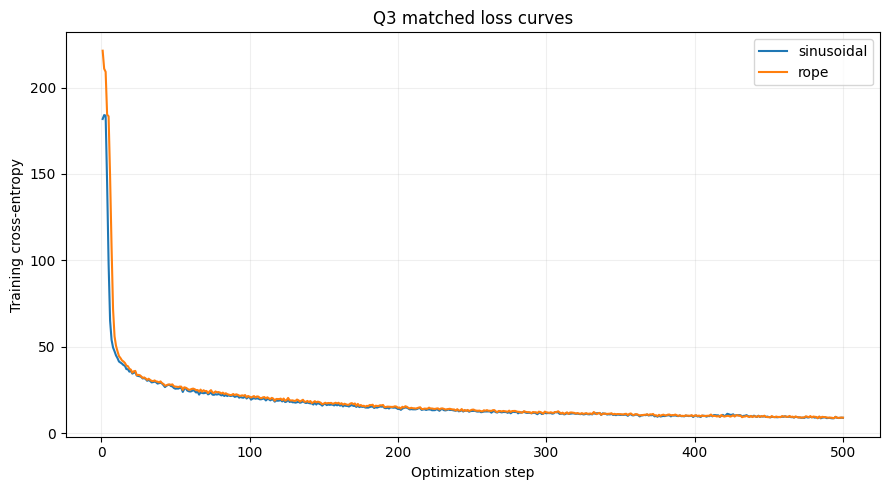

Normal-length held-out PPL: {'sinusoidal': 22118.965256569183, 'rope': 13275.418253240121}
Early convergence (same first/last step count): {'sinusoidal': {'initial_loss': 181.8372802734375, 'mean_first_n_loss': 46.88949783325195, 'mean_last_n_loss': 9.143890190124512, 'n': 50}, 'rope': {'initial_loss': 221.34808349609375, 'mean_first_n_loss': 55.488126831054686, 'mean_last_n_loss': 9.314693374633789, 'n': 50}}
Lower measured normal-length PPL: rope
Validated Q3 recovery ZIP: q3_all_artifacts.zip (35ed52787d60..., 377.0 MiB)


PosixPath('q3_all_artifacts.zip')

In [14]:
# Q3.4: normal-length, final-checkpoint comparison. Full measured runs only.
if q3.mode != "full":
    raise RuntimeError("Q3.4 is for full runs; switch Q3_SMOKE_TEST=False and train the pair")
q3_results = q3.require_complete()
q3_normal_ppl = {}
q3_curves = {}
for scheme in SCHEMES:
    metrics = q3_results[scheme]
    model = q3.load_final_model(scheme, device="cpu")
    before = weights_hash({key: value.detach().cpu() for key, value in model.state_dict().items()})
    measured = float(perplexity_of_texts(model, tokenizer, held_out, device="cpu", max_len=128))
    after = weights_hash({key: value.detach().cpu() for key, value in model.state_dict().items()})
    if before != after or not math.isfinite(measured):
        raise RuntimeError(f"Q3.4 {scheme} evaluation altered weights or returned non-finite PPL")
    if not math.isclose(measured, metrics["held_out_ppl"], rel_tol=1e-5, abs_tol=1e-4):
        raise RuntimeError(f"Q3.4 {scheme} helper/runtime PPL mismatch: {measured}, {metrics['held_out_ppl']}")
    q3_normal_ppl[scheme] = measured
    q3_curves[scheme] = [float(value) for value in metrics["loss_curve"]]
    del model

early_steps = max(1, min(50, len(q3_curves["rope"]) // 5))
early = {scheme: {"initial_loss": curve[0],
                  "mean_first_n_loss": float(sum(curve[:early_steps]) / early_steps),
                  "mean_last_n_loss": float(sum(curve[-early_steps:]) / early_steps),
                  "n": early_steps}
         for scheme, curve in q3_curves.items()}
q3_comparison = {
    "sinusoidal": q3_normal_ppl["sinusoidal"], "rope": q3_normal_ppl["rope"],
    "early_convergence": early, "loss_curve_paths": {
        scheme: str(q3.model_dir(scheme) / "metrics.json") for scheme in SCHEMES},
    "training_seconds": {scheme: q3_results[scheme]["cumulative_active_seconds"] for scheme in SCHEMES},
    "training_steps": {scheme: q3_results[scheme]["completed_steps"] for scheme in SCHEMES},
    "normal_eval_max_len": 128, "selected_q2_label": Q3_SELECTED_LABEL,
}
atomic_json(q3.root / "analysis" / "q3_ppl_comparison.json", q3_comparison)
log_result("q3_ppl_comparison", q3_comparison)
fig, ax = plt.subplots(figsize=(9, 5))
for scheme in SCHEMES:
    ax.plot(range(1, len(q3_curves[scheme]) + 1), q3_curves[scheme], label=scheme)
ax.set(xlabel="Optimization step", ylabel="Training cross-entropy", title="Q3 matched loss curves")
ax.legend(); ax.grid(alpha=0.2)
fig.tight_layout()
fig.savefig(q3.root / "plots" / "matched_loss_curves.png", dpi=160)
plt.show(); plt.close(fig)
print("Normal-length held-out PPL:", q3_normal_ppl)
print("Early convergence (same first/last step count):", early)
print("Lower measured normal-length PPL:", min(q3_normal_ppl, key=q3_normal_ppl.get))
q3.export_archive(force=True)


## 3.5 Matched and length-extrapolation experiments [35 Marks]

Train two otherwise-identical models: one using **sinusoidal positional encoding** and one using **RoPE**. Use the same seed, architecture, `n_heads` and `n_kv_heads` from Q2's best **MHA/GQA/MQA** configuration (exclude MLA), training data, and training budget.
Compare how sinusoidal positional encoding and RoPE behave when evaluated on contexts longer than those used during training.

**1. Construct the training windows**

Use the tokenized training corpus from Section 0. Construct fixed-length next-token-prediction examples using `TokenDataset(train_ids, 64)`.

**2. Train two matched models**

Set `max_seq_len=128` when constructing both models so that their positional tables/caches and causal masks already support 128 positions.

The additional positional capacity is available for evaluation; positions beyond the training window receive no training exposure.

**3. Evaluate at two length caps**

Evaluate each trained model on the same held-out texts using the supplied `perplexity_of_texts(...)` helper with `max_len=64` and `max_len=128`. Keep the learned weights unchanged between evaluations.
Discuss whether either model's perplexity changes more strongly when longer texts are evaluated.

Save the results using:

```python
log_result("q3_length_extrapolation", {
    "sinusoidal": {
        "ppl_64": ppl_sin_64,
        "ppl_128": ppl_sin_128,
    },
    "rope": {
        "ppl_64": ppl_rope_64,
        "ppl_128": ppl_rope_128,
    },
})
```

[logged] q3_length_extrapolation


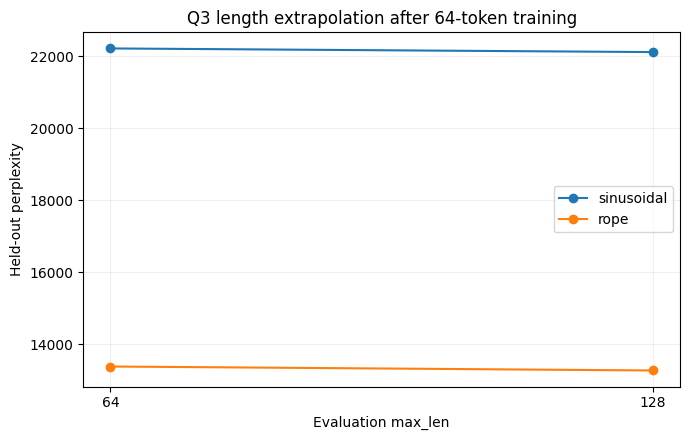

sinusoidal: PPL64=22220.0047, PPL128=22118.9653, change=-101.0394; decreases
rope: PPL64=13385.7236, PPL128=13275.4183, change=-110.3054; decreases
Validated Q3 recovery ZIP: q3_all_artifacts.zip (b841d780ab72..., 377.0 MiB)


PosixPath('q3_all_artifacts.zip')

In [15]:
# Q3.5: models trained via the separate matched-pair cell on TokenDataset(train_ids, 64).
# Evaluate their *unchanged final states* at 64 and 128 using the supplied helper.
if q3.mode != "full":
    raise RuntimeError("Q3.5 requires the completed full Q3 matched pair")
q3.require_complete()
q3_length_extrapolation = {}
for scheme in SCHEMES:
    model = q3.load_final_model(scheme, device="cpu")
    original_hash = weights_hash({key: value.detach().cpu() for key, value in model.state_dict().items()})
    scores = {f"ppl_{limit}": float(perplexity_of_texts(
        model, tokenizer, held_out, device="cpu", max_len=limit)) for limit in (64, 128)}
    if any(not math.isfinite(value) or value < 1 for value in scores.values()):
        raise RuntimeError(f"Non-finite Q3 length PPL for {scheme}: {scores}")
    if original_hash != weights_hash({key: value.detach().cpu() for key, value in model.state_dict().items()}):
        raise RuntimeError(f"Q3.5 unexpectedly modified {scheme} weights")
    q3_length_extrapolation[scheme] = scores
    del model
for scheme in SCHEMES:
    normal = json.loads((q3.model_dir(scheme) / "metrics.json").read_text())["held_out_ppl"]
    if not math.isclose(q3_length_extrapolation[scheme]["ppl_128"], normal, rel_tol=1e-5, abs_tol=1e-4):
        raise RuntimeError(f"Q3.5 {scheme} 128-token evaluation disagrees with saved final evaluation")
atomic_json(q3.root / "analysis" / "q3_length_extrapolation.json", q3_length_extrapolation)
log_result("q3_length_extrapolation", q3_length_extrapolation)
fig, ax = plt.subplots(figsize=(7, 4.5))
for scheme in SCHEMES:
    scores = q3_length_extrapolation[scheme]
    ax.plot([64, 128], [scores["ppl_64"], scores["ppl_128"]], marker="o", label=scheme)
ax.set(xlabel="Evaluation max_len", ylabel="Held-out perplexity",
       title="Q3 length extrapolation after 64-token training")
ax.set_xticks([64, 128]); ax.legend(); ax.grid(alpha=0.2)
fig.tight_layout()
fig.savefig(q3.root / "plots" / "length_extrapolation.png", dpi=160)
plt.show(); plt.close(fig)
for scheme, scores in q3_length_extrapolation.items():
    difference = scores["ppl_128"] - scores["ppl_64"]
    print(f"{scheme}: PPL64={scores['ppl_64']:.4f}, PPL128={scores['ppl_128']:.4f}, "
          f"change={difference:+.4f}; {'increases' if difference > 0 else 'decreases' if difference < 0 else 'unchanged'}")
q3.export_archive(force=True)


## 3.6 Frequency-band ablation [25 Marks]

Using the trained RoPE model, compare three settings **at inference only, without retraining**:

1. **Baseline:** all RoPE rotations unchanged.
2. **Freeze slow:** disable rotation for the slowest-rotating half of the frequency pairs.
3. **Freeze fast:** disable rotation for the fastest-rotating half of the frequency pairs.

For **split-half RoPE**, pair $i$ contains dimensions $(i, i+d/2)$, where $d$ is the head dimension. Earlier pair indices form the fastest half; later pair indices form the slowest half. These bands refer to **halves of the pair indices**, not halves of the feature vector.

To freeze a band, set its rotation to position 0 (`cos = 1`, `sin = 0`) at every position, for both queries and keys in every attention layer. Preserve the feature values and restore the original rotations before evaluating another setting.

Evaluate all three settings on the **same held-out texts at the same maximum evaluation length**. Report and plot their perplexities, and calculate each ablation's change from baseline. Discuss what the results suggest about reliance on fast versus slow frequencies and what you predict for longer contexts.

Save the results using `log_result("q3_frequency_ablation", q3_frequency_ablation)` with these keys:

- `baseline_rope_ppl`
- `freeze_slowest_half_ppl`
- `freeze_fastest_half_ppl`
- `slow_hit`: slow-frozen perplexity minus baseline
- `fast_hit`: fast-frozen perplexity minus baseline

[logged] q3_frequency_ablation


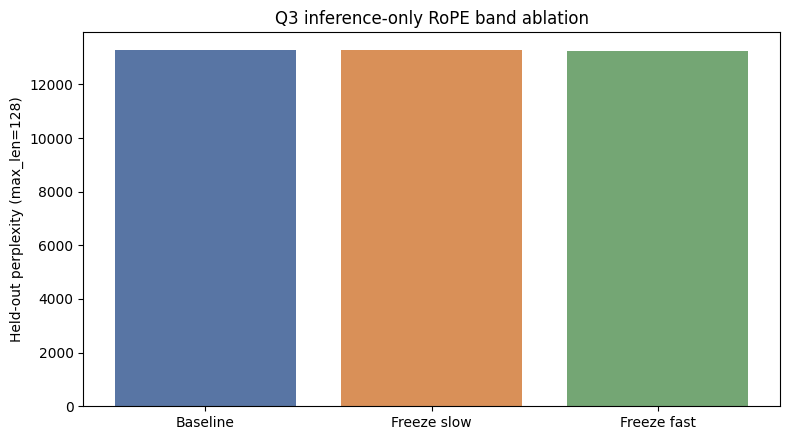

{'baseline_rope_ppl': 13275.418253240121, 'freeze_slowest_half_ppl': 13275.304363402563, 'freeze_fastest_half_ppl': 13237.298941599527, 'slow_hit': -0.11388983755750814, 'fast_hit': -38.11931164059388}
Measured slow-band freeze increases PPL more than fast-band freeze.
Validated Q3 recovery ZIP: q3_all_artifacts.zip (7a77c4c6c97a..., 377.1 MiB)


PosixPath('q3_all_artifacts.zip')

In [16]:
# Q3.6: frequency ablation on final trained RoPE weights only. No optimizer or backward pass.
if q3.mode != "full":
    raise RuntimeError("Q3.6 requires the completed full Q3 RoPE model")
q3.require_complete()
rope_model = q3.load_final_model("rope", device="cpu")
rope_weights_before = weights_hash({key: value.detach().cpu() for key, value in rope_model.state_dict().items()})
rope_layers = [block.attn for block in rope_model.blocks]
assert rope_layers and all(layer.use_rope for layer in rope_layers)
original_caches = [(layer.rope_cos.detach().clone(), layer.rope_sin.detach().clone())
                   for layer in rope_layers]
pair_count = original_caches[0][0].shape[-1] // 2
assert pair_count >= 2 and all(cos.shape[-1] == 2 * pair_count for cos, _ in original_caches)
fast_pairs = list(range(0, pair_count // 2))
slow_pairs = list(range(pair_count // 2, pair_count))
assert fast_pairs and slow_pairs and set(fast_pairs).isdisjoint(slow_pairs)

def q3_restore_rope_caches():
    with torch.no_grad():
        for layer, (cos, sin) in zip(rope_layers, original_caches):
            layer.rope_cos.copy_(cos)
            layer.rope_sin.copy_(sin)

def q3_freeze_pairs(pair_indices):
    # Split-half pair i occupies raw channels i and i + d_head/2.
    channels = pair_indices + [i + pair_count for i in pair_indices]
    with torch.no_grad():
        for layer in rope_layers:
            layer.rope_cos[:, channels] = 1.0
            layer.rope_sin[:, channels] = 0.0
    return channels

q3_ablation_values = {}
try:
    for condition, frozen in (("baseline_rope_ppl", []),
                              ("freeze_slowest_half_ppl", slow_pairs),
                              ("freeze_fastest_half_ppl", fast_pairs)):
        q3_restore_rope_caches()
        if frozen:
            channels = q3_freeze_pairs(frozen)
            assert all(torch.all(layer.rope_cos[:, channels] == 1) and
                       torch.all(layer.rope_sin[:, channels] == 0) for layer in rope_layers)
        q3_ablation_values[condition] = float(perplexity_of_texts(
            rope_model, tokenizer, held_out, device="cpu", max_len=128))
        if not math.isfinite(q3_ablation_values[condition]):
            raise RuntimeError(f"Non-finite RoPE ablation result: {condition}")
finally:
    q3_restore_rope_caches()
assert all(torch.equal(layer.rope_cos, cos) and torch.equal(layer.rope_sin, sin)
           for layer, (cos, sin) in zip(rope_layers, original_caches))
assert rope_weights_before == weights_hash({key: value.detach().cpu() for key, value in rope_model.state_dict().items()})
baseline = q3_ablation_values["baseline_rope_ppl"]
if not math.isclose(baseline, q3.result("rope")["held_out_ppl"], rel_tol=1e-5, abs_tol=1e-4):
    raise RuntimeError("Q3.6 baseline does not match the trained final RoPE evaluation")
q3_frequency_ablation = {
    **q3_ablation_values,
    "slow_hit": q3_ablation_values["freeze_slowest_half_ppl"] - baseline,
    "fast_hit": q3_ablation_values["freeze_fastest_half_ppl"] - baseline,
}
atomic_json(q3.root / "analysis" / "q3_frequency_ablation.json", q3_frequency_ablation)
log_result("q3_frequency_ablation", q3_frequency_ablation)
fig, ax = plt.subplots(figsize=(8, 4.5))
labels = ["Baseline", "Freeze slow", "Freeze fast"]
values = [q3_ablation_values[key] for key in
          ("baseline_rope_ppl", "freeze_slowest_half_ppl", "freeze_fastest_half_ppl")]
ax.bar(labels, values, color=["#5875a4", "#d99058", "#74a674"])
ax.set(ylabel="Held-out perplexity (max_len=128)", title="Q3 inference-only RoPE band ablation")
fig.tight_layout()
fig.savefig(q3.root / "plots" / "frequency_ablation.png", dpi=160)
plt.show(); plt.close(fig)
print(q3_frequency_ablation)
if q3_frequency_ablation["slow_hit"] > q3_frequency_ablation["fast_hit"]:
    print("Measured slow-band freeze increases PPL more than fast-band freeze.")
elif q3_frequency_ablation["fast_hit"] > q3_frequency_ablation["slow_hit"]:
    print("Measured fast-band freeze increases PPL more than slow-band freeze.")
else:
    print("Measured fast- and slow-band freezes have equal PPL impact.")
q3.export_archive(force=True)


## 3.7 Reproducibility and submission artifacts [10 Marks]

Save the Question 3 checkpoint, configuration, metrics, and required RoPE/attention/model source snapshots in the designated submission directory. Ensure that the Question 3 autograder runs successfully.


### Required Q3 metrics structure

Save the following structure in `submissions/q3/metrics.json` using `save_submission(...)`. Preserve the key names and nesting.

**The numbers below are illustrative. Replace them with your measured results.**

```json
{
  "sinusoidal_held_out_ppl": 32.0,
  "rope_held_out_ppl": 30.0,
  "sinusoidal_loss_curve": [4.5, 4.0, 3.8],
  "rope_loss_curve": [4.4, 3.9, 3.7],
  "length_extrapolation": {
    "sinusoidal": {
      "ppl_64": 34.0,
      "ppl_128": 37.0
    },
    "rope": {
      "ppl_64": 33.0,
      "ppl_128": 35.0
    }
  },
  "frequency_ablation": {
    "baseline_rope_ppl": 30.0,
    "freeze_slowest_half_ppl": 32.0,
    "freeze_fastest_half_ppl": 29.0,
    "slow_hit": 2.0,
    "fast_hit": -1.0
  }
}
```

**Field meanings**

| Field                     | Required content                                                                                     |
| ------------------------- | ---------------------------------------------------------------------------------------------------- |
| `sinusoidal_held_out_ppl` | Final held-out perplexity of the sinusoidal model from Q3.4.                                         |
| `rope_held_out_ppl`       | Final held-out perplexity of the RoPE model from Q3.4.                                               |
| `sinusoidal_loss_curve`   | Recorded training losses for the sinusoidal model, in chronological order.                           |
| `rope_loss_curve`         | Recorded training losses for the RoPE model, in chronological order.                                 |
| `length_extrapolation`    | Q3.5 results for both shorter-context-trained models, evaluated with `max_len=64` and `max_len=128`. |
| `frequency_ablation`      | Q3.6 results for unchanged RoPE, frozen slow frequencies, and frozen fast frequencies.               |

Passing these checks verifies the structure and numerical consistency of the submitted evidence. The required plots, experimental controls, and written analysis must still appear in the notebook.


In [17]:
# Q3.7: official submission is the genuine full-trained RoPE state_dict.
if q3.mode != "full":
    raise RuntimeError("Never submit Q3 smoke-test weights or measurements")
q3_results = q3.require_complete()
q3_length_extrapolation = json.loads((q3.root / "analysis" / "q3_length_extrapolation.json").read_text())
q3_frequency_ablation = json.loads((q3.root / "analysis" / "q3_frequency_ablation.json").read_text())
metrics_q3 = {
    "sinusoidal_held_out_ppl": float(q3_results["sinusoidal"]["held_out_ppl"]),
    "rope_held_out_ppl": float(q3_results["rope"]["held_out_ppl"]),
    "sinusoidal_loss_curve": [float(x) for x in q3_results["sinusoidal"]["loss_curve"]],
    "rope_loss_curve": [float(x) for x in q3_results["rope"]["loss_curve"]],
    "length_extrapolation": q3_length_extrapolation,
    "frequency_ablation": q3_frequency_ablation,
}
assert len(metrics_q3["sinusoidal_loss_curve"]) == q3.steps
assert len(metrics_q3["rope_loss_curve"]) == q3.steps
assert all(math.isfinite(x) for x in metrics_q3["sinusoidal_loss_curve"] +
           metrics_q3["rope_loss_curve"])
assert all(math.isfinite(metrics_q3["length_extrapolation"][scheme][f"ppl_{length}"])
           for scheme in SCHEMES for length in (64, 128))
assert all(math.isfinite(value) for value in q3_frequency_ablation.values())
assert math.isclose(q3_frequency_ablation["baseline_rope_ppl"],
                    metrics_q3["rope_held_out_ppl"], rel_tol=1e-5, abs_tol=1e-4)
rope_model = q3.load_final_model("rope", device="cpu")
submission = Path("submissions/q3")
save_submission(str(submission), rope_model, q3.model_config("rope"), metrics_q3, VOCAB_SIZE)
for name in ("optim_muon.py", "model_builtin.py"):
    stale = submission / name
    if stale.exists():
        stale.unlink()  # Q3 does not depend on later-question modules.
for name in ("a1_tokenizer.py", "rope.py", "attention.py", "model_arch.py"):
    expected = q3.root / "source_snapshots" / name
    actual = submission / name
    if not actual.is_file() or file_sha256(actual) != file_sha256(expected):
        raise RuntimeError(f"Q3 submission source mismatch: {name}")
saved_cfg = json.loads((submission / "config.json").read_text())
assert saved_cfg["pos_emb_type"] == "rope" and saved_cfg["n_kv_heads"] == Q3_SELECTED_CONFIG["n_kv_heads"]
assert saved_cfg["vocab_size"] == VOCAB_SIZE and saved_cfg["max_seq_len"] == 128
saved_state = load_torch(submission / "model.pt")
assert isinstance(saved_state, dict) and weights_hash(saved_state) == q3_results["rope"]["final_state_hash"]
assert json.loads((submission / "metrics.json").read_text()) == metrics_q3
atomic_json(q3.root / "manifests" / "submission_identity.json", {
    "question": "q3", "submitted_scheme": "rope", "q2_selected_label": Q3_SELECTED_LABEL,
    "rope_final_state_hash": q3_results["rope"]["final_state_hash"],
    "submission_model_sha256": file_sha256(submission / "model.pt"),
    "config_sha256": file_sha256(submission / "config.json"),
    "metrics_sha256": file_sha256(submission / "metrics.json"),
    "source_hashes": {name: file_sha256(submission / name) for name in
                      ("a1_tokenizer.py", "rope.py", "attention.py", "model_arch.py")},
})
log_result("q3_submission", {"scheme": "rope", "model_sha256": file_sha256(submission / "model.pt")})
print("Official Q3 RoPE submission saved and verified:", submission.resolve())
q3.export_archive(force=True)


Saved submission artifacts to submissions/q3/ (model.pt, config.json, metrics.json; sources: a1_tokenizer.py, attention.py, model_arch.py, rope.py)
[logged] q3_submission
Official Q3 RoPE submission saved and verified: /kaggle/working/submissions/q3
Validated Q3 recovery ZIP: q3_all_artifacts.zip (5f7b608d23f5..., 394.1 MiB)


PosixPath('q3_all_artifacts.zip')

### Q3 official validation and recovery export

Run only after the full matched training pair, Q3.4–Q3.6 analyses, and Q3.7 submission.
This runs the unmodified course Q3 autograder and then validates the portable recovery ZIP.


In [18]:
if q3.mode != "full" or not all((Path("submissions/q3") / name).is_file() for name in
        ("rope.py", "attention.py", "model_arch.py", "model.pt", "config.json", "metrics.json")):
    raise RuntimeError("Finish the full Q3 submission before autograding")
_q3_grader = Path("autograder_q3.py")
if not _q3_grader.is_file():
    raise FileNotFoundError(_q3_grader)
_q3_grader_run = subprocess.run(
    [sys.executable, str(_q3_grader), "--student_dir", "."],
    cwd=Path.cwd(), text=True, capture_output=True,
)
print(_q3_grader_run.stdout)
if _q3_grader_run.stderr:
    print(_q3_grader_run.stderr)
atomic_json(q3.root / "analysis" / "autograder_result.json", {
    "returncode": _q3_grader_run.returncode,
    "stdout": _q3_grader_run.stdout, "stderr": _q3_grader_run.stderr,
})
if _q3_grader_run.returncode != 0:
    q3.export_archive(force=True)
    raise RuntimeError("Official Q3 autograder failed; inspect saved output and repair Q3 only")
q3_zip = q3.export_archive(force=True)
q3_manifest = q3.validate_archive(q3_zip)
print("Official Q3 autograder passed")
print("Q3 ZIP:", q3_zip.resolve(), "| members:", len(q3_manifest["files"]),
      "| SHA256:", file_sha256(q3_zip))


  [PASS] rope.py present
  [PASS] attention.py: no forbidden implementation
  [PASS] model_arch.py: no forbidden implementation
  [PASS] rope.py: no forbidden implementation
  [PASS] rope.py defines build_rope_cache()
  [PASS] rope.py defines rotate_half()
  [PASS] rope.py defines apply_rope()
  [PASS] build_rope_cache returns (cos, sin) each of shape (max_seq_len, d_head) — cos.shape=(300, 16), sin.shape=(300, 16)
  [PASS] RoPE relative-position invariance: dot(m,n) depends only on m-n (mean |diff| over 8 random vector pairs, same distance, different absolute positions) — mean |diff| = 3.99e-06
  [PASS] sanity: a clearly DIFFERENT relative distance (3 vs. 43) gives a meaningfully different dot product on average (catches a no-op / identity apply_rope, or one that collapses all distances together, which would otherwise trivially pass the check above) — mean |diff| = 2.53e+00
  [PASS] Q3 RoPE integration, n_kv_heads=8 — both modes match their references at lengths 1, 7 and 16
  [PASS] Q

# Question 4 — SGD, RMSProp, AdamW, and Muon [210 Marks]

Everything so far has used Adam. Here you'll hold the architecture fixed (use your best
config from Questions 2-3) and vary only the optimizer, across four options
that represent genuinely different update rules.



<!--
The comparison should distinguish optimization quality from computational cost. Perform your own hyperparameter optimization for each optimizer, record convergence both by training step and wall-clock time, and test the recommended Muon parameter split against a broader application of Muon-style updates. -->


Let $\theta_t$ denote the parameters, $g_t = \nabla_\theta \mathcal{L}(\theta_t)$ the current gradient, $\eta$ the learning rate, and $\epsilon$ a small constant for numerical stability. Moving-average buffers start at zero.

| Optimizer | Update rule |  Brief description |
|--|-----|--|
| **SGD with momentum** | $m_t = \mu m_{t-1} + g_t$<br>$\theta_{t+1} = \theta_t - \eta m_t$ | Accumulates past gradients to maintain progress along consistent directions and reduce oscillation. No per-parameter adaptive scaling.  Adds a momentum buffer to ordinary SGD. |
| **RMSProp** | $v_t = \alpha v_{t-1} + (1-\alpha)g_t^2$<br>$\theta_{t+1} = \theta_t - \eta \frac{g_t}{\sqrt{v_t}+\epsilon}$ |  Adapts the effective learning rate separately for each parameter; larger recent gradients lead to smaller effective learning rates. Scales each gradient using its recent squared magnitude. |
| **AdamW** | $m_t = \beta_1m_{t-1} + (1-\beta_1)g_t$<br>$v_t = \beta_2v_{t-1} + (1-\beta_2)g_t^2$<br>$\theta_{t+1} = (1-\eta\lambda)\theta_t - \eta\frac{\hat{m}_t}{\sqrt{\hat{v}_t}+\epsilon}$ | Uses gradient history to determine the update direction and scale, while shrinking weights separately through weight decay. Combines momentum, adaptive scaling, and decoupled weight decay. |
| **Muon (simplified)** | $M_t = \mu M_{t-1} + G_t$<br>$U_t = \operatorname{NS}(M_t)$<br>$W_{t+1} = W_t - \eta U_t$ |  Uses Newton–Schulz iterations to reduce imbalance among the update's singular values, rather than scaling individual entries using squared-gradient history. Approximately orthogonalizes the momentum update for each 2D weight matrix. |

For AdamW, $\hat{m}_t = m_t/(1-\beta_1^t)$ and $\hat{v}_t = v_t/(1-\beta_2^t)$ are bias-corrected estimates, and $\lambda$ is the weight-decay coefficient. Squares, square roots, and divisions are elementwise.

For Muon, $W_t$ is a 2D weight matrix, $G_t$ its gradient, and $\operatorname{NS}$ the approximate orthogonalization procedure. Apply Muon to hidden attention and feed-forward matrices; use AdamW for the remaining parameters.

<!--
Perform your own **hyperparameter optimization for each optimizer** and document the settings tried and the selection criterion. Compare model quality using held-out perplexity and the specified downstream evaluation, and record convergence against both **training steps** and **wall-clock time** to distinguish optimization quality from computational cost. Finally, test the recommended Muon parameter split against a broader application of Muon-style updates. -->


<div class="alert alert-info">
<b>Note:</b>
</br>
1. Attention Mechanism (MHA vs MQA vs GQA) which performed better on held-out perplexity. </br>
2. Position Encoding which performed better on held-out perplexity.</br>
3. Use PyTorch's implementations for SGD, RMSProp, and AdamW; implement the simplified Muon optimizer specified in the notebook from scratch.
</div>
**Scope:** the architecture carried forward from Q3 is MHA, GQA, or MQA; MLA remains Q2-only.


## 4.1 Newton–Schulz orthogonalization and Muon implementation [55 Marks]

### Why apply this transformation?

Consider the compact singular value decomposition of the momentum matrix:

$$M_t = P\Sigma Q^\top.$$

The columns of $P$ and $Q$ describe paired output and input directions, while each singular value in $\Sigma$ determines the update strength along that pair. A few large singular values can therefore dominate the momentum update.

The idealized orthogonalization replaces each nonzero singular value by $1$:

$$P\Sigma Q^\top \longrightarrow PQ^\top.$$

NS approximates this effect using matrix multiplications, without explicitly computing an SVD. The supplied finite polynomial iteration makes the singular values more comparable; it does **not** guarantee that they become exactly $1$.

**Intuition:** if two singular directions have strengths $10$ and $1$, ordinary momentum updates the first ten times as strongly. Ideal orthogonalization gives both unit strength, preserving their directions while removing this magnitude imbalance. Muon uses an approximation of this idea to give weaker directions more influence.

This transforms the **momentum update**, not the weight matrix itself; it does not force the model's weights to be orthogonal.


Complete the provided Muon implementation. Normalize the 2D update matrix and perform the prescribed Newton–Schulz iterations,

$$X_{k+1} = aX_k + b(X_kX_k^\top)X_k + c(X_kX_k^\top)^2X_k,$$

using the coefficients and iteration count given in the code. Then implement the Muon optimizer step: update the momentum buffer, orthogonalize the 2D momentum update, apply the stated scaling convention, and update the parameter.

Use Muon for the intended 2D hidden-layer matrices; do not replace the supplied optimizer design with a library implementation.





In [ ]:
%%writefile optim_muon.py
# TODO 4.1: complete Newton--Schulz orthogonalization and the Muon optimizer step in this cell.
"""A from-scratch (simplified) implementation of the Muon optimizer.

Muon updates 2D parameter matrices with a momentum-then-orthogonalize rule. It is meant
to be used ONLY on hidden-layer weight matrices (e.g. attention q/k/v/out projections,
FFN weights) -- NOT on embeddings, the output head, or 1D parameters (biases, LayerNorm
gains). Pair it with a small separate torch.optim.AdamW for those other parameters (see
the training loop below).
"""
import torch


@torch.no_grad()
def newton_schulz_orthogonalize(G: torch.Tensor, steps: int = 5, eps: float = 1e-7) -> torch.Tensor:
    """
    Approximate the orthogonalization of a 2D matrix G (i.e. push its singular values
    toward 1 while preserving its singular vectors) via a few Newton-Schulz iterations,
    which only require matrix multiplications (no SVD / explicit inverse).

    Classic quintic Newton-Schulz update (Jordan et al.):
        X_0 = G / ||G||_F
        X_{k+1} = a*X_k + b*(X_k X_k^T) X_k + c*(X_k X_k^T)^2 X_k
    with a=3.4445, b=-4.7750, c=2.0315 (coefficients tuned so this converges quickly
    for matrices whose singular values start out reasonably close to 1 after the
    Frobenius normalization).
    """
    assert G.ndim == 2
    a, b, c = 3.4445, -4.7750, 2.0315
    X = G / (G.norm() + eps)
    if G.size(0) > G.size(1):
        X = X.T  # operate on the wider-than-tall orientation, transpose back at the end
    # TODO: run `steps` iterations of X = a*X + b*(X @ X.T) @ X + c*(X @ X.T) @ (X @ X.T) @ X
    if G.size(0) > G.size(1):
        X = X.T
    raise NotImplementedError


class Muon(torch.optim.Optimizer):
    def __init__(self, params, lr: float = 0.02, momentum: float = 0.95, ns_steps: int = 5):
        defaults = dict(lr=lr, momentum=momentum, ns_steps=ns_steps)
        super().__init__(params, defaults)

    @torch.no_grad()
    def step(self):
        for group in self.param_groups:
            for p in group["params"]:
                if p.grad is None:
                    continue
                assert p.ndim == 2, "Muon is only defined for 2D weight matrices in this implementation"
                g = p.grad
                state = self.state[p]
                if "momentum_buffer" not in state:
                    state["momentum_buffer"] = torch.zeros_like(g)
                buf = state["momentum_buffer"]
                # TODO 1: update the momentum buffer: buf = momentum * buf + g
                # TODO 2: orthogonalize the momentum buffer with newton_schulz_orthogonalize
                # TODO 3: Scale by sqrt(max(1.0, p.size(0) / p.size(1))).
                # TODO 4: p -= group["lr"] * (orthogonalized update)
                raise NotImplementedError



In [ ]:
import importlib, sys
sys.modules.pop("optim_muon", None)
optim_muon = importlib.import_module("optim_muon")
Muon = optim_muon.Muon
newton_schulz_orthogonalize = optim_muon.newton_schulz_orthogonalize


## 4.2 Optimizer parameter groups and controlled training harness [35 Marks]

Construct a common training function that can run SGD with momentum, RMSProp, AdamW, or Muon under the same model configuration and data pipeline. For the recommended Muon setup, separate eligible 2D hidden-layer matrices from embeddings, output-head parameters, LayerNorm parameters, biases, and other non-2D parameters; use AdamW for the latter group as described in the notebook.

The training harness should record loss, elapsed wall-clock time, and the metrics needed by the later comparisons.


In [ ]:
# TODO 4.2: implement the common optimizer training harness.

def build_param_groups_for_muon(model):
    raise NotImplementedError

def train_with_optimizer(optimizer_name, lr, steps=OPT_STEPS):
#   1. builds a fresh model using the fixed architecture chosen for Q4,
#   2. constructs SGD / RMSProp / AdamW / the recommended Muon+AdamW parameter split,
#   3. trains for the caller-selected `steps` optimization steps,
#   4. records the training-loss curve and cumulative wall-clock time, elapsed time and the held-out perplexity
#   5. returns the trained model and the measurements.
    raise NotImplementedError

# For the recommended Muon setup, send eligible 2D hidden-layer matrices to Muon and
# embeddings, output head, LayerNorm parameters, biases, and other non-2D parameters
# to the companion AdamW optimizer.
raise NotImplementedError


## 4.3 Hyperparameter optimization and convergence measurements [60 Marks]

Perform learning rate hyperparameter optimization for **all four optimizers** using otherwise
comparable models. There is deliberately **no prescribed optimizer-specific HPO list or
fixed learning-rate grid**. Choose and justify the search space yourself.

For each optimizer
1. Record the hyperparameter tried.
2. Record the held out ppl and elapsed time for each hyperparameter
3. For the "best" hyperparmeter config, save:  
    1. PPL
    2. training loss curve
    3. Cumulative Wall-clock time
    4. Hyperparamer as well as number of optimizations steps

Save the overall-best model as the checkpoint.


HPO will be graded on the quality of the configurations you find, using **held-out
perplexity**, together with the evidence that the search
was carried out sensibly. Keep architecture, tokenizer, data split, and seed handling
controlled when comparing optimizers.


In [ ]:
# TODO 4.3: perform student-designed HPO for all four optimizers.
#
# No fixed LR/HPO grid is supplied. Choose your own search space and record the trials.
# Suggested record format (you may include additional optimizer-specific fields):

#
#
raise NotImplementedError


## 4.4 Convergence in steps and wall-clock time [15 Marks]

Plot training loss against both optimization step and cumulative wall-clock time for SGD, RMSProp, AdamW, and Muon. Choose and state a common loss threshold, then report how many steps and how much time each optimizer requires to reach it when the threshold is reached.

Compare the rankings by steps and by time and explain any difference using the measured per-step cost.


In [ ]:
# TODO 4.4: plot loss against both optimization step and cumulative wall-clock time.
# Choose one explicit common loss threshold and report steps/time-to-threshold for each optimizer.


## 4.5 Learning-rate sensitivity [15 Marks]

Use the HPO trials you chose in Q4.3 to compare at least SGD and one adaptive optimizer.
Include enough learning-rate variation to support a meaningful sensitivity analysis.
Report held-out perplexity across the tested learning rates and discuss which optimizer
is more sensitive to a poorly chosen learning rate.

There is no prescribed learning-rate list; base the conclusion on your own recorded HPO
results and clearly state the values you tried.


In [ ]:
# TODO 4.5: use your recorded HPO trials to tabulate learning-rate sensitivity for
# at least SGD and one adaptive optimizer. State the learning rates you chose and compare
# held-out PPL; do not assume a course-provided fixed grid.


## 4.6 Muon parameter-split experiment [20 Marks]

Compare the recommended setup—Muon on eligible 2D hidden matrices and AdamW on the remaining parameters—with the broader Muon-style variant. Keep the model and training budget matched.
Test whether this specificity matters here: try applying Muon to *every* parameter (including embeddings and 1D parameters, reshaping/faking 2D-ness where necessary, or just skipping the orthogonalization for 1D params but still giving them Muon-style momentum) vs. the recommended split (Muon for hidden matrices only, AdamW for the rest).

Report the resulting convergence/perplexity measurements and state whether the recommended parameter split makes a meaningful difference at this scale.
Does deviating from the recommended split noticeably hurt convergence on this model/corpus, or does it not matter much at this scale? Report what you find.



In [ ]:
# TODO 4.6: run the broader-Muon comparison .
# Keep architecture, seed procedure, and training budget matched; report convergence/PPL and
# compare against the recommended Muon/AdamW parameter split.


## 4.7 Reproducibility and submission artifacts [10 Marks]

Save the best Question 4 checkpoint, optimizer/configuration information, HPO metrics, and required source snapshots in the designated submission directory. Ensure that the Question 4 autograder runs successfully.


### Required Q4 metrics structure

Save the following structure in `submissions/q4/metrics.json` using `save_submission(...)`. Each of the four top-level dictionaries must contain entries for `sgd`, `rmsprop`, `adamw`, and `muon`.

**The numbers below are illustrative. The learning rates are examples, not a prescribed search grid. Replace them with your own trials and measurements.**

```json
{
  "per_optimizer_best_ppl": {
    "sgd": 40.0,
    "rmsprop": 35.0,
    "adamw": 28.0,
    "muon": 27.0
  },
  "per_optimizer_loss_curves": {
    "sgd": [4.8, 4.2, 3.9],
    "rmsprop": [4.7, 4.0, 3.6],
    "adamw": [4.6, 3.8, 3.4],
    "muon": [4.6, 3.7, 3.3]
  },
  "per_optimizer_time_curves": {
    "sgd": [0.10, 0.20, 0.30],
    "rmsprop": [0.12, 0.24, 0.36],
    "adamw": [0.13, 0.26, 0.39],
    "muon": [0.16, 0.32, 0.48]
  },
  "lr_sweep_results": {
    "sgd": [
      {"lr": 0.1, "held_out_ppl": 48.0},
      {"lr": 0.03, "held_out_ppl": 40.0}
    ],
    "rmsprop": [
      {"lr": 0.001, "held_out_ppl": 35.0},
      {"lr": 0.0003, "held_out_ppl": 38.0}
    ],
    "adamw": [
      {"lr": 0.001, "held_out_ppl": 31.0},
      {"lr": 0.0003, "held_out_ppl": 28.0}
    ],
    "muon": [
      {"lr": 0.02, "held_out_ppl": 27.0},
      {"lr": 0.005, "held_out_ppl": 33.0}
    ]
  }
}
```

**Field meanings**

| Field                       | Required content                                                                                       |
| --------------------------- | ------------------------------------------------------------------------------------------------------ |
| `per_optimizer_best_ppl`    | Lowest successful held-out perplexity recorded for each optimizer.                                     |
| `per_optimizer_loss_curves` | Training-loss curve belonging to each optimizer’s selected best run.                                   |
| `per_optimizer_time_curves` | Cumulative elapsed training time in seconds at each corresponding loss measurement in that best run.   |
| `lr_sweep_results`          | A nonempty list of trial records for each optimizer. Each record must contain `lr` and `held_out_ppl`. |



In [ ]:
# TODO 4.7: save the Q4 submission artifacts and HPO/best-run evidence.
metrics_q4 = {
    "per_optimizer_best_ppl": {},          # {"sgd": ..., "rmsprop": ..., "adamw": ..., "muon": ...}
    "per_optimizer_loss_curves": {},      # {"sgd" : [.. train_loss_curve] , "rmsprop" : [..],...}
    "per_optimizer_time_curves" : {},
    "lr_sweep_results" : {} ,
    # { "sgd": [ { "lr" : .., "ppl" : ..., "held_out_ppl" : ... },...], "rmsprop" : [...], ... }
}
# TODO: save_submission("submissions/q4", best_model_q4,
#                       {"question": "q4", "optimizer": ..., ...},
#                       metrics_q4, VOCAB_SIZE)




# Question 5 — Rebuild With PyTorch Transformer Modules [180 Marks]

Rebuild the architecture-side experiments from Questions 1–3 using PyTorch's Transformer modules wherever the library directly supports the requested operation. Use a causal mask so that the built-in Transformer remains a decoder-only language model, and compare the built-in implementation with the from-scratch implementation under matched settings.

The standard MHA + sinusoidal model can be represented directly with `nn.TransformerEncoderLayer`/`nn.MultiheadAttention`. GQA/MQA and RoPE are not natively represented by the same high-level API in the form used earlier in the assignment, so document the limitation and use the notebook's stated workaround or compromise rather than silently changing the task.

**Scope:** Q2-style comparisons here cover MHA/GQA/MQA only. MLA is not required in Q5.


## 5.1 Causal decoder using PyTorch Transformer modules [40 Marks]

Implement the decoder-only baseline using PyTorch Transformer components, including token embeddings, sinusoidal positional encoding, `nn.TransformerEncoderLayer`/`nn.TransformerEncoder`, a final normalization layer, and the language-model output head.

Because these encoder layers are bidirectional by default, construct and pass an explicit causal attention mask at every forward call so that position $t$ cannot attend to positions $>t$.


In [ ]:
%%writefile model_builtin.py
# TODO 5.1: complete the built-in causal decoder implementation in this cell.
"""Decoder-only Transformer LM built from torch.nn.Transformer* building blocks."""
import math
from dataclasses import dataclass
import torch
import torch.nn as nn


@dataclass
class BuiltinLMConfig:
    vocab_size: int
    d_model: int = 256
    n_layers: int = 4
    n_heads: int = 4
    d_ff: int = 1024
    max_seq_len: int = 256
    dropout: float = 0.1
    norm_first: bool = False


def sinusoidal_positional_encoding(max_len: int, d_model: int) -> torch.Tensor:
    # TODO: reuse the same formula as model_arch.py's version (feel free to import it
    # instead of duplicating, e.g. `from model_arch import sinusoidal_positional_encoding`)
    raise NotImplementedError


class BuiltinDecoderLM(nn.Module):
    """
    GPT-style decoder-only LM built on nn.TransformerEncoderLayer + a causal mask.
    The autograder imports this class directly for Question 5 -- do not rename it.
    """

    def __init__(self, cfg: BuiltinLMConfig):
        super().__init__()
        self.cfg = cfg
        self.tok_emb = nn.Embedding(cfg.vocab_size, cfg.d_model)
        pe = sinusoidal_positional_encoding(cfg.max_seq_len, cfg.d_model)
        self.register_buffer("pos_emb", pe, persistent=False)

        # TODO: build an nn.TransformerEncoderLayer (batch_first=True, activation="gelu",
        # norm_first=cfg.norm_first to match your from-scratch pre-norm blocks) and wrap
        # cfg.n_layers of them in an nn.TransformerEncoder.
        self.encoder = None

        self.ln_f = nn.LayerNorm(cfg.d_model)
        self.head = nn.Linear(cfg.d_model, cfg.vocab_size, bias=False)
        self.head.weight = self.tok_emb.weight

    def forward(self, idx: torch.Tensor) -> torch.Tensor:
        B, T = idx.shape
        x = self.tok_emb(idx) + self.pos_emb[:T].unsqueeze(0)

        # TODO: build a causal mask suitable for nn.TransformerEncoder's `mask` argument.
        # Two common conventions -- pick one and be consistent:
        #   (a) a float mask with 0 where attention is allowed and -inf where it's not
        #       (this is what nn.Transformer historically expects for `src_mask`), or
        #   (b) a bool mask, with `is_causal=True` passed instead if your torch version
        #       supports it directly.
        # Check torch.nn.Transformer.generate_square_subsequent_mask -- you are allowed
        # to use that utility function even though you can't use nn.Transformer itself
        # for the *model*; it is just a mask-construction helper.
        causal_mask = None

        # TODO: x = self.encoder(x, mask=causal_mask); x = self.ln_f(x); return self.head(x)
        raise NotImplementedError


In [ ]:
import importlib, sys
sys.modules.pop("model_builtin", None)
model_builtin = importlib.import_module("model_builtin")
BuiltinLMConfig = model_builtin.BuiltinLMConfig
BuiltinDecoderLM = model_builtin.BuiltinDecoderLM


## 5.2 Numerical attention-equivalence check [30 Marks]

Before training the built-in model, compare your Question 1 attention module against `nn.MultiheadAttention` using identical random inputs and copied Q/K/V/output projection weights. Disable or control stochastic effects such as dropout.

Report the maximum absolute output difference,

$$ \Delta_{\max} = \max_i \left| y^{\text{scratch}}_i-y^{\text{builtin}}_i\right|, $$

using the same causal masking convention in both implementations.


Use the following matched conventions for this check:

- Compare the **standard MHA, no-RoPE** attention configuration: `n_kv_heads == n_heads`, `use_rope=False`, and the standard attention scale.
- Instantiate both modules with **no projection bias** and **zero dropout** (`bias=False`, `dropout=0.0` for `nn.MultiheadAttention`; use the equivalent settings in the scratch module).
- Use `batch_first=True` for `nn.MultiheadAttention` if your scratch input is `(B,T,C)`.
- Copy the scratch `q_proj`, `k_proj`, and `v_proj` weights into `nn.MultiheadAttention.in_proj_weight` in **Q, K, V order** using `torch.cat([W_q, W_k, W_v], dim=0)`, and copy the output projection weight exactly.
- If you use a Boolean causal mask, remember the conventions differ: in the scratch mask `True` means **allowed**, while for `nn.MultiheadAttention.attn_mask`, `True` means **blocked**. Therefore invert the scratch Boolean mask before passing it to the built-in module.
- Use the same random input and deterministic settings for both modules. A correct matched implementation should normally give a maximum absolute difference near floating-point noise; use `1e-3` as the notebook target.


In [ ]:
# TODO 5.2: implement the numerical correctness check described above using the exact
# matching conventions specified in Subtask 5.2:
#   - scratch attention configured as standard MHA (n_kv_heads == n_heads), no RoPE,
#     standard attention scale, dropout=0.0;
#   - nn.MultiheadAttention(..., batch_first=True, bias=False, dropout=0.0);
#   - copy q/k/v weights into in_proj_weight in Q,K,V order and copy out_proj.weight;
#   - for a bool mask, invert the scratch convention because built-in True = blocked;
#   - run both on the same random input and report max absolute difference.
# Use  0  <= max_diff < 1e-3 as the notebook  target.
raise NotImplementedError


## 5.3 Numerical-match debugging [15 Marks]

Interpret the numerical-equivalence result from Subtask 5.2. If the discrepancy is larger than expected from floating-point effects, trace the two attention computations and identify the source of the mismatch, such as projection layout, mask semantics, scaling, dropout, or tensor reshaping.

Report the measured error and any correction made.


In [ ]:
# TODO 5.3: report and interpret the identical-weight numerical attention comparison from Q5.2.
# If the error is larger than expected, identify the source (weight layout, mask, scale, dropout,
# reshape, etc.) and document any correction.


## 5.4 Matched perplexity, parameter, and timing comparison [35 Marks]

Train the built-in standard-MHA + sinusoidal model and compare it with the corresponding from-scratch model under matched architecture size and training conditions. Record final held-out perplexity, parameter count, total wall-clock training time, and per-step timing.

Also repeat the architecture-side comparisons from Questions 2 and 3 to the extent supported by the built-in API, using the documented workaround where direct equivalence is not available.


Use a matched training budget for the built-in and from-scratch comparison. `TRAIN_STEPS` is a convenience default, not a required exact count; report the actual steps used.


In [ ]:
# TODO 5.4 A: train and benchmark the built-in standard-MHA + sinusoidal model under matched
# conditions against the corresponding from-scratch model. Report held-out PPL, parameter
# count, total training time, and matched per-step timing.


In [ ]:
# TODO 5.4 B: the architecture-side comparisons from Questions 2 and 3 to the extent
# supported by the built-in API, using the documented workaround where direct equivalence
# is not available.

## 5.5 GQA/RoPE limitation or justified workaround [15 Marks]

State explicitly which requested GQA/MQA and RoPE variants can and cannot be expressed directly using the chosen PyTorch high-level modules. For any unsupported case, document the exact compromise or workaround used in the experiment and keep that limitation visible when interpreting the comparison.


In [ ]:
# TODO 5.5: document built-in API support/limitations for GQA/MQA and RoPE.
# For every unsupported case, state the exact workaround/approximation used (if any) and keep
# that limitation explicit when interpreting results.


## 5.6 Retrofitting modern attention [20 Marks]

Compare the effort required to reproduce the GQA/MQA and RoPE variants inside the built-in Transformer setup. Identify which modification fits the high-level API more naturally and which requires a custom component or approximation.

Use this comparison to discuss why modern LLM implementations often retain custom attention modules even when standard PyTorch Transformer blocks are available.


In [ ]:
# TODO 5.6: compare how naturally GQA/MQA and RoPE fit the high-level PyTorch API.
# Identify which requires a custom component/approximation and discuss why modern LLMs often
# retain custom attention implementations.


## 5.7 Speed and size interpretation [15 Marks]

Compare matched from-scratch and built-in models using parameter count and measured training time per step on the hardware you used. Report the device and timing procedure.

Discuss whether the built-in module produces a meaningful speed difference and relate the result to the possibility of optimized/fused kernels in the PyTorch implementation.


In [ ]:
# TODO 5.7: benchmark fresh, matched-size scratch and built-in models.
# Use the same device, data, optimizer, warm-up steps, and timed steps; report device, parameter
# counts, and time per training step, then interpret any speed difference.


## 5.8 Reproducibility and submission artifacts [10 Marks]

Save the Question 5 checkpoint, configuration, comparison metrics, and required built-in-model source snapshot in the designated submission directory. Ensure that the Question 5 autograder runs successfully.


In [ ]:
# TODO 5.8: save the Q5 submission artifacts and log the matched-comparison evidence.
metrics_q5 = {
    "correctness_max_abs_diff": None,
    "builtin_held_out_ppl": None,
    "scratch_held_out_ppl": None,   # copy from Q1's metrics for convenience
    "builtin_seconds_per_step": None,
    "scratch_seconds_per_step": None,
}
# TODO:
# save_submission("submissions/q5", builtin_model, {"question": "q5", ...}, metrics_q5, VOCAB_SIZE)

# TODO: call log_result("q5_correctness_max_abs_diff", ...) and log the matched
# scratch-vs-built-in comparison metrics so analysis_log.json contains the Q5 evidence.


# Final Synthesis [40 Marks]

Using only the controlled results produced in this assignment, compare the effects of the attention variant, positional encoding, and optimizer on held-out perplexity. Identify which single controlled change produced the largest measured effect at this model size and under the training budgets you used.

Write a short, approximately half-page synthesis that cites the relevant numerical results and states whether the outcome matched your expectation or revealed anything surprising.


> _Write your half-page, evidence-based synthesis here._


# Submission Checklist

- [ ] Student details and the LLM/source declaration are complete.
- [ ] `SMOKE_TEST = False` was used for the final experimental run.
- [ ] Every notebook cell was run from top to bottom and relevant outputs/plots are visible.
- [ ] Every analysis question and the final synthesis are answered using the reported results.
- [ ] `a1_tokenizer.py`, `attention.py`, `model_arch.py`, `rope.py`, `optim_muon.py`, and `model_builtin.py` are included.
- [ ] `submissions/q1` through `submissions/q5` contain their checkpoint, configuration, metrics, and source snapshots.
- [ ] `analysis_log.json` is included and was populated by explicit `log_result(...)` calls for the major reported experiment results.
- [ ] All five autograders pass in a clean runtime.
- [ ] The dataset text and `solutions.ipynb` are **not** included in the student submission.
- [ ] The ZIP is named `CS781-A3-[Firstname]-[Lastname]-[RollNo].zip`.

Run the autograders yourself before submitting — they check the *same* things your TA's
copy will check, and they run in well under a minute per question on a laptop CPU.


In [ ]:
# Final local verification. Run from the assignment_3 directory.
for q in range(1, 6):
    print(f"\n{'=' * 18} Q{q} {'=' * 18}")
    result = subprocess.run(
        [sys.executable, "-u", f"autograder_q{q}.py", "--student_dir", "."],
        text=True, capture_output=True,
    )
    print(result.stdout)
    if result.stderr:
        print(result.stderr)
    if result.returncode != 0:
        print(f"Q{q} autograder exited with status {result.returncode}")
